# csebuetnlp/banglabert

In [ ]:
# ============================================================================
# 0. MOUNT GOOGLE DRIVE
# ============================================================================
from google.colab import drive
drive.mount('/content/drive')

# ============================================================================
# 1. INSTALL DEPENDENCIES
# ============================================================================
!pip install -U transformers datasets evaluate scikit-learn pandas \
                matplotlib seaborn statsmodels --quiet

# ============================================================================
# 2. IMPORTS & ENVIRONMENT SETUP
# ============================================================================
import gc, os, re, json, warnings
warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    classification_report,
    cohen_kappa_score, matthews_corrcoef
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback,
    DataCollatorWithPadding, set_seed
)
import evaluate

# ============================================================================
# 3. TEXT PREPROCESSING
# ============================================================================
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# ============================================================================
# 4. CONFIGURATION
# ============================================================================
MODEL_CHECKPOINT = "csebuetnlp/banglabert"
DATA_URL         = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"
DRIVE_SAVE_DIR   = "/content/drive/MyDrive/banglabert_aquadx_cv"

MAX_LENGTH       = 128
RANDOM_SEED      = 42
N_SPLITS         = 5

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n[INFO] MODEL  : {MODEL_CHECKPOINT}")
print(f"[INFO] DEVICE : {device}")

# ============================================================================
# 5. DATASET PREPARATION
# ============================================================================
print("\n[INFO] Loading and preprocessing dataset...")
df = pd.read_csv(DATA_URL)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])
label_names = le.classes_
num_labels  = len(label_names)

# Convert entire dataframe to Hugging Face Dataset
full_dataset = Dataset.from_pandas(df)

# ============================================================================
# 6. EVALUATION METRICS BENCHMARK
# ============================================================================
acc_metric  = evaluate.load("accuracy")
prec_metric = evaluate.load("precision")
rec_metric  = evaluate.load("recall")
f1_metric   = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy"    : acc_metric.compute(predictions=preds, references=labels)["accuracy"],
        "precision"   : prec_metric.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall"      : rec_metric.compute(predictions=preds, references=labels, average="weighted")["recall"],
        "f1"          : f1_metric.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "cohen_kappa" : cohen_kappa_score(labels, preds),
        "mcc"         : matthews_corrcoef(labels, preds),
    }

# ============================================================================
# 7. TOKENIZATION
# ============================================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_dataset = full_dataset.map(tokenize_function, batched=True)
cols_to_drop = [c for c in ["text", "__index_level_0__"] if c in tokenized_dataset.column_names]
tokenized_dataset = tokenized_dataset.remove_columns(cols_to_drop)
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

# ============================================================================
# 8. MODEL INITIALIZATION FUNCTION
# ============================================================================
def model_init():
    """Forces the Trainer to instantiate a fresh, untrained model for every fold."""
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_CHECKPOINT, num_labels=num_labels
    )

# ============================================================================
# 9. K-FOLD CROSS VALIDATION LOOP
# ============================================================================
print("\n" + "=" * 60)
print(f"STARTING {N_SPLITS}-FOLD STRATIFIED CV")
print("=" * 60)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_metrics = []
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Extract labels for stratified splitting
all_labels = np.array(tokenized_dataset["label"])

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(all_labels)), all_labels)):
    print(f"\n--- FOLD {fold + 1}/{N_SPLITS} ---")

    # Create fold datasets using HF `select`
    train_fold = tokenized_dataset.select(train_idx)
    val_fold   = tokenized_dataset.select(val_idx)

    fold_dir = f"./banglabert_cv_checkpoints/fold_{fold + 1}"

    training_args = TrainingArguments(
        output_dir                  = fold_dir,
        eval_strategy               = "epoch",
        save_strategy               = "epoch",
        logging_strategy            = "epoch",
        learning_rate               = 2e-5,
        per_device_train_batch_size = 16,
        per_device_eval_batch_size  = 16,
        num_train_epochs            = 6,
        weight_decay                = 0.01,
        warmup_steps                = 100,
        lr_scheduler_type           = "cosine",
        label_smoothing_factor      = 0.1,
        fp16                        = torch.cuda.is_available(),
        load_best_model_at_end      = True,
        metric_for_best_model       = "f1",
        greater_is_better           = True,
        save_total_limit            = 1,
        seed                        = RANDOM_SEED,
        report_to                   = "none",
    )

    trainer = Trainer(
        model_init      = model_init,
        args            = training_args,
        train_dataset   = train_fold,
        eval_dataset    = val_fold,
        processing_class= tokenizer,
        data_collator   = data_collator,
        compute_metrics = compute_metrics,
        callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)],
    )

    # Train and Evaluate
    trainer.train()
    metrics = trainer.evaluate()

    print(f"Fold {fold + 1} Eval F1: {metrics['eval_f1']:.4f}")
    fold_metrics.append(metrics)

    # Get raw predictions for statistical tests
    val_preds = trainer.predict(val_fold)
    logits = val_preds.predictions
    labels = val_preds.label_ids

    # Save best model of THIS fold to Drive
    fold_save_dir = os.path.join(DRIVE_SAVE_DIR, f"fold_{fold + 1}")
    trainer.save_model(fold_save_dir)
    tokenizer.save_pretrained(fold_save_dir)

    # Save arrays to Drive
    np.save(os.path.join(fold_save_dir, "logits.npy"), logits)
    np.save(os.path.join(fold_save_dir, "labels.npy"), labels)
    np.save(os.path.join(fold_save_dir, "val_indices.npy"), val_idx)

    # Save history
    history_file = os.path.join(fold_save_dir, "history.json")
    with open(history_file, "w") as f:
        json.dump(trainer.state.log_history, f)

    # Force GPU memory cleanup before next fold
    del trainer
    torch.cuda.empty_cache()
    gc.collect()

# ============================================================================
# 10. AGGREGATE CV RESULTS
# ============================================================================
print("\n" + "=" * 60)
print(f"FINAL {N_SPLITS}-FOLD CV RESULTS")
print("=" * 60)

# Calculate Mean and Standard Deviation across all folds
aggregated_metrics = {}
for key in fold_metrics[0].keys():
    if key.startswith("eval_"):
        values = [f[key] for f in fold_metrics]
        mean_val = np.mean(values)
        std_val  = np.std(values)
        aggregated_metrics[key] = {"mean": mean_val, "std": std_val}

        # Display as percentages for primary metrics, raw for Kappa/MCC
        if "kappa" in key or "mcc" in key:
            print(f"{key:>15}: {mean_val:.4f} ± {std_val:.4f}")
        elif "loss" not in key and "runtime" not in key and "steps" not in key:
            print(f"{key:>15}: {mean_val*100:.2f}% ± {std_val*100:.2f}%")

# Save final aggregated results and label names
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
with open(os.path.join(DRIVE_SAVE_DIR, "label_names.json"), "w", encoding="utf-8") as f:
    json.dump(list(label_names), f, ensure_ascii=False, indent=2)

with open(os.path.join(DRIVE_SAVE_DIR, "cv_aggregated_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(aggregated_metrics, f, ensure_ascii=False, indent=2, default=float)

print(f"\n[INFO] All fold models and aggregated metrics saved to: {DRIVE_SAVE_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[INFO] MODEL  : csebuetnlp/banglabert
[INFO] DEVICE : cuda

[INFO] Loading and preprocessing dataset...


config.json:   0%|          | 0.00/586 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/528k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Cohen Kappa,Mcc
0.693967,0.867700,6,0.863825,0.868106,0.863825,0.863450,0.850778,0.851283


Fold 5 Eval F1: 0.8634


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


FINAL 5-FOLD CV RESULTS
  eval_accuracy: 85.94% ± 1.08%
 eval_precision: 86.29% ± 1.01%
    eval_recall: 85.94% ± 1.08%
        eval_f1: 85.92% ± 1.03%
eval_cohen_kappa: 0.8459 ± 0.0119
       eval_mcc: 0.8463 ± 0.0118

[INFO] All fold models and aggregated metrics saved to: /content/drive/MyDrive/banglabert_aquadx_cv


# sagorsarker/bangla-bert-base

In [ ]:
# ============================================================================
# 0. MOUNT GOOGLE DRIVE
# ============================================================================
from google.colab import drive
drive.mount('/content/drive')

# ============================================================================
# 1. INSTALL DEPENDENCIES
# ============================================================================
!pip install -U transformers datasets evaluate scikit-learn pandas \
                matplotlib seaborn statsmodels --quiet

# ============================================================================
# 2. IMPORTS & ENVIRONMENT SETUP
# ============================================================================
import gc, os, re, json, warnings
warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    classification_report,
    cohen_kappa_score, matthews_corrcoef
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback,
    DataCollatorWithPadding, set_seed
)
import evaluate

# ============================================================================
# 3. TEXT PREPROCESSING
# ============================================================================
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# ============================================================================
# 4. CONFIGURATION
# ============================================================================
MODEL_CHECKPOINT = "sagorsarker/bangla-bert-base"
DATA_URL         = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"
DRIVE_SAVE_DIR   = "/content/drive/MyDrive/bangla_bert_aquadx_cv"

MAX_LENGTH       = 128
RANDOM_SEED      = 42
N_SPLITS         = 5

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n[INFO] MODEL  : {MODEL_CHECKPOINT}")
print(f"[INFO] DEVICE : {device}")

# ============================================================================
# 5. DATASET PREPARATION
# ============================================================================
print("\n[INFO] Loading and preprocessing dataset...")
df = pd.read_csv(DATA_URL)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])
label_names = le.classes_
num_labels  = len(label_names)

# Convert entire dataframe to Hugging Face Dataset
full_dataset = Dataset.from_pandas(df)

# ============================================================================
# 6. EVALUATION METRICS BENCHMARK
# ============================================================================
acc_metric  = evaluate.load("accuracy")
prec_metric = evaluate.load("precision")
rec_metric  = evaluate.load("recall")
f1_metric   = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy"    : acc_metric.compute(predictions=preds, references=labels)["accuracy"],
        "precision"   : prec_metric.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall"      : rec_metric.compute(predictions=preds, references=labels, average="weighted")["recall"],
        "f1"          : f1_metric.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "cohen_kappa" : cohen_kappa_score(labels, preds),
        "mcc"         : matthews_corrcoef(labels, preds),
    }

# ============================================================================
# 7. TOKENIZATION
# ============================================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_dataset = full_dataset.map(tokenize_function, batched=True)
cols_to_drop = [c for c in ["text", "__index_level_0__"] if c in tokenized_dataset.column_names]
tokenized_dataset = tokenized_dataset.remove_columns(cols_to_drop)
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

# ============================================================================
# 8. MODEL INITIALIZATION FUNCTION
# ============================================================================
def model_init():
    """Forces the Trainer to instantiate a fresh, untrained model for every fold."""
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_CHECKPOINT, num_labels=num_labels
    )

# ============================================================================
# 9. K-FOLD CROSS VALIDATION LOOP
# ============================================================================
print("\n" + "=" * 60)
print(f"STARTING {N_SPLITS}-FOLD STRATIFIED CV")
print("=" * 60)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_metrics = []
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Extract labels for stratified splitting
all_labels = np.array(tokenized_dataset["label"])

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(all_labels)), all_labels)):
    print(f"\n--- FOLD {fold + 1}/{N_SPLITS} ---")

    # Create fold datasets using HF `select`
    train_fold = tokenized_dataset.select(train_idx)
    val_fold   = tokenized_dataset.select(val_idx)

    fold_dir = f"./bangla_bert_cv_checkpoints/fold_{fold + 1}"

    training_args = TrainingArguments(
        output_dir                  = fold_dir,
        eval_strategy               = "epoch",
        save_strategy               = "epoch",
        logging_strategy            = "epoch",
        learning_rate               = 2e-5,
        per_device_train_batch_size = 16,
        per_device_eval_batch_size  = 16,
        num_train_epochs            = 6,
        weight_decay                = 0.01,
        warmup_steps                = 100,
        lr_scheduler_type           = "cosine",
        label_smoothing_factor      = 0.1,
        fp16                        = torch.cuda.is_available(),
        load_best_model_at_end      = True,
        metric_for_best_model       = "f1",
        greater_is_better           = True,
        save_total_limit            = 1,
        seed                        = RANDOM_SEED,
        report_to                   = "none",
    )

    trainer = Trainer(
        model_init      = model_init,
        args            = training_args,
        train_dataset   = train_fold,
        eval_dataset    = val_fold,
        processing_class= tokenizer,
        data_collator   = data_collator,
        compute_metrics = compute_metrics,
        callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)],
    )

    # Train and Evaluate
    trainer.train()
    metrics = trainer.evaluate()

    print(f"Fold {fold + 1} Eval F1: {metrics['eval_f1']:.4f}")
    fold_metrics.append(metrics)

    # Get raw predictions for statistical tests
    val_preds = trainer.predict(val_fold)
    logits = val_preds.predictions
    labels = val_preds.label_ids

    # Save best model of THIS fold to Drive
    fold_save_dir = os.path.join(DRIVE_SAVE_DIR, f"fold_{fold + 1}")
    trainer.save_model(fold_save_dir)
    tokenizer.save_pretrained(fold_save_dir)

    # Save arrays to Drive
    np.save(os.path.join(fold_save_dir, "logits.npy"), logits)
    np.save(os.path.join(fold_save_dir, "labels.npy"), labels)
    np.save(os.path.join(fold_save_dir, "val_indices.npy"), val_idx)

    # Save history
    history_file = os.path.join(fold_save_dir, "history.json")
    with open(history_file, "w") as f:
        json.dump(trainer.state.log_history, f)

    # Force GPU memory cleanup before next fold
    del trainer
    torch.cuda.empty_cache()
    gc.collect()

# ============================================================================
# 10. AGGREGATE CV RESULTS
# ============================================================================
print("\n" + "=" * 60)
print(f"FINAL {N_SPLITS}-FOLD CV RESULTS")
print("=" * 60)

# Calculate Mean and Standard Deviation across all folds
aggregated_metrics = {}
for key in fold_metrics[0].keys():
    if key.startswith("eval_"):
        values = [f[key] for f in fold_metrics]
        mean_val = np.mean(values)
        std_val  = np.std(values)
        aggregated_metrics[key] = {"mean": mean_val, "std": std_val}

        # Display as percentages for primary metrics, raw for Kappa/MCC
        if "kappa" in key or "mcc" in key:
            print(f"{key:>15}: {mean_val:.4f} ± {std_val:.4f}")
        elif "loss" not in key and "runtime" not in key and "steps" not in key:
            print(f"{key:>15}: {mean_val*100:.2f}% ± {std_val*100:.2f}%")

# Save final aggregated results and label names
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
with open(os.path.join(DRIVE_SAVE_DIR, "label_names.json"), "w", encoding="utf-8") as f:
    json.dump(list(label_names), f, ensure_ascii=False, indent=2)

with open(os.path.join(DRIVE_SAVE_DIR, "cv_aggregated_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(aggregated_metrics, f, ensure_ascii=False, indent=2, default=float)

print(f"\n[INFO] All fold models and aggregated metrics saved to: {DRIVE_SAVE_DIR}")

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 64.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 40.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 40.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 59.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 11.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.5 which is incompati

config.json:   0%|          | 0.00/491 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/2.24M [00:00<?, ?B/s]

Map:   0%|          | 0/4814 [00:00<?, ? examples/s]


STARTING 5-FOLD STRATIFIED CV

--- FOLD 1/5 ---


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Cohen Kappa,Mcc
0.575406,0.825128,6,0.867983,0.870659,0.867983,0.867937,0.855301,0.855556


Fold 5 Eval F1: 0.8679


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


FINAL 5-FOLD CV RESULTS
  eval_accuracy: 87.81% ± 1.17%
 eval_precision: 87.97% ± 1.11%
    eval_recall: 87.81% ± 1.17%
        eval_f1: 87.77% ± 1.16%
eval_cohen_kappa: 0.8664 ± 0.0128
       eval_mcc: 0.8666 ± 0.0128

[INFO] All fold models and aggregated metrics saved to: /content/drive/MyDrive/bangla_bert_aquadx_cv


**ROC curve**

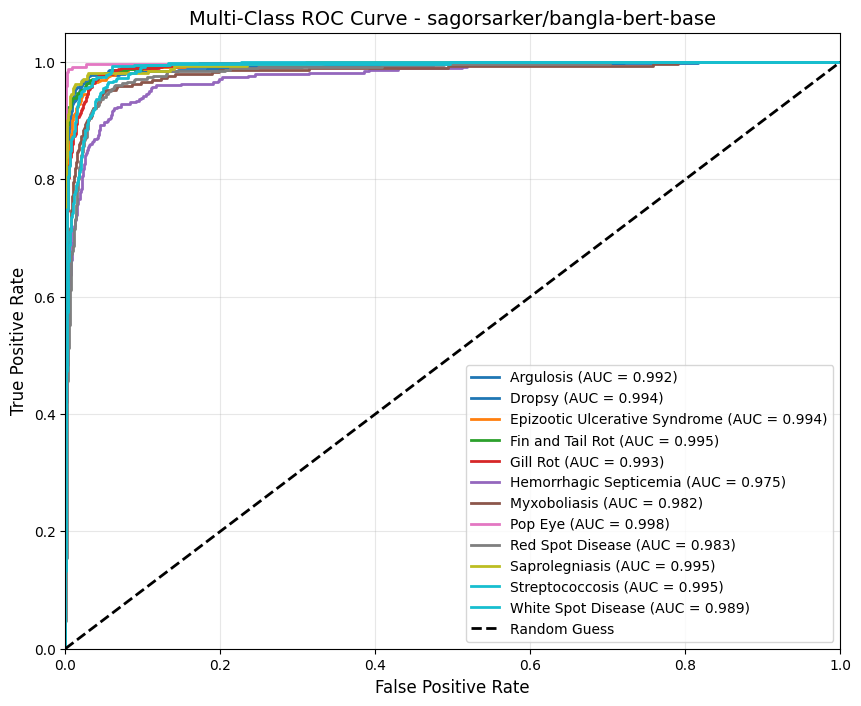

Chart saved to: /content/drive/MyDrive/bangla_bert_aquadx_cv/roc_curve_pooled.png


In [ ]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import softmax
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# 1. Configuration
DRIVE_SAVE_DIR = "/content/drive/MyDrive/bangla_bert_aquadx_cv"
N_SPLITS = 5
MODEL_NAME = "sagorsarker/bangla-bert-base"

# 2. Load label names
label_file = os.path.join(DRIVE_SAVE_DIR, "label_names.json")
with open(label_file, "r") as f:
    label_names = json.load(f)
n_classes = len(label_names)

all_logits = []
all_labels = []

# 3. Aggregate data from all folds
for fold in range(1, N_SPLITS + 1):
    fold_dir = os.path.join(DRIVE_SAVE_DIR, f"fold_{fold}")

    logits = np.load(os.path.join(fold_dir, "logits.npy"))
    labels = np.load(os.path.join(fold_dir, "labels.npy"))

    all_logits.append(logits)
    all_labels.append(labels)

# Concatenate arrays
logits_concat = np.concatenate(all_logits)
labels_concat = np.concatenate(all_labels)

# 4. Convert logits and binarize labels
probs = softmax(logits_concat, axis=1)
labels_bin = label_binarize(labels_concat, classes=range(n_classes))

# 5. Calculate ROC metrics
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(labels_bin[:, i], probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# 6. Plot the chart
plt.figure(figsize=(10, 8))
colors = plt.cm.get_cmap("tab10", n_classes)

for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], color=colors(i), lw=2,
             label=f"{label_names[i]} (AUC = {roc_auc[i]:.3f})")

# Plot baseline
plt.plot([0, 1], [0, 1], "k--", lw=2, label="Random Guess")

# Formatting
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
# UPDATED HEADING HERE
plt.title(f"Multi-Class ROC Curve - {MODEL_NAME}", fontsize=14)
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)

# 7. Save output
save_path = os.path.join(DRIVE_SAVE_DIR, "roc_curve_pooled.png")
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {save_path}")

# ai4bharat/indic-bert

In [ ]:
# ============================================================================
# 0. MOUNT GOOGLE DRIVE
# ============================================================================
from google.colab import drive
drive.mount('/content/drive')

# ============================================================================
# 1. INSTALL DEPENDENCIES
# ============================================================================
!pip install -U transformers datasets evaluate scikit-learn pandas \
                matplotlib seaborn statsmodels --quiet

# ============================================================================
# 2. IMPORTS & ENVIRONMENT SETUP
# ============================================================================
import gc, os, re, json, warnings
warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    classification_report,
    cohen_kappa_score, matthews_corrcoef
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback,
    DataCollatorWithPadding, set_seed
)
import evaluate

# ============================================================================
# 3. TEXT PREPROCESSING
# ============================================================================
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# ============================================================================
# 4. CONFIGURATION
# ============================================================================
MODEL_CHECKPOINT = "ai4bharat/indic-bert"
DATA_URL         = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"
DRIVE_SAVE_DIR   = "/content/drive/MyDrive/indic_bert_aquadx_cv"

MAX_LENGTH       = 128
RANDOM_SEED      = 42
N_SPLITS         = 5

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n[INFO] MODEL  : {MODEL_CHECKPOINT}")
print(f"[INFO] DEVICE : {device}")

# ============================================================================
# 5. DATASET PREPARATION
# ============================================================================
print("\n[INFO] Loading and preprocessing dataset...")
df = pd.read_csv(DATA_URL)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])
label_names = le.classes_
num_labels  = len(label_names)

# Convert entire dataframe to Hugging Face Dataset
full_dataset = Dataset.from_pandas(df)

# ============================================================================
# 6. EVALUATION METRICS BENCHMARK
# ============================================================================
acc_metric  = evaluate.load("accuracy")
prec_metric = evaluate.load("precision")
rec_metric  = evaluate.load("recall")
f1_metric   = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy"    : acc_metric.compute(predictions=preds, references=labels)["accuracy"],
        "precision"   : prec_metric.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall"      : rec_metric.compute(predictions=preds, references=labels, average="weighted")["recall"],
        "f1"          : f1_metric.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "cohen_kappa" : cohen_kappa_score(labels, preds),
        "mcc"         : matthews_corrcoef(labels, preds),
    }

# ============================================================================
# 7. TOKENIZATION
# ============================================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_dataset = full_dataset.map(tokenize_function, batched=True)
cols_to_drop = [c for c in ["text", "__index_level_0__"] if c in tokenized_dataset.column_names]
tokenized_dataset = tokenized_dataset.remove_columns(cols_to_drop)
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

# ============================================================================
# 8. MODEL INITIALIZATION FUNCTION
# ============================================================================
def model_init():
    """Forces the Trainer to instantiate a fresh, untrained model for every fold."""
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_CHECKPOINT, num_labels=num_labels
    )

# ============================================================================
# 9. K-FOLD CROSS VALIDATION LOOP
# ============================================================================
print("\n" + "=" * 60)
print(f"STARTING {N_SPLITS}-FOLD STRATIFIED CV")
print("=" * 60)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_metrics = []
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Extract labels for stratified splitting
all_labels = np.array(tokenized_dataset["label"])

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(all_labels)), all_labels)):
    print(f"\n--- FOLD {fold + 1}/{N_SPLITS} ---")

    # Create fold datasets using HF `select`
    train_fold = tokenized_dataset.select(train_idx)
    val_fold   = tokenized_dataset.select(val_idx)

    fold_dir = f"./indic_bert_cv_checkpoints/fold_{fold + 1}"

    training_args = TrainingArguments(
        output_dir                  = fold_dir,
        eval_strategy               = "epoch",
        save_strategy               = "epoch",
        logging_strategy            = "epoch",
        learning_rate               = 2e-5,
        per_device_train_batch_size = 16,
        per_device_eval_batch_size  = 16,
        num_train_epochs            = 6,
        weight_decay                = 0.01,
        warmup_steps                = 100,
        lr_scheduler_type           = "cosine",
        label_smoothing_factor      = 0.1,
        fp16                        = torch.cuda.is_available(),
        load_best_model_at_end      = True,
        metric_for_best_model       = "f1",
        greater_is_better           = True,
        save_total_limit            = 1,
        seed                        = RANDOM_SEED,
        report_to                   = "none",
    )

    trainer = Trainer(
        model_init      = model_init,
        args            = training_args,
        train_dataset   = train_fold,
        eval_dataset    = val_fold,
        processing_class= tokenizer,
        data_collator   = data_collator,
        compute_metrics = compute_metrics,
        callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)],
    )

    # Train and Evaluate
    trainer.train()
    metrics = trainer.evaluate()

    print(f"Fold {fold + 1} Eval F1: {metrics['eval_f1']:.4f}")
    fold_metrics.append(metrics)

    # Get raw predictions for statistical tests
    val_preds = trainer.predict(val_fold)
    logits = val_preds.predictions
    labels = val_preds.label_ids

    # Save best model of THIS fold to Drive
    fold_save_dir = os.path.join(DRIVE_SAVE_DIR, f"fold_{fold + 1}")
    trainer.save_model(fold_save_dir)
    tokenizer.save_pretrained(fold_save_dir)

    # Save arrays to Drive
    np.save(os.path.join(fold_save_dir, "logits.npy"), logits)
    np.save(os.path.join(fold_save_dir, "labels.npy"), labels)
    np.save(os.path.join(fold_save_dir, "val_indices.npy"), val_idx)

    # Save history
    history_file = os.path.join(fold_save_dir, "history.json")
    with open(history_file, "w") as f:
        json.dump(trainer.state.log_history, f)

    # Force GPU memory cleanup before next fold
    del trainer
    torch.cuda.empty_cache()
    gc.collect()

# ============================================================================
# 10. AGGREGATE CV RESULTS
# ============================================================================
print("\n" + "=" * 60)
print(f"FINAL {N_SPLITS}-FOLD CV RESULTS")
print("=" * 60)

# Calculate Mean and Standard Deviation across all folds
aggregated_metrics = {}
for key in fold_metrics[0].keys():
    if key.startswith("eval_"):
        values = [f[key] for f in fold_metrics]
        mean_val = np.mean(values)
        std_val  = np.std(values)
        aggregated_metrics[key] = {"mean": mean_val, "std": std_val}

        # Display as percentages for primary metrics, raw for Kappa/MCC
        if "kappa" in key or "mcc" in key:
            print(f"{key:>15}: {mean_val:.4f} ± {std_val:.4f}")
        elif "loss" not in key and "runtime" not in key and "steps" not in key:
            print(f"{key:>15}: {mean_val*100:.2f}% ± {std_val*100:.2f}%")

# Save final aggregated results and label names
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
with open(os.path.join(DRIVE_SAVE_DIR, "label_names.json"), "w", encoding="utf-8") as f:
    json.dump(list(label_names), f, ensure_ascii=False, indent=2)

with open(os.path.join(DRIVE_SAVE_DIR, "cv_aggregated_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(aggregated_metrics, f, ensure_ascii=False, indent=2, default=float)

print(f"\n[INFO] All fold models and aggregated metrics saved to: {DRIVE_SAVE_DIR}")

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 7.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 78.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 26.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 52.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 30.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 35.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 8.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.5 which is incompatib

config.json:   0%|          | 0.00/507 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/5.65M [00:00<?, ?B/s]

Map:   0%|          | 0/4814 [00:00<?, ? examples/s]


STARTING 5-FOLD STRATIFIED CV

--- FOLD 1/5 ---


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Cohen Kappa,Mcc
1.535658,1.725682,6,0.505198,0.505354,0.505198,0.483226,0.454548,0.460923


Fold 5 Eval F1: 0.4832


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


FINAL 5-FOLD CV RESULTS
  eval_accuracy: 56.77% ± 5.68%
 eval_precision: 57.29% ± 6.07%
    eval_recall: 56.77% ± 5.68%
        eval_f1: 53.53% ± 5.22%
eval_cohen_kappa: 0.5238 ± 0.0623
       eval_mcc: 0.5312 ± 0.0634

[INFO] All fold models and aggregated metrics saved to: /content/drive/MyDrive/indic_bert_aquadx_cv


# distilbert-base-multilingual-cased

In [ ]:
# ============================================================================
# 0. MOUNT GOOGLE DRIVE
# ============================================================================
from google.colab import drive
drive.mount('/content/drive')

# ============================================================================
# 1. INSTALL DEPENDENCIES
# ============================================================================
!pip install -U transformers datasets evaluate scikit-learn pandas \
                matplotlib seaborn statsmodels --quiet

# ============================================================================
# 2. IMPORTS & ENVIRONMENT SETUP
# ============================================================================
import gc, os, re, json, warnings
warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    classification_report,
    cohen_kappa_score, matthews_corrcoef
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback,
    DataCollatorWithPadding, set_seed
)
import evaluate

# ============================================================================
# 3. TEXT PREPROCESSING
# ============================================================================
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# ============================================================================
# 4. CONFIGURATION
# ============================================================================
MODEL_CHECKPOINT = "distilbert-base-multilingual-cased"
DATA_URL         = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"
DRIVE_SAVE_DIR   = "/content/drive/MyDrive/distilbert_multi_aquadx_cv"

MAX_LENGTH       = 128
RANDOM_SEED      = 42
N_SPLITS         = 5

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n[INFO] MODEL  : {MODEL_CHECKPOINT}")
print(f"[INFO] DEVICE : {device}")

# ============================================================================
# 5. DATASET PREPARATION
# ============================================================================
print("\n[INFO] Loading and preprocessing dataset...")
df = pd.read_csv(DATA_URL)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])
label_names = le.classes_
num_labels  = len(label_names)

# Convert entire dataframe to Hugging Face Dataset
full_dataset = Dataset.from_pandas(df)

# ============================================================================
# 6. EVALUATION METRICS BENCHMARK
# ============================================================================
acc_metric  = evaluate.load("accuracy")
prec_metric = evaluate.load("precision")
rec_metric  = evaluate.load("recall")
f1_metric   = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy"    : acc_metric.compute(predictions=preds, references=labels)["accuracy"],
        "precision"   : prec_metric.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall"      : rec_metric.compute(predictions=preds, references=labels, average="weighted")["recall"],
        "f1"          : f1_metric.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "cohen_kappa" : cohen_kappa_score(labels, preds),
        "mcc"         : matthews_corrcoef(labels, preds),
    }

# ============================================================================
# 7. TOKENIZATION
# ============================================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_dataset = full_dataset.map(tokenize_function, batched=True)
cols_to_drop = [c for c in ["text", "__index_level_0__"] if c in tokenized_dataset.column_names]
tokenized_dataset = tokenized_dataset.remove_columns(cols_to_drop)
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

# ============================================================================
# 8. MODEL INITIALIZATION FUNCTION
# ============================================================================
def model_init():
    """Forces the Trainer to instantiate a fresh, untrained model for every fold."""
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_CHECKPOINT, num_labels=num_labels
    )

# ============================================================================
# 9. K-FOLD CROSS VALIDATION LOOP
# ============================================================================
print("\n" + "=" * 60)
print(f"STARTING {N_SPLITS}-FOLD STRATIFIED CV")
print("=" * 60)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_metrics = []
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Extract labels for stratified splitting
all_labels = np.array(tokenized_dataset["label"])

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(all_labels)), all_labels)):
    print(f"\n--- FOLD {fold + 1}/{N_SPLITS} ---")

    # Create fold datasets using HF `select`
    train_fold = tokenized_dataset.select(train_idx)
    val_fold   = tokenized_dataset.select(val_idx)

    fold_dir = f"./distilbert_multi_cv_checkpoints/fold_{fold + 1}"

    training_args = TrainingArguments(
        output_dir                  = fold_dir,
        eval_strategy               = "epoch",
        save_strategy               = "epoch",
        logging_strategy            = "epoch",
        learning_rate               = 2e-5,
        per_device_train_batch_size = 16,
        per_device_eval_batch_size  = 16,
        num_train_epochs            = 6,
        weight_decay                = 0.01,
        warmup_steps                = 100,
        lr_scheduler_type           = "cosine",
        label_smoothing_factor      = 0.1,
        fp16                        = torch.cuda.is_available(),
        load_best_model_at_end      = True,
        metric_for_best_model       = "f1",
        greater_is_better           = True,
        save_total_limit            = 1,
        seed                        = RANDOM_SEED,
        report_to                   = "none",
    )

    trainer = Trainer(
        model_init      = model_init,
        args            = training_args,
        train_dataset   = train_fold,
        eval_dataset    = val_fold,
        processing_class= tokenizer,
        data_collator   = data_collator,
        compute_metrics = compute_metrics,
        callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)],
    )

    # Train and Evaluate
    trainer.train()
    metrics = trainer.evaluate()

    print(f"Fold {fold + 1} Eval F1: {metrics['eval_f1']:.4f}")
    fold_metrics.append(metrics)

    # Get raw predictions for statistical tests
    val_preds = trainer.predict(val_fold)
    logits = val_preds.predictions
    labels = val_preds.label_ids

    # Save best model of THIS fold to Drive
    fold_save_dir = os.path.join(DRIVE_SAVE_DIR, f"fold_{fold + 1}")
    trainer.save_model(fold_save_dir)
    tokenizer.save_pretrained(fold_save_dir)

    # Save arrays to Drive
    np.save(os.path.join(fold_save_dir, "logits.npy"), logits)
    np.save(os.path.join(fold_save_dir, "labels.npy"), labels)
    np.save(os.path.join(fold_save_dir, "val_indices.npy"), val_idx)

    # Save history
    history_file = os.path.join(fold_save_dir, "history.json")
    with open(history_file, "w") as f:
        json.dump(trainer.state.log_history, f)

    # Force GPU memory cleanup before next fold
    del trainer
    torch.cuda.empty_cache()
    gc.collect()

# ============================================================================
# 10. AGGREGATE CV RESULTS
# ============================================================================
print("\n" + "=" * 60)
print(f"FINAL {N_SPLITS}-FOLD CV RESULTS")
print("=" * 60)

# Calculate Mean and Standard Deviation across all folds
aggregated_metrics = {}
for key in fold_metrics[0].keys():
    if key.startswith("eval_"):
        values = [f[key] for f in fold_metrics]
        mean_val = np.mean(values)
        std_val  = np.std(values)
        aggregated_metrics[key] = {"mean": mean_val, "std": std_val}

        # Display as percentages for primary metrics, raw for Kappa/MCC
        if "kappa" in key or "mcc" in key:
            print(f"{key:>15}: {mean_val:.4f} ± {std_val:.4f}")
        elif "loss" not in key and "runtime" not in key and "steps" not in key:
            print(f"{key:>15}: {mean_val*100:.2f}% ± {std_val*100:.2f}%")

# Save final aggregated results and label names
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
with open(os.path.join(DRIVE_SAVE_DIR, "label_names.json"), "w", encoding="utf-8") as f:
    json.dump(list(label_names), f, ensure_ascii=False, indent=2)

with open(os.path.join(DRIVE_SAVE_DIR, "cv_aggregated_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(aggregated_metrics, f, ensure_ascii=False, indent=2, default=float)

print(f"\n[INFO] All fold models and aggregated metrics saved to: {DRIVE_SAVE_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[INFO] MODEL  : distilbert-base-multilingual-cased
[INFO] DEVICE : cuda

[INFO] Loading and preprocessing dataset...


config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Cohen Kappa,Mcc
0.714976,0.861069,6,0.862786,0.864385,0.862786,0.862539,0.849595,0.849801


Fold 5 Eval F1: 0.8625


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


FINAL 5-FOLD CV RESULTS
  eval_accuracy: 85.11% ± 1.09%
 eval_precision: 85.23% ± 0.99%
    eval_recall: 85.11% ± 1.09%
        eval_f1: 85.07% ± 1.05%
eval_cohen_kappa: 0.8368 ± 0.0119
       eval_mcc: 0.8369 ± 0.0119

[INFO] All fold models and aggregated metrics saved to: /content/drive/MyDrive/distilbert_multi_aquadx_cv


# banglagov/banBERT-Base

In [ ]:
# ============================================================================
# 0. MOUNT GOOGLE DRIVE
# ============================================================================
from google.colab import drive
drive.mount('/content/drive')

# ============================================================================
# 1. INSTALL DEPENDENCIES
# ============================================================================
!pip install -U transformers datasets evaluate scikit-learn pandas \
                matplotlib seaborn statsmodels --quiet

# ============================================================================
# 2. IMPORTS & ENVIRONMENT SETUP
# ============================================================================
import gc, os, re, json, warnings
warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    classification_report,
    cohen_kappa_score, matthews_corrcoef
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback,
    DataCollatorWithPadding, set_seed
)
import evaluate

# ============================================================================
# 3. TEXT PREPROCESSING
# ============================================================================
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# ============================================================================
# 4. CONFIGURATION
# ============================================================================
MODEL_CHECKPOINT = "banglagov/banBERT-Base"
DATA_URL         = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"
DRIVE_SAVE_DIR   = "/content/drive/MyDrive/banbert_base_aquadx_cv"

MAX_LENGTH       = 128
RANDOM_SEED      = 42
N_SPLITS         = 5

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n[INFO] MODEL  : {MODEL_CHECKPOINT}")
print(f"[INFO] DEVICE : {device}")

# ============================================================================
# 5. DATASET PREPARATION
# ============================================================================
print("\n[INFO] Loading and preprocessing dataset...")
df = pd.read_csv(DATA_URL)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])
label_names = le.classes_
num_labels  = len(label_names)

# Convert entire dataframe to Hugging Face Dataset
full_dataset = Dataset.from_pandas(df)

# ============================================================================
# 6. EVALUATION METRICS BENCHMARK
# ============================================================================
acc_metric  = evaluate.load("accuracy")
prec_metric = evaluate.load("precision")
rec_metric  = evaluate.load("recall")
f1_metric   = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy"    : acc_metric.compute(predictions=preds, references=labels)["accuracy"],
        "precision"   : prec_metric.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall"      : rec_metric.compute(predictions=preds, references=labels, average="weighted")["recall"],
        "f1"          : f1_metric.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "cohen_kappa" : cohen_kappa_score(labels, preds),
        "mcc"         : matthews_corrcoef(labels, preds),
    }

# ============================================================================
# 7. TOKENIZATION
# ============================================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_dataset = full_dataset.map(tokenize_function, batched=True)
cols_to_drop = [c for c in ["text", "__index_level_0__"] if c in tokenized_dataset.column_names]
tokenized_dataset = tokenized_dataset.remove_columns(cols_to_drop)
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

# ============================================================================
# 8. MODEL INITIALIZATION FUNCTION
# ============================================================================
def model_init():
    """Forces the Trainer to instantiate a fresh, untrained model for every fold."""
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_CHECKPOINT, num_labels=num_labels
    )

# ============================================================================
# 9. K-FOLD CROSS VALIDATION LOOP
# ============================================================================
print("\n" + "=" * 60)
print(f"STARTING {N_SPLITS}-FOLD STRATIFIED CV")
print("=" * 60)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_metrics = []
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Extract labels for stratified splitting
all_labels = np.array(tokenized_dataset["label"])

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(all_labels)), all_labels)):
    print(f"\n--- FOLD {fold + 1}/{N_SPLITS} ---")

    # Create fold datasets using HF `select`
    train_fold = tokenized_dataset.select(train_idx)
    val_fold   = tokenized_dataset.select(val_idx)

    fold_dir = f"./banbert_base_cv_checkpoints/fold_{fold + 1}"

    training_args = TrainingArguments(
        output_dir                  = fold_dir,
        eval_strategy               = "epoch",
        save_strategy               = "epoch",
        logging_strategy            = "epoch",
        learning_rate               = 2e-5,
        per_device_train_batch_size = 16,
        per_device_eval_batch_size  = 16,
        num_train_epochs            = 6,
        weight_decay                = 0.01,
        warmup_steps                = 100,
        lr_scheduler_type           = "cosine",
        label_smoothing_factor      = 0.1,
        fp16                        = torch.cuda.is_available(),
        load_best_model_at_end      = True,
        metric_for_best_model       = "f1",
        greater_is_better           = True,
        save_total_limit            = 1,
        seed                        = RANDOM_SEED,
        report_to                   = "none",
    )

    trainer = Trainer(
        model_init      = model_init,
        args            = training_args,
        train_dataset   = train_fold,
        eval_dataset    = val_fold,
        processing_class= tokenizer,
        data_collator   = data_collator,
        compute_metrics = compute_metrics,
        callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)],
    )

    # Train and Evaluate
    trainer.train()
    metrics = trainer.evaluate()

    print(f"Fold {fold + 1} Eval F1: {metrics['eval_f1']:.4f}")
    fold_metrics.append(metrics)

    # Get raw predictions for statistical tests
    val_preds = trainer.predict(val_fold)
    logits = val_preds.predictions
    labels = val_preds.label_ids

    # Save best model of THIS fold to Drive
    fold_save_dir = os.path.join(DRIVE_SAVE_DIR, f"fold_{fold + 1}")
    trainer.save_model(fold_save_dir)
    tokenizer.save_pretrained(fold_save_dir)

    # Save arrays to Drive
    np.save(os.path.join(fold_save_dir, "logits.npy"), logits)
    np.save(os.path.join(fold_save_dir, "labels.npy"), labels)
    np.save(os.path.join(fold_save_dir, "val_indices.npy"), val_idx)

    # Save history
    history_file = os.path.join(fold_save_dir, "history.json")
    with open(history_file, "w") as f:
        json.dump(trainer.state.log_history, f)

    # Force GPU memory cleanup before next fold
    del trainer
    torch.cuda.empty_cache()
    gc.collect()

# ============================================================================
# 10. AGGREGATE CV RESULTS
# ============================================================================
print("\n" + "=" * 60)
print(f"FINAL {N_SPLITS}-FOLD CV RESULTS")
print("=" * 60)

# Calculate Mean and Standard Deviation across all folds
aggregated_metrics = {}
for key in fold_metrics[0].keys():
    if key.startswith("eval_"):
        values = [f[key] for f in fold_metrics]
        mean_val = np.mean(values)
        std_val  = np.std(values)
        aggregated_metrics[key] = {"mean": mean_val, "std": std_val}

        # Display as percentages for primary metrics, raw for Kappa/MCC
        if "kappa" in key or "mcc" in key:
            print(f"{key:>15}: {mean_val:.4f} ± {std_val:.4f}")
        elif "loss" not in key and "runtime" not in key and "steps" not in key:
            print(f"{key:>15}: {mean_val*100:.2f}% ± {std_val*100:.2f}%")

# Save final aggregated results and label names
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
with open(os.path.join(DRIVE_SAVE_DIR, "label_names.json"), "w", encoding="utf-8") as f:
    json.dump(list(label_names), f, ensure_ascii=False, indent=2)

with open(os.path.join(DRIVE_SAVE_DIR, "cv_aggregated_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(aggregated_metrics, f, ensure_ascii=False, indent=2, default=float)

print(f"\n[INFO] All fold models and aggregated metrics saved to: {DRIVE_SAVE_DIR}")

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 43.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 40.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 51.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 58.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 11.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.5 which is incompatib

config.json:   0%|          | 0.00/723 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/419 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/958k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.75M [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Cohen Kappa,Mcc
0.582487,0.871669,6,0.853430,0.860236,0.853430,0.854705,0.839480,0.839924


Fold 5 Eval F1: 0.8547


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


FINAL 5-FOLD CV RESULTS
  eval_accuracy: 86.64% ± 1.25%
 eval_precision: 86.91% ± 1.14%
    eval_recall: 86.64% ± 1.25%
        eval_f1: 86.66% ± 1.23%
eval_cohen_kappa: 0.8537 ± 0.0137
       eval_mcc: 0.8539 ± 0.0136

[INFO] All fold models and aggregated metrics saved to: /content/drive/MyDrive/banbert_base_aquadx_cv


# bert-base-multilingual-cased

In [ ]:
# ============================================================================
# 0. MOUNT GOOGLE DRIVE
# ============================================================================
from google.colab import drive
drive.mount('/content/drive')

# ============================================================================
# 1. INSTALL DEPENDENCIES
# ============================================================================
!pip install -U transformers datasets evaluate scikit-learn pandas \
                matplotlib seaborn statsmodels --quiet

# ============================================================================
# 2. IMPORTS & ENVIRONMENT SETUP
# ============================================================================
import gc, os, re, json, warnings
warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    classification_report,
    cohen_kappa_score, matthews_corrcoef
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback,
    DataCollatorWithPadding, set_seed
)
import evaluate

# ============================================================================
# 3. TEXT PREPROCESSING
# ============================================================================
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# ============================================================================
# 4. CONFIGURATION
# ============================================================================
MODEL_CHECKPOINT = "bert-base-multilingual-cased"
DATA_URL         = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"
DRIVE_SAVE_DIR   = "/content/drive/MyDrive/mbert_aquadx_cv"

MAX_LENGTH       = 128
RANDOM_SEED      = 42
N_SPLITS         = 5

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n[INFO] MODEL  : {MODEL_CHECKPOINT}")
print(f"[INFO] DEVICE : {device}")

# ============================================================================
# 5. DATASET PREPARATION
# ============================================================================
print("\n[INFO] Loading and preprocessing dataset...")
df = pd.read_csv(DATA_URL)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])
label_names = le.classes_
num_labels  = len(label_names)

# Convert entire dataframe to Hugging Face Dataset
full_dataset = Dataset.from_pandas(df)

# ============================================================================
# 6. EVALUATION METRICS BENCHMARK
# ============================================================================
acc_metric  = evaluate.load("accuracy")
prec_metric = evaluate.load("precision")
rec_metric  = evaluate.load("recall")
f1_metric   = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy"    : acc_metric.compute(predictions=preds, references=labels)["accuracy"],
        "precision"   : prec_metric.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall"      : rec_metric.compute(predictions=preds, references=labels, average="weighted")["recall"],
        "f1"          : f1_metric.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "cohen_kappa" : cohen_kappa_score(labels, preds),
        "mcc"         : matthews_corrcoef(labels, preds),
    }

# ============================================================================
# 7. TOKENIZATION
# ============================================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_dataset = full_dataset.map(tokenize_function, batched=True)
cols_to_drop = [c for c in ["text", "__index_level_0__"] if c in tokenized_dataset.column_names]
tokenized_dataset = tokenized_dataset.remove_columns(cols_to_drop)
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

# ============================================================================
# 8. MODEL INITIALIZATION FUNCTION
# ============================================================================
def model_init():
    """Forces the Trainer to instantiate a fresh, untrained model for every fold."""
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_CHECKPOINT, num_labels=num_labels
    )

# ============================================================================
# 9. K-FOLD CROSS VALIDATION LOOP
# ============================================================================
print("\n" + "=" * 60)
print(f"STARTING {N_SPLITS}-FOLD STRATIFIED CV")
print("=" * 60)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_metrics = []
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Extract labels for stratified splitting
all_labels = np.array(tokenized_dataset["label"])

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(all_labels)), all_labels)):
    print(f"\n--- FOLD {fold + 1}/{N_SPLITS} ---")

    # Create fold datasets using HF `select`
    train_fold = tokenized_dataset.select(train_idx)
    val_fold   = tokenized_dataset.select(val_idx)

    fold_dir = f"./mbert_cv_checkpoints/fold_{fold + 1}"

    training_args = TrainingArguments(
        output_dir                  = fold_dir,
        eval_strategy               = "epoch",
        save_strategy               = "epoch",
        logging_strategy            = "epoch",
        learning_rate               = 2e-5,
        per_device_train_batch_size = 16,
        per_device_eval_batch_size  = 16,
        num_train_epochs            = 6,
        weight_decay                = 0.01,
        warmup_steps                = 100,
        lr_scheduler_type           = "cosine",
        label_smoothing_factor      = 0.1,
        fp16                        = torch.cuda.is_available(),
        load_best_model_at_end      = True,
        metric_for_best_model       = "f1",
        greater_is_better           = True,
        save_total_limit            = 1,
        seed                        = RANDOM_SEED,
        report_to                   = "none",
    )

    trainer = Trainer(
        model_init      = model_init,
        args            = training_args,
        train_dataset   = train_fold,
        eval_dataset    = val_fold,
        processing_class= tokenizer,
        data_collator   = data_collator,
        compute_metrics = compute_metrics,
        callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)],
    )

    # Train and Evaluate
    trainer.train()
    metrics = trainer.evaluate()

    print(f"Fold {fold + 1} Eval F1: {metrics['eval_f1']:.4f}")
    fold_metrics.append(metrics)

    # Get raw predictions for statistical tests
    val_preds = trainer.predict(val_fold)
    logits = val_preds.predictions
    labels = val_preds.label_ids

    # Save best model of THIS fold to Drive
    fold_save_dir = os.path.join(DRIVE_SAVE_DIR, f"fold_{fold + 1}")
    trainer.save_model(fold_save_dir)
    tokenizer.save_pretrained(fold_save_dir)

    # Save arrays to Drive
    np.save(os.path.join(fold_save_dir, "logits.npy"), logits)
    np.save(os.path.join(fold_save_dir, "labels.npy"), labels)
    np.save(os.path.join(fold_save_dir, "val_indices.npy"), val_idx)

    # Save history
    history_file = os.path.join(fold_save_dir, "history.json")
    with open(history_file, "w") as f:
        json.dump(trainer.state.log_history, f)

    # Force GPU memory cleanup before next fold
    del trainer
    torch.cuda.empty_cache()
    gc.collect()

# ============================================================================
# 10. AGGREGATE CV RESULTS
# ============================================================================
print("\n" + "=" * 60)
print(f"FINAL {N_SPLITS}-FOLD CV RESULTS")
print("=" * 60)

# Calculate Mean and Standard Deviation across all folds
aggregated_metrics = {}
for key in fold_metrics[0].keys():
    if key.startswith("eval_"):
        values = [f[key] for f in fold_metrics]
        mean_val = np.mean(values)
        std_val  = np.std(values)
        aggregated_metrics[key] = {"mean": mean_val, "std": std_val}

        # Display as percentages for primary metrics, raw for Kappa/MCC
        if "kappa" in key or "mcc" in key:
            print(f"{key:>15}: {mean_val:.4f} ± {std_val:.4f}")
        elif "loss" not in key and "runtime" not in key and "steps" not in key:
            print(f"{key:>15}: {mean_val*100:.2f}% ± {std_val*100:.2f}%")

# Save final aggregated results and label names
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
with open(os.path.join(DRIVE_SAVE_DIR, "label_names.json"), "w", encoding="utf-8") as f:
    json.dump(list(label_names), f, ensure_ascii=False, indent=2)

with open(os.path.join(DRIVE_SAVE_DIR, "cv_aggregated_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(aggregated_metrics, f, ensure_ascii=False, indent=2, default=float)

print(f"\n[INFO] All fold models and aggregated metrics saved to: {DRIVE_SAVE_DIR}")

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 6.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 103.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 40.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 119.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 108.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 120.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 12.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.5 which is incom

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

...

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Cohen Kappa,Mcc
0.639962,0.868816,6,0.858628,0.862149,0.858628,0.859031,0.845076,0.845360


Fold 5 Eval F1: 0.8590


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


FINAL 5-FOLD CV RESULTS
  eval_accuracy: 86.29% ± 0.79%
 eval_precision: 86.61% ± 0.71%
    eval_recall: 86.29% ± 0.79%
        eval_f1: 86.28% ± 0.82%
eval_cohen_kappa: 0.8498 ± 0.0086
       eval_mcc: 0.8501 ± 0.0085

[INFO] All fold models and aggregated metrics saved to: /content/drive/MyDrive/mbert_aquadx_cv


# ai4bharat/IndicBERTv2-MLM-only

In [ ]:
# ============================================================================
# 0. MOUNT GOOGLE DRIVE
# ============================================================================
from google.colab import drive
drive.mount('/content/drive')

# ============================================================================
# 1. INSTALL DEPENDENCIES
# ============================================================================
!pip install -U transformers datasets evaluate scikit-learn pandas \
                matplotlib seaborn statsmodels --quiet

# ============================================================================
# 2. IMPORTS & ENVIRONMENT SETUP
# ============================================================================
import gc, os, re, json, warnings
warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    classification_report,
    cohen_kappa_score, matthews_corrcoef
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback,
    DataCollatorWithPadding, set_seed
)
import evaluate

# ============================================================================
# 3. TEXT PREPROCESSING
# ============================================================================
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# ============================================================================
# 4. CONFIGURATION
# ============================================================================
MODEL_CHECKPOINT = "ai4bharat/IndicBERTv2-MLM-only"
DATA_URL         = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"
DRIVE_SAVE_DIR   = "/content/drive/MyDrive/indicbertv2_aquadx_cv"

MAX_LENGTH       = 128
RANDOM_SEED      = 42
N_SPLITS         = 5

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n[INFO] MODEL  : {MODEL_CHECKPOINT}")
print(f"[INFO] DEVICE : {device}")

# ============================================================================
# 5. DATASET PREPARATION
# ============================================================================
print("\n[INFO] Loading and preprocessing dataset...")
df = pd.read_csv(DATA_URL)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])
label_names = le.classes_
num_labels  = len(label_names)

# Convert entire dataframe to Hugging Face Dataset
full_dataset = Dataset.from_pandas(df)

# ============================================================================
# 6. EVALUATION METRICS BENCHMARK
# ============================================================================
acc_metric  = evaluate.load("accuracy")
prec_metric = evaluate.load("precision")
rec_metric  = evaluate.load("recall")
f1_metric   = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy"    : acc_metric.compute(predictions=preds, references=labels)["accuracy"],
        "precision"   : prec_metric.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall"      : rec_metric.compute(predictions=preds, references=labels, average="weighted")["recall"],
        "f1"          : f1_metric.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "cohen_kappa" : cohen_kappa_score(labels, preds),
        "mcc"         : matthews_corrcoef(labels, preds),
    }

# ============================================================================
# 7. TOKENIZATION
# ============================================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_dataset = full_dataset.map(tokenize_function, batched=True)
cols_to_drop = [c for c in ["text", "__index_level_0__"] if c in tokenized_dataset.column_names]
tokenized_dataset = tokenized_dataset.remove_columns(cols_to_drop)
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

# ============================================================================
# 8. MODEL INITIALIZATION FUNCTION
# ============================================================================
def model_init():
    """Forces the Trainer to instantiate a fresh, untrained model for every fold."""
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_CHECKPOINT, num_labels=num_labels
    )

# ============================================================================
# 9. K-FOLD CROSS VALIDATION LOOP
# ============================================================================
print("\n" + "=" * 60)
print(f"STARTING {N_SPLITS}-FOLD STRATIFIED CV")
print("=" * 60)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_metrics = []
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Extract labels for stratified splitting
all_labels = np.array(tokenized_dataset["label"])

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(all_labels)), all_labels)):
    print(f"\n--- FOLD {fold + 1}/{N_SPLITS} ---")

    # Create fold datasets using HF `select`
    train_fold = tokenized_dataset.select(train_idx)
    val_fold   = tokenized_dataset.select(val_idx)

    fold_dir = f"./indicbertv2_cv_checkpoints/fold_{fold + 1}"

    training_args = TrainingArguments(
        output_dir                  = fold_dir,
        eval_strategy               = "epoch",
        save_strategy               = "epoch",
        logging_strategy            = "epoch",
        learning_rate               = 2e-5,
        per_device_train_batch_size = 16,
        per_device_eval_batch_size  = 16,
        num_train_epochs            = 6,
        weight_decay                = 0.01,
        warmup_steps                = 100,
        lr_scheduler_type           = "cosine",
        label_smoothing_factor      = 0.1,
        fp16                        = torch.cuda.is_available(),
        load_best_model_at_end      = True,
        metric_for_best_model       = "f1",
        greater_is_better           = True,
        save_total_limit            = 1,
        seed                        = RANDOM_SEED,
        report_to                   = "none",
    )

    trainer = Trainer(
        model_init      = model_init,
        args            = training_args,
        train_dataset   = train_fold,
        eval_dataset    = val_fold,
        processing_class= tokenizer,
        data_collator   = data_collator,
        compute_metrics = compute_metrics,
        callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)],
    )

    # Train and Evaluate
    trainer.train()
    metrics = trainer.evaluate()

    print(f"Fold {fold + 1} Eval F1: {metrics['eval_f1']:.4f}")
    fold_metrics.append(metrics)

    # Get raw predictions for statistical tests
    val_preds = trainer.predict(val_fold)
    logits = val_preds.predictions
    labels = val_preds.label_ids

    # Save best model of THIS fold to Drive
    fold_save_dir = os.path.join(DRIVE_SAVE_DIR, f"fold_{fold + 1}")
    trainer.save_model(fold_save_dir)
    tokenizer.save_pretrained(fold_save_dir)

    # Save arrays to Drive
    np.save(os.path.join(fold_save_dir, "logits.npy"), logits)
    np.save(os.path.join(fold_save_dir, "labels.npy"), labels)
    np.save(os.path.join(fold_save_dir, "val_indices.npy"), val_idx)

    # Save history
    history_file = os.path.join(fold_save_dir, "history.json")
    with open(history_file, "w") as f:
        json.dump(trainer.state.log_history, f)

    # Force GPU memory cleanup before next fold
    del trainer
    torch.cuda.empty_cache()
    gc.collect()

# ============================================================================
# 10. AGGREGATE CV RESULTS
# ============================================================================
print("\n" + "=" * 60)
print(f"FINAL {N_SPLITS}-FOLD CV RESULTS")
print("=" * 60)

# Calculate Mean and Standard Deviation across all folds
aggregated_metrics = {}
for key in fold_metrics[0].keys():
    if key.startswith("eval_"):
        values = [f[key] for f in fold_metrics]
        mean_val = np.mean(values)
        std_val  = np.std(values)
        aggregated_metrics[key] = {"mean": mean_val, "std": std_val}

        # Display as percentages for primary metrics, raw for Kappa/MCC
        if "kappa" in key or "mcc" in key:
            print(f"{key:>15}: {mean_val:.4f} ± {std_val:.4f}")
        elif "loss" not in key and "runtime" not in key and "steps" not in key:
            print(f"{key:>15}: {mean_val*100:.2f}% ± {std_val*100:.2f}%")

# Save final aggregated results and label names
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
with open(os.path.join(DRIVE_SAVE_DIR, "label_names.json"), "w", encoding="utf-8") as f:
    json.dump(list(label_names), f, ensure_ascii=False, indent=2)

with open(os.path.join(DRIVE_SAVE_DIR, "cv_aggregated_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(aggregated_metrics, f, ensure_ascii=False, indent=2, default=float)

print(f"\n[INFO] All fold models and aggregated metrics saved to: {DRIVE_SAVE_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[INFO] MODEL  : ai4bharat/IndicBERTv2-MLM-only
[INFO] DEVICE : cuda

[INFO] Loading and preprocessing dataset...


config.json:   0%|          | 0.00/639 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/51.0 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 7.75MB            

tokenizer.json: downloading bytes:           |  0.00B            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Cohen Kappa,Mcc
0.617265,0.803471,6,0.882536,0.885716,0.882536,0.882983,0.871257,0.871489


Fold 5 Eval F1: 0.8830


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


FINAL 5-FOLD CV RESULTS
  eval_accuracy: 89.09% ± 0.94%
 eval_precision: 89.27% ± 0.87%
    eval_recall: 89.09% ± 0.94%
        eval_f1: 89.08% ± 0.90%
eval_cohen_kappa: 0.8805 ± 0.0103
       eval_mcc: 0.8807 ± 0.0103

[INFO] All fold models and aggregated metrics saved to: /content/drive/MyDrive/indicbertv2_aquadx_cv


# google/muril-base-cased

In [ ]:
# ============================================================================
# 0. MOUNT GOOGLE DRIVE
# ============================================================================
from google.colab import drive
drive.mount('/content/drive')

# ============================================================================
# 1. INSTALL DEPENDENCIES
# ============================================================================
!pip install -U transformers datasets evaluate scikit-learn pandas \
                matplotlib seaborn statsmodels --quiet

# ============================================================================
# 2. IMPORTS & ENVIRONMENT SETUP
# ============================================================================
import gc, os, re, json, warnings
warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    classification_report,
    cohen_kappa_score, matthews_corrcoef
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback,
    DataCollatorWithPadding, set_seed
)
import evaluate

# ============================================================================
# 3. TEXT PREPROCESSING
# ============================================================================
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# ============================================================================
# 4. CONFIGURATION
# ============================================================================
MODEL_CHECKPOINT = "google/muril-base-cased"
DATA_URL         = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"
DRIVE_SAVE_DIR   = "/content/drive/MyDrive/muril_aquadx_cv"

MAX_LENGTH       = 128
RANDOM_SEED      = 42
N_SPLITS         = 5

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n[INFO] MODEL  : {MODEL_CHECKPOINT}")
print(f"[INFO] DEVICE : {device}")

# ============================================================================
# 5. DATASET PREPARATION
# ============================================================================
print("\n[INFO] Loading and preprocessing dataset...")
df = pd.read_csv(DATA_URL)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])
label_names = le.classes_
num_labels  = len(label_names)

# Convert entire dataframe to Hugging Face Dataset
full_dataset = Dataset.from_pandas(df)

# ============================================================================
# 6. EVALUATION METRICS BENCHMARK
# ============================================================================
acc_metric  = evaluate.load("accuracy")
prec_metric = evaluate.load("precision")
rec_metric  = evaluate.load("recall")
f1_metric   = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy"    : acc_metric.compute(predictions=preds, references=labels)["accuracy"],
        "precision"   : prec_metric.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall"      : rec_metric.compute(predictions=preds, references=labels, average="weighted")["recall"],
        "f1"          : f1_metric.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "cohen_kappa" : cohen_kappa_score(labels, preds),
        "mcc"         : matthews_corrcoef(labels, preds),
    }

# ============================================================================
# 7. TOKENIZATION
# ============================================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_dataset = full_dataset.map(tokenize_function, batched=True)
cols_to_drop = [c for c in ["text", "__index_level_0__"] if c in tokenized_dataset.column_names]
tokenized_dataset = tokenized_dataset.remove_columns(cols_to_drop)
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

# ============================================================================
# 8. MODEL INITIALIZATION FUNCTION
# ============================================================================
def model_init():
    """Forces the Trainer to instantiate a fresh, untrained model for every fold."""
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_CHECKPOINT, num_labels=num_labels
    )

# ============================================================================
# 9. K-FOLD CROSS VALIDATION LOOP
# ============================================================================
print("\n" + "=" * 60)
print(f"STARTING {N_SPLITS}-FOLD STRATIFIED CV")
print("=" * 60)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_metrics = []
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Extract labels for stratified splitting
all_labels = np.array(tokenized_dataset["label"])

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(all_labels)), all_labels)):
    print(f"\n--- FOLD {fold + 1}/{N_SPLITS} ---")

    # Create fold datasets using HF `select`
    train_fold = tokenized_dataset.select(train_idx)
    val_fold   = tokenized_dataset.select(val_idx)

    fold_dir = f"./muril_cv_checkpoints/fold_{fold + 1}"

    training_args = TrainingArguments(
        output_dir                  = fold_dir,
        eval_strategy               = "epoch",
        save_strategy               = "epoch",
        logging_strategy            = "epoch",
        learning_rate               = 2e-5,
        per_device_train_batch_size = 16,
        per_device_eval_batch_size  = 16,
        num_train_epochs            = 6,
        weight_decay                = 0.01,
        warmup_steps                = 100,
        lr_scheduler_type           = "cosine",
        label_smoothing_factor      = 0.1,
        fp16                        = torch.cuda.is_available(),
        load_best_model_at_end      = True,
        metric_for_best_model       = "f1",
        greater_is_better           = True,
        save_total_limit            = 1,
        seed                        = RANDOM_SEED,
        report_to                   = "none",
    )

    trainer = Trainer(
        model_init      = model_init,
        args            = training_args,
        train_dataset   = train_fold,
        eval_dataset    = val_fold,
        processing_class= tokenizer,
        data_collator   = data_collator,
        compute_metrics = compute_metrics,
        callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)],
    )

    # Train and Evaluate
    trainer.train()
    metrics = trainer.evaluate()

    print(f"Fold {fold + 1} Eval F1: {metrics['eval_f1']:.4f}")
    fold_metrics.append(metrics)

    # Get raw predictions for statistical tests
    val_preds = trainer.predict(val_fold)
    logits = val_preds.predictions
    labels = val_preds.label_ids

    # Save best model of THIS fold to Drive
    fold_save_dir = os.path.join(DRIVE_SAVE_DIR, f"fold_{fold + 1}")
    trainer.save_model(fold_save_dir)
    tokenizer.save_pretrained(fold_save_dir)

    # Save arrays to Drive
    np.save(os.path.join(fold_save_dir, "logits.npy"), logits)
    np.save(os.path.join(fold_save_dir, "labels.npy"), labels)
    np.save(os.path.join(fold_save_dir, "val_indices.npy"), val_idx)

    # Save history
    history_file = os.path.join(fold_save_dir, "history.json")
    with open(history_file, "w") as f:
        json.dump(trainer.state.log_history, f)

    # Force GPU memory cleanup before next fold
    del trainer
    torch.cuda.empty_cache()
    gc.collect()

# ============================================================================
# 10. AGGREGATE CV RESULTS
# ============================================================================
print("\n" + "=" * 60)
print(f"FINAL {N_SPLITS}-FOLD CV RESULTS")
print("=" * 60)

# Calculate Mean and Standard Deviation across all folds
aggregated_metrics = {}
for key in fold_metrics[0].keys():
    if key.startswith("eval_"):
        values = [f[key] for f in fold_metrics]
        mean_val = np.mean(values)
        std_val  = np.std(values)
        aggregated_metrics[key] = {"mean": mean_val, "std": std_val}

        # Display as percentages for primary metrics, raw for Kappa/MCC
        if "kappa" in key or "mcc" in key:
            print(f"{key:>15}: {mean_val:.4f} ± {std_val:.4f}")
        elif "loss" not in key and "runtime" not in key and "steps" not in key:
            print(f"{key:>15}: {mean_val*100:.2f}% ± {std_val*100:.2f}%")

# Save final aggregated results and label names
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
with open(os.path.join(DRIVE_SAVE_DIR, "label_names.json"), "w", encoding="utf-8") as f:
    json.dump(list(label_names), f, ensure_ascii=False, indent=2)

with open(os.path.join(DRIVE_SAVE_DIR, "cv_aggregated_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(aggregated_metrics, f, ensure_ascii=False, indent=2, default=float)

print(f"\n[INFO] All fold models and aggregated metrics saved to: {DRIVE_SAVE_DIR}")

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 59.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 56.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 57.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 75.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 12.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.5 which is incompati

config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Cohen Kappa,Mcc
1.401377,1.422207,6,0.797297,0.804390,0.797297,0.768609,0.777379,0.782725


Fold 5 Eval F1: 0.7686


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


FINAL 5-FOLD CV RESULTS
  eval_accuracy: 80.08% ± 1.98%
 eval_precision: 79.36% ± 2.75%
    eval_recall: 80.08% ± 1.98%
        eval_f1: 76.95% ± 2.40%
eval_cohen_kappa: 0.7812 ± 0.0218
       eval_mcc: 0.7869 ± 0.0209

[INFO] All fold models and aggregated metrics saved to: /content/drive/MyDrive/muril_aquadx_cv


# xlm-roberta-base

In [ ]:
# ============================================================================
# 0. MOUNT GOOGLE DRIVE
# ============================================================================
from google.colab import drive
drive.mount('/content/drive')

# ============================================================================
# 1. INSTALL DEPENDENCIES
# ============================================================================
!pip install -U transformers datasets evaluate scikit-learn pandas \
                matplotlib seaborn statsmodels sentencepiece --quiet

# ============================================================================
# 2. IMPORTS & ENVIRONMENT SETUP
# ============================================================================
import gc, os, re, json, warnings
warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    classification_report,
    cohen_kappa_score, matthews_corrcoef
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback,
    DataCollatorWithPadding, set_seed
)
import evaluate

# ============================================================================
# 3. TEXT PREPROCESSING
# ============================================================================
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# ============================================================================
# 4. CONFIGURATION
# ============================================================================
MODEL_CHECKPOINT = "xlm-roberta-base"
DATA_URL         = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"
DRIVE_SAVE_DIR   = "/content/drive/MyDrive/xlm_roberta_base_aquadx_cv"

MAX_LENGTH       = 128
RANDOM_SEED      = 42
N_SPLITS         = 5

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n[INFO] MODEL  : {MODEL_CHECKPOINT}")
print(f"[INFO] DEVICE : {device}")

# ============================================================================
# 5. DATASET PREPARATION
# ============================================================================
print("\n[INFO] Loading and preprocessing dataset...")
df = pd.read_csv(DATA_URL)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])
label_names = le.classes_
num_labels  = len(label_names)

# Convert entire dataframe to Hugging Face Dataset
full_dataset = Dataset.from_pandas(df)

# ============================================================================
# 6. EVALUATION METRICS BENCHMARK
# ============================================================================
acc_metric  = evaluate.load("accuracy")
prec_metric = evaluate.load("precision")
rec_metric  = evaluate.load("recall")
f1_metric   = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy"    : acc_metric.compute(predictions=preds, references=labels)["accuracy"],
        "precision"   : prec_metric.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall"      : rec_metric.compute(predictions=preds, references=labels, average="weighted")["recall"],
        "f1"          : f1_metric.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "cohen_kappa" : cohen_kappa_score(labels, preds),
        "mcc"         : matthews_corrcoef(labels, preds),
    }

# ============================================================================
# 7. TOKENIZATION
# ============================================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_dataset = full_dataset.map(tokenize_function, batched=True)
cols_to_drop = [c for c in ["text", "__index_level_0__"] if c in tokenized_dataset.column_names]
tokenized_dataset = tokenized_dataset.remove_columns(cols_to_drop)
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

# ============================================================================
# 8. MODEL INITIALIZATION FUNCTION
# ============================================================================
def model_init():
    """Forces the Trainer to instantiate a fresh, untrained model for every fold."""
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_CHECKPOINT, num_labels=num_labels
    )

# ============================================================================
# 9. K-FOLD CROSS VALIDATION LOOP
# ============================================================================
print("\n" + "=" * 60)
print(f"STARTING {N_SPLITS}-FOLD STRATIFIED CV")
print("=" * 60)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_metrics = []
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Extract labels for stratified splitting
all_labels = np.array(tokenized_dataset["label"])

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(all_labels)), all_labels)):
    print(f"\n--- FOLD {fold + 1}/{N_SPLITS} ---")

    # Create fold datasets using HF `select`
    train_fold = tokenized_dataset.select(train_idx)
    val_fold   = tokenized_dataset.select(val_idx)

    fold_dir = f"./xlm_roberta_base_cv_checkpoints/fold_{fold + 1}"

    training_args = TrainingArguments(
        output_dir                  = fold_dir,
        eval_strategy               = "epoch",
        save_strategy               = "epoch",
        logging_strategy            = "epoch",
        learning_rate               = 2e-5,
        per_device_train_batch_size = 16,
        per_device_eval_batch_size  = 16,
        num_train_epochs            = 6,
        weight_decay                = 0.01,
        warmup_steps                = 100,
        lr_scheduler_type           = "cosine",
        label_smoothing_factor      = 0.1,
        fp16                        = torch.cuda.is_available(),
        load_best_model_at_end      = True,
        metric_for_best_model       = "f1",
        greater_is_better           = True,
        save_total_limit            = 1,
        seed                        = RANDOM_SEED,
        report_to                   = "none",
    )

    trainer = Trainer(
        model_init      = model_init,
        args            = training_args,
        train_dataset   = train_fold,
        eval_dataset    = val_fold,
        processing_class= tokenizer,
        data_collator   = data_collator,
        compute_metrics = compute_metrics,
        callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)],
    )

    # Train and Evaluate
    trainer.train()
    metrics = trainer.evaluate()

    print(f"Fold {fold + 1} Eval F1: {metrics['eval_f1']:.4f}")
    fold_metrics.append(metrics)

    # Get raw predictions for statistical tests
    val_preds = trainer.predict(val_fold)
    logits = val_preds.predictions
    labels = val_preds.label_ids

    # Save best model of THIS fold to Drive
    fold_save_dir = os.path.join(DRIVE_SAVE_DIR, f"fold_{fold + 1}")
    trainer.save_model(fold_save_dir)
    tokenizer.save_pretrained(fold_save_dir)

    # Save arrays to Drive
    np.save(os.path.join(fold_save_dir, "logits.npy"), logits)
    np.save(os.path.join(fold_save_dir, "labels.npy"), labels)
    np.save(os.path.join(fold_save_dir, "val_indices.npy"), val_idx)

    # Save history
    history_file = os.path.join(fold_save_dir, "history.json")
    with open(history_file, "w") as f:
        json.dump(trainer.state.log_history, f)

    # Force GPU memory cleanup before next fold
    del trainer
    torch.cuda.empty_cache()
    gc.collect()

# ============================================================================
# 10. AGGREGATE CV RESULTS
# ============================================================================
print("\n" + "=" * 60)
print(f"FINAL {N_SPLITS}-FOLD CV RESULTS")
print("=" * 60)

# Calculate Mean and Standard Deviation across all folds
aggregated_metrics = {}
for key in fold_metrics[0].keys():
    if key.startswith("eval_"):
        values = [f[key] for f in fold_metrics]
        mean_val = np.mean(values)
        std_val  = np.std(values)
        aggregated_metrics[key] = {"mean": mean_val, "std": std_val}

        # Display as percentages for primary metrics, raw for Kappa/MCC
        if "kappa" in key or "mcc" in key:
            print(f"{key:>15}: {mean_val:.4f} ± {std_val:.4f}")
        elif "loss" not in key and "runtime" not in key and "steps" not in key:
            print(f"{key:>15}: {mean_val*100:.2f}% ± {std_val*100:.2f}%")

# Save final aggregated results and label names
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
with open(os.path.join(DRIVE_SAVE_DIR, "label_names.json"), "w", encoding="utf-8") as f:
    json.dump(list(label_names), f, ensure_ascii=False, indent=2)

with open(os.path.join(DRIVE_SAVE_DIR, "cv_aggregated_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(aggregated_metrics, f, ensure_ascii=False, indent=2, default=float)

print(f"\n[INFO] All fold models and aggregated metrics saved to: {DRIVE_SAVE_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[INFO] MODEL  : xlm-roberta-base
[INFO] DEVICE : cuda

[INFO] Loading and preprocessing dataset...


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Cohen Kappa,Mcc
0.760622,0.917702,6,0.835759,0.840709,0.835759,0.836101,0.820102,0.820556


Fold 5 Eval F1: 0.8361


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


FINAL 5-FOLD CV RESULTS
  eval_accuracy: 83.03% ± 0.92%
 eval_precision: 83.32% ± 0.94%
    eval_recall: 83.03% ± 0.92%
        eval_f1: 83.00% ± 0.92%
eval_cohen_kappa: 0.8141 ± 0.0100
       eval_mcc: 0.8144 ± 0.0100

[INFO] All fold models and aggregated metrics saved to: /content/drive/MyDrive/xlm_roberta_base_aquadx_cv


# l3cube-pune/bengali-bert


In [ ]:
# ============================================================================
# 0. MOUNT GOOGLE DRIVE
# ============================================================================
from google.colab import drive
drive.mount('/content/drive')

# ============================================================================
# 1. INSTALL DEPENDENCIES
# ============================================================================
!pip install -U transformers datasets evaluate scikit-learn pandas \
                matplotlib seaborn statsmodels sentencepiece --quiet

# ============================================================================
# 2. IMPORTS & ENVIRONMENT SETUP
# ============================================================================
import gc, os, re, json, warnings
warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    classification_report,
    cohen_kappa_score, matthews_corrcoef
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback,
    DataCollatorWithPadding, set_seed
)
import evaluate

# ============================================================================
# 3. TEXT PREPROCESSING
# ============================================================================
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# ============================================================================
# 4. CONFIGURATION
# ============================================================================
MODEL_CHECKPOINT = "l3cube-pune/bengali-bert"
DATA_URL         = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"
DRIVE_SAVE_DIR   = "/content/drive/MyDrive/l3cube_bengali_bert_aquadx_cv"

MAX_LENGTH       = 128
RANDOM_SEED      = 42
N_SPLITS         = 5

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n[INFO] MODEL  : {MODEL_CHECKPOINT}")
print(f"[INFO] DEVICE : {device}")

# ============================================================================
# 5. DATASET PREPARATION
# ============================================================================
print("\n[INFO] Loading and preprocessing dataset...")
df = pd.read_csv(DATA_URL)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])
label_names = le.classes_
num_labels  = len(label_names)

# Convert entire dataframe to Hugging Face Dataset
full_dataset = Dataset.from_pandas(df)

# ============================================================================
# 6. EVALUATION METRICS BENCHMARK
# ============================================================================
acc_metric  = evaluate.load("accuracy")
prec_metric = evaluate.load("precision")
rec_metric  = evaluate.load("recall")
f1_metric   = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy"    : acc_metric.compute(predictions=preds, references=labels)["accuracy"],
        "precision"   : prec_metric.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall"      : rec_metric.compute(predictions=preds, references=labels, average="weighted")["recall"],
        "f1"          : f1_metric.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "cohen_kappa" : cohen_kappa_score(labels, preds),
        "mcc"         : matthews_corrcoef(labels, preds),
    }

# ============================================================================
# 7. TOKENIZATION
# ============================================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_dataset = full_dataset.map(tokenize_function, batched=True)
cols_to_drop = [c for c in ["text", "__index_level_0__"] if c in tokenized_dataset.column_names]
tokenized_dataset = tokenized_dataset.remove_columns(cols_to_drop)
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

# ============================================================================
# 8. MODEL INITIALIZATION FUNCTION
# ============================================================================
def model_init():
    """Forces the Trainer to instantiate a fresh, untrained model for every fold."""
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_CHECKPOINT, num_labels=num_labels
    )

# ============================================================================
# 9. K-FOLD CROSS VALIDATION LOOP
# ============================================================================
print("\n" + "=" * 60)
print(f"STARTING {N_SPLITS}-FOLD STRATIFIED CV")
print("=" * 60)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_metrics = []
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Extract labels for stratified splitting
all_labels = np.array(tokenized_dataset["label"])

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(all_labels)), all_labels)):
    print(f"\n--- FOLD {fold + 1}/{N_SPLITS} ---")

    # Create fold datasets using HF `select`
    train_fold = tokenized_dataset.select(train_idx)
    val_fold   = tokenized_dataset.select(val_idx)

    fold_dir = f"./l3cube_bengali_bert_cv_checkpoints/fold_{fold + 1}"

    training_args = TrainingArguments(
        output_dir                  = fold_dir,
        eval_strategy               = "epoch",
        save_strategy               = "epoch",
        logging_strategy            = "epoch",
        learning_rate               = 2e-5,
        per_device_train_batch_size = 16,
        per_device_eval_batch_size  = 16,
        num_train_epochs            = 6,
        weight_decay                = 0.01,
        warmup_steps                = 100,
        lr_scheduler_type           = "cosine",
        label_smoothing_factor      = 0.1,
        fp16                        = torch.cuda.is_available(),
        load_best_model_at_end      = True,
        metric_for_best_model       = "f1",
        greater_is_better           = True,
        save_total_limit            = 1,
        seed                        = RANDOM_SEED,
        report_to                   = "none",
    )

    trainer = Trainer(
        model_init      = model_init,
        args            = training_args,
        train_dataset   = train_fold,
        eval_dataset    = val_fold,
        processing_class= tokenizer,
        data_collator   = data_collator,
        compute_metrics = compute_metrics,
        callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)],
    )

    # Train and Evaluate
    trainer.train()
    metrics = trainer.evaluate()

    print(f"Fold {fold + 1} Eval F1: {metrics['eval_f1']:.4f}")
    fold_metrics.append(metrics)

    # Get raw predictions for statistical tests
    val_preds = trainer.predict(val_fold)
    logits = val_preds.predictions
    labels = val_preds.label_ids

    # Save best model of THIS fold to Drive
    fold_save_dir = os.path.join(DRIVE_SAVE_DIR, f"fold_{fold + 1}")
    trainer.save_model(fold_save_dir)
    tokenizer.save_pretrained(fold_save_dir)

    # Save arrays to Drive
    np.save(os.path.join(fold_save_dir, "logits.npy"), logits)
    np.save(os.path.join(fold_save_dir, "labels.npy"), labels)
    np.save(os.path.join(fold_save_dir, "val_indices.npy"), val_idx)

    # Save history
    history_file = os.path.join(fold_save_dir, "history.json")
    with open(history_file, "w") as f:
        json.dump(trainer.state.log_history, f)

    # Force GPU memory cleanup before next fold
    del trainer
    torch.cuda.empty_cache()
    gc.collect()

# ============================================================================
# 10. AGGREGATE CV RESULTS
# ============================================================================
print("\n" + "=" * 60)
print(f"FINAL {N_SPLITS}-FOLD CV RESULTS")
print("=" * 60)

# Calculate Mean and Standard Deviation across all folds
aggregated_metrics = {}
for key in fold_metrics[0].keys():
    if key.startswith("eval_"):
        values = [f[key] for f in fold_metrics]
        mean_val = np.mean(values)
        std_val  = np.std(values)
        aggregated_metrics[key] = {"mean": mean_val, "std": std_val}

        # Display as percentages for primary metrics, raw for Kappa/MCC
        if "kappa" in key or "mcc" in key:
            print(f"{key:>15}: {mean_val:.4f} ± {std_val:.4f}")
        elif "loss" not in key and "runtime" not in key and "steps" not in key:
            print(f"{key:>15}: {mean_val*100:.2f}% ± {std_val*100:.2f}%")

# Save final aggregated results and label names
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
with open(os.path.join(DRIVE_SAVE_DIR, "label_names.json"), "w", encoding="utf-8") as f:
    json.dump(list(label_names), f, ensure_ascii=False, indent=2)

with open(os.path.join(DRIVE_SAVE_DIR, "cv_aggregated_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(aggregated_metrics, f, ensure_ascii=False, indent=2, default=float)

print(f"\n[INFO] All fold models and aggregated metrics saved to: {DRIVE_SAVE_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[INFO] MODEL  : l3cube-pune/bengali-bert
[INFO] DEVICE : cuda

[INFO] Loading and preprocessing dataset...


config.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/452 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/6.41M [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Cohen Kappa,Mcc
1.281212,1.320378,6,0.812890,0.855948,0.812890,0.785217,0.794533,0.800516


Fold 5 Eval F1: 0.7852


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


FINAL 5-FOLD CV RESULTS
  eval_accuracy: 79.89% ± 1.01%
 eval_precision: 80.98% ± 3.01%
    eval_recall: 79.89% ± 1.01%
        eval_f1: 76.51% ± 1.25%
eval_cohen_kappa: 0.7791 ± 0.0111
       eval_mcc: 0.7858 ± 0.0107

[INFO] All fold models and aggregated metrics saved to: /content/drive/MyDrive/l3cube_bengali_bert_aquadx_cv


# neuropark/sahajBERT

In [ ]:
# ============================================================================
# 0. MOUNT GOOGLE DRIVE
# ============================================================================
from google.colab import drive
drive.mount('/content/drive')

# ============================================================================
# 1. INSTALL DEPENDENCIES
# ============================================================================
!pip install -U transformers datasets evaluate scikit-learn pandas \
                matplotlib seaborn statsmodels sentencepiece --quiet

# ============================================================================
# 2. IMPORTS & ENVIRONMENT SETUP
# ============================================================================
import gc, os, re, json, warnings
warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    classification_report,
    cohen_kappa_score, matthews_corrcoef
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback,
    DataCollatorWithPadding, set_seed
)
import evaluate

# ============================================================================
# 3. TEXT PREPROCESSING
# ============================================================================
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# ============================================================================
# 4. CONFIGURATION
# ============================================================================
MODEL_CHECKPOINT = "neuropark/sahajBERT"
DATA_URL         = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"
DRIVE_SAVE_DIR   = "/content/drive/MyDrive/sahajBERT_aquadx_cv"

MAX_LENGTH       = 128
RANDOM_SEED      = 42
N_SPLITS         = 5

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n[INFO] MODEL  : {MODEL_CHECKPOINT}")
print(f"[INFO] DEVICE : {device}")

# ============================================================================
# 5. DATASET PREPARATION
# ============================================================================
print("\n[INFO] Loading and preprocessing dataset...")
df = pd.read_csv(DATA_URL)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])
label_names = le.classes_
num_labels  = len(label_names)

# Convert entire dataframe to Hugging Face Dataset
full_dataset = Dataset.from_pandas(df)

# ============================================================================
# 6. EVALUATION METRICS BENCHMARK
# ============================================================================
acc_metric  = evaluate.load("accuracy")
prec_metric = evaluate.load("precision")
rec_metric  = evaluate.load("recall")
f1_metric   = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy"    : acc_metric.compute(predictions=preds, references=labels)["accuracy"],
        "precision"   : prec_metric.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall"      : rec_metric.compute(predictions=preds, references=labels, average="weighted")["recall"],
        "f1"          : f1_metric.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "cohen_kappa" : cohen_kappa_score(labels, preds),
        "mcc"         : matthews_corrcoef(labels, preds),
    }

# ============================================================================
# 7. TOKENIZATION
# ============================================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_dataset = full_dataset.map(tokenize_function, batched=True)
cols_to_drop = [c for c in ["text", "__index_level_0__"] if c in tokenized_dataset.column_names]
tokenized_dataset = tokenized_dataset.remove_columns(cols_to_drop)
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

# ============================================================================
# 8. MODEL INITIALIZATION FUNCTION
# ============================================================================
def model_init():
    """Forces the Trainer to instantiate a fresh, untrained model for every fold."""
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_CHECKPOINT, num_labels=num_labels
    )

# ============================================================================
# 9. K-FOLD CROSS VALIDATION LOOP
# ============================================================================
print("\n" + "=" * 60)
print(f"STARTING {N_SPLITS}-FOLD STRATIFIED CV")
print("=" * 60)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_metrics = []
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Extract labels for stratified splitting
all_labels = np.array(tokenized_dataset["label"])

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(all_labels)), all_labels)):
    print(f"\n--- FOLD {fold + 1}/{N_SPLITS} ---")

    # Create fold datasets using HF `select`
    train_fold = tokenized_dataset.select(train_idx)
    val_fold   = tokenized_dataset.select(val_idx)

    fold_dir = f"./sahajBERT_cv_checkpoints/fold_{fold + 1}"

    training_args = TrainingArguments(
        output_dir                  = fold_dir,
        eval_strategy               = "epoch",
        save_strategy               = "epoch",
        logging_strategy            = "epoch",
        learning_rate               = 2e-5,
        per_device_train_batch_size = 16,
        per_device_eval_batch_size  = 16,
        num_train_epochs            = 6,
        weight_decay                = 0.01,
        warmup_steps                = 100,
        lr_scheduler_type           = "cosine",
        label_smoothing_factor      = 0.1,
        fp16                        = torch.cuda.is_available(),
        load_best_model_at_end      = True,
        metric_for_best_model       = "f1",
        greater_is_better           = True,
        save_total_limit            = 1,
        seed                        = RANDOM_SEED,
        report_to                   = "none",
    )

    trainer = Trainer(
        model_init      = model_init,
        args            = training_args,
        train_dataset   = train_fold,
        eval_dataset    = val_fold,
        processing_class= tokenizer,
        data_collator   = data_collator,
        compute_metrics = compute_metrics,
        callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)],
    )

    # Train and Evaluate
    trainer.train()
    metrics = trainer.evaluate()

    print(f"Fold {fold + 1} Eval F1: {metrics['eval_f1']:.4f}")
    fold_metrics.append(metrics)

    # Get raw predictions for statistical tests
    val_preds = trainer.predict(val_fold)
    logits = val_preds.predictions
    labels = val_preds.label_ids

    # Save best model of THIS fold to Drive
    fold_save_dir = os.path.join(DRIVE_SAVE_DIR, f"fold_{fold + 1}")
    trainer.save_model(fold_save_dir)
    tokenizer.save_pretrained(fold_save_dir)

    # Save arrays to Drive
    np.save(os.path.join(fold_save_dir, "logits.npy"), logits)
    np.save(os.path.join(fold_save_dir, "labels.npy"), labels)
    np.save(os.path.join(fold_save_dir, "val_indices.npy"), val_idx)

    # Save history
    history_file = os.path.join(fold_save_dir, "history.json")
    with open(history_file, "w") as f:
        json.dump(trainer.state.log_history, f)

    # Force GPU memory cleanup before next fold
    del trainer
    torch.cuda.empty_cache()
    gc.collect()

# ============================================================================
# 10. AGGREGATE CV RESULTS
# ============================================================================
print("\n" + "=" * 60)
print(f"FINAL {N_SPLITS}-FOLD CV RESULTS")
print("=" * 60)

# Calculate Mean and Standard Deviation across all folds
aggregated_metrics = {}
for key in fold_metrics[0].keys():
    if key.startswith("eval_"):
        values = [f[key] for f in fold_metrics]
        mean_val = np.mean(values)
        std_val  = np.std(values)
        aggregated_metrics[key] = {"mean": mean_val, "std": std_val}

        # Display as percentages for primary metrics, raw for Kappa/MCC
        if "kappa" in key or "mcc" in key:
            print(f"{key:>15}: {mean_val:.4f} ± {std_val:.4f}")
        elif "loss" not in key and "runtime" not in key and "steps" not in key:
            print(f"{key:>15}: {mean_val*100:.2f}% ± {std_val*100:.2f}%")

# Save final aggregated results and label names
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
with open(os.path.join(DRIVE_SAVE_DIR, "label_names.json"), "w", encoding="utf-8") as f:
    json.dump(list(label_names), f, ensure_ascii=False, indent=2)

with open(os.path.join(DRIVE_SAVE_DIR, "cv_aggregated_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(aggregated_metrics, f, ensure_ascii=False, indent=2, default=float)

print(f"\n[INFO] All fold models and aggregated metrics saved to: {DRIVE_SAVE_DIR}")

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 62.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 53.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 57.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 60.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 10.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.5 which is incompati

config.json:   0%|          | 0.00/813 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/471 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.72M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/322 [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Cohen Kappa,Mcc
0.547463,0.877542,6,0.867983,0.872124,0.867983,0.868900,0.855366,0.855591


Fold 5 Eval F1: 0.8689


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


FINAL 5-FOLD CV RESULTS
  eval_accuracy: 86.85% ± 1.12%
 eval_precision: 87.06% ± 1.08%
    eval_recall: 86.85% ± 1.12%
        eval_f1: 86.87% ± 1.11%
eval_cohen_kappa: 0.8559 ± 0.0123
       eval_mcc: 0.8560 ± 0.0122

[INFO] All fold models and aggregated metrics saved to: /content/drive/MyDrive/sahajbert_aquadx_cv


# Kowsher/bangla-bert

In [ ]:
# ============================================================================
# 0. MOUNT GOOGLE DRIVE
# ============================================================================
from google.colab import drive
drive.mount('/content/drive')

# ============================================================================
# 1. INSTALL DEPENDENCIES
# ============================================================================
!pip install -U transformers datasets evaluate scikit-learn pandas \
                matplotlib seaborn statsmodels sentencepiece --quiet

# ============================================================================
# 2. IMPORTS & ENVIRONMENT SETUP
# ============================================================================
import gc, os, re, json, warnings
warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    classification_report,
    cohen_kappa_score, matthews_corrcoef
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback,
    DataCollatorWithPadding, set_seed
)
import evaluate

# ============================================================================
# 3. TEXT PREPROCESSING
# ============================================================================
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# ============================================================================
# 4. CONFIGURATION
# ============================================================================
MODEL_CHECKPOINT = "Kowsher/bangla-bert"
DATA_URL         = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"
DRIVE_SAVE_DIR   = "/content/drive/MyDrive/kowsher_bangla_bert_aquadx_cv"

MAX_LENGTH       = 128
RANDOM_SEED      = 42
N_SPLITS         = 5

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n[INFO] MODEL  : {MODEL_CHECKPOINT}")
print(f"[INFO] DEVICE : {device}")

# ============================================================================
# 5. DATASET PREPARATION
# ============================================================================
print("\n[INFO] Loading and preprocessing dataset...")
df = pd.read_csv(DATA_URL)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])
label_names = le.classes_
num_labels  = len(label_names)

# Convert entire dataframe to Hugging Face Dataset
full_dataset = Dataset.from_pandas(df)

# ============================================================================
# 6. EVALUATION METRICS BENCHMARK
# ============================================================================
acc_metric  = evaluate.load("accuracy")
prec_metric = evaluate.load("precision")
rec_metric  = evaluate.load("recall")
f1_metric   = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy"    : acc_metric.compute(predictions=preds, references=labels)["accuracy"],
        "precision"   : prec_metric.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall"      : rec_metric.compute(predictions=preds, references=labels, average="weighted")["recall"],
        "f1"          : f1_metric.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "cohen_kappa" : cohen_kappa_score(labels, preds),
        "mcc"         : matthews_corrcoef(labels, preds),
    }

# ============================================================================
# 7. TOKENIZATION
# ============================================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_dataset = full_dataset.map(tokenize_function, batched=True)
cols_to_drop = [c for c in ["text", "__index_level_0__"] if c in tokenized_dataset.column_names]
tokenized_dataset = tokenized_dataset.remove_columns(cols_to_drop)
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

# ============================================================================
# 8. MODEL INITIALIZATION FUNCTION
# ============================================================================
def model_init():
    """Forces the Trainer to instantiate a fresh, untrained model for every fold."""
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_CHECKPOINT, num_labels=num_labels
    )

# ============================================================================
# 9. K-FOLD CROSS VALIDATION LOOP
# ============================================================================
print("\n" + "=" * 60)
print(f"STARTING {N_SPLITS}-FOLD STRATIFIED CV")
print("=" * 60)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_metrics = []
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Extract labels for stratified splitting
all_labels = np.array(tokenized_dataset["label"])

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(all_labels)), all_labels)):
    print(f"\n--- FOLD {fold + 1}/{N_SPLITS} ---")

    # Create fold datasets using HF `select`
    train_fold = tokenized_dataset.select(train_idx)
    val_fold   = tokenized_dataset.select(val_idx)

    fold_dir = f"./kowsher_bangla_bert_cv_checkpoints/fold_{fold + 1}"

    training_args = TrainingArguments(
        output_dir                  = fold_dir,
        eval_strategy               = "epoch",
        save_strategy               = "epoch",
        logging_strategy            = "epoch",
        learning_rate               = 2e-5,
        per_device_train_batch_size = 16,
        per_device_eval_batch_size  = 16,
        num_train_epochs            = 6,
        weight_decay                = 0.01,
        warmup_steps                = 100,
        lr_scheduler_type           = "cosine",
        label_smoothing_factor      = 0.1,
        fp16                        = torch.cuda.is_available(),
        load_best_model_at_end      = True,
        metric_for_best_model       = "f1",
        greater_is_better           = True,
        save_total_limit            = 1,
        seed                        = RANDOM_SEED,
        report_to                   = "none",
    )

    trainer = Trainer(
        model_init      = model_init,
        args            = training_args,
        train_dataset   = train_fold,
        eval_dataset    = val_fold,
        processing_class= tokenizer,
        data_collator   = data_collator,
        compute_metrics = compute_metrics,
        callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)],
    )

    # Train and Evaluate
    trainer.train()
    metrics = trainer.evaluate()

    print(f"Fold {fold + 1} Eval F1: {metrics['eval_f1']:.4f}")
    fold_metrics.append(metrics)

    # Get raw predictions for statistical tests
    val_preds = trainer.predict(val_fold)
    logits = val_preds.predictions
    labels = val_preds.label_ids

    # Save best model of THIS fold to Drive
    fold_save_dir = os.path.join(DRIVE_SAVE_DIR, f"fold_{fold + 1}")
    trainer.save_model(fold_save_dir)
    tokenizer.save_pretrained(fold_save_dir)

    # Save arrays to Drive
    np.save(os.path.join(fold_save_dir, "logits.npy"), logits)
    np.save(os.path.join(fold_save_dir, "labels.npy"), labels)
    np.save(os.path.join(fold_save_dir, "val_indices.npy"), val_idx)

    # Save history
    history_file = os.path.join(fold_save_dir, "history.json")
    with open(history_file, "w") as f:
        json.dump(trainer.state.log_history, f)

    # Force GPU memory cleanup before next fold
    del trainer
    torch.cuda.empty_cache()
    gc.collect()

# ============================================================================
# 10. AGGREGATE CV RESULTS
# ============================================================================
print("\n" + "=" * 60)
print(f"FINAL {N_SPLITS}-FOLD CV RESULTS")
print("=" * 60)

# Calculate Mean and Standard Deviation across all folds
aggregated_metrics = {}
for key in fold_metrics[0].keys():
    if key.startswith("eval_"):
        values = [f[key] for f in fold_metrics]
        mean_val = np.mean(values)
        std_val  = np.std(values)
        aggregated_metrics[key] = {"mean": mean_val, "std": std_val}

        # Display as percentages for primary metrics, raw for Kappa/MCC
        if "kappa" in key or "mcc" in key:
            print(f"{key:>15}: {mean_val:.4f} ± {std_val:.4f}")
        elif "loss" not in key and "runtime" not in key and "steps" not in key:
            print(f"{key:>15}: {mean_val*100:.2f}% ± {std_val*100:.2f}%")

# Save final aggregated results and label names
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
with open(os.path.join(DRIVE_SAVE_DIR, "label_names.json"), "w", encoding="utf-8") as f:
    json.dump(list(label_names), f, ensure_ascii=False, indent=2)

with open(os.path.join(DRIVE_SAVE_DIR, "cv_aggregated_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(aggregated_metrics, f, ensure_ascii=False, indent=2, default=float)

print(f"\n[INFO] All fold models and aggregated metrics saved to: {DRIVE_SAVE_DIR}")

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 57.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 52.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 39.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 63.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 10.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.5 which is incompati

config.json:   0%|          | 0.00/638 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/2.24M [00:00<?, ?B/s]

Map:   0%|          | 0/4814 [00:00<?, ? examples/s]


STARTING 5-FOLD STRATIFIED CV

--- FOLD 1/5 ---


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Cohen Kappa,Mcc
0.579257,0.811365,6,0.892931,0.894836,0.892931,0.892876,0.882702,0.882883


Fold 5 Eval F1: 0.8929


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


FINAL 5-FOLD CV RESULTS
  eval_accuracy: 88.47% ± 0.73%
 eval_precision: 88.60% ± 0.67%
    eval_recall: 88.47% ± 0.73%
        eval_f1: 88.44% ± 0.72%
eval_cohen_kappa: 0.8737 ± 0.0080
       eval_mcc: 0.8738 ± 0.0079

[INFO] All fold models and aggregated metrics saved to: /content/drive/MyDrive/kowsher_bangla_bert_aquadx_cv


# ibm-research/ia-multilingual-original-script-roberta

In [ ]:
# ============================================================================
# 0. MOUNT GOOGLE DRIVE
# ============================================================================
from google.colab import drive
drive.mount('/content/drive')

# ============================================================================
# 1. INSTALL DEPENDENCIES
# ============================================================================
!pip install -U transformers datasets evaluate scikit-learn pandas \
                matplotlib seaborn statsmodels sentencepiece --quiet

# ============================================================================
# 2. IMPORTS & ENVIRONMENT SETUP
# ============================================================================
import gc, os, re, json, warnings
warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    classification_report,
    cohen_kappa_score, matthews_corrcoef
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback,
    DataCollatorWithPadding, set_seed
)
import evaluate

# ============================================================================
# 3. TEXT PREPROCESSING
# ============================================================================
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# ============================================================================
# 4. CONFIGURATION
# ============================================================================
MODEL_CHECKPOINT = "ibm-research/ia-multilingual-original-script-roberta"
DATA_URL         = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"
DRIVE_SAVE_DIR   = "/content/drive/MyDrive/ibm_multilingual_roberta_aquadx_cv"

MAX_LENGTH       = 128
RANDOM_SEED      = 42
N_SPLITS         = 5

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n[INFO] MODEL  : {MODEL_CHECKPOINT}")
print(f"[INFO] DEVICE : {device}")

# ============================================================================
# 5. DATASET PREPARATION
# ============================================================================
print("\n[INFO] Loading and preprocessing dataset...")
df = pd.read_csv(DATA_URL)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])
label_names = le.classes_
num_labels  = len(label_names)

# Convert entire dataframe to Hugging Face Dataset
full_dataset = Dataset.from_pandas(df)

# ============================================================================
# 6. EVALUATION METRICS BENCHMARK
# ============================================================================
acc_metric  = evaluate.load("accuracy")
prec_metric = evaluate.load("precision")
rec_metric  = evaluate.load("recall")
f1_metric   = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy"    : acc_metric.compute(predictions=preds, references=labels)["accuracy"],
        "precision"   : prec_metric.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall"      : rec_metric.compute(predictions=preds, references=labels, average="weighted")["recall"],
        "f1"          : f1_metric.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "cohen_kappa" : cohen_kappa_score(labels, preds),
        "mcc"         : matthews_corrcoef(labels, preds),
    }

# ============================================================================
# 7. TOKENIZATION
# ============================================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_dataset = full_dataset.map(tokenize_function, batched=True)
cols_to_drop = [c for c in ["text", "__index_level_0__"] if c in tokenized_dataset.column_names]
tokenized_dataset = tokenized_dataset.remove_columns(cols_to_drop)
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

# ============================================================================
# 8. MODEL INITIALIZATION FUNCTION
# ============================================================================
def model_init():
    """Forces the Trainer to instantiate a fresh, untrained model for every fold."""
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_CHECKPOINT, num_labels=num_labels
    )

# ============================================================================
# 9. K-FOLD CROSS VALIDATION LOOP
# ============================================================================
print("\n" + "=" * 60)
print(f"STARTING {N_SPLITS}-FOLD STRATIFIED CV")
print("=" * 60)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_metrics = []
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Extract labels for stratified splitting
all_labels = np.array(tokenized_dataset["label"])

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(all_labels)), all_labels)):
    print(f"\n--- FOLD {fold + 1}/{N_SPLITS} ---")

    # Create fold datasets using HF `select`
    train_fold = tokenized_dataset.select(train_idx)
    val_fold   = tokenized_dataset.select(val_idx)

    fold_dir = f"./ibm_multilingual_roberta_cv_checkpoints/fold_{fold + 1}"

    training_args = TrainingArguments(
        output_dir                  = fold_dir,
        eval_strategy               = "epoch",
        save_strategy               = "epoch",
        logging_strategy            = "epoch",
        learning_rate               = 2e-5,
        per_device_train_batch_size = 16,
        per_device_eval_batch_size  = 16,
        num_train_epochs            = 6,
        weight_decay                = 0.01,
        warmup_steps                = 100,
        lr_scheduler_type           = "cosine",
        label_smoothing_factor      = 0.1,
        fp16                        = torch.cuda.is_available(),
        load_best_model_at_end      = True,
        metric_for_best_model       = "f1",
        greater_is_better           = True,
        save_total_limit            = 1,
        seed                        = RANDOM_SEED,
        report_to                   = "none",
    )

    trainer = Trainer(
        model_init      = model_init,
        args            = training_args,
        train_dataset   = train_fold,
        eval_dataset    = val_fold,
        processing_class= tokenizer,
        data_collator   = data_collator,
        compute_metrics = compute_metrics,
        callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)],
    )

    # Train and Evaluate
    trainer.train()
    metrics = trainer.evaluate()

    print(f"Fold {fold + 1} Eval F1: {metrics['eval_f1']:.4f}")
    fold_metrics.append(metrics)

    # Get raw predictions for statistical tests
    val_preds = trainer.predict(val_fold)
    logits = val_preds.predictions
    labels = val_preds.label_ids

    # Save best model of THIS fold to Drive
    fold_save_dir = os.path.join(DRIVE_SAVE_DIR, f"fold_{fold + 1}")
    trainer.save_model(fold_save_dir)
    tokenizer.save_pretrained(fold_save_dir)

    # Save arrays to Drive
    np.save(os.path.join(fold_save_dir, "logits.npy"), logits)
    np.save(os.path.join(fold_save_dir, "labels.npy"), labels)
    np.save(os.path.join(fold_save_dir, "val_indices.npy"), val_idx)

    # Save history
    history_file = os.path.join(fold_save_dir, "history.json")
    with open(history_file, "w") as f:
        json.dump(trainer.state.log_history, f)

    # Force GPU memory cleanup before next fold
    del trainer
    torch.cuda.empty_cache()
    gc.collect()

# ============================================================================
# 10. AGGREGATE CV RESULTS
# ============================================================================
print("\n" + "=" * 60)
print(f"FINAL {N_SPLITS}-FOLD CV RESULTS")
print("=" * 60)

# Calculate Mean and Standard Deviation across all folds
aggregated_metrics = {}
for key in fold_metrics[0].keys():
    if key.startswith("eval_"):
        values = [f[key] for f in fold_metrics]
        mean_val = np.mean(values)
        std_val  = np.std(values)
        aggregated_metrics[key] = {"mean": mean_val, "std": std_val}

        # Display as percentages for primary metrics, raw for Kappa/MCC
        if "kappa" in key or "mcc" in key:
            print(f"{key:>15}: {mean_val:.4f} ± {std_val:.4f}")
        elif "loss" not in key and "runtime" not in key and "steps" not in key:
            print(f"{key:>15}: {mean_val*100:.2f}% ± {std_val*100:.2f}%")

# Save final aggregated results and label names
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
with open(os.path.join(DRIVE_SAVE_DIR, "label_names.json"), "w", encoding="utf-8") as f:
    json.dump(list(label_names), f, ensure_ascii=False, indent=2)

with open(os.path.join(DRIVE_SAVE_DIR, "cv_aggregated_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(aggregated_metrics, f, ensure_ascii=False, indent=2, default=float)

print(f"\n[INFO] All fold models and aggregated metrics saved to: {DRIVE_SAVE_DIR}")

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 74.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 36.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 87.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 35.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 68.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 9.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.5 which is incompatib

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.33M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.34M [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Cohen Kappa,Mcc
0.574724,0.808125,6,0.895010,0.897881,0.895010,0.895023,0.884975,0.885273


Fold 5 Eval F1: 0.8950


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


FINAL 5-FOLD CV RESULTS
  eval_accuracy: 88.58% ± 0.60%
 eval_precision: 88.76% ± 0.60%
    eval_recall: 88.58% ± 0.60%
        eval_f1: 88.55% ± 0.60%
eval_cohen_kappa: 0.8748 ± 0.0066
       eval_mcc: 0.8750 ± 0.0066

[INFO] All fold models and aggregated metrics saved to: /content/drive/MyDrive/ibm_multilingual_roberta_aquadx_cv


# shihab17/bangla-sentence-transformer

In [ ]:
# ============================================================================
# 0. MOUNT GOOGLE DRIVE
# ============================================================================
from google.colab import drive
drive.mount('/content/drive')

# ============================================================================
# 1. INSTALL DEPENDENCIES
# ============================================================================
!pip install -U transformers datasets evaluate scikit-learn pandas \
                matplotlib seaborn statsmodels sentencepiece --quiet

# ============================================================================
# 2. IMPORTS & ENVIRONMENT SETUP
# ============================================================================
import gc, os, re, json, warnings
warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    classification_report,
    cohen_kappa_score, matthews_corrcoef
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback,
    DataCollatorWithPadding, set_seed
)
import evaluate

# ============================================================================
# 3. TEXT PREPROCESSING
# ============================================================================
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# ============================================================================
# 4. CONFIGURATION
# ============================================================================
MODEL_CHECKPOINT = "shihab17/bangla-sentence-transformer"
DATA_URL         = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"
DRIVE_SAVE_DIR   = "/content/drive/MyDrive/bangla_sentence_transformer_aquadx_cv"

MAX_LENGTH       = 128
RANDOM_SEED      = 42
N_SPLITS         = 5

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\n[INFO] MODEL  : {MODEL_CHECKPOINT}")
print(f"[INFO] DEVICE : {device}")

# ============================================================================
# 5. DATASET PREPARATION
# ============================================================================
print("\n[INFO] Loading and preprocessing dataset...")
df = pd.read_csv(DATA_URL)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])
label_names = le.classes_
num_labels  = len(label_names)

# Convert entire dataframe to Hugging Face Dataset
full_dataset = Dataset.from_pandas(df)

# ============================================================================
# 6. EVALUATION METRICS BENCHMARK
# ============================================================================
acc_metric  = evaluate.load("accuracy")
prec_metric = evaluate.load("precision")
rec_metric  = evaluate.load("recall")
f1_metric   = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy"    : acc_metric.compute(predictions=preds, references=labels)["accuracy"],
        "precision"   : prec_metric.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall"      : rec_metric.compute(predictions=preds, references=labels, average="weighted")["recall"],
        "f1"          : f1_metric.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "cohen_kappa" : cohen_kappa_score(labels, preds),
        "mcc"         : matthews_corrcoef(labels, preds),
    }

# ============================================================================
# 7. TOKENIZATION
# ============================================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_dataset = full_dataset.map(tokenize_function, batched=True)
cols_to_drop = [c for c in ["text", "__index_level_0__"] if c in tokenized_dataset.column_names]
tokenized_dataset = tokenized_dataset.remove_columns(cols_to_drop)
tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

# ============================================================================
# 8. MODEL INITIALIZATION FUNCTION
# ============================================================================
def model_init():
    """Forces the Trainer to instantiate a fresh, untrained model for every fold."""
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_CHECKPOINT, num_labels=num_labels
    )

# ============================================================================
# 9. K-FOLD CROSS VALIDATION LOOP
# ============================================================================
print("\n" + "=" * 60)
print(f"STARTING {N_SPLITS}-FOLD STRATIFIED CV")
print("=" * 60)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_metrics = []
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Extract labels for stratified splitting
all_labels = np.array(tokenized_dataset["label"])

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(all_labels)), all_labels)):
    print(f"\n--- FOLD {fold + 1}/{N_SPLITS} ---")

    # Create fold datasets using HF `select`
    train_fold = tokenized_dataset.select(train_idx)
    val_fold   = tokenized_dataset.select(val_idx)

    fold_dir = f"./bangla_sentence_transformer_cv_checkpoints/fold_{fold + 1}"

    training_args = TrainingArguments(
        output_dir                  = fold_dir,
        eval_strategy               = "epoch",
        save_strategy               = "epoch",
        logging_strategy            = "epoch",
        learning_rate               = 2e-5,
        per_device_train_batch_size = 16,
        per_device_eval_batch_size  = 16,
        num_train_epochs            = 6,
        weight_decay                = 0.01,
        warmup_steps                = 100,
        lr_scheduler_type           = "cosine",
        label_smoothing_factor      = 0.1,
        fp16                        = torch.cuda.is_available(),
        load_best_model_at_end      = True,
        metric_for_best_model       = "f1",
        greater_is_better           = True,
        save_total_limit            = 1,
        seed                        = RANDOM_SEED,
        report_to                   = "none",
    )

    trainer = Trainer(
        model_init      = model_init,
        args            = training_args,
        train_dataset   = train_fold,
        eval_dataset    = val_fold,
        processing_class= tokenizer,
        data_collator   = data_collator,
        compute_metrics = compute_metrics,
        callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)],
    )

    # Train and Evaluate
    trainer.train()
    metrics = trainer.evaluate()

    print(f"Fold {fold + 1} Eval F1: {metrics['eval_f1']:.4f}")
    fold_metrics.append(metrics)

    # Get raw predictions for statistical tests
    val_preds = trainer.predict(val_fold)
    logits = val_preds.predictions
    labels = val_preds.label_ids

    # Save best model of THIS fold to Drive
    fold_save_dir = os.path.join(DRIVE_SAVE_DIR, f"fold_{fold + 1}")
    trainer.save_model(fold_save_dir)
    tokenizer.save_pretrained(fold_save_dir)

    # Save arrays to Drive
    np.save(os.path.join(fold_save_dir, "logits.npy"), logits)
    np.save(os.path.join(fold_save_dir, "labels.npy"), labels)
    np.save(os.path.join(fold_save_dir, "val_indices.npy"), val_idx)

    # Save history
    history_file = os.path.join(fold_save_dir, "history.json")
    with open(history_file, "w") as f:
        json.dump(trainer.state.log_history, f)

    # Force GPU memory cleanup before next fold
    del trainer
    torch.cuda.empty_cache()
    gc.collect()

# ============================================================================
# 10. AGGREGATE CV RESULTS
# ============================================================================
print("\n" + "=" * 60)
print(f"FINAL {N_SPLITS}-FOLD CV RESULTS")
print("=" * 60)

# Calculate Mean and Standard Deviation across all folds
aggregated_metrics = {}
for key in fold_metrics[0].keys():
    if key.startswith("eval_"):
        values = [f[key] for f in fold_metrics]
        mean_val = np.mean(values)
        std_val  = np.std(values)
        aggregated_metrics[key] = {"mean": mean_val, "std": std_val}

        # Display as percentages for primary metrics, raw for Kappa/MCC
        if "kappa" in key or "mcc" in key:
            print(f"{key:>15}: {mean_val:.4f} ± {std_val:.4f}")
        elif "loss" not in key and "runtime" not in key and "steps" not in key:
            print(f"{key:>15}: {mean_val*100:.2f}% ± {std_val*100:.2f}%")

# Save final aggregated results and label names
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
with open(os.path.join(DRIVE_SAVE_DIR, "label_names.json"), "w", encoding="utf-8") as f:
    json.dump(list(label_names), f, ensure_ascii=False, indent=2)

with open(os.path.join(DRIVE_SAVE_DIR, "cv_aggregated_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(aggregated_metrics, f, ensure_ascii=False, indent=2, default=float)

print(f"\n[INFO] All fold models and aggregated metrics saved to: {DRIVE_SAVE_DIR}")

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 65.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 71.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 77.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 58.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 11.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.5 which is incompati

config.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/451 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Cohen Kappa,Mcc
0.607624,0.841830,6,0.871102,0.872098,0.871102,0.870717,0.858784,0.858940


Fold 5 Eval F1: 0.8707


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


FINAL 5-FOLD CV RESULTS
  eval_accuracy: 87.83% ± 0.83%
 eval_precision: 87.99% ± 0.79%
    eval_recall: 87.83% ± 0.83%
        eval_f1: 87.81% ± 0.84%
eval_cohen_kappa: 0.8666 ± 0.0091
       eval_mcc: 0.8668 ± 0.0090

[INFO] All fold models and aggregated metrics saved to: /content/drive/MyDrive/bangla_sentence_transformer_aquadx_cv


# All Models for McNemar's test and stuff

In [ ]:
# ============================================================================
# RE-RUN K-FOLD CV FOR ALL 14 MODELS — with resume support
# Google Colab ready. Paste into one cell and run.
#
# WHY THIS EXISTS: some earlier runs (e.g. sahajBERT) only saved the model
# checkpoint, not logits.npy / labels.npy / val_indices.npy needed for the
# Friedman/Nemenyi/McNemar tests. This reruns ALL 14 models with identical
# CV parameters so every model has the same fold splits and full artifact set.
#
# RESUME LOGIC: for each model, for each fold, if logits.npy + labels.npy +
# val_indices.npy already exist in this run's Drive folder, that fold is
# skipped. So if Colab disconnects mid-run, just re-run this same cell —
# it picks up exactly where it left off. (Existing folders ARE overwritten
# fold-by-fold as they complete — nothing from the OLD pre-rerun data is
# preserved once its fold starts re-training.)
# ============================================================================

# ============================================================================
# 0. MOUNT DRIVE & INSTALL DEPENDENCIES
# ============================================================================
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("[WARNING] Not running in Colab. This script assumes a Colab GPU runtime.")

if IN_COLAB:
    get_ipython().system(
        'pip install -U transformers datasets evaluate scikit-learn pandas '
        'matplotlib seaborn statsmodels --quiet'
    )

import gc, os, re, json, warnings
warnings.filterwarnings("ignore")
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import cohen_kappa_score, matthews_corrcoef
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback,
    DataCollatorWithPadding, set_seed
)
import evaluate

# ============================================================================
# 1. CONFIG — same parameters for every model, only checkpoint + save dir vary
# ============================================================================
DATA_URL     = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"
DRIVE_ROOT   = "/content/drive/MyDrive"
MAX_LENGTH   = 128
RANDOM_SEED  = 42
N_SPLITS     = 5

# folder name -> HF checkpoint. Same mapping used in the stats script.
MODELS = {
    "indicbertv2_aquadx_cv":                 "ai4bharat/IndicBERTv2-MLM-only",
    "ibm_multilingual_roberta_aquadx_cv":    "ibm-research/ia-multilingual-original-script-roberta",
    "kowsher_bangla_bert_aquadx_cv":         "Kowsher/bangla-bert",
    "bangla_sentence_transformer_aquadx_cv": "shihab17/bangla-sentence-transformer",
    "bangla_bert_aquadx_cv":                 "sagorsarker/bangla-bert-base",
    "sahajBERT_aquadx_cv":                   "neuropark/sahajBERT",
    "banbert_base_aquadx_cv":                "banglagov/banBERT-Base",
    "mbert_aquadx_cv":                       "bert-base-multilingual-cased",
    "banglabert_aquadx_cv":                  "csebuetnlp/banglabert",
    "distilbert_multi_aquadx_cv":            "distilbert-base-multilingual-cased",
    "xlm_roberta_base_aquadx_cv":            "xlm-roberta-base",
    "muril_aquadx_cv":                       "google/muril-base-cased",
    "l3cube_bengali_bert_aquadx_cv":         "l3cube-pune/bengali-bert",
    "indic_bert_aquadx_cv":                  "ai4bharat/indic-bert",
}

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[INFO] DEVICE: {device}")
if device.type != "cuda":
    print("[WARNING] No GPU detected — this will be extremely slow for 14 models. "
          "Check Runtime > Change runtime type > GPU.")

# ============================================================================
# 2. TEXT PREPROCESSING (identical to original)
# ============================================================================
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# ============================================================================
# 3. LOAD DATASET ONCE — shared across all models so fold splits are identical
# ============================================================================
print("\n[INFO] Loading and preprocessing dataset (once, shared across all models)...")
df = pd.read_csv(DATA_URL)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])
label_names = le.classes_
num_labels = len(label_names)
all_labels_for_split = df["label"].values

full_dataset_raw = Dataset.from_pandas(df)

# Precompute fold indices ONCE — every model uses these exact same splits.
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)
fold_splits = list(skf.split(np.zeros(len(all_labels_for_split)), all_labels_for_split))
print(f"[INFO] {N_SPLITS} fold splits computed. These will be identical for every model.\n")

# ============================================================================
# 4. METRICS
# ============================================================================
acc_metric  = evaluate.load("accuracy")
prec_metric = evaluate.load("precision")
rec_metric  = evaluate.load("recall")
f1_metric   = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy":    acc_metric.compute(predictions=preds, references=labels)["accuracy"],
        "precision":   prec_metric.compute(predictions=preds, references=labels, average="weighted")["precision"],
        "recall":      rec_metric.compute(predictions=preds, references=labels, average="weighted")["recall"],
        "f1":          f1_metric.compute(predictions=preds, references=labels, average="weighted")["f1"],
        "cohen_kappa": cohen_kappa_score(labels, preds),
        "mcc":         matthews_corrcoef(labels, preds),
    }

# ============================================================================
# 5. RESUME CHECK — has this fold already been fully completed THIS rerun?
# ============================================================================
def fold_already_done(fold_save_dir):
    required = ["logits.npy", "labels.npy", "val_indices.npy"]
    return all(os.path.exists(os.path.join(fold_save_dir, f)) for f in required)

# ============================================================================
# 6. TRAIN ONE MODEL, ALL FOLDS (skips folds already done)
# ============================================================================
def train_model_cv(model_checkpoint, drive_save_dir):
    print("\n" + "=" * 70)
    print(f"MODEL: {model_checkpoint}")
    print(f"SAVE DIR: {drive_save_dir}")
    print("=" * 70)

    tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

    def tokenize_function(batch):
        return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

    tokenized_dataset = full_dataset_raw.map(tokenize_function, batched=True)
    cols_to_drop = [c for c in ["text", "__index_level_0__"] if c in tokenized_dataset.column_names]
    tokenized_dataset = tokenized_dataset.remove_columns(cols_to_drop)
    tokenized_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

    def model_init():
        return AutoModelForSequenceClassification.from_pretrained(
            model_checkpoint, num_labels=num_labels
        )

    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
    os.makedirs(drive_save_dir, exist_ok=True)

    fold_metrics = []

    for fold, (train_idx, val_idx) in enumerate(fold_splits):
        fold_num = fold + 1
        fold_save_dir = os.path.join(drive_save_dir, f"fold_{fold_num}")

        if fold_already_done(fold_save_dir):
            print(f"[SKIP] Fold {fold_num}/{N_SPLITS} already complete — resuming past it.")
            # still need metrics for aggregation; reload from saved arrays
            logits = np.load(os.path.join(fold_save_dir, "logits.npy"))
            labels = np.load(os.path.join(fold_save_dir, "labels.npy"))
            fold_metrics.append(compute_metrics((logits, labels)))
            continue

        print(f"\n--- FOLD {fold_num}/{N_SPLITS} ---")
        os.makedirs(fold_save_dir, exist_ok=True)

        train_fold = tokenized_dataset.select(train_idx)
        val_fold   = tokenized_dataset.select(val_idx)

        local_ckpt_dir = f"./cv_checkpoints/{os.path.basename(drive_save_dir)}/fold_{fold_num}"

        training_args = TrainingArguments(
            output_dir                  = local_ckpt_dir,
            eval_strategy               = "epoch",
            save_strategy               = "epoch",
            logging_strategy            = "epoch",
            learning_rate               = 2e-5,
            per_device_train_batch_size = 16,
            per_device_eval_batch_size  = 16,
            num_train_epochs            = 6,
            weight_decay                = 0.01,
            warmup_steps                = 100,
            lr_scheduler_type           = "cosine",
            label_smoothing_factor      = 0.1,
            fp16                        = torch.cuda.is_available(),
            load_best_model_at_end      = True,
            metric_for_best_model       = "f1",
            greater_is_better           = True,
            save_total_limit            = 1,
            seed                        = RANDOM_SEED,
            report_to                   = "none",
        )

        trainer = Trainer(
            model_init       = model_init,
            args             = training_args,
            train_dataset    = train_fold,
            eval_dataset     = val_fold,
            processing_class = tokenizer,
            data_collator    = data_collator,
            compute_metrics  = compute_metrics,
            callbacks        = [EarlyStoppingCallback(early_stopping_patience=2)],
        )

        trainer.train()
        metrics = trainer.evaluate()
        print(f"Fold {fold_num} Eval F1: {metrics['eval_f1']:.4f}")
        fold_metrics.append(metrics)

        val_preds = trainer.predict(val_fold)
        logits = val_preds.predictions
        labels = val_preds.label_ids

        trainer.save_model(fold_save_dir)
        tokenizer.save_pretrained(fold_save_dir)

        np.save(os.path.join(fold_save_dir, "logits.npy"), logits)
        np.save(os.path.join(fold_save_dir, "labels.npy"), labels)
        np.save(os.path.join(fold_save_dir, "val_indices.npy"), val_idx)

        with open(os.path.join(fold_save_dir, "history.json"), "w") as f:
            json.dump(trainer.state.log_history, f)

        # Mark fold complete last, so a mid-write disconnect doesn't leave a
        # fold that LOOKS done but is actually partially written — the three
        # required files above are written before this point, so if the
        # process dies here the fold is genuinely complete already.

        del trainer
        torch.cuda.empty_cache()
        gc.collect()

    # Aggregate this model's CV results
    aggregated = {}
    for key in fold_metrics[0].keys():
        if key.startswith("eval_"):
            values = [f[key] for f in fold_metrics]
            aggregated[key] = {"mean": float(np.mean(values)), "std": float(np.std(values))}

    with open(os.path.join(drive_save_dir, "label_names.json"), "w", encoding="utf-8") as f:
        json.dump(list(label_names), f, ensure_ascii=False, indent=2)
    with open(os.path.join(drive_save_dir, "cv_aggregated_metrics.json"), "w", encoding="utf-8") as f:
        json.dump(aggregated, f, ensure_ascii=False, indent=2)

    print(f"\n[DONE] {model_checkpoint} — aggregated metrics saved.")
    for k, v in aggregated.items():
        if "loss" not in k and "runtime" not in k and "steps" not in k:
            print(f"  {k}: {v['mean']:.4f} ± {v['std']:.4f}")

    del tokenizer, tokenized_dataset
    gc.collect()

# ============================================================================
# 7. MAIN LOOP — tracks overall progress across all 14 models
# ============================================================================
PROGRESS_FILE = os.path.join(DRIVE_ROOT, "cv_rerun_progress.json")

def load_progress():
    if os.path.exists(PROGRESS_FILE):
        with open(PROGRESS_FILE) as f:
            return json.load(f)
    return {"completed_models": []}

def save_progress(progress):
    with open(PROGRESS_FILE, "w") as f:
        json.dump(progress, f, indent=2)

def model_fully_done(drive_save_dir):
    for fold in range(1, N_SPLITS + 1):
        if not fold_already_done(os.path.join(drive_save_dir, f"fold_{fold}")):
            return False
    return os.path.exists(os.path.join(drive_save_dir, "cv_aggregated_metrics.json"))

if __name__ == "__main__":
    progress = load_progress()
    print(f"[INFO] Previously completed models (this rerun): {progress['completed_models']}\n")

    for folder_name, checkpoint in MODELS.items():
        drive_save_dir = os.path.join(DRIVE_ROOT, folder_name)

        if folder_name in progress["completed_models"] and model_fully_done(drive_save_dir):
            print(f"[SKIP] {checkpoint} — already fully completed this rerun.\n")
            continue

        try:
            train_model_cv(checkpoint, drive_save_dir)
            progress["completed_models"].append(folder_name)
            save_progress(progress)
        except Exception as e:
            print(f"[ERROR] {checkpoint} failed: {e}")
            print("[INFO] Progress saved up to last completed fold. "
                  "Re-run this cell to resume from here.")
            raise

    print("\n" + "=" * 70)
    print("ALL MODELS COMPLETE")
    print("=" * 70)
    print(f"Completed: {progress['completed_models']}")

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 60.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 21.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 50.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 68.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 48.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 11.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.5 which is incompati

[INFO] Previously completed models (this rerun): []


MODEL: ai4bharat/IndicBERTv2-MLM-only
SAVE DIR: /content/drive/MyDrive/indicbertv2_aquadx_cv


config.json:   0%|          | 0.00/639 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/51.0 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 7.75MB            

...

[SKIP] Fold 1/5 already complete — resuming past it.
[SKIP] Fold 2/5 already complete — resuming past it.
[SKIP] Fold 3/5 already complete — resuming past it.
[SKIP] Fold 4/5 already complete — resuming past it.
[SKIP] Fold 5/5 already complete — resuming past it.

[DONE] l3cube-pune/bengali-bert — aggregated metrics saved.

MODEL: ai4bharat/indic-bert
SAVE DIR: /content/drive/MyDrive/indic_bert_aquadx_cv


config.json:   0%|          | 0.00/507 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/5.65M [00:00<?, ?B/s]

Map:   0%|          | 0/4814 [00:00<?, ? examples/s]

[SKIP] Fold 1/5 already complete — resuming past it.
[SKIP] Fold 2/5 already complete — resuming past it.
[SKIP] Fold 3/5 already complete — resuming past it.
[SKIP] Fold 4/5 already complete — resuming past it.
[SKIP] Fold 5/5 already complete — resuming past it.

[DONE] ai4bharat/indic-bert — aggregated metrics saved.

ALL MODELS COMPLETE
Completed: ['indicbertv2_aquadx_cv', 'ibm_multilingual_roberta_aquadx_cv', 'kowsher_bangla_bert_aquadx_cv', 'bangla_sentence_transformer_aquadx_cv', 'bangla_bert_aquadx_cv', 'sahajBERT_aquadx_cv', 'banbert_base_aquadx_cv', 'mbert_aquadx_cv', 'banglabert_aquadx_cv', 'distilbert_multi_aquadx_cv', 'xlm_roberta_base_aquadx_cv', 'muril_aquadx_cv', 'l3cube_bengali_bert_aquadx_cv', 'indic_bert_aquadx_cv']


# McNemar and stuff

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 45.8 MB/s eta 0:00:00
[OK] All 5 folds have matching validation indices across all models.

Per-fold accuracy table:
         ai4bharat/IndicBERTv2-MLM-only  \
fold_1                        0.894081   
fold_2                        0.899273   
fold_3                        0.901350   
fold_4                        0.877466   
fold_5                        0.882536   

        ibm-research/ia-multilingual-original-script-roberta  \
fold_1                                           0.884735      
fold_2                                           0.884735      
fold_3                                           0.887850      
fold_4                                           0.876428      
fold_5                                           0.895010      

        Kowsher/bangla-bert  shihab17/bangla-sentence-transformer  \
fold_1             0.880582                              0.876428   
fold_2             0.8940

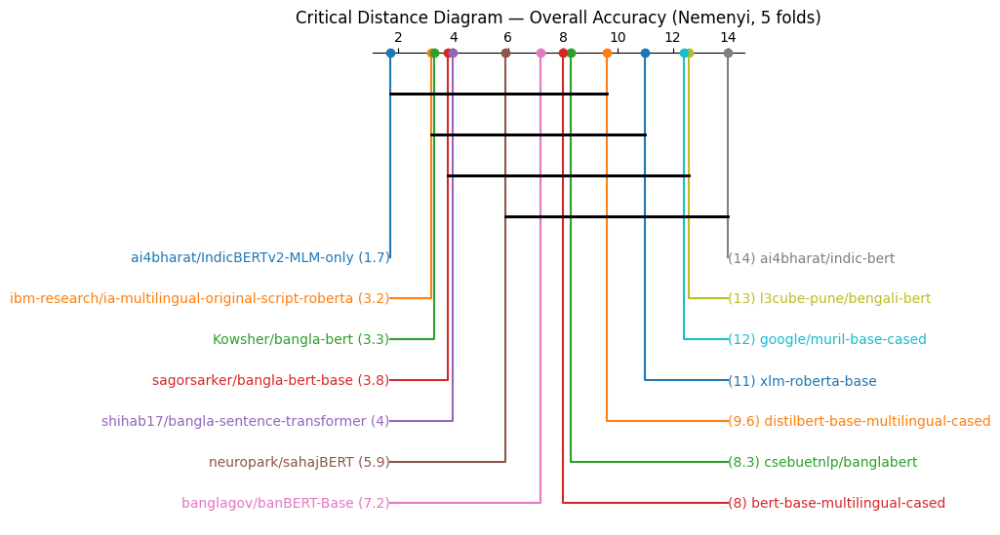

CD diagram rendered and held in memory as 'overall'.

FRIEDMAN TEST — Class: Argulosis
Friedman chi-square statistic: 30.8829
p-value: 0.003507
[OK] Friedman significant (p < 0.05) — proceeding to Nemenyi post-hoc.

Nemenyi pairwise p-value matrix computed.


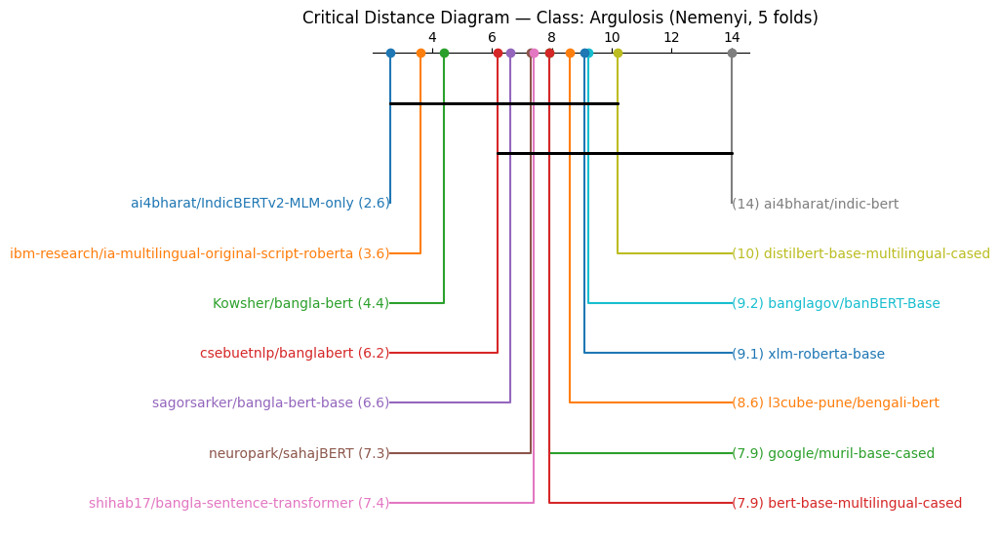

CD diagram rendered and held in memory as 'class_Argulosis'.

FRIEDMAN TEST — Class: Dropsy
Friedman chi-square statistic: 29.2744
p-value: 0.005984
[OK] Friedman significant (p < 0.05) — proceeding to Nemenyi post-hoc.

Nemenyi pairwise p-value matrix computed.


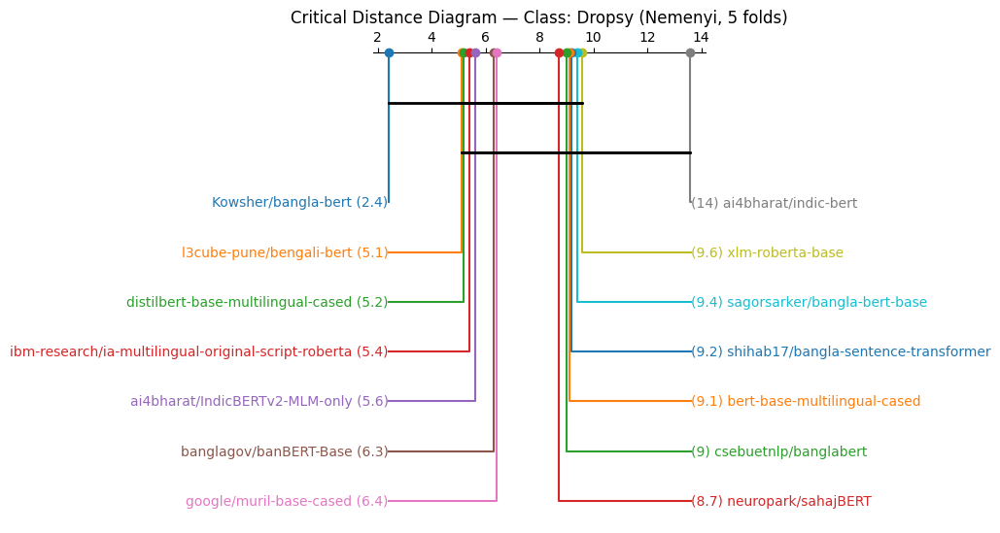

CD diagram rendered and held in memory as 'class_Dropsy'.

FRIEDMAN TEST — Class: Epizootic Ulcerative Syndrome
Friedman chi-square statistic: 48.6670
p-value: 0.000005
[OK] Friedman significant (p < 0.05) — proceeding to Nemenyi post-hoc.

Nemenyi pairwise p-value matrix computed.


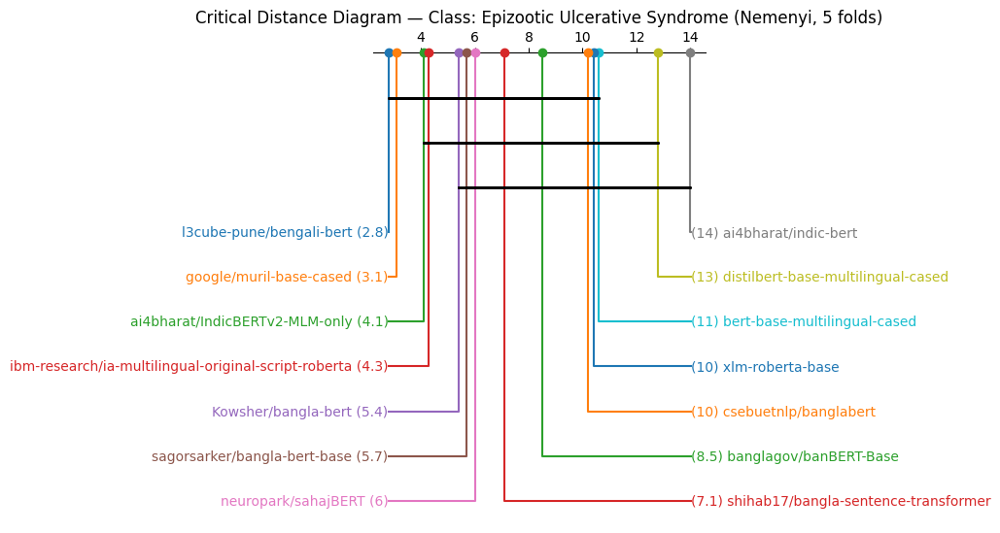

CD diagram rendered and held in memory as 'class_Epizootic_Ulcerative_Syndrome'.

FRIEDMAN TEST — Class: Fin and Tail Rot
Friedman chi-square statistic: 41.3363
p-value: 0.000084
[OK] Friedman significant (p < 0.05) — proceeding to Nemenyi post-hoc.

Nemenyi pairwise p-value matrix computed.


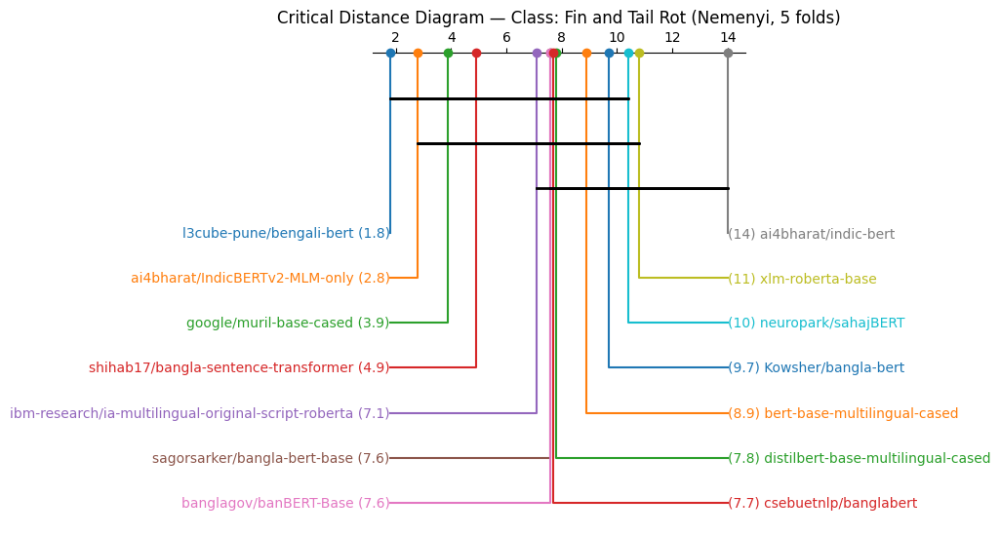

CD diagram rendered and held in memory as 'class_Fin_and_Tail_Rot'.

FRIEDMAN TEST — Class: Gill Rot
Friedman chi-square statistic: 35.1229
p-value: 0.000811
[OK] Friedman significant (p < 0.05) — proceeding to Nemenyi post-hoc.

Nemenyi pairwise p-value matrix computed.


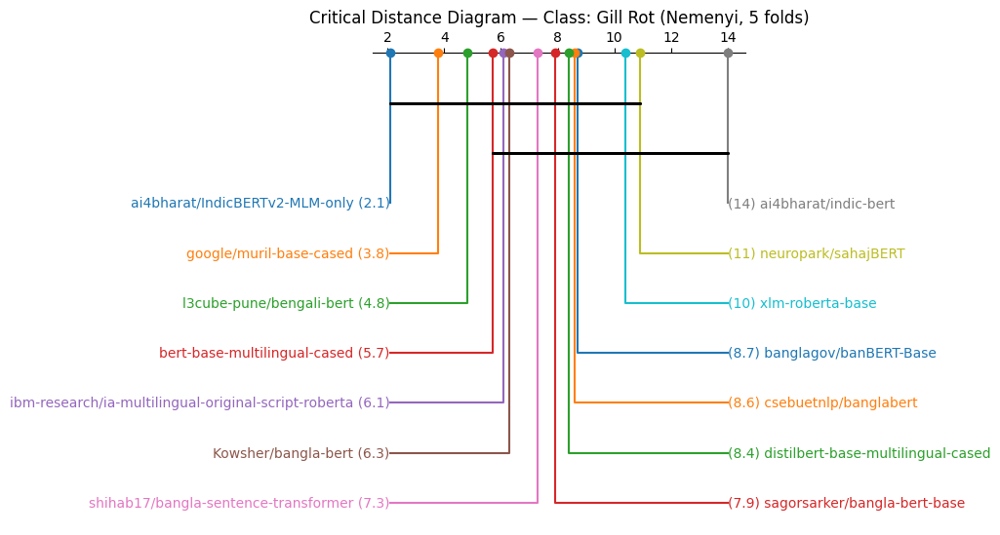

CD diagram rendered and held in memory as 'class_Gill_Rot'.

FRIEDMAN TEST — Class: Hemorrhagic Septicemia
Friedman chi-square statistic: 56.1598
p-value: 0.000000
[OK] Friedman significant (p < 0.05) — proceeding to Nemenyi post-hoc.

Nemenyi pairwise p-value matrix computed.


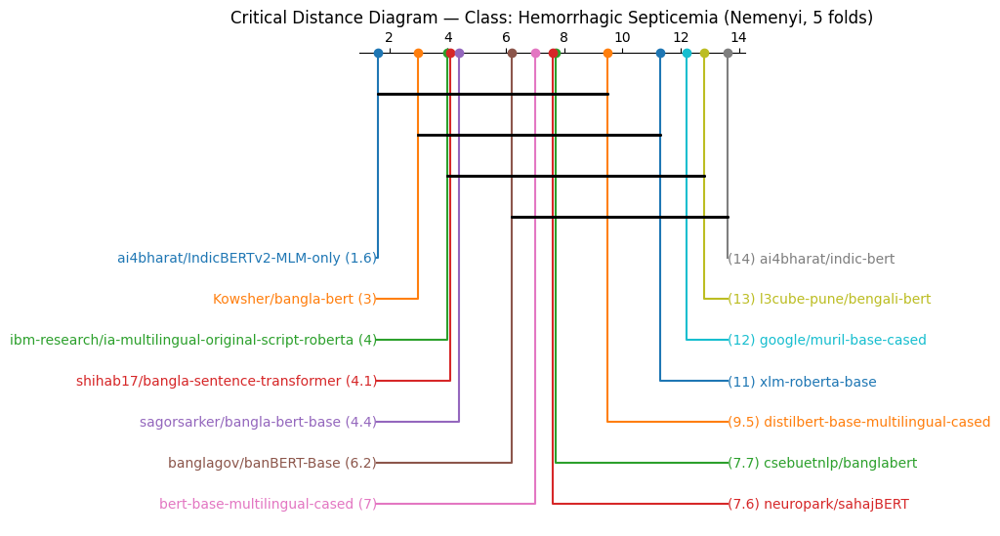

CD diagram rendered and held in memory as 'class_Hemorrhagic_Septicemia'.

FRIEDMAN TEST — Class: Myxoboliasis
Friedman chi-square statistic: 54.7293
p-value: 0.000000
[OK] Friedman significant (p < 0.05) — proceeding to Nemenyi post-hoc.

Nemenyi pairwise p-value matrix computed.


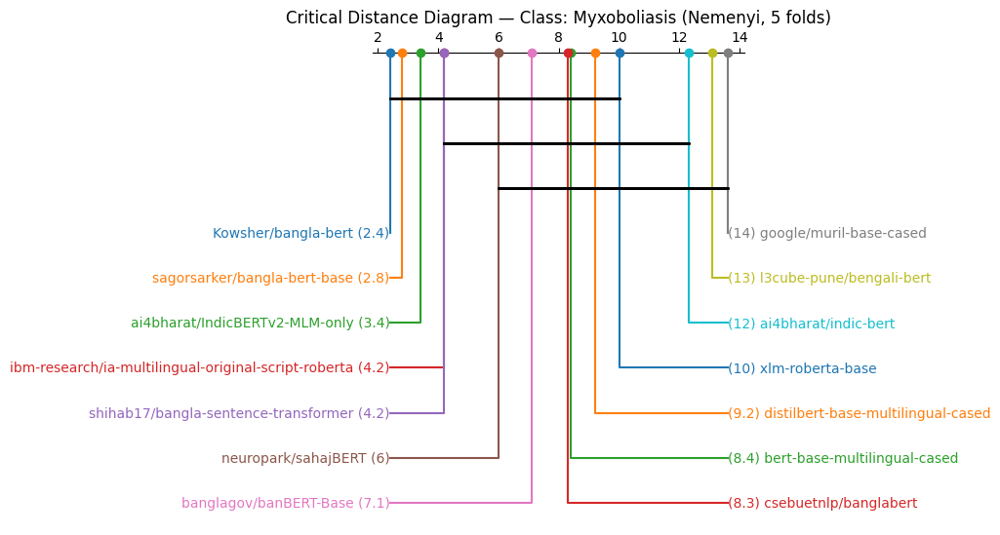

CD diagram rendered and held in memory as 'class_Myxoboliasis'.

FRIEDMAN TEST — Class: Pop Eye
Friedman chi-square statistic: 34.5838
p-value: 0.000981
[OK] Friedman significant (p < 0.05) — proceeding to Nemenyi post-hoc.

Nemenyi pairwise p-value matrix computed.


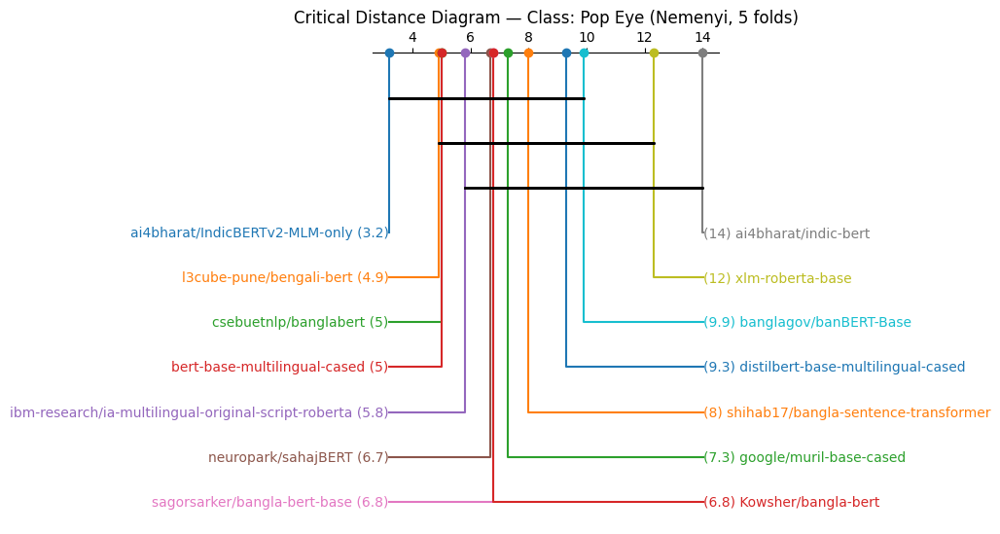

CD diagram rendered and held in memory as 'class_Pop_Eye'.

FRIEDMAN TEST — Class: Red Spot Disease
Friedman chi-square statistic: 49.1117
p-value: 0.000004
[OK] Friedman significant (p < 0.05) — proceeding to Nemenyi post-hoc.

Nemenyi pairwise p-value matrix computed.


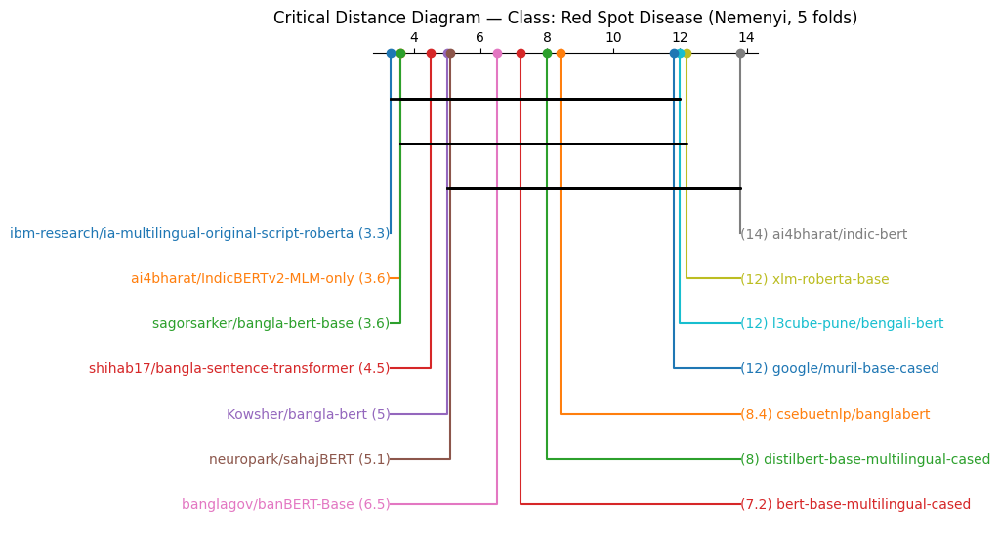

CD diagram rendered and held in memory as 'class_Red_Spot_Disease'.

FRIEDMAN TEST — Class: Saprolegniasis
Friedman chi-square statistic: 43.5970
p-value: 0.000036
[OK] Friedman significant (p < 0.05) — proceeding to Nemenyi post-hoc.

Nemenyi pairwise p-value matrix computed.


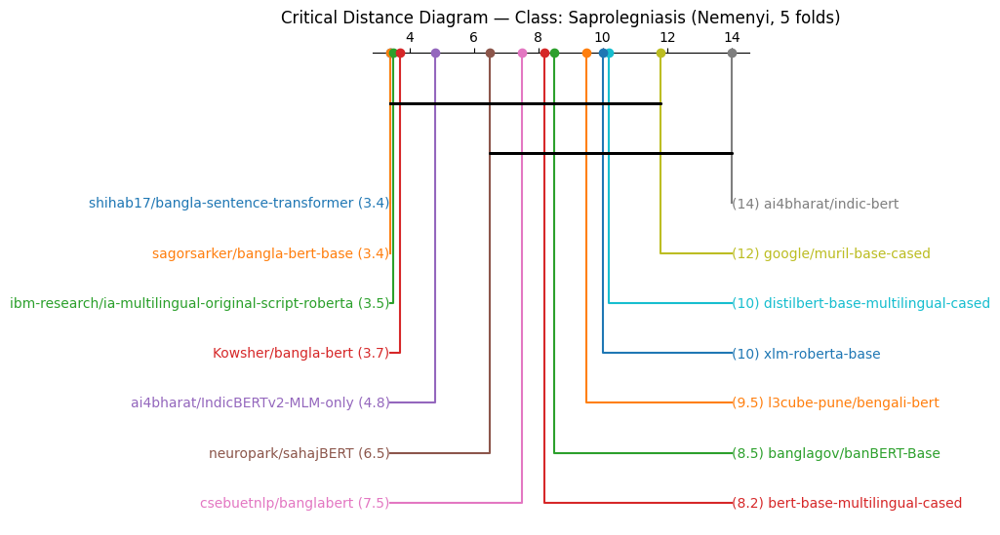

CD diagram rendered and held in memory as 'class_Saprolegniasis'.

FRIEDMAN TEST — Class: Streptococcosis
Friedman chi-square statistic: 43.9415
p-value: 0.000031
[OK] Friedman significant (p < 0.05) — proceeding to Nemenyi post-hoc.

Nemenyi pairwise p-value matrix computed.


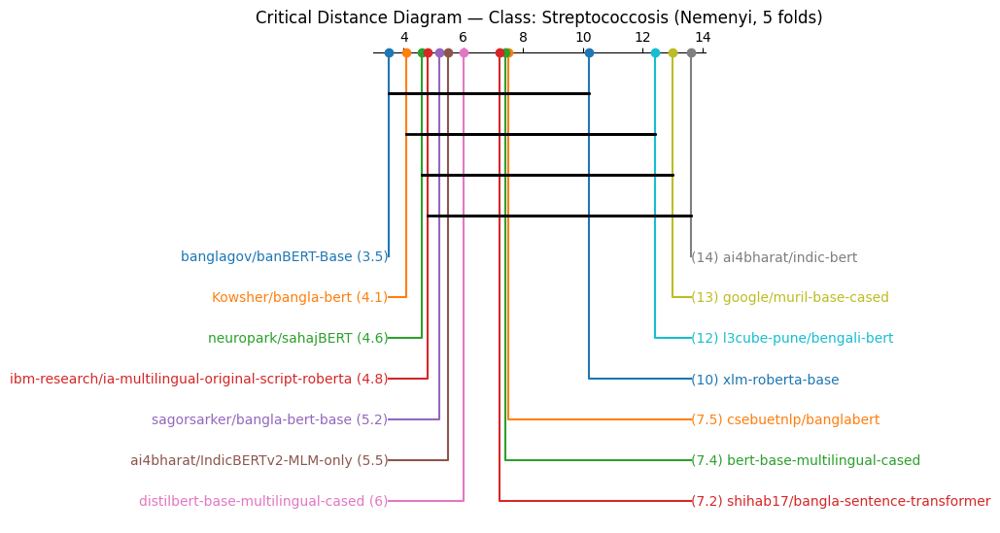

CD diagram rendered and held in memory as 'class_Streptococcosis'.

FRIEDMAN TEST — Class: White Spot Disease
Friedman chi-square statistic: 35.3527
p-value: 0.000747
[OK] Friedman significant (p < 0.05) — proceeding to Nemenyi post-hoc.

Nemenyi pairwise p-value matrix computed.


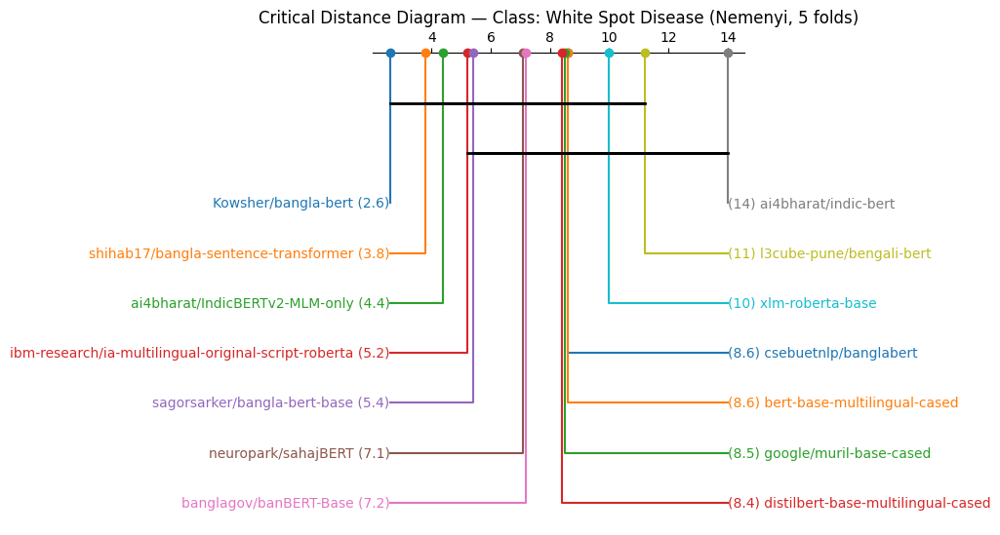

CD diagram rendered and held in memory as 'class_White_Spot_Disease'.

McNEMAR PAIRWISE TESTS (pooled OOF predictions)
                                             model_a                                              model_b  a_only_correct  b_only_correct  statistic  p_value  p_value_holm_corrected  significant_after_correction
                      ai4bharat/IndicBERTv2-MLM-only ibm-research/ia-multilingual-original-script-roberta             226             201   1.348946 0.245462                0.745040                         False
                      ai4bharat/IndicBERTv2-MLM-only                                  Kowsher/bangla-bert             217             187   2.081683 0.149076                0.745040                         False
                      ai4bharat/IndicBERTv2-MLM-only                 shihab17/bangla-sentence-transformer             250             189   8.200456 0.004188                0.039519                          True
                      ai4bharat/I

In [ ]:
# ============================================================================
# STATISTICAL COMPARISON: Friedman + Nemenyi + Per-Class + McNemar
# Google Colab ready — paste into a single cell and run.
# Results are saved to BOTH Google Drive and the Colab local output folder.
# ============================================================================

# ============================================================================
# 0. MOUNT DRIVE & INSTALL DEPENDENCIES (Colab only)
# ============================================================================
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("[INFO] Not running in Colab — skipping drive.mount(). "
          "Make sure DRIVE_ROOT below points to your local data instead.")

get_ipython().system('pip install -U scikit-posthocs statsmodels reportlab --quiet') if IN_COLAB else None

import os
import re
import io
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scikit_posthocs as sp
from scipy.stats import friedmanchisquare
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import f1_score
from datetime import datetime

from reportlab.lib.pagesizes import letter
from reportlab.lib.units import inch
from reportlab.lib import colors
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, PageBreak
)
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle

# ============================================================================
# 1. CONFIG — folder -> model name mapping
# ============================================================================
DRIVE_ROOT = "/content/drive/MyDrive"
N_SPLITS = 5

# 14 models total (confirmed against reported CV metrics)
MODEL_DIRS = {
    "indicbertv2_aquadx_cv":              "ai4bharat/IndicBERTv2-MLM-only",
    "ibm_multilingual_roberta_aquadx_cv": "ibm-research/ia-multilingual-original-script-roberta",
    "kowsher_bangla_bert_aquadx_cv":      "Kowsher/bangla-bert",
    "bangla_sentence_transformer_aquadx_cv": "shihab17/bangla-sentence-transformer",
    "bangla_bert_aquadx_cv":              "sagorsarker/bangla-bert-base",
    "sahajBERT_aquadx_cv":                "neuropark/sahajBERT",
    "banbert_base_aquadx_cv":             "banglagov/banBERT-Base",
    "mbert_aquadx_cv":                    "bert-base-multilingual-cased",
    "banglabert_aquadx_cv":               "csebuetnlp/banglabert",
    "distilbert_multi_aquadx_cv":         "distilbert-base-multilingual-cased",
    "xlm_roberta_base_aquadx_cv":         "xlm-roberta-base",
    "muril_aquadx_cv":                    "google/muril-base-cased",
    "l3cube_bengali_bert_aquadx_cv":      "l3cube-pune/bengali-bert",
    "indic_bert_aquadx_cv":               "ai4bharat/indic-bert",
}

# Models to include in the pairwise McNemar comparison (keep this small —
# McNemar answers "does model A get different SENTENCES right than model B",
# and every extra model adds pairs that need multiple-comparison correction)
MCNEMAR_MODELS = [
    "ai4bharat/IndicBERTv2-MLM-only",
    "ibm-research/ia-multilingual-original-script-roberta",
    "Kowsher/bangla-bert",
    "shihab17/bangla-sentence-transformer",
    "sagorsarker/bangla-bert-base",
]

# Results are consolidated into THREE single files (JSON, TXT, PDF), each
# written to Drive (persistent) AND a local Colab folder.
DRIVE_OUTPUT_DIR = os.path.join(DRIVE_ROOT, "stat_comparison_results")
LOCAL_OUTPUT_DIR = "/content/stat_comparison_results" if IN_COLAB else "./stat_comparison_results"

os.makedirs(DRIVE_OUTPUT_DIR, exist_ok=True)
os.makedirs(LOCAL_OUTPUT_DIR, exist_ok=True)

BASENAME = "statistical_comparison_report"

# In-memory results store — every function below appends to this instead of
# writing its own file. The consolidation step at the end turns this into
# the JSON / TXT / PDF outputs.
RESULTS = {
    "generated_at": datetime.now().isoformat(),
    "n_models": len(MODEL_DIRS),
    "n_folds": N_SPLITS,
    "fold_alignment_ok": None,
    "overall_accuracy": {
        "per_fold_table": None,   # dict: model -> [fold1, fold2, ...]
        "friedman_stat": None,
        "friedman_p": None,
        "nemenyi_pvalues": None,  # dict of dicts
        "cd_diagram_png": None,   # in-memory PNG bytes, base64 for JSON
    },
    "per_class": {},              # class_name -> same shape as overall_accuracy
    "mcnemar": {
        "pairs": []
    },
}
_CD_IMAGE_BUFFERS = {}  # save_prefix -> raw PNG bytes, for embedding in PDF

# ============================================================================
# 2. VALIDATE FOLD ALIGNMENT ACROSS MODELS (critical for Friedman/Nemenyi/McNemar)
# ============================================================================
def check_fold_alignment():
    """Nemenyi/McNemar assume the same validation samples in fold i across
    all models. This checks val_indices.npy matches across every model's
    fold_1, fold_2, ... — if it doesn't, the paired tests are invalid."""
    ref_indices = {}
    mismatches = []

    for folder in MODEL_DIRS:
        model_dir = os.path.join(DRIVE_ROOT, folder)
        for fold in range(1, N_SPLITS + 1):
            path = os.path.join(model_dir, f"fold_{fold}", "val_indices.npy")
            if not os.path.exists(path):
                mismatches.append(f"MISSING: {path}")
                continue
            idx = np.load(path)
            if fold not in ref_indices:
                ref_indices[fold] = (folder, idx)
            else:
                ref_folder, ref_idx = ref_indices[fold]
                if not np.array_equal(np.sort(idx), np.sort(ref_idx)):
                    mismatches.append(
                        f"Fold {fold} mismatch: {folder} vs {ref_folder} "
                        f"(sizes {len(idx)} vs {len(ref_idx)})"
                    )

    if mismatches:
        print("[WARNING] Fold alignment issues found:")
        for m in mismatches:
            print("  -", m)
        print(
            "\nThese paired tests (Friedman/Nemenyi/McNemar) assume identical "
            "fold splits across models. If your val_indices genuinely differ, "
            "these results are NOT valid paired comparisons — you'd need to "
            "either re-run CV with a fixed split file shared across models, "
            "or switch to an unpaired test.\n"
        )
        RESULTS["fold_alignment_ok"] = False
        RESULTS["fold_alignment_issues"] = mismatches
        return False
    else:
        print(f"[OK] All {N_SPLITS} folds have matching validation indices across all models.\n")
        RESULTS["fold_alignment_ok"] = True
        return True

# ============================================================================
# 3. LOAD PER-FOLD ACCURACY (for Friedman + Nemenyi)
# ============================================================================
def load_fold_accuracies():
    """Returns a DataFrame: rows = folds, columns = model names, values = accuracy."""
    records = {}
    for folder, model_name in MODEL_DIRS.items():
        model_dir = os.path.join(DRIVE_ROOT, folder)
        accs = []
        for fold in range(1, N_SPLITS + 1):
            fold_dir = os.path.join(model_dir, f"fold_{fold}")
            logits = np.load(os.path.join(fold_dir, "logits.npy"))
            labels = np.load(os.path.join(fold_dir, "labels.npy"))
            preds = np.argmax(logits, axis=-1)
            acc = (preds == labels).mean()
            accs.append(acc)
        records[model_name] = accs

    df = pd.DataFrame(records)
    df.index = [f"fold_{i+1}" for i in range(N_SPLITS)]
    return df

# ============================================================================
# 4. LOAD PER-FOLD, PER-CLASS F1 (for per-class Friedman + Nemenyi)
# ============================================================================
def load_fold_class_f1():
    """Returns dict: class_label -> DataFrame (rows=folds, cols=models, values=F1)."""
    # Need label_names.json from any one model dir (same label encoding for all)
    any_folder = next(iter(MODEL_DIRS))
    label_names_path = os.path.join(DRIVE_ROOT, any_folder, "label_names.json")
    with open(label_names_path, "r", encoding="utf-8") as f:
        label_names = json.load(f)

    per_class_records = {cls: {} for cls in label_names}

    for folder, model_name in MODEL_DIRS.items():
        model_dir = os.path.join(DRIVE_ROOT, folder)
        per_class_fold_f1 = {cls: [] for cls in label_names}

        for fold in range(1, N_SPLITS + 1):
            fold_dir = os.path.join(model_dir, f"fold_{fold}")
            logits = np.load(os.path.join(fold_dir, "logits.npy"))
            labels = np.load(os.path.join(fold_dir, "labels.npy"))
            preds = np.argmax(logits, axis=-1)

            f1_per_class = f1_score(
                labels, preds, average=None,
                labels=list(range(len(label_names))), zero_division=0
            )
            for i, cls in enumerate(label_names):
                per_class_fold_f1[cls].append(f1_per_class[i])

        for cls in label_names:
            per_class_records[cls][model_name] = per_class_fold_f1[cls]

    per_class_dfs = {}
    for cls in label_names:
        df = pd.DataFrame(per_class_records[cls])
        df.index = [f"fold_{i+1}" for i in range(N_SPLITS)]
        per_class_dfs[cls] = df

    return per_class_dfs, label_names

# ============================================================================
# 5. FRIEDMAN + NEMENYI + CD DIAGRAM
# ============================================================================
def run_friedman_nemenyi(acc_df, title_suffix="", save_prefix="overall", result_slot=None):
    """result_slot: the dict inside RESULTS to populate (either
    RESULTS['overall_accuracy'] or RESULTS['per_class'][cls])."""
    print(f"\n{'='*60}\nFRIEDMAN TEST — {title_suffix or 'overall accuracy'}\n{'='*60}")

    if result_slot is None:
        result_slot = {}

    result_slot["per_fold_table"] = acc_df.to_dict(orient="list")

    stat, p = friedmanchisquare(*[acc_df[col].values for col in acc_df.columns])
    print(f"Friedman chi-square statistic: {stat:.4f}")
    print(f"p-value: {p:.6f}")
    result_slot["friedman_stat"] = float(stat)
    result_slot["friedman_p"] = float(p)

    if p >= 0.05:
        print(
            "[NOTE] Friedman test is NOT significant (p >= 0.05). "
            "Standard practice: do NOT proceed to Nemenyi post-hoc — "
            "there's no statistically supported evidence the models differ. "
            "Report this null result as-is; running Nemenyi anyway and "
            "reporting whatever comes out would be a reviewer red flag.\n"
        )
        result_slot["nemenyi_pvalues"] = None
        result_slot["cd_diagram_png"] = None
        return None, stat, p

    print("[OK] Friedman significant (p < 0.05) — proceeding to Nemenyi post-hoc.\n")

    # Nemenyi post-hoc (scikit-posthocs expects long-form or wide array)
    nemenyi_result = sp.posthoc_nemenyi_friedman(acc_df.values)
    nemenyi_result.columns = acc_df.columns
    nemenyi_result.index = acc_df.columns
    result_slot["nemenyi_pvalues"] = nemenyi_result.round(6).to_dict()
    print("Nemenyi pairwise p-value matrix computed.")

    # Average ranks (needed for CD diagram — lower rank = better, so we rank
    # descending accuracy)
    ranks = acc_df.rank(axis=1, ascending=False).mean(axis=0)

    # Critical distance diagram — render to an in-memory PNG buffer instead
    # of a standalone file, so it can be embedded directly in the PDF report.
    n_datasets = acc_df.shape[0]  # number of folds
    n_models = acc_df.shape[1]
    fig = plt.figure(figsize=(10, max(4, n_models * 0.4)))
    sp.critical_difference_diagram(ranks, nemenyi_result)
    plt.title(f"Critical Distance Diagram — {title_suffix or 'Overall Accuracy'} "
              f"(Nemenyi, {n_datasets} folds)")
    plt.tight_layout()

    buf = io.BytesIO()
    plt.savefig(buf, format="png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    buf.seek(0)
    png_bytes = buf.read()

    _CD_IMAGE_BUFFERS[save_prefix] = png_bytes
    result_slot["cd_diagram_png"] = save_prefix  # reference key, actual bytes kept out of JSON
    print(f"CD diagram rendered and held in memory as '{save_prefix}'.")

    return nemenyi_result, stat, p

# ============================================================================
# 6. McNEMAR TESTS (pairwise, pooled out-of-fold predictions)
# ============================================================================
def load_pooled_predictions(folder):
    """Pools predictions + labels across all folds in the ORIGINAL sample-index
    order, so predictions from different models line up sample-for-sample."""
    model_dir = os.path.join(DRIVE_ROOT, folder)
    all_preds, all_labels, all_idx = [], [], []

    for fold in range(1, N_SPLITS + 1):
        fold_dir = os.path.join(model_dir, f"fold_{fold}")
        logits = np.load(os.path.join(fold_dir, "logits.npy"))
        labels = np.load(os.path.join(fold_dir, "labels.npy"))
        val_idx = np.load(os.path.join(fold_dir, "val_indices.npy"))
        preds = np.argmax(logits, axis=-1)

        all_preds.append(preds)
        all_labels.append(labels)
        all_idx.append(val_idx)

    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)
    all_idx = np.concatenate(all_idx)

    # Sort by original sample index so every model's array lines up sample-for-sample
    order = np.argsort(all_idx)
    return all_preds[order], all_labels[order], all_idx[order]


def run_mcnemar_tests(model_subset):
    print(f"\n{'='*60}\nMcNEMAR PAIRWISE TESTS (pooled OOF predictions)\n{'='*60}")

    name_to_folder = {v: k for k, v in MODEL_DIRS.items()}
    pooled = {}
    ref_idx = None

    for model_name in model_subset:
        folder = name_to_folder[model_name]
        preds, labels, idx = load_pooled_predictions(folder)
        if ref_idx is None:
            ref_idx = idx
        elif not np.array_equal(idx, ref_idx):
            raise ValueError(
                f"Sample index order mismatch for {model_name} — pooled folds "
                f"don't align sample-for-sample with other models. Check that "
                f"every model's 5 folds cover the same full dataset."
            )
        correct = (preds == labels).astype(int)  # 1 = correct, 0 = wrong
        pooled[model_name] = correct

    results = []
    pairs = [(a, b) for i, a in enumerate(model_subset) for b in model_subset[i+1:]]

    for a, b in pairs:
        correct_a = pooled[a]
        correct_b = pooled[b]

        # 2x2 contingency table: both correct, a-only, b-only, both wrong
        both_correct = np.sum((correct_a == 1) & (correct_b == 1))
        a_only = np.sum((correct_a == 1) & (correct_b == 0))
        b_only = np.sum((correct_a == 0) & (correct_b == 1))
        both_wrong = np.sum((correct_a == 0) & (correct_b == 0))

        table = [[both_correct, a_only], [b_only, both_wrong]]
        result = mcnemar(table, exact=(a_only + b_only < 25), correction=True)

        results.append({
            "model_a": a, "model_b": b,
            "a_only_correct": a_only, "b_only_correct": b_only,
            "statistic": result.statistic, "p_value": result.pvalue,
        })

    results_df = pd.DataFrame(results)

    # Multiple-comparison correction across all pairs tested (Holm-Bonferroni)
    reject, p_corrected, _, _ = multipletests(results_df["p_value"], method="holm")
    results_df["p_value_holm_corrected"] = p_corrected
    results_df["significant_after_correction"] = reject

    print(results_df.to_string(index=False))
    RESULTS["mcnemar"]["pairs"] = results_df.to_dict(orient="records")

    return results_df

# ============================================================================
# 7. CONSOLIDATION — build the single .json, .txt, .pdf reports
# ============================================================================
def write_json_report():
    path_local = os.path.join(LOCAL_OUTPUT_DIR, f"{BASENAME}.json")
    path_drive = os.path.join(DRIVE_OUTPUT_DIR, f"{BASENAME}.json")
    payload = json.dumps(RESULTS, indent=2, default=str)
    for path in (path_local, path_drive):
        with open(path, "w", encoding="utf-8") as f:
            f.write(payload)
    print(f"[SAVED] JSON report:\n  - {path_local}\n  - {path_drive}")


def _fmt_pct(x):
    return f"{x*100:.2f}%"


def write_txt_report():
    lines = []
    lines.append("=" * 78)
    lines.append("STATISTICAL COMPARISON REPORT")
    lines.append(f"Generated: {RESULTS['generated_at']}")
    lines.append(f"Models: {RESULTS['n_models']}   Folds: {RESULTS['n_folds']}")
    lines.append("=" * 78)

    lines.append(f"\nFold alignment check: "
                 f"{'OK' if RESULTS['fold_alignment_ok'] else 'FAILED'}")
    if not RESULTS["fold_alignment_ok"]:
        lines.append("Issues:")
        for issue in RESULTS.get("fold_alignment_issues", []):
            lines.append(f"  - {issue}")

    def render_section(slot, header):
        lines.append("\n" + "-" * 78)
        lines.append(header)
        lines.append("-" * 78)
        lines.append(f"Friedman chi-square: {slot['friedman_stat']:.4f}   "
                     f"p-value: {slot['friedman_p']:.6f}")
        if slot["friedman_p"] >= 0.05:
            lines.append("Not significant (p >= 0.05) — Nemenyi post-hoc skipped.")
            return
        lines.append("Significant — Nemenyi post-hoc computed, CD diagram in PDF report.")
        lines.append("\nNemenyi pairwise p-values:")
        nem = slot["nemenyi_pvalues"]
        if nem:
            nem_df = pd.DataFrame(nem)
            lines.append(nem_df.round(4).to_string())

    render_section(RESULTS["overall_accuracy"], "OVERALL ACCURACY")

    for cls, slot in RESULTS["per_class"].items():
        render_section(slot, f"PER-CLASS F1 — {cls}")

    lines.append("\n" + "-" * 78)
    lines.append("McNEMAR PAIRWISE TESTS (Holm-corrected)")
    lines.append("-" * 78)
    if RESULTS["mcnemar"]["pairs"]:
        mc_df = pd.DataFrame(RESULTS["mcnemar"]["pairs"])
        lines.append(mc_df.to_string(index=False))

    content = "\n".join(lines)
    path_local = os.path.join(LOCAL_OUTPUT_DIR, f"{BASENAME}.txt")
    path_drive = os.path.join(DRIVE_OUTPUT_DIR, f"{BASENAME}.txt")
    for path in (path_local, path_drive):
        with open(path, "w", encoding="utf-8") as f:
            f.write(content)
    print(f"[SAVED] TXT report:\n  - {path_local}\n  - {path_drive}")


def write_pdf_report():
    styles = getSampleStyleSheet()
    title_style = styles["Title"]
    h2 = styles["Heading2"]
    h3 = styles["Heading3"]
    body = styles["Normal"]
    small = ParagraphStyle("small", parent=body, fontSize=8, leading=10)

    story = []
    story.append(Paragraph("Statistical Comparison Report", title_style))
    story.append(Paragraph(
        f"Generated: {RESULTS['generated_at']} &nbsp;|&nbsp; "
        f"Models: {RESULTS['n_models']} &nbsp;|&nbsp; Folds: {RESULTS['n_folds']}",
        body
    ))
    story.append(Spacer(1, 12))

    align_text = "OK" if RESULTS["fold_alignment_ok"] else "FAILED"
    story.append(Paragraph(f"<b>Fold alignment check:</b> {align_text}", body))
    story.append(Spacer(1, 12))

    def df_to_table(df, max_cols_per_row=8):
        """Splits wide dataframes into multiple stacked tables if needed."""
        tables = []
        cols = list(df.columns)
        for i in range(0, len(cols), max_cols_per_row):
            chunk_cols = cols[i:i + max_cols_per_row]
            chunk = df[chunk_cols].round(4)
            data = [["model"] + list(chunk_cols)]
            for idx, row in chunk.iterrows():
                data.append([str(idx)] + [str(v) for v in row.values])
            t = Table(data, repeatRows=1)
            t.setStyle(TableStyle([
                ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#2c3e50")),
                ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
                ("FONTSIZE", (0, 0), (-1, -1), 7),
                ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
                ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, colors.HexColor("#f2f2f2")]),
            ]))
            tables.append(t)
            tables.append(Spacer(1, 8))
        return tables

    def render_section(slot, header):
        story.append(PageBreak())
        story.append(Paragraph(header, h2))

        story.append(Paragraph(
            f"Friedman chi-square statistic: {slot['friedman_stat']:.4f} &nbsp;|&nbsp; "
            f"p-value: {slot['friedman_p']:.6f}",
            body
        ))

        if slot["friedman_p"] >= 0.05:
            story.append(Paragraph(
                "Not significant (p &ge; 0.05) — Nemenyi post-hoc skipped per "
                "standard practice.", body
            ))
            return

        story.append(Paragraph("Significant (p &lt; 0.05) — Nemenyi post-hoc below.", body))
        story.append(Spacer(1, 8))

        story.append(Paragraph("Per-fold values:", h3))
        pf_df = pd.DataFrame(slot["per_fold_table"])
        story.extend(df_to_table(pf_df.T))

        if slot["nemenyi_pvalues"]:
            story.append(Paragraph("Nemenyi pairwise p-values:", h3))
            nem_df = pd.DataFrame(slot["nemenyi_pvalues"])
            story.extend(df_to_table(nem_df))

        cd_key = slot.get("cd_diagram_png")
        if cd_key and cd_key in _CD_IMAGE_BUFFERS:
            story.append(Paragraph("Critical Distance Diagram:", h3))
            img_buf = io.BytesIO(_CD_IMAGE_BUFFERS[cd_key])
            story.append(Image(img_buf, width=6.5 * inch, height=3 * inch, kind="proportional"))
            story.append(Spacer(1, 8))

    render_section(RESULTS["overall_accuracy"], "Overall Accuracy")

    for cls, slot in RESULTS["per_class"].items():
        render_section(slot, f"Per-Class F1 — {cls}")

    story.append(PageBreak())
    story.append(Paragraph("McNemar Pairwise Tests (Holm-corrected)", h2))
    if RESULTS["mcnemar"]["pairs"]:
        mc_df = pd.DataFrame(RESULTS["mcnemar"]["pairs"])
        data = [list(mc_df.columns)] + mc_df.round(4).astype(str).values.tolist()
        t = Table(data, repeatRows=1)
        t.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#2c3e50")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("FONTSIZE", (0, 0), (-1, -1), 7),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, colors.HexColor("#f2f2f2")]),
        ]))
        story.append(t)

    path_local = os.path.join(LOCAL_OUTPUT_DIR, f"{BASENAME}.pdf")
    doc = SimpleDocTemplate(path_local, pagesize=letter,
                            topMargin=0.75*inch, bottomMargin=0.75*inch)
    doc.build(story)

    path_drive = os.path.join(DRIVE_OUTPUT_DIR, f"{BASENAME}.pdf")
    with open(path_local, "rb") as src, open(path_drive, "wb") as dst:
        dst.write(src.read())

    print(f"[SAVED] PDF report:\n  - {path_local}\n  - {path_drive}")


# ============================================================================
# 8. MAIN
# ============================================================================
if __name__ == "__main__":
    aligned = check_fold_alignment()
    if not aligned:
        print("[STOP] Fix fold alignment before trusting any test below.")
        write_json_report()
        write_txt_report()
        raise SystemExit(1)

    # --- Overall accuracy: Friedman + Nemenyi + CD diagram ---
    acc_df = load_fold_accuracies()
    print("Per-fold accuracy table:\n", acc_df, "\n")

    run_friedman_nemenyi(
        acc_df, title_suffix="Overall Accuracy", save_prefix="overall",
        result_slot=RESULTS["overall_accuracy"]
    )

    # --- Per-class F1: Friedman + Nemenyi + CD diagram, one per class ---
    per_class_dfs, label_names = load_fold_class_f1()
    for cls in label_names:
        cls_df = per_class_dfs[cls]
        safe_cls_name = re.sub(r"[^A-Za-z0-9_-]", "_", str(cls))
        RESULTS["per_class"][cls] = {}
        run_friedman_nemenyi(
            cls_df, title_suffix=f"Class: {cls}", save_prefix=f"class_{safe_cls_name}",
            result_slot=RESULTS["per_class"][cls]
        )

    # --- McNemar pairwise on top candidates ---
    run_mcnemar_tests(MCNEMAR_MODELS)

    # --- Write the three consolidated report files (each to Drive + local) ---
    write_json_report()
    write_txt_report()
    write_pdf_report()

    print(f"\n[DONE] All results consolidated into {BASENAME}.{{json,txt,pdf}}")
    print(f"  Local:  {LOCAL_OUTPUT_DIR}")
    print(f"  Drive:  {DRIVE_OUTPUT_DIR}")

# ENSEMBLE

In [ ]:
# =============================================================================
# AquaDx Soft Ensemble — Top 5 Statistically-Tied Models
# Phase 1: average saved validation logits (no retraining, no GPU needed)
# =============================================================================
#
# Models being ensembled (Nemenyi-tied cluster, chosen per project brief):
#   1. ai4bharat/IndicBERTv2-MLM-only
#   2. ibm-research/ia-multilingual-original-script-roberta
#   3. Kowsher/bangla-bert
#   4. shihab17/bangla-sentence-transformer
#   5. sagorsarker/bangla-bert-base
#
# Assumes each model has, per fold, saved:
#   - logits.npy       shape (n_val_samples, 13)   raw logits, pre-softmax
#   - labels.npy        shape (n_val_samples,)       true class indices
#   - val_indices.npy   shape (n_val_samples,)       original dataset indices
#
# All 14 models were re-run on a SHARED split (RANDOM_SEED=42, StratifiedKFold,
# 5-fold) specifically so fold-level arrays are index-aligned across models.
# This script verifies that alignment before averaging — do not skip that check.

import numpy as np
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score, classification_report

# -----------------------------------------------------------------------------
# CONFIG — edit this block to match your Drive layout
# -----------------------------------------------------------------------------

from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = Path('/content/drive/MyDrive')  # <-- adjust if your models aren't directly under MyDrive

MODEL_DIRS = {
    "IndicBERTv2":  BASE_DIR / "indicbertv2_aquadx_cv",
    "ibm-research": BASE_DIR / "ibm_multilingual_roberta_aquadx_cv",
    "Kowsher":      BASE_DIR / "kowsher_bangla_bert_aquadx_cv",
    "shihab17":     BASE_DIR / "bangla_sentence_transformer_aquadx_cv",
    "sagorsarker":  BASE_DIR / "bangla_bert_aquadx_cv",
}

N_FOLDS = 5
N_CLASSES = 12

# Fold subfolders are named fold_1 .. fold_5 (1-indexed), not fold_0-based
FOLD_DIRNAME_FMT = "fold_{}"
FOLD_NUMBERS = range(1, N_FOLDS + 1)  # 1..5

CLASS_NAMES = [
    "White Spot Disease",
    "Myxoboliasis",
    "Streptococcosis",
    "Epizootic Ulcerative Syndrome",
    "Saprolegniasis",
    "Red Spot Disease",
    "Dropsy",
    "Gill Rot",
    "Hemorrhagic Septicemia",
    "Fin and Tail Rot",
    "Argulosis",
    "Pop Eye",
]
LOGITS_FNAME = "logits.npy"
LABELS_FNAME = "labels.npy"
VALIDX_FNAME = "val_indices.npy"

# Outputs are always written to BOTH Drive (persists after the runtime ends)
# AND a local Colab path (fast to read back within the same session).
OUT_DIR_DRIVE = BASE_DIR / "ensemble_top5"
OUT_DIR_LOCAL = Path("/content/ensemble_top5")

# -----------------------------------------------------------------------------
# Load helpers
# -----------------------------------------------------------------------------

def load_fold(model_dir: Path, fold: int):
    """fold is the 1-indexed fold number (1..5), matching the fold_1..fold_5 dirs."""
    fold_dir = model_dir / FOLD_DIRNAME_FMT.format(fold)
    logits = np.load(fold_dir / LOGITS_FNAME)
    labels = np.load(fold_dir / LABELS_FNAME)
    val_idx = np.load(fold_dir / VALIDX_FNAME)
    return logits, labels, val_idx


def softmax(x: np.ndarray) -> np.ndarray:
    x = x - x.max(axis=-1, keepdims=True)
    e = np.exp(x)
    return e / e.sum(axis=-1, keepdims=True)


# -----------------------------------------------------------------------------
# Step 1 — verify fold alignment across all 5 models before touching anything
# -----------------------------------------------------------------------------

def verify_alignment():
    print("Verifying fold-level val_indices alignment across models...\n")
    reference = {}
    ok = True

    for fold in FOLD_NUMBERS:
        idx_sets = {}
        for name, mdir in MODEL_DIRS.items():
            _, _, val_idx = load_fold(mdir, fold)
            idx_sets[name] = val_idx

        names = list(idx_sets.keys())
        base_idx = idx_sets[names[0]]
        base_labels_shape = base_idx.shape

        for name in names[1:]:
            same_len = idx_sets[name].shape == base_labels_shape
            same_vals = same_len and np.array_equal(idx_sets[name], base_idx)
            if not same_vals:
                ok = False
                print(f"  [MISMATCH] fold {fold}: {name} val_indices differ from {names[0]}")
                if same_len:
                    diff = np.where(idx_sets[name] != base_idx)[0][:5]
                    print(f"             first differing positions: {diff}")
                else:
                    print(f"             shape {idx_sets[name].shape} vs {base_labels_shape}")

        reference[fold] = base_idx
        print(f"  fold {fold}: {base_labels_shape[0]} val samples — "
              f"{'aligned' if ok else 'CHECK ABOVE'}")

    if not ok:
        raise RuntimeError(
            "Fold index mismatch detected between models. Do not proceed with "
            "averaging until every model's val_indices match per fold — "
            "otherwise you'll be averaging probabilities for different sentences."
        )

    print("\nAll 5 models aligned on val_indices for every fold. Safe to ensemble.\n")
    return reference


# -----------------------------------------------------------------------------
# Step 2 — average softmax probabilities per fold, evaluate ensemble
# -----------------------------------------------------------------------------

def save_both(filename: str, array: np.ndarray):
    """Save an array to both the Drive output dir and the local Colab output dir."""
    np.save(OUT_DIR_DRIVE / filename, array)
    np.save(OUT_DIR_LOCAL / filename, array)


def build_ensemble():
    OUT_DIR_DRIVE.mkdir(parents=True, exist_ok=True)
    OUT_DIR_LOCAL.mkdir(parents=True, exist_ok=True)

    per_fold_metrics = []
    all_true, all_pred = [], []

    for fold in FOLD_NUMBERS:
        probs_sum = None
        labels_ref = None

        for name, mdir in MODEL_DIRS.items():
            logits, labels, val_idx = load_fold(mdir, fold)
            probs = softmax(logits)

            if probs_sum is None:
                probs_sum = np.zeros_like(probs)
                labels_ref = labels

            probs_sum += probs

        probs_avg = probs_sum / len(MODEL_DIRS)
        preds = probs_avg.argmax(axis=-1)

        acc = accuracy_score(labels_ref, preds)
        f1_macro = f1_score(labels_ref, preds, average="macro")
        f1_per_class = f1_score(labels_ref, preds, average=None, labels=range(N_CLASSES))

        per_fold_metrics.append({
            "fold": fold,
            "accuracy": acc,
            "f1_macro": f1_macro,
            "f1_per_class": f1_per_class,
        })

        save_both(f"fold_{fold}_ensemble_probs.npy", probs_avg)
        save_both(f"fold_{fold}_ensemble_preds.npy", preds)
        save_both(f"fold_{fold}_labels.npy", labels_ref)

        all_true.append(labels_ref)
        all_pred.append(preds)

        print(f"Fold {fold}: acc={acc:.4f}  f1_macro={f1_macro:.4f}")

    return per_fold_metrics, np.concatenate(all_true), np.concatenate(all_pred)


# -----------------------------------------------------------------------------
# Step 3 — summarize: mean ± std across folds, matching the brief's table format
# -----------------------------------------------------------------------------

def summarize(per_fold_metrics, all_true, all_pred):
    accs = np.array([m["accuracy"] for m in per_fold_metrics])
    f1s = np.array([m["f1_macro"] for m in per_fold_metrics])
    per_class_stack = np.stack([m["f1_per_class"] for m in per_fold_metrics])  # (folds, classes)

    print("\n" + "=" * 60)
    print("ENSEMBLE (Top 5) — 5-fold CV summary")
    print("=" * 60)
    print(f"Accuracy: {accs.mean()*100:.2f}% ± {accs.std()*100:.2f}%")
    print(f"F1 (macro): {f1s.mean()*100:.2f}% ± {f1s.std()*100:.2f}%")

    print("\nPer-class F1 (mean ± std across folds):")
    for c in range(N_CLASSES):
        label = CLASS_NAMES[c] if CLASS_NAMES else f"Class {c}"
        col = per_class_stack[:, c]
        print(f"  {label:30s}: {col.mean()*100:.2f}% ± {col.std()*100:.2f}%")

    print("\nPooled classification report (out-of-fold, all folds concatenated):")
    print(classification_report(
        all_true, all_pred,
        target_names=CLASS_NAMES if CLASS_NAMES else None,
        digits=4,
    ))

    # Save a compact summary for the paper
    summary = {
        "accuracy_mean": float(accs.mean()),
        "accuracy_std": float(accs.std()),
        "f1_macro_mean": float(f1s.mean()),
        "f1_macro_std": float(f1s.std()),
        "per_class_f1_mean": per_class_stack.mean(axis=0).tolist(),
        "per_class_f1_std": per_class_stack.std(axis=0).tolist(),
    }
    import json
    for out_dir in (OUT_DIR_DRIVE, OUT_DIR_LOCAL):
        with open(out_dir / "ensemble_summary.json", "w") as f:
            json.dump(summary, f, indent=2)

    save_both("pooled_true.npy", all_true)
    save_both("pooled_pred.npy", all_pred)

    print(f"\nSaved to Drive: {OUT_DIR_DRIVE}")
    print(f"Saved to local Colab: {OUT_DIR_LOCAL}")
    print("(ensemble_summary.json, per-fold probs/preds, pooled arrays — in both locations)")
    print("Pooled arrays are ready for Phase 2 McNemar-motivated error analysis")
    print("(e.g. comparing ensemble vs IndicBERTv2-only pooled predictions).")


# -----------------------------------------------------------------------------
# Run
# -----------------------------------------------------------------------------

if __name__ == "__main__":
    verify_alignment()
    per_fold_metrics, all_true, all_pred = build_ensemble()
    summarize(per_fold_metrics, all_true, all_pred)

Mounted at /content/drive
Verifying fold-level val_indices alignment across models...

  fold 1: 963 val samples — aligned
  fold 2: 963 val samples — aligned
  fold 3: 963 val samples — aligned
  fold 4: 963 val samples — aligned
  fold 5: 962 val samples — aligned

All 5 models aligned on val_indices for every fold. Safe to ensemble.

Fold 1: acc=0.9013  f1_macro=0.9002
Fold 2: acc=0.9221  f1_macro=0.9213
Fold 3: acc=0.9034  f1_macro=0.9015
Fold 4: acc=0.9013  f1_macro=0.8997
Fold 5: acc=0.9064  f1_macro=0.9024

ENSEMBLE (Top 5) — 5-fold CV summary
Accuracy: 90.69% ± 0.78%
F1 (macro): 90.50% ± 0.82%

Per-class F1 (mean ± std across folds):
  White Spot Disease            : 95.36% ± 1.38%
  Myxoboliasis                  : 94.52% ± 1.00%
  Streptococcosis               : 93.78% ± 1.81%
  Epizootic Ulcerative Syndrome : 94.69% ± 1.19%
  Saprolegniasis                : 91.14% ± 2.00%
  Red Spot Disease              : 81.87% ± 3.11%
  Dropsy                        : 84.95% ± 2.34%
  Gill 

# New Stuff

In [ ]:
# ============================================================================
# PHASE 2: ERROR ANALYSIS — AquaDx Top-5 Ensemble Candidates
# ============================================================================
# Loads per-fold logits/labels/val_indices for the 5 ensemble models,
# pools them across folds, reconstructs original sentence text, and produces:
#   1. Consensus failures  — all 5 models wrong on the same sample
#   2. McNemar-pair disagreements — IndicBERTv2 vs shihab17, IndicBERTv2 vs sagorsarker
# No retraining or re-inference — reuses saved logits only.
# ============================================================================

from google.colab import drive
drive.mount('/content/drive')

import os, re, json
import numpy as np
import pandas as pd

# ----------------------------------------------------------------------------
# 1. CONFIG — model folder names as they exist on Drive
# ----------------------------------------------------------------------------
DRIVE_ROOT = "/content/drive/MyDrive"
N_FOLDS = 5

MODEL_DIRS = {
    "indicbertv2":  "indicbertv2_aquadx_cv",
    "ibm_research": "ibm_multilingual_roberta_aquadx_cv",
    "kowsher":      "kowsher_bangla_bert_aquadx_cv",
    "shihab17":     "bangla_sentence_transformer_aquadx_cv",
    "sagorsarker":  "bangla_bert_aquadx_cv",
}

DATA_URL = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

OUTPUT_DIR_DRIVE = os.path.join(DRIVE_ROOT, "phase2_error_analysis")
OUTPUT_DIR_LOCAL = "/content/phase2_error_analysis"
os.makedirs(OUTPUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUTPUT_DIR_LOCAL, exist_ok=True)

# ----------------------------------------------------------------------------
# 2. REBUILD TEXT LOOKUP (same preprocessing as training script)
# ----------------------------------------------------------------------------
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

print("[INFO] Reloading source CSV to rebuild text lookup...")
df = pd.read_csv(DATA_URL)
df = df.rename(columns={"Statement": "text", "Disease": "label_str"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)
df = df.reset_index(drop=True)  # positional index must match val_indices

# ----------------------------------------------------------------------------
# 3. LOAD LABEL NAMES — verify identical across all 5 models
# ----------------------------------------------------------------------------
label_names_per_model = {}
for key, folder in MODEL_DIRS.items():
    path = os.path.join(DRIVE_ROOT, folder, "label_names.json")
    with open(path, "r", encoding="utf-8") as f:
        label_names_per_model[key] = json.load(f)

first_key = list(MODEL_DIRS.keys())[0]
for key in MODEL_DIRS:
    assert label_names_per_model[key] == label_names_per_model[first_key], (
        f"[MISMATCH] label_names.json differs between {first_key} and {key} — "
        "check LabelEncoder consistency before proceeding."
    )
label_names = label_names_per_model[first_key]
print(f"[INFO] Confirmed identical label_names.json across all 5 models "
      f"({len(label_names)} classes).")

# ----------------------------------------------------------------------------
# 4. POOL PER-FOLD LOGITS/LABELS/VAL_INDICES -> PER-MODEL POOLED PREDICTIONS
# ----------------------------------------------------------------------------
def load_pooled_predictions(folder_name):
    """Concatenate fold_1..fold_5 logits/labels/val_indices, sort by val_indices."""
    all_preds, all_labels, all_indices = [], [], []
    for fold in range(1, N_FOLDS + 1):
        fold_dir = os.path.join(DRIVE_ROOT, folder_name, f"fold_{fold}")
        logits = np.load(os.path.join(fold_dir, "logits.npy"))
        labels = np.load(os.path.join(fold_dir, "labels.npy"))
        val_idx = np.load(os.path.join(fold_dir, "val_indices.npy"))

        preds = np.argmax(logits, axis=-1)

        assert len(preds) == len(labels) == len(val_idx), (
            f"[LENGTH MISMATCH] {folder_name} fold_{fold}: "
            f"preds={len(preds)} labels={len(labels)} val_idx={len(val_idx)}"
        )

        all_preds.append(preds)
        all_labels.append(labels)
        all_indices.append(val_idx)

    pooled_preds = np.concatenate(all_preds)
    pooled_labels = np.concatenate(all_labels)
    pooled_indices = np.concatenate(all_indices)

    # Sort by val_indices so row order is consistent across all 5 models
    order = np.argsort(pooled_indices)
    return pooled_indices[order], pooled_preds[order], pooled_labels[order]

print("\n[INFO] Pooling per-fold predictions for each model...")
pooled = {}
for key, folder in MODEL_DIRS.items():
    idx, preds, labels = load_pooled_predictions(folder)
    pooled[key] = {"val_indices": idx, "preds": preds, "labels": labels}
    print(f"  {key:14s} -> {len(idx)} pooled samples "
          f"(min_idx={idx.min()}, max_idx={idx.max()})")

# ----------------------------------------------------------------------------
# 5. ALIGN ALL 5 MODELS ON A SHARED SET OF val_indices
# ----------------------------------------------------------------------------
index_sets = [set(pooled[key]["val_indices"].tolist()) for key in MODEL_DIRS]
shared_indices = sorted(set.intersection(*index_sets))
n_shared = len(shared_indices)
print(f"\n[INFO] Shared val_indices across all 5 models: {n_shared}")

if n_shared != len(index_sets[0]):
    print("[WARN] Not all models cover the exact same indices — "
          "restricting analysis to the intersection. Verify this is expected "
          "(Phase 1 reported 963/963/963/963/962 per fold, 4814 pooled total).")

# Build one aligned dataframe: row = sample, columns = true label + each model's pred
records = []
true_label_lookup = {key: dict(zip(pooled[key]["val_indices"], pooled[key]["labels"]))
                      for key in MODEL_DIRS}
pred_lookup = {key: dict(zip(pooled[key]["val_indices"], pooled[key]["preds"]))
               for key in MODEL_DIRS}

for idx in shared_indices:
    true_labels_here = {key: true_label_lookup[key][idx] for key in MODEL_DIRS}
    # Sanity check: true label for a given sample must agree across all models
    unique_true = set(true_labels_here.values())
    if len(unique_true) != 1:
        print(f"[WARN] True label mismatch at val_index={idx}: {true_labels_here} — skipping.")
        continue

    row = {
        "val_index": idx,
        "true_label_id": true_labels_here[first_key],
        "true_label": label_names[true_labels_here[first_key]],
        "text": df.iloc[idx]["text"],
    }
    for key in MODEL_DIRS:
        pred_id = pred_lookup[key][idx]
        row[f"pred_{key}"] = pred_id
        row[f"pred_{key}_name"] = label_names[pred_id]
        row[f"correct_{key}"] = (pred_id == true_labels_here[key])
    records.append(row)

aligned_df = pd.DataFrame(records)
print(f"[INFO] Aligned dataframe built: {len(aligned_df)} rows.")

aligned_path_drive = os.path.join(OUTPUT_DIR_DRIVE, "aligned_predictions_all5.csv")
aligned_path_local = os.path.join(OUTPUT_DIR_LOCAL, "aligned_predictions_all5.csv")
aligned_df.to_csv(aligned_path_drive, index=False, encoding="utf-8-sig")
aligned_df.to_csv(aligned_path_local, index=False, encoding="utf-8-sig")
print(f"[INFO] Saved aligned predictions to Drive and local.")

# ----------------------------------------------------------------------------
# 6. CONSENSUS FAILURES — all 5 models wrong
# ----------------------------------------------------------------------------
correct_cols = [f"correct_{key}" for key in MODEL_DIRS]
consensus_fail_mask = ~aligned_df[correct_cols].any(axis=1)
consensus_failures = aligned_df[consensus_fail_mask].copy()

print(f"\n[RESULTS] Consensus failures (all 5 models wrong): {len(consensus_failures)} "
      f"of {len(aligned_df)} ({100 * len(consensus_failures) / len(aligned_df):.2f}%)")

# Failure counts by true class — flags classes where consensus failures cluster
fail_by_class = consensus_failures["true_label"].value_counts()
print("\n[RESULTS] Consensus failures by true class:")
print(fail_by_class.to_string())

cf_path_drive = os.path.join(OUTPUT_DIR_DRIVE, "consensus_failures.csv")
cf_path_local = os.path.join(OUTPUT_DIR_LOCAL, "consensus_failures.csv")
consensus_failures.to_csv(cf_path_drive, index=False, encoding="utf-8-sig")
consensus_failures.to_csv(cf_path_local, index=False, encoding="utf-8-sig")

fail_by_class_path_drive = os.path.join(OUTPUT_DIR_DRIVE, "consensus_failures_by_class.csv")
fail_by_class_path_local = os.path.join(OUTPUT_DIR_LOCAL, "consensus_failures_by_class.csv")
fail_by_class.to_csv(fail_by_class_path_drive, header=["count"], encoding="utf-8-sig")
fail_by_class.to_csv(fail_by_class_path_local, header=["count"], encoding="utf-8-sig")

# --- Support-normalized error rate per class ---
# Raw counts are misleading without knowing how many samples per class went
# into the aligned set — normalize by each class's support within aligned_df
# (not the full original df) so denominators match what was actually tested.
support_by_class = aligned_df["true_label"].value_counts()
fail_rate_by_class = (fail_by_class / support_by_class).dropna().sort_values(ascending=False)

normalized_table = pd.DataFrame({
    "consensus_failures": fail_by_class,
    "support": support_by_class,
}).fillna(0)
normalized_table["consensus_failures"] = normalized_table["consensus_failures"].astype(int)
normalized_table["support"] = normalized_table["support"].astype(int)
normalized_table["error_rate_pct"] = (
    100 * normalized_table["consensus_failures"] / normalized_table["support"]
).round(2)
normalized_table = normalized_table.sort_values("error_rate_pct", ascending=False)

print("\n[RESULTS] Consensus failure rate by class (normalized by support):")
print(normalized_table.to_string())

norm_path_drive = os.path.join(OUTPUT_DIR_DRIVE, "consensus_failure_rate_by_class.csv")
norm_path_local = os.path.join(OUTPUT_DIR_LOCAL, "consensus_failure_rate_by_class.csv")
normalized_table.to_csv(norm_path_drive, encoding="utf-8-sig")
normalized_table.to_csv(norm_path_local, encoding="utf-8-sig")

# ----------------------------------------------------------------------------
# 7. McNEMAR-PAIR DISAGREEMENTS
# ----------------------------------------------------------------------------
MCNEMAR_PAIRS = [
    ("indicbertv2", "shihab17"),
    ("indicbertv2", "sagorsarker"),
]

for model_a, model_b in MCNEMAR_PAIRS:
    correct_a = aligned_df[f"correct_{model_a}"]
    correct_b = aligned_df[f"correct_{model_b}"]

    # Set A: model_a right, model_b wrong
    set_a = aligned_df[correct_a & ~correct_b].copy()
    # Set B: model_a wrong, model_b right
    set_b = aligned_df[~correct_a & correct_b].copy()

    print(f"\n[RESULTS] {model_a} vs {model_b}:")
    print(f"  {model_a} right / {model_b} wrong: {len(set_a)}")
    print(f"  {model_a} wrong / {model_b} right: {len(set_b)}")

    cols_keep = ["val_index", "true_label", "text",
                 f"pred_{model_a}_name", f"pred_{model_b}_name"]

    a_path_drive = os.path.join(OUTPUT_DIR_DRIVE, f"disagree_{model_a}_right_{model_b}_wrong.csv")
    a_path_local = os.path.join(OUTPUT_DIR_LOCAL, f"disagree_{model_a}_right_{model_b}_wrong.csv")
    set_a[cols_keep].to_csv(a_path_drive, index=False, encoding="utf-8-sig")
    set_a[cols_keep].to_csv(a_path_local, index=False, encoding="utf-8-sig")

    b_path_drive = os.path.join(OUTPUT_DIR_DRIVE, f"disagree_{model_a}_wrong_{model_b}_right.csv")
    b_path_local = os.path.join(OUTPUT_DIR_LOCAL, f"disagree_{model_a}_wrong_{model_b}_right.csv")
    set_b[cols_keep].to_csv(b_path_drive, index=False, encoding="utf-8-sig")
    set_b[cols_keep].to_csv(b_path_local, index=False, encoding="utf-8-sig")

# ----------------------------------------------------------------------------
# 8. SUMMARY JSON
# ----------------------------------------------------------------------------
summary = {
    "n_aligned_samples": len(aligned_df),
    "n_consensus_failures": len(consensus_failures),
    "consensus_failure_rate": len(consensus_failures) / len(aligned_df),
    "consensus_failures_by_class": fail_by_class.to_dict(),
    "consensus_failure_rate_by_class_pct": normalized_table["error_rate_pct"].to_dict(),
    "mcnemar_pairs": {},
}
for model_a, model_b in MCNEMAR_PAIRS:
    correct_a = aligned_df[f"correct_{model_a}"]
    correct_b = aligned_df[f"correct_{model_b}"]
    key = f"{model_a}_vs_{model_b}"
    summary["mcnemar_pairs"][key] = {
        f"{model_a}_right_{model_b}_wrong": int((correct_a & ~correct_b).sum()),
        f"{model_a}_wrong_{model_b}_right": int((~correct_a & correct_b).sum()),
    }

summary_path_drive = os.path.join(OUTPUT_DIR_DRIVE, "phase2_summary.json")
summary_path_local = os.path.join(OUTPUT_DIR_LOCAL, "phase2_summary.json")
with open(summary_path_drive, "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
with open(summary_path_local, "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

print("\n" + "=" * 60)
print("PHASE 2 COMPLETE")
print("=" * 60)
print(f"Outputs saved to:\n  {OUTPUT_DIR_DRIVE}\n  {OUTPUT_DIR_LOCAL}")
print("\nFiles written:")
print("  aligned_predictions_all5.csv   — full aligned table, all 5 models")
print("  consensus_failures.csv         — samples all 5 models got wrong")
print("  consensus_failures_by_class.csv")
print("  consensus_failure_rate_by_class.csv — normalized by per-class support")
print("  disagree_<a>_right_<b>_wrong.csv / disagree_<a>_wrong_<b>_right.csv (x2 pairs)")
print("  phase2_summary.json            — counts for quick reference")

Mounted at /content/drive
[INFO] Reloading source CSV to rebuild text lookup...
[INFO] Confirmed identical label_names.json across all 5 models (12 classes).

[INFO] Pooling per-fold predictions for each model...
  indicbertv2    -> 4814 pooled samples (min_idx=0, max_idx=4813)
  ibm_research   -> 4814 pooled samples (min_idx=0, max_idx=4813)
  kowsher        -> 4814 pooled samples (min_idx=0, max_idx=4813)
  shihab17       -> 4814 pooled samples (min_idx=0, max_idx=4813)
  sagorsarker    -> 4814 pooled samples (min_idx=0, max_idx=4813)

[INFO] Shared val_indices across all 5 models: 4814
[INFO] Aligned dataframe built: 4814 rows.
[INFO] Saved aligned predictions to Drive and local.

[RESULTS] Consensus failures (all 5 models wrong): 201 of 4814 (4.18%)

[RESULTS] Consensus failures by true class:
true_label
Red Spot Disease                 32
Hemorrhagic Septicemia           30
White Spot Disease               26
Gill Rot                         22
Fin and Tail Rot                 19


In [ ]:
# ----------------------------------------------------------------------------
# Filter consensus failures for White Spot Disease and Gill Rot
# ----------------------------------------------------------------------------
import pandas as pd

# If running in the same session, consensus_failures already exists.
# If starting fresh, uncomment to reload from saved CSV instead:
# consensus_failures = pd.read_csv(
#     "/content/drive/MyDrive/phase2_error_analysis/consensus_failures.csv"
# )

target_classes = ["White Spot Disease", "Gill Rot"]
sample = consensus_failures[consensus_failures["true_label"].isin(target_classes)].copy()

sample = sample.sort_values("true_label")

cols_to_show = ["val_index", "true_label", "text"] + \
    [c for c in sample.columns if c.startswith("pred_") and c.endswith("_name")]

pd.set_option("display.max_colwidth", None)
display(sample[cols_to_show])

# Optional: save just this filtered subset for easy reference/paste-back
sample[cols_to_show].to_csv(
    "/content/drive/MyDrive/phase2_error_analysis/wsd_gillrot_consensus_failures.csv",
    index=False, encoding="utf-8-sig"
)

,val_index,true_label,text,pred_indicbertv2_name,pred_ibm_research_name,pred_kowsher_name,pred_shihab17_name,pred_sagorsarker_name
2471,2471,Gill Rot,মাছের নি শ্বাসে কোনো তাল নাই একবার জোরে টানে আবার অনেক্ষণ চুপ কইরে থাকে,Argulosis,Argulosis,Argulosis,Argulosis,Argulosis
4156,4156,Gill Rot,এই মাছগুলার লেজটাও কেমন জানি নিস্তেজ হইয়া থাকে,Fin and Tail Rot,Fin and Tail Rot,Fin and Tail Rot,Fin and Tail Rot,Fin and Tail Rot
3869,3869,Gill Rot,মাছটা আর খাবার দিকে তাকাইতেছেও না খালি পানির এক কোণায় পইড়া শ্বাস নিতেছে,Dropsy,White Spot Disease,Argulosis,Argulosis,Dropsy
3666,3666,Gill Rot,মাছগুলার শুধু চোখ আর মুখ নড়তেছে বাকি শরীর স্থির কানকোর ভিতরের মাংস সব পইচা গেছে,Myxoboliasis,Myxoboliasis,Myxoboliasis,Myxoboliasis,Myxoboliasis
3607,3607,Gill Rot,মাছটা আর সোজা হইয়া সাঁতরাইতে পারে না খালি একদিকে কাত হইয়া চলে,Dropsy,Dropsy,Dropsy,Dropsy,Dropsy
3604,3604,Gill Rot,যে মাছটার এই দশা হেইডা আর একদণ্ডও পানির তলে থাকে না,Dropsy,Dropsy,Dropsy,Dropsy,Dropsy
3231,3231,Gill Rot,এইবার যে ক্ষতিটা হইলো এইটা পোষাইতে আমার আরও দুই বছর লাইগে যাবে,Argulosis,Epizootic Ulcerative Syndrome,Epizootic Ulcerative Syndrome,Epizootic Ulcerative Syndrome,Epizootic Ulcerative Syndrome
3190,3190,Gill Rot,মাছটা কেমন জানি পাগল পাগল করতেছে কিছুক্ষণ পানির তলে যায় আবার ভাইসে ওঠে,Argulosis,Argulosis,Argulosis,Argulosis,Argulosis
2983,2983,Gill Rot,এই রোগে ধরলে মাছ আর বেশিদিন বাঁচে না দুই তিন দিনেই মইরা যায়,Fin and Tail Rot,White Spot Disease,Myxoboliasis,Epizootic Ulcerative Syndrome,White Spot Disease
2960,2960,Gill Rot,এমনভাবে মুখ হা করে যেন বাতাস ধরার চেষ্টা করতেছে,Argulosis,Argulosis,Argulosis,Dropsy,Argulosis


# Error Analysis

In [ ]:
# ============================================================================
# PHASE 2: ERROR ANALYSIS — AquaDx Top-5 Ensemble Candidates
# ============================================================================
# Loads per-fold logits/labels/val_indices for the 5 ensemble models,
# pools them across folds, reconstructs original sentence text, and produces:
#   1. Consensus failures  — all 5 models wrong on the same sample
#   2. McNemar-pair disagreements — IndicBERTv2 vs shihab17, IndicBERTv2 vs sagorsarker
# No retraining or re-inference — reuses saved logits only.
# ============================================================================

from google.colab import drive
drive.mount('/content/drive')

import os, re, json
import numpy as np
import pandas as pd

# ----------------------------------------------------------------------------
# 1. CONFIG — model folder names as they exist on Drive
# ----------------------------------------------------------------------------
DRIVE_ROOT = "/content/drive/MyDrive"
N_FOLDS = 5

MODEL_DIRS = {
    "indicbertv2":  "indicbertv2_aquadx_cv",
    "ibm_research": "ibm_multilingual_roberta_aquadx_cv",
    "kowsher":      "kowsher_bangla_bert_aquadx_cv",
    "shihab17":     "bangla_sentence_transformer_aquadx_cv",
    "sagorsarker":  "bangla_bert_aquadx_cv",
}

DATA_URL = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

OUTPUT_DIR_DRIVE = os.path.join(DRIVE_ROOT, "phase2_error_analysis")
OUTPUT_DIR_LOCAL = "/content/phase2_error_analysis"
os.makedirs(OUTPUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUTPUT_DIR_LOCAL, exist_ok=True)

# ----------------------------------------------------------------------------
# 2. REBUILD TEXT LOOKUP (same preprocessing as training script)
# ----------------------------------------------------------------------------
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

print("[INFO] Reloading source CSV to rebuild text lookup...")
df = pd.read_csv(DATA_URL)
df = df.rename(columns={"Statement": "text", "Disease": "label_str"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)
df = df.reset_index(drop=True)  # positional index must match val_indices

# ----------------------------------------------------------------------------
# 3. LOAD LABEL NAMES — verify identical across all 5 models
# ----------------------------------------------------------------------------
label_names_per_model = {}
for key, folder in MODEL_DIRS.items():
    path = os.path.join(DRIVE_ROOT, folder, "label_names.json")
    with open(path, "r", encoding="utf-8") as f:
        label_names_per_model[key] = json.load(f)

first_key = list(MODEL_DIRS.keys())[0]
for key in MODEL_DIRS:
    assert label_names_per_model[key] == label_names_per_model[first_key], (
        f"[MISMATCH] label_names.json differs between {first_key} and {key} — "
        "check LabelEncoder consistency before proceeding."
    )
label_names = label_names_per_model[first_key]
print(f"[INFO] Confirmed identical label_names.json across all 5 models "
      f"({len(label_names)} classes).")

# ----------------------------------------------------------------------------
# 4. POOL PER-FOLD LOGITS/LABELS/VAL_INDICES -> PER-MODEL POOLED PREDICTIONS
# ----------------------------------------------------------------------------
def load_pooled_predictions(folder_name):
    """Concatenate fold_1..fold_5 logits/labels/val_indices, sort by val_indices."""
    all_preds, all_labels, all_indices = [], [], []
    for fold in range(1, N_FOLDS + 1):
        fold_dir = os.path.join(DRIVE_ROOT, folder_name, f"fold_{fold}")
        logits = np.load(os.path.join(fold_dir, "logits.npy"))
        labels = np.load(os.path.join(fold_dir, "labels.npy"))
        val_idx = np.load(os.path.join(fold_dir, "val_indices.npy"))

        preds = np.argmax(logits, axis=-1)

        assert len(preds) == len(labels) == len(val_idx), (
            f"[LENGTH MISMATCH] {folder_name} fold_{fold}: "
            f"preds={len(preds)} labels={len(labels)} val_idx={len(val_idx)}"
        )

        all_preds.append(preds)
        all_labels.append(labels)
        all_indices.append(val_idx)

    pooled_preds = np.concatenate(all_preds)
    pooled_labels = np.concatenate(all_labels)
    pooled_indices = np.concatenate(all_indices)

    # Sort by val_indices so row order is consistent across all 5 models
    order = np.argsort(pooled_indices)
    return pooled_indices[order], pooled_preds[order], pooled_labels[order]

print("\n[INFO] Pooling per-fold predictions for each model...")
pooled = {}
for key, folder in MODEL_DIRS.items():
    idx, preds, labels = load_pooled_predictions(folder)
    pooled[key] = {"val_indices": idx, "preds": preds, "labels": labels}
    print(f"  {key:14s} -> {len(idx)} pooled samples "
          f"(min_idx={idx.min()}, max_idx={idx.max()})")

# ----------------------------------------------------------------------------
# 5. ALIGN ALL 5 MODELS ON A SHARED SET OF val_indices
# ----------------------------------------------------------------------------
index_sets = [set(pooled[key]["val_indices"].tolist()) for key in MODEL_DIRS]
shared_indices = sorted(set.intersection(*index_sets))
n_shared = len(shared_indices)
print(f"\n[INFO] Shared val_indices across all 5 models: {n_shared}")

if n_shared != len(index_sets[0]):
    print("[WARN] Not all models cover the exact same indices — "
          "restricting analysis to the intersection. Verify this is expected "
          "(Phase 1 reported 963/963/963/963/962 per fold, 4814 pooled total).")

# Build one aligned dataframe: row = sample, columns = true label + each model's pred
records = []
true_label_lookup = {key: dict(zip(pooled[key]["val_indices"], pooled[key]["labels"]))
                      for key in MODEL_DIRS}
pred_lookup = {key: dict(zip(pooled[key]["val_indices"], pooled[key]["preds"]))
               for key in MODEL_DIRS}

for idx in shared_indices:
    true_labels_here = {key: true_label_lookup[key][idx] for key in MODEL_DIRS}
    # Sanity check: true label for a given sample must agree across all models
    unique_true = set(true_labels_here.values())
    if len(unique_true) != 1:
        print(f"[WARN] True label mismatch at val_index={idx}: {true_labels_here} — skipping.")
        continue

    row = {
        "val_index": idx,
        "true_label_id": true_labels_here[first_key],
        "true_label": label_names[true_labels_here[first_key]],
        "text": df.iloc[idx]["text"],
    }
    for key in MODEL_DIRS:
        pred_id = pred_lookup[key][idx]
        row[f"pred_{key}"] = pred_id
        row[f"pred_{key}_name"] = label_names[pred_id]
        row[f"correct_{key}"] = (pred_id == true_labels_here[key])
    records.append(row)

aligned_df = pd.DataFrame(records)
print(f"[INFO] Aligned dataframe built: {len(aligned_df)} rows.")

aligned_path_drive = os.path.join(OUTPUT_DIR_DRIVE, "aligned_predictions_all5.csv")
aligned_path_local = os.path.join(OUTPUT_DIR_LOCAL, "aligned_predictions_all5.csv")
aligned_df.to_csv(aligned_path_drive, index=False, encoding="utf-8-sig")
aligned_df.to_csv(aligned_path_local, index=False, encoding="utf-8-sig")
print(f"[INFO] Saved aligned predictions to Drive and local.")

# ----------------------------------------------------------------------------
# 6. CONSENSUS FAILURES — all 5 models wrong
# ----------------------------------------------------------------------------
correct_cols = [f"correct_{key}" for key in MODEL_DIRS]
consensus_fail_mask = ~aligned_df[correct_cols].any(axis=1)
consensus_failures = aligned_df[consensus_fail_mask].copy()

print(f"\n[RESULTS] Consensus failures (all 5 models wrong): {len(consensus_failures)} "
      f"of {len(aligned_df)} ({100 * len(consensus_failures) / len(aligned_df):.2f}%)")

# Failure counts by true class — flags classes where consensus failures cluster
fail_by_class = consensus_failures["true_label"].value_counts()
print("\n[RESULTS] Consensus failures by true class:")
print(fail_by_class.to_string())

cf_path_drive = os.path.join(OUTPUT_DIR_DRIVE, "consensus_failures.csv")
cf_path_local = os.path.join(OUTPUT_DIR_LOCAL, "consensus_failures.csv")
consensus_failures.to_csv(cf_path_drive, index=False, encoding="utf-8-sig")
consensus_failures.to_csv(cf_path_local, index=False, encoding="utf-8-sig")

fail_by_class_path_drive = os.path.join(OUTPUT_DIR_DRIVE, "consensus_failures_by_class.csv")
fail_by_class_path_local = os.path.join(OUTPUT_DIR_LOCAL, "consensus_failures_by_class.csv")
fail_by_class.to_csv(fail_by_class_path_drive, header=["count"], encoding="utf-8-sig")
fail_by_class.to_csv(fail_by_class_path_local, header=["count"], encoding="utf-8-sig")

# --- Support-normalized error rate per class ---
# Raw counts are misleading without knowing how many samples per class went
# into the aligned set — normalize by each class's support within aligned_df
# (not the full original df) so denominators match what was actually tested.
support_by_class = aligned_df["true_label"].value_counts()
fail_rate_by_class = (fail_by_class / support_by_class).dropna().sort_values(ascending=False)

normalized_table = pd.DataFrame({
    "consensus_failures": fail_by_class,
    "support": support_by_class,
}).fillna(0)
normalized_table["consensus_failures"] = normalized_table["consensus_failures"].astype(int)
normalized_table["support"] = normalized_table["support"].astype(int)
normalized_table["error_rate_pct"] = (
    100 * normalized_table["consensus_failures"] / normalized_table["support"]
).round(2)
normalized_table = normalized_table.sort_values("error_rate_pct", ascending=False)

print("\n[RESULTS] Consensus failure rate by class (normalized by support):")
print(normalized_table.to_string())

norm_path_drive = os.path.join(OUTPUT_DIR_DRIVE, "consensus_failure_rate_by_class.csv")
norm_path_local = os.path.join(OUTPUT_DIR_LOCAL, "consensus_failure_rate_by_class.csv")
normalized_table.to_csv(norm_path_drive, encoding="utf-8-sig")
normalized_table.to_csv(norm_path_local, encoding="utf-8-sig")

# ----------------------------------------------------------------------------
# 7. McNEMAR-PAIR DISAGREEMENTS
# ----------------------------------------------------------------------------
MCNEMAR_PAIRS = [
    ("indicbertv2", "shihab17"),
    ("indicbertv2", "sagorsarker"),
]

for model_a, model_b in MCNEMAR_PAIRS:
    correct_a = aligned_df[f"correct_{model_a}"]
    correct_b = aligned_df[f"correct_{model_b}"]

    # Set A: model_a right, model_b wrong
    set_a = aligned_df[correct_a & ~correct_b].copy()
    # Set B: model_a wrong, model_b right
    set_b = aligned_df[~correct_a & correct_b].copy()

    print(f"\n[RESULTS] {model_a} vs {model_b}:")
    print(f"  {model_a} right / {model_b} wrong: {len(set_a)}")
    print(f"  {model_a} wrong / {model_b} right: {len(set_b)}")

    cols_keep = ["val_index", "true_label", "text",
                 f"pred_{model_a}_name", f"pred_{model_b}_name"]

    a_path_drive = os.path.join(OUTPUT_DIR_DRIVE, f"disagree_{model_a}_right_{model_b}_wrong.csv")
    a_path_local = os.path.join(OUTPUT_DIR_LOCAL, f"disagree_{model_a}_right_{model_b}_wrong.csv")
    set_a[cols_keep].to_csv(a_path_drive, index=False, encoding="utf-8-sig")
    set_a[cols_keep].to_csv(a_path_local, index=False, encoding="utf-8-sig")

    b_path_drive = os.path.join(OUTPUT_DIR_DRIVE, f"disagree_{model_a}_wrong_{model_b}_right.csv")
    b_path_local = os.path.join(OUTPUT_DIR_LOCAL, f"disagree_{model_a}_wrong_{model_b}_right.csv")
    set_b[cols_keep].to_csv(b_path_drive, index=False, encoding="utf-8-sig")
    set_b[cols_keep].to_csv(b_path_local, index=False, encoding="utf-8-sig")

# ----------------------------------------------------------------------------
# 8. SUMMARY JSON
# ----------------------------------------------------------------------------
summary = {
    "n_aligned_samples": len(aligned_df),
    "n_consensus_failures": len(consensus_failures),
    "consensus_failure_rate": len(consensus_failures) / len(aligned_df),
    "consensus_failures_by_class": fail_by_class.to_dict(),
    "consensus_failure_rate_by_class_pct": normalized_table["error_rate_pct"].to_dict(),
    "mcnemar_pairs": {},
}
for model_a, model_b in MCNEMAR_PAIRS:
    correct_a = aligned_df[f"correct_{model_a}"]
    correct_b = aligned_df[f"correct_{model_b}"]
    key = f"{model_a}_vs_{model_b}"
    summary["mcnemar_pairs"][key] = {
        f"{model_a}_right_{model_b}_wrong": int((correct_a & ~correct_b).sum()),
        f"{model_a}_wrong_{model_b}_right": int((~correct_a & correct_b).sum()),
    }

summary_path_drive = os.path.join(OUTPUT_DIR_DRIVE, "phase2_summary.json")
summary_path_local = os.path.join(OUTPUT_DIR_LOCAL, "phase2_summary.json")
with open(summary_path_drive, "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
with open(summary_path_local, "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

print("\n" + "=" * 60)
print("PHASE 2 COMPLETE")
print("=" * 60)
print(f"Outputs saved to:\n  {OUTPUT_DIR_DRIVE}\n  {OUTPUT_DIR_LOCAL}")
print("\nFiles written:")
print("  aligned_predictions_all5.csv   — full aligned table, all 5 models")
print("  consensus_failures.csv         — samples all 5 models got wrong")
print("  consensus_failures_by_class.csv")
print("  consensus_failure_rate_by_class.csv — normalized by per-class support")
print("  disagree_<a>_right_<b>_wrong.csv / disagree_<a>_wrong_<b>_right.csv (x2 pairs)")
print("  phase2_summary.json            — counts for quick reference")

# ============================================================================
# 9. META-QUESTION PATTERN QUANTIFICATION (full dataset, not just failures)
# ============================================================================
# Reading White Spot Disease / Gill Rot consensus failures showed two failure
# modes: (a) genuine symptom-overlap confusion, and (b) non-diagnostic
# sentences — meta-questions about the disease ("does this affect only one
# species") or farmer commentary with no symptom content ("this damage will
# take two years to recover from"). This section quantifies how common these
# non-diagnostic sentence types are across the FULL dataset, per class, so
# the paper can note whether certain classes are inflated/deflated by them.
print("\n" + "=" * 60)
print("META-QUESTION / NON-DIAGNOSTIC SENTENCE QUANTIFICATION")
print("=" * 60)

# Meta-question markers observed in the failure sample: sentences that ask
# ABOUT the disease rather than describing observed symptoms. Bengali
# question sentences in this dataset consistently start with "এই রোগ" /
# "এই রোগটা" followed by "কি" (a yes/no question opener), or end in a
# question mark. This is a heuristic pattern match, not a semantic
# classifier — flagged rows should be spot-checked, not taken as ground truth.
META_QUESTION_PATTERN = re.compile(r'এই\s*রোগ(টা)?\s*কি')

def is_meta_question(text):
    return bool(META_QUESTION_PATTERN.search(text)) or text.strip().endswith('?')

df["is_meta_question"] = df["text"].apply(is_meta_question)

meta_q_by_class = df.groupby("label_str")["is_meta_question"].agg(
    meta_question_count="sum", total_count="count"
)
meta_q_by_class["meta_question_pct"] = (
    100 * meta_q_by_class["meta_question_count"] / meta_q_by_class["total_count"]
).round(2)
meta_q_by_class = meta_q_by_class.sort_values("meta_question_pct", ascending=False)

print("\n[RESULTS] Meta-question / non-diagnostic sentence share by class "
      "(heuristic pattern match — spot-check before citing):")
print(meta_q_by_class.to_string())

meta_q_path_drive = os.path.join(OUTPUT_DIR_DRIVE, "meta_question_share_by_class.csv")
meta_q_path_local = os.path.join(OUTPUT_DIR_LOCAL, "meta_question_share_by_class.csv")
meta_q_by_class.to_csv(meta_q_path_drive, encoding="utf-8-sig")
meta_q_by_class.to_csv(meta_q_path_local, encoding="utf-8-sig")

# Cross-reference: what fraction of EACH class's consensus failures were
# flagged as meta-questions/non-diagnostic, vs genuine symptom sentences
consensus_failures["is_meta_question"] = consensus_failures["text"].apply(is_meta_question)
meta_q_in_failures = consensus_failures.groupby("true_label")["is_meta_question"].agg(
    meta_question_failures="sum", total_failures="count"
)
meta_q_in_failures["meta_question_failure_pct"] = (
    100 * meta_q_in_failures["meta_question_failures"] / meta_q_in_failures["total_failures"]
).round(2)
meta_q_in_failures = meta_q_in_failures.sort_values("meta_question_failure_pct", ascending=False)

print("\n[RESULTS] Within consensus failures — share flagged as meta-question/non-diagnostic:")
print(meta_q_in_failures.to_string())

meta_q_fail_path_drive = os.path.join(OUTPUT_DIR_DRIVE, "meta_question_share_in_failures.csv")
meta_q_fail_path_local = os.path.join(OUTPUT_DIR_LOCAL, "meta_question_share_in_failures.csv")
meta_q_in_failures.to_csv(meta_q_fail_path_drive, encoding="utf-8-sig")
meta_q_in_failures.to_csv(meta_q_fail_path_local, encoding="utf-8-sig")

# ============================================================================
# 10. OPTIONAL — muril / l3cube accuracy-F1 gap vs class support
# ============================================================================
# Phase 1 flagged google/muril-base-cased and l3cube-pune/bengali-bert as
# having an unusually large accuracy-F1 gap (~3-4 pts) with high precision
# std dev — a pattern consistent with class-imbalance sensitivity. This
# checks whether their per-class F1 (from the original 14-model CV run, not
# the 5-model ensemble) concentrates its weakness in low-support classes.
print("\n" + "=" * 60)
print("OPTIONAL: muril / l3cube CLASS-IMBALANCE CHECK")
print("=" * 60)

MURIL_L3CUBE_DIRS = {
    "muril":   "muril_aquadx_cv",
    "l3cube":  "l3cube_bengali_bert_aquadx_cv",
}

support_by_class_full = df["label_str"].value_counts()

for key, folder in MURIL_L3CUBE_DIRS.items():
    folder_path = os.path.join(DRIVE_ROOT, folder)
    if not os.path.isdir(folder_path):
        print(f"[SKIP] {key}: folder not found at {folder_path} — "
              f"update MURIL_L3CUBE_DIRS with the correct folder name to run this check.")
        continue

    try:
        idx, preds, labels = load_pooled_predictions(folder)
    except FileNotFoundError as e:
        print(f"[SKIP] {key}: {e}")
        continue

    # Per-class F1 from pooled out-of-fold predictions
    from sklearn.metrics import f1_score
    per_class_f1 = f1_score(labels, preds, average=None, labels=list(range(len(label_names))))
    per_class_f1_pct = pd.Series(
        (per_class_f1 * 100).round(2), index=label_names, name=f"{key}_f1_pct"
    ).sort_values()

    gap_table = pd.DataFrame({
        f"{key}_f1_pct": per_class_f1_pct,
        "support": support_by_class_full.reindex(per_class_f1_pct.index),
    })
    print(f"\n[RESULTS] {key} — per-class F1 vs support (sorted worst F1 first):")
    print(gap_table.to_string())

    gap_path_drive = os.path.join(OUTPUT_DIR_DRIVE, f"{key}_per_class_f1_vs_support.csv")
    gap_path_local = os.path.join(OUTPUT_DIR_LOCAL, f"{key}_per_class_f1_vs_support.csv")
    gap_table.to_csv(gap_path_drive, encoding="utf-8-sig")
    gap_table.to_csv(gap_path_local, encoding="utf-8-sig")

print("\n[INFO] If muril/l3cube folder names differ from the guesses above, "
      "update MURIL_L3CUBE_DIRS at the top of Section 10 and re-run just that "
      "section — it does not depend on anything after Section 1.")

print("\n" + "=" * 60)
print("PHASE 2 FULLY COMPLETE — all sections done")
print("=" * 60)
print("Additional files written:")
print("  meta_question_share_by_class.csv     — full dataset")
print("  meta_question_share_in_failures.csv  — within consensus failures")
print("  muril_per_class_f1_vs_support.csv    — if folder found")
print("  l3cube_per_class_f1_vs_support.csv   — if folder found")

Mounted at /content/drive
[INFO] Reloading source CSV to rebuild text lookup...
[INFO] Confirmed identical label_names.json across all 5 models (12 classes).

[INFO] Pooling per-fold predictions for each model...
  indicbertv2    -> 4814 pooled samples (min_idx=0, max_idx=4813)
  ibm_research   -> 4814 pooled samples (min_idx=0, max_idx=4813)
  kowsher        -> 4814 pooled samples (min_idx=0, max_idx=4813)
  shihab17       -> 4814 pooled samples (min_idx=0, max_idx=4813)
  sagorsarker    -> 4814 pooled samples (min_idx=0, max_idx=4813)

[INFO] Shared val_indices across all 5 models: 4814
[INFO] Aligned dataframe built: 4814 rows.
[INFO] Saved aligned predictions to Drive and local.

[RESULTS] Consensus failures (all 5 models wrong): 201 of 4814 (4.18%)

[RESULTS] Consensus failures by true class:
true_label
Red Spot Disease                 32
Hemorrhagic Septicemia           30
White Spot Disease               26
Gill Rot                         22
Fin and Tail Rot                 19


# LIG ai4bharat/IndicBERTv2-MLM-only

In [ ]:
# ============================================================================
# LIG (Layer Integrated Gradients) — attribution only, no plotting
# Runs on the model saved by the training script, over the same test split.
# ============================================================================

# --- 1. Install dependencies ---
!pip install -q captum transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from captum.attr import LayerIntegratedGradients

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# IndicBERTv2, 5-fold CV — set which fold's checkpoint to explain.
FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/indicbertv2_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 256
RANDOM_SEED = 42

N_STEPS = 50
INTERNAL_BATCH_SIZE = 4

# Saved to Drive (not local /content) so results persist after the runtime disconnects.
OUT_DIR = os.path.join(DRIVE_SAVE_DIR, "lig_scores")
os.makedirs(OUT_DIR, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Rebuild the exact same test split used in training (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, saved by the training script
# (np.save(... "val_indices.npy" ...)), rather than reconstructing a split —
# this guarantees LIG runs on rows this fold's model never trained on.
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows:", len(test_df))

# --- 7. Load label mappings saved during training (JSON list, saved once at top level) ---
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
if not tokenizer.is_fast:
    raise RuntimeError(
        "This script requires a fast tokenizer (for word_ids() word-boundary mapping). "
        "The tokenizer loaded from DRIVE_SAVE_DIR is not a fast tokenizer."
    )
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Captum forward function and LayerIntegratedGradients setup ---
def forward_func(input_ids, attention_mask):
    return model(input_ids=input_ids, attention_mask=attention_mask).logits

embedding_layer = model.get_input_embeddings()
lig = LayerIntegratedGradients(forward_func, embedding_layer)

# --- 10. Word-boundary-aware input construction ---
def construct_input_and_baseline(words):
    encoded = tokenizer(
        words,
        is_split_into_words=True,   # tokenizer pre-tokenizes on our exact word boundaries
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length"
    )
    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)

    ref_input_ids = input_ids.clone()
    special_ids = {tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id}
    for i in range(input_ids.shape[1]):
        if input_ids[0, i].item() not in special_ids:
            ref_input_ids[0, i] = tokenizer.pad_token_id

    word_ids = encoded.word_ids(batch_index=0)  # word_ids[i] = index into `words`, or None for specials

    return input_ids, ref_input_ids, attention_mask, word_ids

# --- 11. Sum per-token LIG attributions into one score per word (additive, per completeness axiom) ---
def sum_scores_by_word(word_ids, scores, num_words):
    word_scores = np.zeros(num_words, dtype=float)
    for i, wid in enumerate(word_ids):
        if wid is not None and i < len(scores):
            word_scores[wid] += scores[i]
    return word_scores.tolist()

# --- 12. Per-case attribution computation ---
def compute_case_attribution(text):
    words = text.split()
    if len(words) == 0:
        return {"pred_idx": 0, "confidence": 0.0, "words": [], "scores": [], "impact": 0.0, "delta": 0.0}

    input_ids, ref_input_ids, attention_mask, word_ids = construct_input_and_baseline(words)

    with torch.no_grad():
        logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
    probs = F.softmax(logits, dim=-1).squeeze(0)
    pred_idx = int(torch.argmax(probs).item())
    confidence = float(probs[pred_idx].item())

    attributions, delta = lig.attribute(
        inputs=input_ids,
        baselines=ref_input_ids,
        additional_forward_args=(attention_mask,),
        target=pred_idx,
        n_steps=N_STEPS,
        internal_batch_size=INTERNAL_BATCH_SIZE,
        return_convergence_delta=True
    )

    attr_sum = attributions.sum(dim=-1).squeeze(0)
    attr_norm_tokens = attr_sum / (torch.norm(attr_sum) + 1e-12)
    attr_norm_tokens = attr_norm_tokens.detach().cpu().numpy()

    # Sum token-level attributions into word-level scores using the SAME word_ids
    # mapping used for tokenization — no separate reconstruction/merging step.
    word_scores = sum_scores_by_word(word_ids, attr_norm_tokens.tolist(), len(words))

    impact = float(np.abs(np.array(word_scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": word_scores,
        "impact": impact,
        "delta": float(delta.item())
    }

# --- 13. Run LIG over the full test set and print all scores as tables ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "Attribution Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 14. Export all scores to JSON ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "delta": float(r["delta"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

with open(os.path.join(OUT_DIR, "all_lig_wordgroup_scores.json"), "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\n✅ LIG attribution complete. Scores saved to:",
      os.path.join(OUT_DIR, "all_lig_wordgroup_scores.json"))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 9.3 MB/s eta 0:00:00
Mounted at /content/drive
Downloaded and cached to /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/indicbertv2_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
├─────────┼─────────────────────┤
│ ঘাড়ের   │            0.106033 │
├─────────┼─────────────────────┤
│ মাছ     │            0.097366 │
├─────────┼─────────────────────┤
│ কুঁজের    │            0.085402 │
├─────────┼─────────────────────┤
│ নাড়াইতে │            0.078334 │
├─────────┼─────────────────────┤
│ কারণে   │            0.066639 │
├─────────┼─────────────────────┤
│ মতো     │            0.064342 │
├─────────┼─────────────────────┤
│ পারে    │            0.046927 │
├─────────┼─────────────────────┤
│ কাছের   │           -0.032524 │
├─────────┼─────────────────────┤
│ মাথা    │            0.031566 │
├─────────┼─────────────────────┤
│ অংশটা   │            0.025806 │
├─────────┼─────────────────────┤
│ এই      │            0.004664 │
╘═════════╧═════════════════════╛

Case 828 | True: Dropsy | Pred: Dropsy | Conf: 0.9434 | Impact: 3.3324
╒════════╤═════════════════════╕
│ Word   │   Attribution Score │
╞════════╪═════════════════

# FA ai4bharat/IndicBERTv2-MLM-only

In [ ]:
# ============================================================================
# Feature Ablation (Captum, word-level grouping via word_ids) — attribution only
# Runs on the IndicBERTv2 fold model saved by the training script.
# ============================================================================

# --- 1. Install dependencies ---
!pip install -q captum transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from captum.attr import FeatureAblation

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# IndicBERTv2, 5-fold CV — set which fold's checkpoint to explain.
FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/indicbertv2_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 256
RANDOM_SEED = 42

# Saved to Drive (not local /content) so results persist after the runtime disconnects.
OUT_DIR = os.path.join(DRIVE_SAVE_DIR, "fa_scores")
os.makedirs(OUT_DIR, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Load dataset (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, saved by the training script
# (np.save(... "val_indices.npy" ...)), so FA runs on rows this fold's model
# never trained on — same holdout the LIG run used.
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows:", len(test_df))

# --- 7. Load label mappings saved during training (JSON list, saved once at top level) ---
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
if not tokenizer.is_fast:
    raise RuntimeError(
        "This script requires a fast tokenizer (for word_ids() word-boundary mapping). "
        "The tokenizer loaded from DRIVE_SAVE_DIR is not a fast tokenizer."
    )
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Captum forward function and FeatureAblation setup ---
def forward_func(input_ids, attention_mask):
    logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
    return F.softmax(logits, dim=-1)

feature_ablation = FeatureAblation(forward_func)

# --- 10. Word-boundary-aware input construction: group subword tokens by originating word ---
def construct_input_and_word_mask(words):
    encoded = tokenizer(
        words,
        is_split_into_words=True,   # tokenizer pre-tokenizes on our exact word boundaries
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length"
    )
    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)
    baseline_ids = torch.full_like(input_ids, tokenizer.pad_token_id)

    # word_ids()[i] = index into `words` that token i came from, or None for [CLS]/[SEP]/[PAD]
    word_ids = encoded.word_ids(batch_index=0)

    feature_mask = torch.zeros_like(input_ids)
    for i, wid in enumerate(word_ids):
        if wid is not None:
            feature_mask[0, i] = wid + 1  # +1 so group 0 is reserved for special/padding tokens

    return input_ids, baseline_ids, attention_mask, feature_mask

# --- 11. Per-case attribution computation (Captum FeatureAblation, grouped at word level) ---
def compute_case_attribution(text):
    words = text.split()
    if len(words) == 0:
        return {"pred_idx": 0, "confidence": 0.0, "words": [], "scores": [], "impact": 0.0}

    input_ids, baseline_ids, attention_mask, feature_mask = construct_input_and_word_mask(words)

    with torch.no_grad():
        probs = forward_func(input_ids, attention_mask).squeeze(0)
    pred_idx = int(torch.argmax(probs).item())
    confidence = float(probs[pred_idx].item())

    attributions = feature_ablation.attribute(
        inputs=input_ids,
        baselines=baseline_ids,
        additional_forward_args=(attention_mask,),
        feature_mask=feature_mask,
        target=pred_idx
    )

    attr_scores = attributions.squeeze(0).detach().cpu().numpy().astype(float)

    # Collapse token-level attribution scores down to one score per word group
    word_ids = tokenizer(
        words, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH
    ).word_ids(batch_index=0)

    per_word_scores = np.zeros(len(words), dtype=float)
    seen_word = np.zeros(len(words), dtype=bool)
    for i, wid in enumerate(word_ids):
        if wid is not None and i < len(attr_scores) and not seen_word[wid]:
            # All tokens sharing a group carry the identical ablation score
            # (the whole word was ablated together), so take it once per word.
            per_word_scores[wid] = attr_scores[i]
            seen_word[wid] = True

    norm = np.linalg.norm(per_word_scores) + 1e-12
    scores = (per_word_scores / norm).tolist()

    impact = float(np.abs(np.array(scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": scores,
        "impact": impact
    }

# --- 12. Run Feature Ablation over the full validation set and print all scores as tables ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "Ablation Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 13. Export all scores to JSON (saved to Drive) ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

out_path = os.path.join(OUT_DIR, "all_fa_wordgroup_scores.json")
with open(out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\n✅ Feature Ablation attribution complete. Scores saved to:", out_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using cached dataset at /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/indicbertv2_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
├─────────┼──────────────────┤
│ মাথা    │         0.184652 │
├─────────┼──────────────────┤
│ কারণে   │        -0.154264 │
├─────────┼──────────────────┤
│ দেইখা   │         0.127977 │
├─────────┼──────────────────┤
│ মতো     │        -0.063601 │
├─────────┼──────────────────┤
│ কাছের   │         0.051489 │
├─────────┼──────────────────┤
│ লাগে    │        -0.036349 │
├─────────┼──────────────────┤
│ মাছ     │         0.029311 │
├─────────┼──────────────────┤
│ ফুলা     │         0.027526 │
├─────────┼──────────────────┤
│ ঘাড়ের   │         0.022290 │
├─────────┼──────────────────┤
│ পারে    │        -0.019845 │
├─────────┼──────────────────┤
│ না      │         0.014928 │
╘═════════╧══════════════════╛

Case 828 | True: Dropsy | Pred: Dropsy | Conf: 0.9434 | Impact: 1.8657
╒════════╤══════════════════╕
│ Word   │   Ablation Score │
╞════════╪══════════════════╡
│ আঁশ     │         0.822862 │
├────────┼──────────────────┤
│ খাড়া   │  

# Native LIME ai4bharat/IndicBERTv2-MLM-only

In [ ]:
# ==============================================================================
# LIME (original marcotcr/lime library) — attribution only, no plotting
# Runs on the IndicBERTv2 fold model saved by the training script.
# ==============================================================================

# --- 1. Install dependencies ---
!pip install -q lime transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from lime.lime_text import LimeTextExplainer

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# IndicBERTv2, 5-fold CV — set which fold's checkpoint to explain.
FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/indicbertv2_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 256
RANDOM_SEED = 42

LIME_N_SAMPLES = 200      # perturbed samples per sentence for the LIME surrogate fit
LIME_BATCH_SIZE = 16      # batched forward passes when scoring perturbations

# Saved to Drive (not local /content) so results persist after the runtime disconnects.
OUT_DIR = os.path.join(DRIVE_SAVE_DIR, "lime_native_scores")
os.makedirs(OUT_DIR, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Load dataset (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, saved by the training script
# (np.save(... "val_indices.npy" ...)), so LIME runs on rows this fold's model
# never trained on — same holdout the LIG/FA runs used.
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows:", len(test_df))

# --- 7. Load label mappings saved during training (JSON list, saved once at top level) ---
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Batched prediction function required by lime.lime_text (text -> class probabilities) ---
def predict_proba(texts):
    """
    texts: list of raw strings (perturbed versions of the original sentence, as produced
    internally by LimeTextExplainer). Returns an (n_samples, num_labels) numpy array of
    softmax probabilities, batched for efficiency since LIME calls this with many perturbations.
    """
    all_probs = []
    for start in range(0, len(texts), LIME_BATCH_SIZE):
        batch = texts[start:start + LIME_BATCH_SIZE]
        encoded = tokenizer(
            batch, return_tensors="pt", truncation=True,
            max_length=MAX_LENGTH, padding=True
        )
        input_ids = encoded["input_ids"].to(device)
        attention_mask = encoded["attention_mask"].to(device)
        with torch.no_grad():
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            probs = F.softmax(logits, dim=-1)
        all_probs.append(probs.detach().cpu().numpy())
    return np.concatenate(all_probs, axis=0)

# --- 10. LimeTextExplainer setup — splits on whitespace, keeping Bengali words intact ---
lime_explainer = LimeTextExplainer(
    class_names=label_names_list,
    split_expression=r'\s+',   # split purely on whitespace; \w already covers Bengali script
    bow=True
)

# --- 11. Per-case attribution computation (native lime library, word-level, no subword merging needed) ---
def compute_case_attribution(text):
    words_in_text = text.split()
    num_words = max(len(words_in_text), 1)

    with torch.no_grad():
        probs = predict_proba([text])[0]
    pred_idx = int(np.argmax(probs))
    confidence = float(probs[pred_idx])

    explanation = lime_explainer.explain_instance(
        text,
        predict_proba,
        labels=[pred_idx],
        num_features=num_words,     # request a score for every word in the sentence
        num_samples=LIME_N_SAMPLES
    )

    word_score_pairs = explanation.as_list(label=pred_idx)
    words = [w for w, s in word_score_pairs]
    scores_raw = np.array([s for w, s in word_score_pairs], dtype=float)

    norm = np.linalg.norm(scores_raw) + 1e-12
    scores = (scores_raw / norm).tolist()

    impact = float(np.abs(np.array(scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": scores,
        "impact": impact
    }

# --- 12. Run LIME over the full validation set and print all scores as tables ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "LIME Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 13. Export all scores to JSON (saved to Drive) ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

out_path = os.path.join(OUT_DIR, "all_lime_native_scores.json")
with open(out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\n✅ LIME (native library) attribution scoring complete. Scores saved to:", out_path)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 6.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using cached dataset at /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/indicbertv2_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
│ খাবি    │    -0.044718 │
├─────────┼──────────────┤
│ গেছে    │    -0.031264 │
├─────────┼──────────────┤
│ হইয়া    │     0.026448 │
├─────────┼──────────────┤
│ উপ্রে     │     0.023314 │
├─────────┼──────────────┤
│ মাছগুলা  │    -0.016443 │
├─────────┼──────────────┤
│ পানির   │    -0.011353 │
╘═════════╧══════════════╛

Case 823 | True: Epizootic Ulcerative Syndrome | Pred: Epizootic Ulcerative Syndrome | Conf: 0.2251 | Impact: 2.5831
╒═════════╤══════════════╕
│ Word    │   LIME Score │
╞═════════╪══════════════╡
│ রোগে    │     0.611825 │
├─────────┼──────────────┤
│ চোখগুলাও │    -0.488516 │
├─────────┼──────────────┤
│ মরা     │     0.391608 │
├─────────┼──────────────┤
│ মাছের   │     0.323393 │
├─────────┼──────────────┤
│ জানি    │     0.254515 │
├─────────┼──────────────┤
│ কেমন    │     0.183032 │
├─────────┼──────────────┤
│ হান্দাইয়া │     0.134489 │
├─────────┼──────────────┤
│ যায়     │     0.084587 │
├─────────┼────

# kernelSHAP ai4bharat/IndicBERTv2-MLM-only

In [ ]:
# ==============================================================================
# KernelSHAP (Captum, word-level grouping via word_ids) — attribution only
# Runs on the IndicBERTv2 fold model saved by the training script.
# ==============================================================================

# --- 1. Install dependencies ---
!pip install -q captum transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from captum.attr import KernelShap

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# IndicBERTv2, 5-fold CV — set which fold's checkpoint to explain.
FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/indicbertv2_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 256
RANDOM_SEED = 42

KERNELSHAP_N_SAMPLES = 200      # number of coalition samples per sentence (mirrors LIME_N_SAMPLES)
KERNELSHAP_BATCH_SIZE = 16      # perturbations_per_eval — batched forward passes per KernelShap call

# Saved to Drive (not local /content) so results persist after the runtime disconnects.
OUT_DIR = os.path.join(DRIVE_SAVE_DIR, "kernelshap_scores")
os.makedirs(OUT_DIR, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Load dataset (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, saved by the training script
# (np.save(... "val_indices.npy" ...)), so KernelSHAP runs on rows this fold's
# model never trained on — same holdout the LIG/FA/LIME runs used.
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows:", len(test_df))

# --- 7. Load label mappings saved during training (JSON list, saved once at top level) ---
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
if not tokenizer.is_fast:
    raise RuntimeError(
        "This script requires a fast tokenizer (for word_ids() word-boundary mapping). "
        "The tokenizer loaded from DRIVE_SAVE_DIR is not a fast tokenizer."
    )
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Captum forward function and KernelShap setup ---
def forward_func(input_ids, attention_mask):
    logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
    return F.softmax(logits, dim=-1)

kernel_shap = KernelShap(forward_func)

# --- 10. Word-boundary-aware input construction (same word-splitting source as the FA/LIG/LIME scripts) ---
def construct_input_and_word_mask(words):
    encoded = tokenizer(
        words,
        is_split_into_words=True,   # tokenizer pre-tokenizes on our exact word boundaries
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length"
    )
    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)
    baseline_ids = torch.full_like(input_ids, tokenizer.pad_token_id)

    word_ids = encoded.word_ids(batch_index=0)  # word_ids[i] = index into `words`, or None for specials

    feature_mask = torch.zeros_like(input_ids)
    for i, wid in enumerate(word_ids):
        if wid is not None:
            feature_mask[0, i] = wid + 1  # +1 so group 0 is reserved for special/padding tokens

    return input_ids, baseline_ids, attention_mask, feature_mask, word_ids

# --- 11. Per-case attribution computation (Captum KernelShap, grouped at word level) ---
def compute_case_attribution(text):
    words = text.split()
    if len(words) == 0:
        return {"pred_idx": 0, "confidence": 0.0, "words": [], "scores": [], "impact": 0.0}

    input_ids, baseline_ids, attention_mask, feature_mask, word_ids = construct_input_and_word_mask(words)

    with torch.no_grad():
        probs = forward_func(input_ids, attention_mask).squeeze(0)
    pred_idx = int(torch.argmax(probs).item())
    confidence = float(probs[pred_idx].item())

    attributions = kernel_shap.attribute(
        inputs=input_ids,
        baselines=baseline_ids,
        additional_forward_args=(attention_mask,),
        feature_mask=feature_mask,
        target=pred_idx,
        n_samples=KERNELSHAP_N_SAMPLES,
        perturbations_per_eval=KERNELSHAP_BATCH_SIZE,
        show_progress=False
    )

    attr_scores = attributions.squeeze(0).detach().cpu().numpy().astype(float)

    # Collapse token-level attribution scores down to one score per word group.
    # Captum's KernelShap fits a single weighted-linear-regression coefficient per
    # feature_mask group, and assigns that same coefficient to every token sharing
    # the group (the whole word was treated as one interpretable feature/"player"
    # in the coalition game), so take it once per word.
    per_word_scores = np.zeros(len(words), dtype=float)
    seen_word = np.zeros(len(words), dtype=bool)
    for i, wid in enumerate(word_ids):
        if wid is not None and i < len(attr_scores) and not seen_word[wid]:
            per_word_scores[wid] = attr_scores[i]
            seen_word[wid] = True

    norm = np.linalg.norm(per_word_scores) + 1e-12
    scores = (per_word_scores / norm).tolist()

    impact = float(np.abs(np.array(scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": scores,
        "impact": impact
    }

# --- 12. Run KernelSHAP over the full validation set and print all scores as tables ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "KernelSHAP Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 13. Export all scores to JSON (saved to Drive) ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

out_path = os.path.join(OUT_DIR, "all_kernelshap_wordgroup_scores.json")
with open(out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\n✅ KernelSHAP attribution complete. Scores saved to:", out_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using cached dataset at /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/indicbertv2_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
├─────────┼────────────────────┤
│ মাছ     │           0.112157 │
├─────────┼────────────────────┤
│ কারণে   │           0.098310 │
├─────────┼────────────────────┤
│ দেইখা   │          -0.081744 │
├─────────┼────────────────────┤
│ মাথা    │           0.081677 │
├─────────┼────────────────────┤
│ কাছের   │          -0.069066 │
├─────────┼────────────────────┤
│ মতো     │           0.065678 │
├─────────┼────────────────────┤
│ অংশটা   │          -0.061102 │
├─────────┼────────────────────┤
│ এই      │          -0.058028 │
├─────────┼────────────────────┤
│ লাগে    │           0.055494 │
├─────────┼────────────────────┤
│ নাড়াইতে │          -0.052453 │
├─────────┼────────────────────┤
│ না      │          -0.025073 │
╘═════════╧════════════════════╛

Case 828 | True: Dropsy | Pred: Dropsy | Conf: 0.9434 | Impact: 2.6218
╒════════╤════════════════════╕
│ Word   │   KernelSHAP Score │
╞════════╪════════════════════╡
│ আঁশ     │           

# SP LIME ai4bharat/IndicBERTv2-MLM-only

In [ ]:
# ==============================================================================
# SP-LIME (Submodular Pick for LIME) — global explanation selection
# Builds on the native-LIME pipeline (marcotcr/lime) already run per-case for
# IndicBERTv2 on AquaDx. This script re-derives per-case LIME explanations
# (same config: bow=True, whitespace split, num_samples=200) across the fold's
# validation set, then greedily selects a small, diverse, high-coverage subset
# of cases via the Submodular Pick algorithm from Ribeiro et al. (2016).
#
# Output: a compact set of B "representative" cases + their word attributions,
# suitable for the qualitative XAI figure/table in the paper (Section 8.7),
# instead of a single hand-picked example.
# ==============================================================================

# --- 1. Install dependencies ---
!pip install -q lime transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive (to load the saved fold checkpoint, same as the LIME script) ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from lime.lime_text import LimeTextExplainer

# --- 4. Configuration (mirrors the native-LIME script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/indicbertv2_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 256
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

LIME_N_SAMPLES  = 200      # same as the native-LIME script, for comparable attributions
LIME_BATCH_SIZE = 16

# SP-LIME specific settings
SP_BUDGET = 12             # B — number of representative cases to select
                            # (paper mentions B=10-20; 12 lets you show ~1/class on 12 classes)
SP_MAX_CASES_TO_EXPLAIN = None
# ^ Set to an int (e.g. 200) to subsample the validation set before running LIME,
# if you want a faster/cheaper run. None = use the full fold validation set,
# matching the 963-case scope used for FA/KernelSHAP/LIG/LIME in the paper.

# Saved to Drive (persists across runtime disconnects)
OUT_DIR = os.path.join(DRIVE_SAVE_DIR, "sp_lime_results")
os.makedirs(OUT_DIR, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Load dataset (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, same holdout as the LIG/FA/LIME runs
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)

if SP_MAX_CASES_TO_EXPLAIN is not None:
    test_df = test_df.sample(
        n=min(SP_MAX_CASES_TO_EXPLAIN, len(test_df)),
        random_state=RANDOM_SEED
    ).reset_index(drop=True)

print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows to explain:", len(test_df))

# --- 7. Load label mappings saved during training ---
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Batched prediction function required by lime.lime_text ---
def predict_proba(texts):
    all_probs = []
    for start in range(0, len(texts), LIME_BATCH_SIZE):
        batch = texts[start:start + LIME_BATCH_SIZE]
        encoded = tokenizer(
            batch, return_tensors="pt", truncation=True,
            max_length=MAX_LENGTH, padding=True
        )
        input_ids = encoded["input_ids"].to(device)
        attention_mask = encoded["attention_mask"].to(device)
        with torch.no_grad():
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            probs = F.softmax(logits, dim=-1)
        all_probs.append(probs.detach().cpu().numpy())
    return np.concatenate(all_probs, axis=0)

# --- 10. LimeTextExplainer setup — identical config to the native-LIME script ---
lime_explainer = LimeTextExplainer(
    class_names=label_names_list,
    split_expression=r'\s+',
    bow=True
)

# --- 11. Per-case LIME explanation (kept as raw word->score dict per case for SP-LIME) ---
def compute_case_explanation(text):
    words_in_text = text.split()
    num_words = max(len(words_in_text), 1)

    with torch.no_grad():
        probs = predict_proba([text])[0]
    pred_idx = int(np.argmax(probs))
    confidence = float(probs[pred_idx])

    explanation = lime_explainer.explain_instance(
        text,
        predict_proba,
        labels=[pred_idx],
        num_features=num_words,
        num_samples=LIME_N_SAMPLES
    )

    word_score_pairs = explanation.as_list(label=pred_idx)
    word_to_score = {w: s for w, s in word_score_pairs}

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "word_to_score": word_to_score,   # raw signed LIME weights, unnormalized
    }

# --- 12. Run LIME across the (sub)set to build the explanation matrix ---
print("\nRunning per-case LIME explanations (this is the expensive step)...")
all_cases = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_explanation(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]],
    })
    all_cases.append(case)

# --- 13. Build the global vocabulary and the (n_cases x n_features) importance matrix ---
# Following Ribeiro et al. (2016): feature "importance" for global coverage uses
# sqrt(sum of squared per-case weights) for each word across all explained cases —
# this rewards words that are used with LARGE weight, not just frequently.
print("\nBuilding global feature importance matrix...")

vocab = sorted({w for c in all_cases for w in c["word_to_score"].keys()})
word_to_col = {w: j for j, w in enumerate(vocab)}
n_cases = len(all_cases)
n_features = len(vocab)

W = np.zeros((n_cases, n_features), dtype=np.float64)
for i, c in enumerate(all_cases):
    for w, s in c["word_to_score"].items():
        W[i, word_to_col[w]] = s

# Global importance of each feature/word: sqrt(sum over cases of w_ij^2)
feature_importance = np.sqrt((W ** 2).sum(axis=0))

# --- 14. Submodular Pick (greedy coverage maximization) ---
def submodular_pick(W, feature_importance, budget):
    """
    Greedily select `budget` rows (cases) of W to maximize the coverage function:
        c(V) = sum_j [ (exists i in V with W[i,j] != 0) * feature_importance[j] ]
    i.e. a word's importance is "covered" once ANY selected case explains it with
    a nonzero weight; adding a case that covers new high-importance words is worth
    more than adding one whose words are already covered. This is the standard
    greedy approximation (1 - 1/e optimal) for submodular set coverage.
    """
    n_cases, n_features = W.shape
    selected = []
    remaining = set(range(n_cases))
    covered_mask = np.zeros(n_features, dtype=bool)

    binary_W = (W != 0)

    for _ in range(min(budget, n_cases)):
        best_gain = -1.0
        best_idx = None
        for i in remaining:
            newly_covered = binary_W[i] & (~covered_mask)
            gain = feature_importance[newly_covered].sum()
            if gain > best_gain:
                best_gain = gain
                best_idx = i
        if best_idx is None or best_gain <= 0:
            # No further gain possible (all remaining cases' words already covered)
            break
        selected.append(best_idx)
        covered_mask |= binary_W[best_idx]
        remaining.remove(best_idx)

    return selected

selected_indices = submodular_pick(W, feature_importance, SP_BUDGET)
print(f"\nSP-LIME selected {len(selected_indices)} / {n_cases} cases (budget={SP_BUDGET}).")

# --- 15. Assemble and print the selected set ---
selected_cases = [all_cases[i] for i in selected_indices]

print("\n" + "=" * 80)
print("SP-LIME SELECTED REPRESENTATIVE CASES")
print("=" * 80)
for rank, c in enumerate(selected_cases, start=1):
    header = (f"[{rank}] Case {c['case_index']} | True: {c['true_label']} | "
              f"Pred: {c['pred_label']} | Conf: {c['confidence']:.4f}")
    print("\n" + header)
    print(f"Text: {c['text']}")
    top_words = sorted(c["word_to_score"].items(), key=lambda x: abs(x[1]), reverse=True)[:8]
    print(tabulate(top_words, headers=["Word", "LIME Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

class_coverage = sorted({c["true_label"] for c in selected_cases})
print(f"\nClasses represented in the selected set ({len(class_coverage)}/{NUM_LABELS}):")
print(class_coverage)

# --- 16. Export everything to JSON ---
export = {
    "config": {
        "fold": FOLD,
        "sp_budget": SP_BUDGET,
        "lime_n_samples": LIME_N_SAMPLES,
        "n_cases_explained": n_cases,
        "n_vocab_features": n_features,
        "random_seed": RANDOM_SEED,
    },
    "selected_case_indices": [int(c["case_index"]) for c in selected_cases],
    "selected_cases": [
        {
            "case_index": int(c["case_index"]),
            "text": c["text"],
            "true_label": c["true_label"],
            "pred_label": c["pred_label"],
            "confidence": float(c["confidence"]),
            "word_scores": {w: float(s) for w, s in c["word_to_score"].items()},
        }
        for c in selected_cases
    ],
    "all_case_explanations": [
        {
            "case_index": int(c["case_index"]),
            "text": c["text"],
            "true_label": c["true_label"],
            "pred_label": c["pred_label"],
            "confidence": float(c["confidence"]),
            "word_scores": {w: float(s) for w, s in c["word_to_score"].items()},
        }
        for c in all_cases
    ],
}

drive_out_path = os.path.join(OUT_DIR, "sp_lime_results.json")
with open(drive_out_path, "w", encoding="utf-8") as f:
    json.dump(export, f, ensure_ascii=False, indent=2)
print(f"\n✅ SP-LIME results saved to Drive: {drive_out_path}")

# --- 17. Also save locally to your PC via a browser download ---
# This triggers a normal browser download dialog/file — separate from the Drive copy,
# so you have it on your machine immediately without needing to open Drive.
local_filename = f"sp_lime_results_fold{FOLD}.json"
with open(local_filename, "w", encoding="utf-8") as f:
    json.dump(export, f, ensure_ascii=False, indent=2)

from google.colab import files
files.download(local_filename)
print(f"\n✅ Also triggered a browser download of: {local_filename}")
print("   Check your browser's downloads (usually saves to your PC's Downloads folder).")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 22.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Mounted at /content/drive
Downloaded and cached to /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/indicbertv2_aquadx_cv/fold_1/val_indices.npy. Rows to explain: 963
Device: cuda


Loading weights:   0%|          | 0/201 [00:01<?, ?it/s]


Running per-case LIME explanations (this is the expensive step)...


  0%|          | 0/963 [00:00<?, ?it/s]


Building global feature importance matrix...

SP-LIME selected 12 / 963 cases (budget=12).

SP-LIME SELECTED REPRESENTATIVE CASES

[1] Case 608 | True: Myxoboliasis | Pred: Myxoboliasis | Conf: 0.6248
Text: মাছগুলার কানকোর ভিতরে লাল আর সাদা দাগ একসাথে দেখা যায় মনে হয় ঘা হইয়া ইনফেকশন হইয়া গেছে
╒═════════╤══════════════╕
│ Word    │   LIME Score │
╞═════════╪══════════════╡
│ মাছগুলার │     0.322268 │
├─────────┼──────────────┤
│ কানকোর  │     0.225978 │
├─────────┼──────────────┤
│ ইনফেকশন │     0.193623 │
├─────────┼──────────────┤
│ হয়      │     0.152979 │
├─────────┼──────────────┤
│ ভিতরে   │     0.114160 │
├─────────┼──────────────┤
│ যায়     │     0.087387 │
├─────────┼──────────────┤
│ সাদা    │     0.084364 │
├─────────┼──────────────┤
│ দেখা    │     0.081350 │
╘═════════╧══════════════╛

[2] Case 67 | True: Fin and Tail Rot | Pred: Fin and Tail Rot | Conf: 0.9444
Text: এই রোগে মাছের পাখনাগুলা এমনভাবে খসে যে পুকুরের তলায় খালি পাখনা পইড়া থাকে
╒══════════╤══════════════╕
│ Word

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ Also triggered a browser download of: sp_lime_results_fold1.json
   Check your browser's downloads (usually saves to your PC's Downloads folder).


# XAI Figures

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 37.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 72.3 MB/s eta 0:00:00
Bengali font: /usr/share/fonts/truetype/noto/NotoSansBengali-Regular.ttf
Latin font: /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf


Saving all_fa_wordgroup_scores.json to all_fa_wordgroup_scores.json
Saving all_kernelshap_wordgroup_scores.json to all_kernelshap_wordgroup_scores.json
Saving all_lig_wordgroup_scores.json to all_lig_wordgroup_scores.json
Saving all_lime_native_scores.json to all_lime_native_scores.json
Loaded 963 cases for each of 4 methods.
Top-1 agreement (%):
 [[100.   74.2  71.2  63.2]
 [ 74.2 100.   70.   62.9]
 [ 71.2  70.  100.   64.4]
 [ 63.2  62.9  64.4 100. ]]
Mean Pearson r:
 [[1.    0.745 0.717 0.652]
 [0.745 1.    0.678 0.643]
 [0.717 0.678 1.    0.631]
 [0.652 0.643 0.631 1.   ]]
FA: correct mean=1.944 (n=861), incorrect mean=2.837 (n=102)
KernelSHAP: correct mean=2.562 (n=861), incorrect mean=2.809 (n=102)
LIME: correct mean=2.283 (n=861), incorrect mean=2.663 (n=102)
LIG: correct mean=3.129 (n=861), incorrect mean=3.122 (n=102)


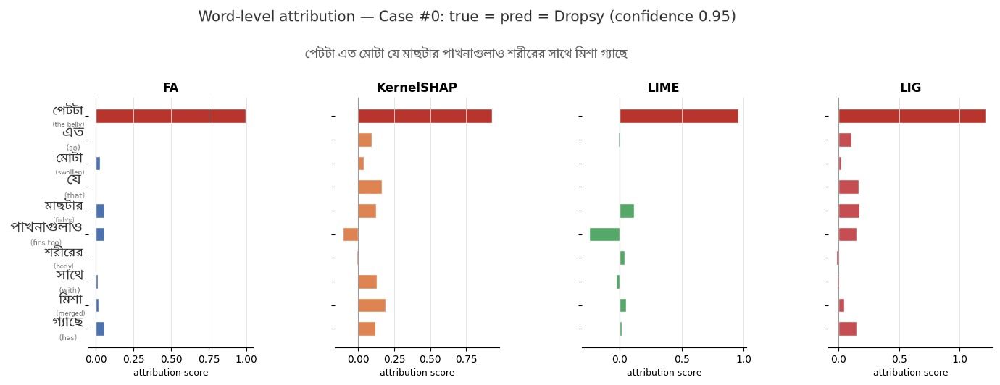

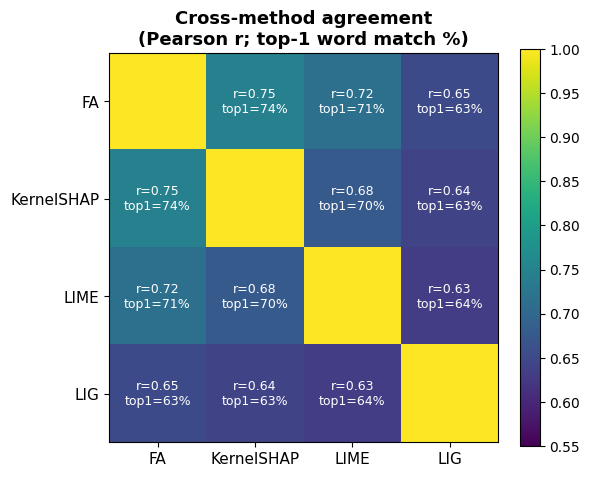

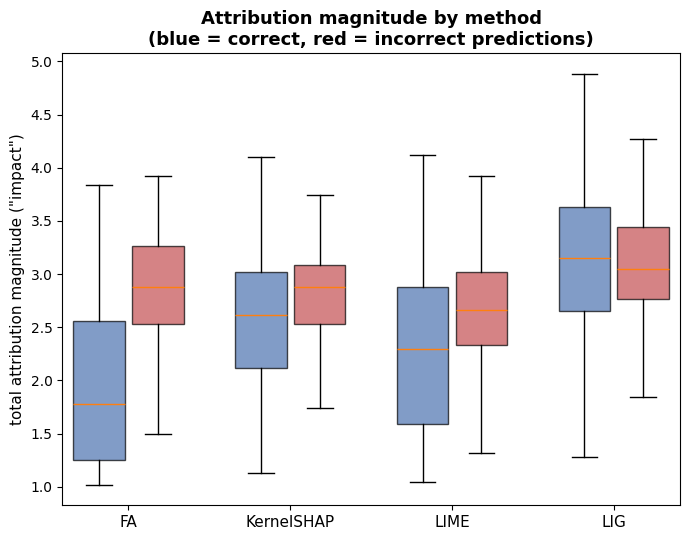

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# 1. Install dependencies (HarfBuzz + FreeType for correct Bengali shaping)
# ============================================================
!pip install -q uharfbuzz freetype-py
!apt-get install -y -qq fonts-noto-core > /dev/null

import os, re, json, subprocess
import numpy as np
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import uharfbuzz as hb
import freetype

# ============================================================
# 2. Locate a Bengali font (avoid "UI" variants -- they lack full conjunct ligatures)
#    Installs fonts-noto-bengali (and falls back to fonts-noto-core / fonts-lohit-beng-bengali)
#    if no suitable font is already present, then searches the filesystem for it.
# ============================================================
def _run(cmd):
    try:
        subprocess.run(
            cmd, shell=True, check=False,
            stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
        )
    except Exception:
        pass


def _fc_list_bengali():
    """Ask fontconfig directly for any font whose family/file mentions Bengali."""
    try:
        _run("fc-cache -f")  # refresh cache in case a package was just installed
        output = subprocess.check_output(
            "fc-list | grep -i bengali",
            shell=True, stderr=subprocess.DEVNULL,
        ).decode()
        lines = [l for l in output.splitlines() if l.strip()]
        candidates = [l.split(":")[0].strip() for l in lines if l.split(":")[0].strip()]
        return [p for p in candidates if os.path.exists(p)]
    except Exception:
        return []


def _find_under_fonts_dir():
    """Fallback: walk common font directories looking for Bengali-named files."""
    search_roots = [
        "/usr/share/fonts",
        "/usr/local/share/fonts",
        os.path.expanduser("~/.fonts"),
        os.path.expanduser("~/.local/share/fonts"),
    ]
    candidates = []
    for root in search_roots:
        if not os.path.isdir(root):
            continue
        try:
            output = subprocess.check_output(
                f'find "{root}" -iname "*bengali*.ttf" -o -iname "*bangla*.ttf"',
                shell=True, stderr=subprocess.DEVNULL,
            ).decode()
            candidates += [p for p in output.splitlines() if p.strip() and os.path.exists(p)]
        except Exception:
            continue
    return candidates


def _pick_best(candidates):
    """Prefer non-UI, 'Regular' weight fonts (UI variants drop conjunct ligatures)."""
    if not candidates:
        return None
    non_ui = [p for p in candidates if "ui" not in os.path.basename(p).lower()]
    pool = non_ui if non_ui else candidates
    regular = [p for p in pool if "regular" in os.path.basename(p).lower()]
    return regular[0] if regular else pool[0]


def find_bengali_font():
    # 1. Check if fontconfig already knows about a Bengali font
    best = _pick_best(_fc_list_bengali())
    if best:
        return best

    # 2. Try installing Bengali-capable fonts. Try the specific package first,
    #    then the broader Noto core bundle, then a Lohit fallback.
    for pkg_cmd in [
        "apt-get update -qq && apt-get install -y -qq fonts-noto-bengali",
        "apt-get update -qq && apt-get install -y -qq fonts-noto-core",
        "apt-get update -qq && apt-get install -y -qq fonts-lohit-beng-bengali",
    ]:
        _run(pkg_cmd)
        best = _pick_best(_fc_list_bengali())
        if best:
            return best

    # 3. Last resort: walk font directories directly in case fontconfig's cache
    #    is stale or the package installed to a nonstandard location.
    best = _pick_best(_find_under_fonts_dir())
    if best:
        return best

    return None


FONT_PATH = find_bengali_font()
if FONT_PATH is None:
    raise RuntimeError(
        "No Bengali font could be found or installed automatically.\n"
        "Try running one of these manually, then re-run this cell:\n"
        "  !apt-get update -qq && apt-get install -y fonts-noto-bengali\n"
        "  !apt-get update -qq && apt-get install -y fonts-noto-core\n"
        "  !apt-get update -qq && apt-get install -y fonts-lohit-beng-bengali\n"
        "Then check with: !fc-list | grep -i bengali"
    )
LATIN_FONT_PATH = fm.findfont(fm.FontProperties(family="DejaVu Sans"))
print("Bengali font:", FONT_PATH)
print("Latin font:", LATIN_FONT_PATH)

# ============================================================
# 3. HarfBuzz + FreeType text shaping engine
# ============================================================
class ShapedFontRenderer:
    def __init__(self, font_path):
        with open(font_path, "rb") as f:
            font_data = f.read()
        blob = hb.Blob(font_data)
        self.hb_face = hb.Face(blob)
        self.hb_font = hb.Font(self.hb_face)
        self.upem = self.hb_face.upem
        self.hb_font.scale = (self.upem, self.upem)
        hb.ot_font_set_funcs(self.hb_font)
        self.ft_face = freetype.Face(font_path)

    def render(self, text, font_size=34, color=(45, 45, 45, 255), script="Beng", language="bn"):
        text = str(text)
        if not text.strip():
            return np.zeros((1, 1, 4), dtype=np.uint8)

        self.ft_face.set_pixel_sizes(0, font_size)
        scale = font_size / self.upem

        buf = hb.Buffer()
        buf.add_str(text)
        buf.guess_segment_properties()
        buf.script = script
        buf.language = language
        buf.direction = "ltr"
        hb.shape(self.hb_font, buf)

        infos = buf.glyph_infos
        positions = buf.glyph_positions

        pen_x, pen_y = 0.0, 0.0
        placements = []
        min_x, min_y, max_x, max_y = 1e9, 1e9, -1e9, -1e9

        for info, pos in zip(infos, positions):
            self.ft_face.load_glyph(info.codepoint, freetype.FT_LOAD_RENDER)
            glyph = self.ft_face.glyph
            bitmap = glyph.bitmap
            left, top = glyph.bitmap_left, glyph.bitmap_top

            if bitmap.width > 0 and bitmap.rows > 0:
                raw = np.array(bitmap.buffer, dtype=np.uint8)
                if bitmap.pitch != bitmap.width:
                    raw = raw.reshape(bitmap.rows, bitmap.pitch)[:, :bitmap.width].copy()
                else:
                    raw = raw.reshape(bitmap.rows, bitmap.width).copy()
            else:
                raw = None

            gx = pen_x + (pos.x_offset * scale) + left
            gy = pen_y - (pos.y_offset * scale) - top

            placements.append((gx, gy, bitmap.width, bitmap.rows, raw))

            if bitmap.width > 0 and bitmap.rows > 0:
                min_x = min(min_x, gx)
                min_y = min(min_y, gy)
                max_x = max(max_x, gx + bitmap.width)
                max_y = max(max_y, gy + bitmap.rows)

            pen_x += pos.x_advance * scale
            pen_y += pos.y_advance * scale

        if min_x > max_x:
            return np.zeros((max(1, font_size), max(1, int(round(pen_x)) + 1), 4), dtype=np.uint8)

        pad = 6
        min_x_r, min_y_r = round(min_x), round(min_y)
        max_x_r, max_y_r = round(max_x), round(max_y)

        canvas_w = (max_x_r - min_x_r) + 2 * pad
        canvas_h = (max_y_r - min_y_r) + 2 * pad
        canvas = np.zeros((canvas_h, canvas_w, 4), dtype=np.uint8)

        for gx, gy, bw, bh, raw in placements:
            if raw is None:
                continue
            ox = round(gx) - min_x_r + pad
            oy = round(gy) - min_y_r + pad

            for row in range(bh):
                yy = oy + row
                if yy < 0 or yy >= canvas_h:
                    continue
                x_start, x_end = max(0, ox), min(canvas_w, ox + bw)
                if x_start >= x_end:
                    continue
                src_start = x_start - ox
                alpha_row = raw[row, src_start:src_start + (x_end - x_start)]
                region = canvas[yy, x_start:x_end]
                mask = alpha_row > 0
                region[mask, 0] = color[0]
                region[mask, 1] = color[1]
                region[mask, 2] = color[2]
                region[mask, 3] = np.maximum(region[mask, 3], alpha_row[mask])

        return canvas

bengali_renderer = ShapedFontRenderer(FONT_PATH)
latin_renderer = ShapedFontRenderer(LATIN_FONT_PATH)

def render_text_image(text, font_size=34, color=(45, 45, 45, 255)):
    return bengali_renderer.render(text, font_size=font_size, color=color, script="Beng", language="bn")

def render_latin_image(text, font_size=20, color=(90, 90, 90, 255)):
    return latin_renderer.render(text, font_size=font_size, color=color, script="Latn", language="en")

BENGALI_RUN_RE = re.compile(r'[\u0980-\u09FF]+|[^\u0980-\u09FF]+')

def render_mixed_text_image(text, font_size=32, color=(45, 45, 45, 255)):
    runs = BENGALI_RUN_RE.findall(text)
    run_images = []
    for run in runs:
        if not run:
            continue
        is_bengali = bool(re.match(r'^[\u0980-\u09FF]+$', run))
        if is_bengali:
            run_images.append(bengali_renderer.render(run, font_size=font_size, color=color, script="Beng", language="bn"))
        else:
            run_images.append(latin_renderer.render(run, font_size=font_size, color=color, script="Latn", language="en"))
    if not run_images:
        return np.zeros((1, 1, 4), dtype=np.uint8)
    total_w = sum(im.shape[1] for im in run_images)
    total_h = max(im.shape[0] for im in run_images)
    combined = np.zeros((total_h, total_w, 4), dtype=np.uint8)
    x_cursor = 0
    for im in run_images:
        h, w = im.shape[0], im.shape[1]
        y_offset = (total_h - h) // 2
        combined[y_offset:y_offset + h, x_cursor:x_cursor + w] = im
        x_cursor += w
    return combined

def stack_vertical(img_top, img_bottom, gap=2):
    """Stack a Bengali-word bitmap over an English-gloss bitmap, centered."""
    w = max(img_top.shape[1], img_bottom.shape[1])
    h = img_top.shape[0] + gap + img_bottom.shape[0]
    canvas = np.zeros((h, w, 4), dtype=np.uint8)
    x1 = (w - img_top.shape[1]) // 2
    canvas[0:img_top.shape[0], x1:x1 + img_top.shape[1]] = img_top
    y2 = img_top.shape[0] + gap
    x2 = (w - img_bottom.shape[1]) // 2
    canvas[y2:y2 + img_bottom.shape[0], x2:x2 + img_bottom.shape[1]] = img_bottom
    return canvas

def add_image_artist(ax, arr, xy, xycoords, box_alignment, zoom=0.5):
    offset_img = OffsetImage(arr, zoom=zoom)
    ab = AnnotationBbox(offset_img, xy, xycoords=xycoords, box_alignment=box_alignment,
                         frameon=False, pad=0.0)
    ax.add_artist(ab)
    return ab

# ============================================================
# 4. Upload the 4 attribution JSON files
# ============================================================
from google.colab import files
uploaded = files.upload()  # select all 4 json files in the dialog

# ============================================================
# 5. Load data and align across methods
# ============================================================
def load(fn):
    with open(fn, encoding='utf-8') as f:
        return json.load(f)

fa    = load('all_fa_wordgroup_scores.json')
kshap = load('all_kernelshap_wordgroup_scores.json')
lig   = load('all_lig_wordgroup_scores.json')
lime  = load('all_lime_native_scores.json')

METHOD_ORDER  = ['FA', 'KernelSHAP', 'LIME', 'LIG']
METHOD_COLORS = {'FA': '#4C72B0', 'KernelSHAP': '#DD8452', 'LIME': '#55A868', 'LIG': '#C44E52'}
methods = {'FA': fa, 'KernelSHAP': kshap, 'LIME': lime, 'LIG': lig}

by_case = {name: {d['case_index']: d for d in data} for name, data in methods.items()}
case_indices = sorted(by_case['FA'].keys())
assert len(case_indices) == 963, f"expected 963 cases, got {len(case_indices)}"
print(f"Loaded {len(case_indices)} cases for each of {len(methods)} methods.")

def top1_word(entry):
    return entry['words'][int(np.argmax(entry['scores']))]

top1 = {name: {ci: top1_word(e) for ci, e in data.items()} for name, data in by_case.items()}

def aligned_vectors(ci, m1, m2):
    e1, e2 = by_case[m1][ci], by_case[m2][ci]
    canonical = e1['text'].split()
    map1 = dict(zip(e1['words'], e1['scores']))
    map2 = dict(zip(e2['words'], e2['scores']))
    v1 = [map1.get(w, 0.0) for w in canonical]
    v2 = [map2.get(w, 0.0) for w in canonical]
    return v1, v2

# ============================================================
# 6. Compute the cross-method agreement matrix (used in Figure 2)
# ============================================================
n = len(METHOD_ORDER)
agree_mat = np.eye(n)
corr_mat  = np.eye(n)

for i, a in enumerate(METHOD_ORDER):
    for j, b in enumerate(METHOD_ORDER):
        if i == j:
            continue
        matches = sum(top1[a][ci] == top1[b][ci] for ci in case_indices)
        agree_mat[i, j] = matches / len(case_indices)
        rs = []
        for ci in case_indices:
            v1, v2 = aligned_vectors(ci, a, b)
            if len(set(v1)) > 1 and len(set(v2)) > 1:
                r, _ = pearsonr(v1, v2)
                if not np.isnan(r):
                    rs.append(r)
        corr_mat[i, j] = np.mean(rs)

print("Top-1 agreement (%):\n", (agree_mat * 100).round(1))
print("Mean Pearson r:\n", corr_mat.round(3))
# Note: top-1 agreement reproduces the manuscript's Section 8.4 numbers exactly.
# Pearson r is very close but not bit-identical for pairs involving LIME, because
# ~40% of cases contain a repeated word and LIME's bow=True mode merges duplicate
# words into a single feature while FA/KernelSHAP/LIG keep them as separate slots.

# ============================================================
# 7. Compute attribution magnitude by correctness (used in Figure 3)
# ============================================================
impact_data = {}
for name in METHOD_ORDER:
    correct = [e['impact'] for e in methods[name] if e['true_label'] == e['pred_label']]
    wrong   = [e['impact'] for e in methods[name] if e['true_label'] != e['pred_label']]
    impact_data[name] = (correct, wrong)
    print(f"{name}: correct mean={np.mean(correct):.3f} (n={len(correct)}), "
          f"incorrect mean={np.mean(wrong):.3f} (n={len(wrong)})")

# ============================================================
# 8. FIGURE 1 -- Qualitative word-attribution example
#    (Bengali words + English gloss rendered via HarfBuzz/FreeType shaping)
# ============================================================
CASE = 0  # the case flagged in Section 8.7: true=pred=Dropsy, confidence 0.950
GLOSS = {
    'পেটটা': 'the belly', 'এত': 'so', 'মোটা': 'swollen', 'যে': 'that',
    'মাছটার': "fish's", 'পাখনাগুলাও': 'fins too', 'শরীরের': 'body',
    'সাথে': 'with', 'মিশা': 'merged', 'গ্যাছে': 'has'
}
canonical_words = by_case['FA'][CASE]['text'].split()
words_display = canonical_words[::-1]  # top-to-bottom = first-to-last word in sentence

ROW_HEIGHT = 0.6  # bar height AND row pitch reference for label sizing (was 0.7)

fig1, axes = plt.subplots(1, 4, figsize=(16, 5))
for k, name in enumerate(METHOD_ORDER):
    ax = axes[k]
    e = by_case[name][CASE]
    wmap = dict(zip(e['words'], e['scores']))
    scores = [wmap.get(w, 0.0) for w in words_display]
    top_idx = int(np.argmax(scores))
    colors = ['#B8352E' if i == top_idx else METHOD_COLORS[name] for i in range(len(scores))]

    ax.barh(range(len(scores)), scores, color=colors, edgecolor="white", height=ROW_HEIGHT)
    ax.set_yticks(range(len(scores)))
    ax.set_yticklabels([])
    ax.axvline(0, color='#999999', linewidth=0.8)
    ax.grid(axis='x', color='#e0e0e0', linewidth=0.6)
    ax.set_xlabel('attribution score', fontsize=9)
    ax.set_title(name, fontsize=12, fontweight='bold')
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    if k == 0:
        # HarfBuzz-shaped word labels (Bengali word over English gloss), left of the bars.
        # zoom is auto-scaled per label so the stacked (Bengali + gloss) image height
        # never exceeds one row's pitch in pixels -- this is what was causing adjacent
        # labels to overlap vertically when a word/gloss pair rendered taller than usual.
        fig1.canvas.draw()  # ensure the axes transform is up to date before measuring
        trans = ax.transData
        y0_px = trans.transform((0, 0))[1]
        y1_px = trans.transform((0, 1))[1]
        row_pitch_px = abs(y1_px - y0_px)  # pixels per 1 data-unit step on the y-axis
        max_label_px = row_pitch_px * 0.82  # leave a small margin so labels don't touch

        for i, w in enumerate(words_display):
            bn_img = render_text_image(w, font_size=26)
            gl_img = render_latin_image(f"({GLOSS.get(w, '')})", font_size=13, color=(120, 120, 120, 255))
            label_img = stack_vertical(bn_img, gl_img, gap=1)

            auto_zoom = min(0.55, max_label_px / label_img.shape[0])

            add_image_artist(
                ax, label_img, xy=(0, i), xycoords=("axes fraction", "data"),
                box_alignment=(1.05, 0.5), zoom=auto_zoom
            )

fig1.subplots_adjust(left=0.12, top=0.80, wspace=0.5)

title_arr = render_mixed_text_image(
    "Word-level attribution — Case #0: true = pred = Dropsy (confidence 0.95)", font_size=26
)
add_image_artist(fig1.axes[0], title_arr, xy=(2.3, 1.28), xycoords=("axes fraction", "axes fraction"),
                  box_alignment=(0.5, 0), zoom=0.55)

sentence_arr = render_text_image(by_case['FA'][CASE]['text'], font_size=22, color=(90, 90, 90, 255))
add_image_artist(fig1.axes[0], sentence_arr, xy=(2.3, 1.14), xycoords=("axes fraction", "axes fraction"),
                  box_alignment=(0.5, 0), zoom=0.55)

fig1.savefig('fig1_qualitative_example.png', dpi=300, bbox_inches='tight')
fig1.savefig('fig1_qualitative_example.pdf', bbox_inches='tight')
plt.show()

# ============================================================
# 9. FIGURE 2 -- Cross-method agreement heatmap
# ============================================================
fig2, ax2 = plt.subplots(figsize=(6, 5.5))
im = ax2.imshow(corr_mat, vmin=0.55, vmax=1.0, cmap='viridis')
ax2.set_xticks(range(n)); ax2.set_xticklabels(METHOD_ORDER, fontsize=11)
ax2.set_yticks(range(n)); ax2.set_yticklabels(METHOD_ORDER, fontsize=11)
for i in range(n):
    for j in range(n):
        if i == j:
            continue
        ax2.text(j, i, f"r={corr_mat[i,j]:.2f}\ntop1={agree_mat[i,j]*100:.0f}%",
                  ha='center', va='center', color='white', fontsize=9)
ax2.set_title('Cross-method agreement\n(Pearson r; top-1 word match %)', fontsize=13, fontweight='bold')
plt.colorbar(im, ax=ax2, fraction=0.046)
fig2.tight_layout()
fig2.savefig('fig2_agreement_heatmap.png', dpi=300, bbox_inches='tight')
fig2.savefig('fig2_agreement_heatmap.pdf', bbox_inches='tight')
plt.show()

# ============================================================
# 10. FIGURE 3 -- Attribution magnitude by method / correctness
# ============================================================
fig3, ax3 = plt.subplots(figsize=(7, 5.5))
positions, data_list, colors_box, xticks, xticklabels = [], [], [], [], []
pos = 0
for name in METHOD_ORDER:
    correct, wrong = impact_data[name]
    data_list += [correct, wrong]
    positions += [pos, pos + 0.8]
    colors_box += ['#4C72B0', '#C44E52']
    xticks.append(pos + 0.4)
    xticklabels.append(name)
    pos += 2.2

bp = ax3.boxplot(data_list, positions=positions, widths=0.7, patch_artist=True, showfliers=False)
for patch, c in zip(bp['boxes'], colors_box):
    patch.set_facecolor(c)
    patch.set_alpha(0.7)
ax3.set_xticks(xticks); ax3.set_xticklabels(xticklabels, fontsize=11)
ax3.set_ylabel('total attribution magnitude ("impact")', fontsize=11)
ax3.set_title('Attribution magnitude by method\n(blue = correct, red = incorrect predictions)',
              fontsize=13, fontweight='bold')
fig3.tight_layout()
fig3.savefig('fig3_magnitude_boxplot.png', dpi=300, bbox_inches='tight')
fig3.savefig('fig3_magnitude_boxplot.pdf', bbox_inches='tight')
plt.show()

# ============================================================
# 11. Download all 3 figures
# ============================================================
for fn in ['fig1_qualitative_example.png', 'fig1_qualitative_example.pdf',
           'fig2_agreement_heatmap.png',   'fig2_agreement_heatmap.pdf',
           'fig3_magnitude_boxplot.png',   'fig3_magnitude_boxplot.pdf']:
    files.download(fn)
# Use the .pdf versions in your LaTeX \includegraphics for crisp vector rendering.

# LIG ibm-research/ia-multilingual-original-script-roberta

In [ ]:
# ============================================================================
# LIG (Layer Integrated Gradients) — attribution only, no plotting
# Runs on the model saved by the training script, over the same test split.
# Adapted for: ibm-research/ia-multilingual-original-script-roberta (AquaDx CV)
# ============================================================================

# --- 1. Install dependencies ---
!pip install -q captum transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from captum.attr import LayerIntegratedGradients

# --- 4. Configuration ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

FOLD            = 1  # Matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/ibm_multilingual_roberta_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 128
RANDOM_SEED = 42

N_STEPS = 50
INTERNAL_BATCH_SIZE = 4

# Target output directories
OUT_DIR_DRIVE = os.path.join(DRIVE_SAVE_DIR, "lig_scores")
OUT_DIR_LOCAL = "/content/lig_scores"
os.makedirs(OUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUT_DIR_LOCAL, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Text cleaning function ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Dataset loader with caching ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

# --- 7. Consistent label mapping from training metadata ---
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

label2id = {name: i for i, name in enumerate(label_names_list)}
id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

df["true_label_idx"] = df["label"].map(label2id)

# Load the exact validation fold saved during cross-validation
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows: {len(test_df)}")
print(test_df["true_label_idx"].value_counts())

# --- 8. Load model and fast tokenizer ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
if not tokenizer.is_fast:
    raise RuntimeError("This script requires a fast tokenizer to map word boundaries.")

model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Captum forward setup and layer target ---
def forward_func(input_ids, attention_mask):
    return model(input_ids=input_ids, attention_mask=attention_mask).logits

# Target entire embedding module to avoid position-index mismatches along the path
if hasattr(model, "roberta"):
    target_embedding_layer = model.roberta.embeddings
else:
    target_embedding_layer = model.get_input_embeddings()

lig = LayerIntegratedGradients(forward_func, target_embedding_layer)

# --- 10. Word-boundary-aware input construction ---
def construct_input_and_baseline(text):
    # Tokenize full text directly to retain BPE leading space markers
    encoded = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    )
    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)

    # Construct baseline by replacing non-special tokens with pad tokens
    ref_input_ids = input_ids.clone()
    special_ids = set(tokenizer.all_special_ids)
    for i in range(input_ids.shape[1]):
        if input_ids[0, i].item() not in special_ids:
            ref_input_ids[0, i] = tokenizer.pad_token_id

    word_ids = encoded.word_ids(batch_index=0)
    return input_ids, ref_input_ids, attention_mask, word_ids

# --- 11. Sum token attributions into word scores ---
def sum_scores_by_word(word_ids, scores, num_words):
    word_scores = np.zeros(num_words, dtype=float)
    for i, wid in enumerate(word_ids):
        if wid is not None and wid < num_words and i < len(scores):
            word_scores[wid] += scores[i]
    return word_scores.tolist()

# --- 12. Per-case attribution ---
def compute_case_attribution(text):
    words = text.split()
    if len(words) == 0:
        return {"pred_idx": 0, "confidence": 0.0, "words": [], "scores": [], "impact": 0.0, "delta": 0.0}

    input_ids, ref_input_ids, attention_mask, word_ids = construct_input_and_baseline(text)

    with torch.no_grad():
        logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
    probs = F.softmax(logits, dim=-1).squeeze(0)
    pred_idx = int(torch.argmax(probs).item())
    confidence = float(probs[pred_idx].item())

    attributions, delta = lig.attribute(
        inputs=input_ids,
        baselines=ref_input_ids,
        additional_forward_args=(attention_mask,),
        target=pred_idx,
        n_steps=N_STEPS,
        internal_batch_size=INTERNAL_BATCH_SIZE,
        return_convergence_delta=True
    )

    # Sum across embedding dimensions without L2 normalization to preserve additivity
    attr_sum = attributions.sum(dim=-1).squeeze(0).detach().cpu().numpy()
    word_scores = sum_scores_by_word(word_ids, attr_sum, len(words))
    impact = float(np.abs(np.array(word_scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": word_scores,
        "impact": impact,
        "delta": float(delta.item())
    }

# --- 13. Run LIG across validation samples ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "Attribution Score"],
                   tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 14. Export records ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "delta": float(r["delta"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

drive_out_path = os.path.join(OUT_DIR_DRIVE, "all_lig_wordgroup_scores.json")
local_out_path = os.path.join(OUT_DIR_LOCAL, "all_lig_wordgroup_scores.json")

with open(drive_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

with open(local_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\nSaved output files:")
print("  Drive:", drive_out_path)
print("  Local:", local_out_path)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 16.4 MB/s eta 0:00:00
Mounted at /content/drive
Downloaded and cached to /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/ibm_multilingual_roberta_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
├─────────┼─────────────────────┤
│ পারে    │           -0.110921 │
├─────────┼─────────────────────┤
│ মাথা    │           -0.076494 │
├─────────┼─────────────────────┤
│ মাছ     │           -0.075171 │
├─────────┼─────────────────────┤
│ কুঁজের    │            0.069373 │
├─────────┼─────────────────────┤
│ মাছগুলার │            0.062282 │
├─────────┼─────────────────────┤
│ ফুলা     │            0.061130 │
├─────────┼─────────────────────┤
│ কাছের   │            0.059632 │
├─────────┼─────────────────────┤
│ কারণে   │           -0.057960 │
├─────────┼─────────────────────┤
│ ঘাড়ের   │            0.026373 │
├─────────┼─────────────────────┤
│ নাড়াইতে │           -0.025187 │
╘═════════╧═════════════════════╛

Case 828 | True: Dropsy | Pred: Dropsy | Conf: 0.9381 | Impact: 3.3076
╒════════╤═════════════════════╕
│ Word   │   Attribution Score │
╞════════╪═════════════════════╡
│ গতি    │           -1.274152 │
├────────┼─────────────────

# FA ibm-research/ia-multilingual-original-script-roberta

In [ ]:
# ============================================================================
# Feature Ablation (Captum, word-level grouping via word_ids) — attribution only
# Runs on the IBM multilingual RoBERTa fold model saved by the training script.
# Adapted for: ibm-research/ia-multilingual-original-script-roberta (AquaDx CV)
# ============================================================================

# --- 1. Install dependencies ---
!pip install -q captum transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from captum.attr import FeatureAblation

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# IBM multilingual RoBERTa, 5-fold CV — set which fold's checkpoint to explain.
FOLD            = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/ibm_multilingual_roberta_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 128   # matches training script's MAX_LENGTH for this model
RANDOM_SEED = 42

# Saved to BOTH Drive (persists after runtime disconnects) and local /content.
OUT_DIR_DRIVE = os.path.join(DRIVE_SAVE_DIR, "fa_scores")
OUT_DIR_LOCAL = "/content/fa_scores"
os.makedirs(OUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUT_DIR_LOCAL, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Load dataset (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

# --- 7. Load label mappings saved during training ---
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

label2id = {name: i for i, name in enumerate(label_names_list)}
id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

# Explicitly map labels using the saved dictionary (prevents alphabetical sorting bugs)
df["true_label_idx"] = df["label"].map(label2id)

# Use the actual validation split saved by the training script
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows: {len(test_df)}")
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and fast tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
if not tokenizer.is_fast:
    raise RuntimeError("This script requires a fast tokenizer for word_ids() mapping.")

model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Captum forward function and FeatureAblation setup ---
def forward_func(input_ids, attention_mask):
    logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
    return F.softmax(logits, dim=-1)

feature_ablation = FeatureAblation(forward_func)

# --- 10. Word-boundary-aware input construction ---
def construct_input_and_word_mask(text, words):
    # Tokenize full raw text directly to retain BPE leading space markers (Ġ)
    encoded = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    )
    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)
    baseline_ids = torch.full_like(input_ids, tokenizer.pad_token_id)

    word_ids = encoded.word_ids(batch_index=0)
    feature_mask = torch.zeros_like(input_ids)
    for i, wid in enumerate(word_ids):
        if wid is not None and wid < len(words):
            feature_mask[0, i] = wid + 1  # Group 0 is reserved for special tokens

    return input_ids, baseline_ids, attention_mask, feature_mask, word_ids

# --- 11. Per-case attribution computation ---
def compute_case_attribution(text):
    words = text.split()
    if len(words) == 0:
        return {"pred_idx": 0, "confidence": 0.0, "words": [], "scores": [], "impact": 0.0}

    input_ids, baseline_ids, attention_mask, feature_mask, word_ids = construct_input_and_word_mask(text, words)

    with torch.no_grad():
        probs = forward_func(input_ids, attention_mask).squeeze(0)
    pred_idx = int(torch.argmax(probs).item())
    confidence = float(probs[pred_idx].item())

    attributions = feature_ablation.attribute(
        inputs=input_ids,
        baselines=baseline_ids,
        additional_forward_args=(attention_mask,),
        feature_mask=feature_mask,
        target=pred_idx
    )

    attr_scores = attributions.squeeze(0).detach().cpu().numpy().astype(float)

    # Collapse token-level attribution scores down to one score per originating word
    per_word_scores = np.zeros(len(words), dtype=float)
    seen_word = np.zeros(len(words), dtype=bool)
    for i, wid in enumerate(word_ids):
        if wid is not None and wid < len(words) and not seen_word[wid]:
            per_word_scores[wid] = attr_scores[i]
            seen_word[wid] = True

    norm = np.linalg.norm(per_word_scores) + 1e-12
    scores = (per_word_scores / norm).tolist()
    impact = float(np.abs(np.array(scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": scores,
        "impact": impact
    }

# --- 12. Run Feature Ablation over the full validation set ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "Ablation Score"],
                   tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 13. Export all scores to JSON (saved to BOTH Drive and local /content) ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

drive_out_path = os.path.join(OUT_DIR_DRIVE, "all_fa_wordgroup_scores.json")
local_out_path = os.path.join(OUT_DIR_LOCAL, "all_fa_wordgroup_scores.json")

with open(drive_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

with open(local_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\nFeature Ablation attribution complete. Scores saved to:")
print("  Drive:", drive_out_path)
print("  Local:", local_out_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using cached dataset at /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/ibm_multilingual_roberta_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]


Case 0 | True: Dropsy | Pred: Dropsy | Conf: 0.9274 | Impact: 1.7541
╒═══════════╤══════════════════╕
│ Word      │   Ablation Score │
╞═══════════╪══════════════════╡
│ মোটা      │         0.684804 │
├───────────┼──────────────────┤
│ এত        │         0.616955 │
├───────────┼──────────────────┤
│ পেটটা     │         0.383647 │
├───────────┼──────────────────┤
│ যে        │         0.056364 │
├───────────┼──────────────────┤
│ মাছটার    │         0.006355 │
├───────────┼──────────────────┤
│ গ্যাছে      │         0.001858 │
├───────────┼──────────────────┤
│ সাথে      │         0.001480 │
├───────────┼──────────────────┤
│ পাখনাগুলাও │        -0.001084 │
├───────────┼──────────────────┤
│ শরীরের    │        -0.001007 │
├───────────┼──────────────────┤
│ মিশা      │        -0.000566 │
╘═══════════╧══════════════════╛

Case 1 | True: Argulosis | Pred: Argulosis | Conf: 0.9416 | Impact: 2.0020
╒═════════╤══════════════════╕
│ Word    │   Ablation Score │
╞═════════╪══════════════════╡

# Native LIME ibm-research/ia-multilingual-original-script-roberta

In [ ]:
# ==============================================================================
# LIME (original marcotcr/lime library) — attribution only, no plotting
# Runs on the IBM multilingual RoBERTa fold model saved by the training script.
# Adapted for: ibm-research/ia-multilingual-original-script-roberta (AquaDx CV)
# ==============================================================================

# --- 1. Install dependencies ---
!pip install -q lime transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from lime.lime_text import LimeTextExplainer

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# IBM multilingual RoBERTa, 5-fold CV — set which fold's checkpoint to explain.
FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/ibm_multilingual_roberta_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 128   # matches training script's MAX_LENGTH for this model
RANDOM_SEED = 42

LIME_N_SAMPLES = 200      # perturbed samples per sentence for the LIME surrogate fit
LIME_BATCH_SIZE = 16      # batched forward passes when scoring perturbations

# Saved to BOTH Drive (persists after runtime disconnects) and local /content.
OUT_DIR_DRIVE = os.path.join(DRIVE_SAVE_DIR, "lime_native_scores")
OUT_DIR_LOCAL = "/content/lime_native_scores"
os.makedirs(OUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUT_DIR_LOCAL, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Load dataset (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, saved by the training script
# (np.save(... "val_indices.npy" ...)), so LIME runs on rows this fold's model
# never trained on — same holdout the LIG/FA runs used.
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows:", len(test_df))

# --- 7. Load label mappings saved during training (JSON list, saved once at top level) ---
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Batched prediction function required by lime.lime_text (text -> class probabilities) ---
def predict_proba(texts):
    """
    texts: list of raw strings (perturbed versions of the original sentence, as produced
    internally by LimeTextExplainer). Returns an (n_samples, num_labels) numpy array of
    softmax probabilities, batched for efficiency since LIME calls this with many perturbations.
    """
    all_probs = []
    for start in range(0, len(texts), LIME_BATCH_SIZE):
        batch = texts[start:start + LIME_BATCH_SIZE]
        encoded = tokenizer(
            batch, return_tensors="pt", truncation=True,
            max_length=MAX_LENGTH, padding=True
        )
        input_ids = encoded["input_ids"].to(device)
        attention_mask = encoded["attention_mask"].to(device)
        with torch.no_grad():
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            probs = F.softmax(logits, dim=-1)
        all_probs.append(probs.detach().cpu().numpy())
    return np.concatenate(all_probs, axis=0)

# --- 10. LimeTextExplainer setup — splits on whitespace, keeping Bengali words intact ---
lime_explainer = LimeTextExplainer(
    class_names=label_names_list,
    split_expression=r'\s+',   # split purely on whitespace; \w already covers Bengali script
    bow=True
)

# --- 11. Per-case attribution computation (native lime library, word-level, no subword merging needed) ---
def compute_case_attribution(text):
    words_in_text = text.split()
    num_words = max(len(words_in_text), 1)

    with torch.no_grad():
        probs = predict_proba([text])[0]
    pred_idx = int(np.argmax(probs))
    confidence = float(probs[pred_idx])

    explanation = lime_explainer.explain_instance(
        text,
        predict_proba,
        labels=[pred_idx],
        num_features=num_words,     # request a score for every word in the sentence
        num_samples=LIME_N_SAMPLES
    )

    word_score_pairs = explanation.as_list(label=pred_idx)
    words = [w for w, s in word_score_pairs]
    scores_raw = np.array([s for w, s in word_score_pairs], dtype=float)

    norm = np.linalg.norm(scores_raw) + 1e-12
    scores = (scores_raw / norm).tolist()

    impact = float(np.abs(np.array(scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": scores,
        "impact": impact
    }

# --- 12. Run LIME over the full validation set and print all scores as tables ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "LIME Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 13. Export all scores to JSON (saved to BOTH Drive and local /content) ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

drive_out_path = os.path.join(OUT_DIR_DRIVE, "all_lime_native_scores.json")
local_out_path = os.path.join(OUT_DIR_LOCAL, "all_lime_native_scores.json")

with open(drive_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

with open(local_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\n✅ LIME (native library) attribution scoring complete. Scores saved to:")
print("   Drive:", drive_out_path)
print("   Local:", local_out_path)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 17.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Mounted at /content/drive
Downloaded and cached to /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/ibm_multilingual_roberta_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:02<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
│ জানি    │    -0.037826 │
├─────────┼──────────────┤
│ মাছগুলা  │    -0.018172 │
├─────────┼──────────────┤
│ খায়     │    -0.011649 │
├─────────┼──────────────┤
│ কেমন    │    -0.005553 │
├─────────┼──────────────┤
│ পাতলা   │    -0.003485 │
╘═════════╧══════════════╛

Case 823 | True: Epizootic Ulcerative Syndrome | Pred: Streptococcosis | Conf: 0.7931 | Impact: 2.6385
╒═════════╤══════════════╕
│ Word    │   LIME Score │
╞═════════╪══════════════╡
│ হান্দাইয়া │     0.626172 │
├─────────┼──────────────┤
│ রোগে    │     0.532531 │
├─────────┼──────────────┤
│ মরা     │     0.318115 │
├─────────┼──────────────┤
│ চোখগুলাও │     0.306121 │
├─────────┼──────────────┤
│ জানি    │     0.224223 │
├─────────┼──────────────┤
│ যায়     │     0.194859 │
├─────────┼──────────────┤
│ দিকে    │     0.112902 │
├─────────┼──────────────┤
│ ভিতর    │     0.111956 │
├─────────┼──────────────┤
│ কেমন    │     0.088444 │
├─────────┼──────────────┤
│ এই

# kernelSHAP ibm-research/ia-multilingual-original-script-roberta

In [ ]:
# ==============================================================================
# KernelSHAP (Captum) — FIXED VIA OFFSET MAPPING FOR IBM-mRoBERTa
# ==============================================================================

!pip install -q captum transformers torch pandas scikit-learn

from google.colab import drive
drive.mount('/content/drive')

import os, re, json, time, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.std import tqdm
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from captum.attr import KernelShap

# --- Configuration ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"
FOLD            = 1
CV_ROOT_DIR     = "/content/drive/MyDrive/ibm_multilingual_roberta_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH            = 128
RANDOM_SEED           = 42
KERNELSHAP_N_SAMPLES  = 400
KERNELSHAP_BATCH_SIZE = 64

OUT_DIR_DRIVE = os.path.join(DRIVE_SAVE_DIR, "kernelshap_scores")
OUT_DIR_LOCAL = "/content/kernelshap_scores"
os.makedirs(OUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUT_DIR_LOCAL, exist_ok=True)

# --- Text Cleaning ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- Dataset Loading ---
if os.path.exists(LOCAL_CSV_CACHE):
    df = pd.read_csv(LOCAL_CSV_CACHE)
else:
    req = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=15) as resp:
        data = resp.read()
    with open(LOCAL_CSV_CACHE, "wb") as f:
        f.write(data)
    df = pd.read_csv(LOCAL_CSV_CACHE)

df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

# --- Label Setup ---
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

label2id = {name: i for i, name in enumerate(label_names_list)}
id2label = {i: name for i, name in enumerate(label_names_list)}
df["true_label_idx"] = df["label"].map(label2id)

val_idx = np.load(os.path.join(DRIVE_SAVE_DIR, "val_indices.npy"))
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"[INFO] Loaded {len(test_df)} cases for fold {FOLD}")

# --- Model & Tokenizer ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=len(id2label))
model.to(device).eval()

# --- Forward Function ---
def forward_func(input_ids, attention_mask):
    with torch.inference_mode():
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            return F.softmax(logits.float(), dim=-1)

kernel_shap = KernelShap(forward_func)

# --- Offset Mapping Construction ---
def construct_input_and_word_mask(text, words):
    # 1. Compute exact character spans for whitespace-separated words
    spans = []
    cursor = 0
    for w in words:
        start = text.find(w, cursor)
        end = start + len(w)
        spans.append((start, end))
        cursor = end

    # 2. Tokenize with character offset tracking
    encoded = tokenizer(
        text,
        return_tensors="pt",
        return_offsets_mapping=True,
        truncation=True,
        max_length=MAX_LENGTH
    )
    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)
    offsets = encoded["offset_mapping"][0].cpu().numpy()

    mask_id = tokenizer.mask_token_id if tokenizer.mask_token_id is not None else tokenizer.pad_token_id
    baseline_ids = torch.full_like(input_ids, mask_id)
    feature_mask = torch.zeros_like(input_ids)
    token_to_word = []

    # 3. Map tokens to whitespace words using character offsets
    for i, (start_ch, end_ch) in enumerate(offsets):
        if start_ch == end_ch:
            # Special token (<s>, </s>): locked baseline, group 0
            baseline_ids[0, i] = input_ids[0, i]
            feature_mask[0, i] = 0
            token_to_word.append(None)
        else:
            matched_wid = None
            for wid, (w_s, w_e) in enumerate(spans):
                if not (end_ch <= w_s or start_ch >= w_e):
                    matched_wid = wid
                    break

            if matched_wid is not None and matched_wid < len(words):
                feature_mask[0, i] = matched_wid + 1
                token_to_word.append(matched_wid)
            else:
                baseline_ids[0, i] = input_ids[0, i]
                feature_mask[0, i] = 0
                token_to_word.append(None)

    return input_ids, baseline_ids, attention_mask, feature_mask, token_to_word

# --- Attribution Computation ---
def compute_case_attribution(text):
    words = text.split()
    if len(words) == 0:
        return {"pred_idx": 0, "confidence": 0.0, "words": [], "scores": [], "impact": 0.0}

    input_ids, baseline_ids, attention_mask, feature_mask, token_to_word = construct_input_and_word_mask(text, words)

    probs = forward_func(input_ids, attention_mask).squeeze(0)
    pred_idx = int(torch.argmax(probs).item())
    confidence = float(probs[pred_idx].item())

    # If no word features exist, return zero attribution
    if feature_mask.max().item() == 0:
        return {"pred_idx": pred_idx, "confidence": confidence, "words": words, "scores": [0.0]*len(words), "impact": 0.0}

    attributions = kernel_shap.attribute(
        inputs=input_ids,
        baselines=baseline_ids,
        additional_forward_args=(attention_mask,),
        feature_mask=feature_mask,
        target=pred_idx,
        n_samples=KERNELSHAP_N_SAMPLES,
        perturbations_per_eval=KERNELSHAP_BATCH_SIZE,
        show_progress=False
    )

    attr_scores = attributions.squeeze(0).detach().cpu().numpy().astype(float)

    # All subword tokens in a group share identical attribution
    per_word_scores = np.zeros(len(words), dtype=float)
    for i, wid in enumerate(token_to_word):
        if wid is not None and wid < len(words):
            per_word_scores[wid] = attr_scores[i]

    norm = np.linalg.norm(per_word_scores) + 1e-12
    scores = (per_word_scores / norm).tolist()
    impact = float(np.abs(np.array(scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": scores,
        "impact": impact
    }

# --- Execution ---
all_results = []
pbar = tqdm(test_df.iterrows(), total=len(test_df), desc="KernelSHAP (Offset Fixed)")

for idx, row in pbar:
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)
    pbar.set_postfix({"Idx": idx, "Pred": case["pred_label"][:8], "Conf": f"{case['confidence']:.2f}"})

# --- Export ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

drive_out_path = os.path.join(OUT_DIR_DRIVE, "all_kernelshap_wordgroup_scores.json")
local_out_path = os.path.join(OUT_DIR_LOCAL, "all_kernelshap_wordgroup_scores.json")

with open(drive_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

with open(local_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print(f"\n[SUCCESS] Corrected scores saved to:\n{drive_out_path}")

Mounted at /content/drive
[INFO] Loaded 963 cases for fold 1


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

KernelSHAP (Offset Fixed): 100%|██████████| 963/963 [07:45<00:00,  2.07it/s, Idx=962, Pred=Streptoc, Conf=0.95]



[SUCCESS] Corrected scores saved to:
/content/drive/MyDrive/ibm_multilingual_roberta_aquadx_cv/fold_1/kernelshap_scores/all_kernelshap_wordgroup_scores.json


# LIG Kowsher/bangla-bert

In [ ]:
# ============================================================================
# LIG (Layer Integrated Gradients) — attribution only, no plotting
# Runs on the model saved by the training script, over the same test split.
# Adapted for: Kowsher/bangla-bert (AquaDx CV)
# ============================================================================

# --- 1. Install dependencies ---
!pip install -q captum transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from captum.attr import LayerIntegratedGradients

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# Kowsher/bangla-bert, 5-fold CV — set which fold's checkpoint to explain.
FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/kowsher_bangla_bert_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 128   # NOTE: training script truncates but doesn't name this constant —
                     # kept consistent with the multilingual-RoBERTa LIG script's value.
                     # Adjust if your Bangla-BERT training run used a different length.
RANDOM_SEED = 42

N_STEPS = 50
INTERNAL_BATCH_SIZE = 4

# Saved to BOTH Drive (persists after runtime disconnects) and local /content.
OUT_DIR_DRIVE = os.path.join(DRIVE_SAVE_DIR, "lig_scores")
OUT_DIR_LOCAL = "/content/lig_scores"
os.makedirs(OUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUT_DIR_LOCAL, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Rebuild the exact same test split used in training (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, saved by the training script
# (np.save(... "val_indices.npy" ...) inside fold_{fold+1}/), rather than
# reconstructing a split — this guarantees LIG runs on rows this fold's
# model never trained on.
#
# NOTE: the training script builds val_idx from StratifiedKFold.split() over
# the full (unshuffled) dataframe — same indexing convention as the other
# CV scripts' val_indices.npy, so this reload logic is unchanged.
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows:", len(test_df))

# --- 7. Load label mappings saved during training (JSON list, saved once at CV_ROOT_DIR) ---
# Training script saves label_names.json at DRIVE_SAVE_DIR (its root),
# which corresponds to CV_ROOT_DIR here — NOT inside the fold_{FOLD} subfolder.
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
if not tokenizer.is_fast:
    raise RuntimeError(
        "This script requires a fast tokenizer (for word_ids() word-boundary mapping). "
        "The tokenizer loaded from DRIVE_SAVE_DIR is not a fast tokenizer. "
        "Kowsher/bangla-bert should provide a fast (Rust-backed) WordPiece tokenizer, "
        "but this checks it explicitly as a safety guard."
    )
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Captum forward function and LayerIntegratedGradients setup ---
def forward_func(input_ids, attention_mask):
    return model(input_ids=input_ids, attention_mask=attention_mask).logits

embedding_layer = model.get_input_embeddings()
lig = LayerIntegratedGradients(forward_func, embedding_layer)

# --- 10. Word-boundary-aware input construction ---
def construct_input_and_baseline(words):
    encoded = tokenizer(
        words,
        is_split_into_words=True,   # tokenizer pre-tokenizes on our exact word boundaries
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length"
    )
    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)

    ref_input_ids = input_ids.clone()
    special_ids = {tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id}
    for i in range(input_ids.shape[1]):
        if input_ids[0, i].item() not in special_ids:
            ref_input_ids[0, i] = tokenizer.pad_token_id

    word_ids = encoded.word_ids(batch_index=0)  # word_ids[i] = index into `words`, or None for specials

    return input_ids, ref_input_ids, attention_mask, word_ids

# --- 11. Sum per-token LIG attributions into one score per word (additive, per completeness axiom) ---
def sum_scores_by_word(word_ids, scores, num_words):
    word_scores = np.zeros(num_words, dtype=float)
    for i, wid in enumerate(word_ids):
        if wid is not None and i < len(scores):
            word_scores[wid] += scores[i]
    return word_scores.tolist()

# --- 12. Per-case attribution computation ---
def compute_case_attribution(text):
    words = text.split()
    if len(words) == 0:
        return {"pred_idx": 0, "confidence": 0.0, "words": [], "scores": [], "impact": 0.0, "delta": 0.0}

    input_ids, ref_input_ids, attention_mask, word_ids = construct_input_and_baseline(words)

    with torch.no_grad():
        logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
    probs = F.softmax(logits, dim=-1).squeeze(0)
    pred_idx = int(torch.argmax(probs).item())
    confidence = float(probs[pred_idx].item())

    attributions, delta = lig.attribute(
        inputs=input_ids,
        baselines=ref_input_ids,
        additional_forward_args=(attention_mask,),
        target=pred_idx,
        n_steps=N_STEPS,
        internal_batch_size=INTERNAL_BATCH_SIZE,
        return_convergence_delta=True
    )

    attr_sum = attributions.sum(dim=-1).squeeze(0)
    attr_norm_tokens = attr_sum / (torch.norm(attr_sum) + 1e-12)
    attr_norm_tokens = attr_norm_tokens.detach().cpu().numpy()

    # Sum token-level attributions into word-level scores using the SAME word_ids
    # mapping used for tokenization — no separate reconstruction/merging step.
    word_scores = sum_scores_by_word(word_ids, attr_norm_tokens.tolist(), len(words))

    impact = float(np.abs(np.array(word_scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": word_scores,
        "impact": impact,
        "delta": float(delta.item())
    }

# --- 13. Run LIG over the full test set and print all scores as tables ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "Attribution Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 14. Export all scores to JSON (saved to BOTH Drive and local /content) ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "delta": float(r["delta"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

drive_out_path = os.path.join(OUT_DIR_DRIVE, "all_lig_wordgroup_scores.json")
local_out_path = os.path.join(OUT_DIR_LOCAL, "all_lig_wordgroup_scores.json")

with open(drive_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

with open(local_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\n✅ LIG attribution complete. Scores saved to:")
print("   Drive:", drive_out_path)
print("   Local:", local_out_path)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 8.9 MB/s eta 0:00:00
Mounted at /content/drive
Downloaded and cached to /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/kowsher_bangla_bert_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:01<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
├─────────┼─────────────────────┤
│ ঘাড়ের   │            0.099182 │
├─────────┼─────────────────────┤
│ নাড়াইতে │            0.098054 │
├─────────┼─────────────────────┤
│ কারণে   │            0.096154 │
├─────────┼─────────────────────┤
│ কাছের   │            0.086169 │
├─────────┼─────────────────────┤
│ ফুলা     │           -0.064109 │
├─────────┼─────────────────────┤
│ মতো     │            0.063254 │
├─────────┼─────────────────────┤
│ লাগে    │            0.054746 │
├─────────┼─────────────────────┤
│ পারে    │            0.028141 │
├─────────┼─────────────────────┤
│ দেইখা   │            0.017897 │
├─────────┼─────────────────────┤
│ অংশটা   │            0.002307 │
╘═════════╧═════════════════════╛

Case 828 | True: Dropsy | Pred: Dropsy | Conf: 0.9397 | Impact: 2.4019
╒════════╤═════════════════════╕
│ Word   │   Attribution Score │
╞════════╪═════════════════════╡
│ আঁশ     │            0.781956 │
├────────┼───────────────────

# FA Kowsher/bangla-bert

In [ ]:
# ============================================================================
# Feature Ablation (Captum, word-level grouping via word_ids) — attribution only
# Runs on the Kowsher/bangla-bert fold model saved by the training script.
# Adapted for: Kowsher/bangla-bert (AquaDx CV)
# ============================================================================

# --- 1. Install dependencies ---
!pip install -q captum transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from captum.attr import FeatureAblation

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# Kowsher/bangla-bert, 5-fold CV — set which fold's checkpoint to explain.
FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/kowsher_bangla_bert_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 128   # NOTE: training script truncates but doesn't name this constant —
                     # kept consistent with the LIG script's value for this model.
                     # Adjust if your Bangla-BERT training run used a different length.
RANDOM_SEED = 42

# Saved to BOTH Drive (persists after runtime disconnects) and local /content.
OUT_DIR_DRIVE = os.path.join(DRIVE_SAVE_DIR, "fa_scores")
OUT_DIR_LOCAL = "/content/fa_scores"
os.makedirs(OUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUT_DIR_LOCAL, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Load dataset (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, saved by the training script
# (np.save(... "val_indices.npy" ...) inside fold_{fold+1}/), so FA runs on
# rows this fold's model never trained on — same holdout the LIG run used.
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows:", len(test_df))

# --- 7. Load label mappings saved during training (JSON list, saved once at CV_ROOT_DIR) ---
# Training script saves label_names.json at DRIVE_SAVE_DIR (its root),
# which corresponds to CV_ROOT_DIR here — NOT inside the fold_{FOLD} subfolder.
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
if not tokenizer.is_fast:
    raise RuntimeError(
        "This script requires a fast tokenizer (for word_ids() word-boundary mapping). "
        "The tokenizer loaded from DRIVE_SAVE_DIR is not a fast tokenizer. "
        "Kowsher/bangla-bert should provide a fast (Rust-backed) WordPiece tokenizer, "
        "but this checks it explicitly as a safety guard."
    )
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Captum forward function and FeatureAblation setup ---
def forward_func(input_ids, attention_mask):
    logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
    return F.softmax(logits, dim=-1)

feature_ablation = FeatureAblation(forward_func)

# --- 10. Word-boundary-aware input construction: group subword tokens by originating word ---
def construct_input_and_word_mask(words):
    encoded = tokenizer(
        words,
        is_split_into_words=True,   # tokenizer pre-tokenizes on our exact word boundaries
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length"
    )
    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)
    baseline_ids = torch.full_like(input_ids, tokenizer.pad_token_id)

    # word_ids()[i] = index into `words` that token i came from, or None for [CLS]/[SEP]/[PAD]
    word_ids = encoded.word_ids(batch_index=0)

    feature_mask = torch.zeros_like(input_ids)
    for i, wid in enumerate(word_ids):
        if wid is not None:
            feature_mask[0, i] = wid + 1  # +1 so group 0 is reserved for special/padding tokens

    return input_ids, baseline_ids, attention_mask, feature_mask

# --- 11. Per-case attribution computation (Captum FeatureAblation, grouped at word level) ---
def compute_case_attribution(text):
    words = text.split()
    if len(words) == 0:
        return {"pred_idx": 0, "confidence": 0.0, "words": [], "scores": [], "impact": 0.0}

    input_ids, baseline_ids, attention_mask, feature_mask = construct_input_and_word_mask(words)

    with torch.no_grad():
        probs = forward_func(input_ids, attention_mask).squeeze(0)
    pred_idx = int(torch.argmax(probs).item())
    confidence = float(probs[pred_idx].item())

    attributions = feature_ablation.attribute(
        inputs=input_ids,
        baselines=baseline_ids,
        additional_forward_args=(attention_mask,),
        feature_mask=feature_mask,
        target=pred_idx
    )

    attr_scores = attributions.squeeze(0).detach().cpu().numpy().astype(float)

    # Collapse token-level attribution scores down to one score per word group
    word_ids = tokenizer(
        words, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH
    ).word_ids(batch_index=0)

    per_word_scores = np.zeros(len(words), dtype=float)
    seen_word = np.zeros(len(words), dtype=bool)
    for i, wid in enumerate(word_ids):
        if wid is not None and i < len(attr_scores) and not seen_word[wid]:
            # All tokens sharing a group carry the identical ablation score
            # (the whole word was ablated together), so take it once per word.
            per_word_scores[wid] = attr_scores[i]
            seen_word[wid] = True

    norm = np.linalg.norm(per_word_scores) + 1e-12
    scores = (per_word_scores / norm).tolist()

    impact = float(np.abs(np.array(scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": scores,
        "impact": impact
    }

# --- 12. Run Feature Ablation over the full validation set and print all scores as tables ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "Ablation Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 13. Export all scores to JSON (saved to BOTH Drive and local /content) ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

drive_out_path = os.path.join(OUT_DIR_DRIVE, "all_fa_wordgroup_scores.json")
local_out_path = os.path.join(OUT_DIR_LOCAL, "all_fa_wordgroup_scores.json")

with open(drive_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

with open(local_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\n✅ Feature Ablation attribution complete. Scores saved to:")
print("   Drive:", drive_out_path)
print("   Local:", local_out_path)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 13.0 MB/s eta 0:00:00
Mounted at /content/drive
Downloaded and cached to /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/kowsher_bangla_bert_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
├─────────┼──────────────────┤
│ কাছের   │        -0.034861 │
├─────────┼──────────────────┤
│ এই      │        -0.034671 │
├─────────┼──────────────────┤
│ মাছ     │        -0.030212 │
├─────────┼──────────────────┤
│ কুঁজের    │        -0.024028 │
├─────────┼──────────────────┤
│ মতো     │         0.023527 │
├─────────┼──────────────────┤
│ ঘাড়ের   │        -0.020495 │
├─────────┼──────────────────┤
│ কারণে   │        -0.018835 │
├─────────┼──────────────────┤
│ লাগে    │         0.016004 │
├─────────┼──────────────────┤
│ মাথা    │        -0.012763 │
├─────────┼──────────────────┤
│ নাড়াইতে │        -0.007397 │
╘═════════╧══════════════════╛

Case 828 | True: Dropsy | Pred: Dropsy | Conf: 0.9397 | Impact: 3.0293
╒════════╤══════════════════╕
│ Word   │   Ablation Score │
╞════════╪══════════════════╡
│ পেট    │         0.526860 │
├────────┼──────────────────┤
│ খাড়া   │         0.492876 │
├────────┼──────────────────┤
│ আর     │    

# Native LIME Kowsher/bangla-bert

In [ ]:
# ==============================================================================
# LIME (original marcotcr/lime library) — attribution only, no plotting
# Runs on the Kowsher/bangla-bert fold model saved by the training script.
# Adapted for: Kowsher/bangla-bert (AquaDx CV)
# ==============================================================================

# --- 1. Install dependencies ---
!pip install -q lime transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from lime.lime_text import LimeTextExplainer

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# Kowsher/bangla-bert, 5-fold CV — set which fold's checkpoint to explain.
FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/kowsher_bangla_bert_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 128   # NOTE: training script truncates but doesn't name this constant —
                     # kept consistent with the LIG/FA scripts' value for this model.
                     # Adjust if your Bangla-BERT training run used a different length.
RANDOM_SEED = 42

LIME_N_SAMPLES = 200      # perturbed samples per sentence for the LIME surrogate fit
LIME_BATCH_SIZE = 16      # batched forward passes when scoring perturbations

# Saved to BOTH Drive (persists after runtime disconnects) and local /content.
OUT_DIR_DRIVE = os.path.join(DRIVE_SAVE_DIR, "lime_native_scores")
OUT_DIR_LOCAL = "/content/lime_native_scores"
os.makedirs(OUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUT_DIR_LOCAL, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Load dataset (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, saved by the training script
# (np.save(... "val_indices.npy" ...) inside fold_{fold+1}/), so LIME runs on
# rows this fold's model never trained on — same holdout the LIG/FA runs used.
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows:", len(test_df))

# --- 7. Load label mappings saved during training (JSON list, saved once at CV_ROOT_DIR) ---
# Training script saves label_names.json at DRIVE_SAVE_DIR (its root),
# which corresponds to CV_ROOT_DIR here — NOT inside the fold_{FOLD} subfolder.
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Batched prediction function required by lime.lime_text (text -> class probabilities) ---
def predict_proba(texts):
    """
    texts: list of raw strings (perturbed versions of the original sentence, as produced
    internally by LimeTextExplainer). Returns an (n_samples, num_labels) numpy array of
    softmax probabilities, batched for efficiency since LIME calls this with many perturbations.
    """
    all_probs = []
    for start in range(0, len(texts), LIME_BATCH_SIZE):
        batch = texts[start:start + LIME_BATCH_SIZE]
        encoded = tokenizer(
            batch, return_tensors="pt", truncation=True,
            max_length=MAX_LENGTH, padding=True
        )
        input_ids = encoded["input_ids"].to(device)
        attention_mask = encoded["attention_mask"].to(device)
        with torch.no_grad():
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            probs = F.softmax(logits, dim=-1)
        all_probs.append(probs.detach().cpu().numpy())
    return np.concatenate(all_probs, axis=0)

# --- 10. LimeTextExplainer setup — splits on whitespace, keeping Bengali words intact ---
lime_explainer = LimeTextExplainer(
    class_names=label_names_list,
    split_expression=r'\s+',   # split purely on whitespace; \w already covers Bengali script
    bow=True
)

# --- 11. Per-case attribution computation (native lime library, word-level, no subword merging needed) ---
def compute_case_attribution(text):
    words_in_text = text.split()
    num_words = max(len(words_in_text), 1)

    with torch.no_grad():
        probs = predict_proba([text])[0]
    pred_idx = int(np.argmax(probs))
    confidence = float(probs[pred_idx])

    explanation = lime_explainer.explain_instance(
        text,
        predict_proba,
        labels=[pred_idx],
        num_features=num_words,     # request a score for every word in the sentence
        num_samples=LIME_N_SAMPLES
    )

    word_score_pairs = explanation.as_list(label=pred_idx)
    words = [w for w, s in word_score_pairs]
    scores_raw = np.array([s for w, s in word_score_pairs], dtype=float)

    norm = np.linalg.norm(scores_raw) + 1e-12
    scores = (scores_raw / norm).tolist()

    impact = float(np.abs(np.array(scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": scores,
        "impact": impact
    }

# --- 12. Run LIME over the full validation set and print all scores as tables ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "LIME Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 13. Export all scores to JSON (saved to BOTH Drive and local /content) ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

drive_out_path = os.path.join(OUT_DIR_DRIVE, "all_lime_native_scores.json")
local_out_path = os.path.join(OUT_DIR_LOCAL, "all_lime_native_scores.json")

with open(drive_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

with open(local_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\n✅ LIME (native library) attribution scoring complete. Scores saved to:")
print("   Drive:", drive_out_path)
print("   Local:", local_out_path)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 19.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using cached dataset at /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/kowsher_bangla_bert_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
│ পাতলা   │     0.068938 │
├─────────┼──────────────┤
│ উপ্রে     │    -0.067941 │
├─────────┼──────────────┤
│ পানির   │    -0.055871 │
├─────────┼──────────────┤
│ খাবি    │     0.045115 │
├─────────┼──────────────┤
│ হইয়া    │     0.009711 │
╘═════════╧══════════════╛

Case 823 | True: Epizootic Ulcerative Syndrome | Pred: Pop Eye | Conf: 0.5263 | Impact: 2.3095
╒═════════╤══════════════╕
│ Word    │   LIME Score │
╞═════════╪══════════════╡
│ চোখগুলাও │     0.663711 │
├─────────┼──────────────┤
│ রোগে    │    -0.516608 │
├─────────┼──────────────┤
│ মাছের   │     0.442146 │
├─────────┼──────────────┤
│ জানি    │     0.182096 │
├─────────┼──────────────┤
│ দিকে    │     0.156630 │
├─────────┼──────────────┤
│ কেমন    │     0.143975 │
├─────────┼──────────────┤
│ যায়     │    -0.126602 │
├─────────┼──────────────┤
│ ভিতর    │    -0.048458 │
├─────────┼──────────────┤
│ হান্দাইয়া │    -0.014025 │
├─────────┼──────────────┤
│ এই      │

# kernelSHAP Kowsher/bangla-bert

In [ ]:
# ==============================================================================
# KernelSHAP (Captum, word-level grouping via word_ids) — attribution only
# Runs on the Kowsher/bangla-bert fold model saved by the training script.
# Adapted for: Kowsher/bangla-bert (AquaDx CV)
# ==============================================================================

# --- 1. Install dependencies ---
!pip install -q captum transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from captum.attr import KernelShap

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# Kowsher/bangla-bert, 5-fold CV — set which fold's checkpoint to explain.
FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/kowsher_bangla_bert_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 128   # NOTE: training script truncates but doesn't name this constant —
                     # kept consistent with the LIG/FA/LIME scripts' value for this model.
                     # Adjust if your Bangla-BERT training run used a different length.
RANDOM_SEED = 42

KERNELSHAP_N_SAMPLES = 200      # number of coalition samples per sentence (mirrors LIME_N_SAMPLES)
KERNELSHAP_BATCH_SIZE = 16      # perturbations_per_eval — batched forward passes per KernelShap call

# Saved to BOTH Drive (persists after runtime disconnects) and local /content.
OUT_DIR_DRIVE = os.path.join(DRIVE_SAVE_DIR, "kernelshap_scores")
OUT_DIR_LOCAL = "/content/kernelshap_scores"
os.makedirs(OUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUT_DIR_LOCAL, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Load dataset (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, saved by the training script
# (np.save(... "val_indices.npy" ...) inside fold_{fold+1}/), so KernelSHAP
# runs on rows this fold's model never trained on — same holdout the
# LIG/FA/LIME runs used.
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows:", len(test_df))

# --- 7. Load label mappings saved during training (JSON list, saved once at CV_ROOT_DIR) ---
# Training script saves label_names.json at DRIVE_SAVE_DIR (its root),
# which corresponds to CV_ROOT_DIR here — NOT inside the fold_{FOLD} subfolder.
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
if not tokenizer.is_fast:
    raise RuntimeError(
        "This script requires a fast tokenizer (for word_ids() word-boundary mapping). "
        "The tokenizer loaded from DRIVE_SAVE_DIR is not a fast tokenizer. "
        "Kowsher/bangla-bert should provide a fast (Rust-backed) WordPiece tokenizer, "
        "but this checks it explicitly as a safety guard."
    )
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Captum forward function and KernelShap setup ---
def forward_func(input_ids, attention_mask):
    logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
    return F.softmax(logits, dim=-1)

kernel_shap = KernelShap(forward_func)

# --- 10. Word-boundary-aware input construction (same word-splitting source as the FA/LIG/LIME scripts) ---
def construct_input_and_word_mask(words):
    encoded = tokenizer(
        words,
        is_split_into_words=True,   # tokenizer pre-tokenizes on our exact word boundaries
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length"
    )
    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)
    baseline_ids = torch.full_like(input_ids, tokenizer.pad_token_id)

    word_ids = encoded.word_ids(batch_index=0)  # word_ids[i] = index into `words`, or None for specials

    feature_mask = torch.zeros_like(input_ids)
    for i, wid in enumerate(word_ids):
        if wid is not None:
            feature_mask[0, i] = wid + 1  # +1 so group 0 is reserved for special/padding tokens

    return input_ids, baseline_ids, attention_mask, feature_mask, word_ids

# --- 11. Per-case attribution computation (Captum KernelShap, grouped at word level) ---
def compute_case_attribution(text):
    words = text.split()
    if len(words) == 0:
        return {"pred_idx": 0, "confidence": 0.0, "words": [], "scores": [], "impact": 0.0}

    input_ids, baseline_ids, attention_mask, feature_mask, word_ids = construct_input_and_word_mask(words)

    with torch.no_grad():
        probs = forward_func(input_ids, attention_mask).squeeze(0)
    pred_idx = int(torch.argmax(probs).item())
    confidence = float(probs[pred_idx].item())

    attributions = kernel_shap.attribute(
        inputs=input_ids,
        baselines=baseline_ids,
        additional_forward_args=(attention_mask,),
        feature_mask=feature_mask,
        target=pred_idx,
        n_samples=KERNELSHAP_N_SAMPLES,
        perturbations_per_eval=KERNELSHAP_BATCH_SIZE,
        show_progress=False
    )

    attr_scores = attributions.squeeze(0).detach().cpu().numpy().astype(float)

    # Collapse token-level attribution scores down to one score per word group.
    # Captum's KernelShap fits a single weighted-linear-regression coefficient per
    # feature_mask group, and assigns that same coefficient to every token sharing
    # the group (the whole word was treated as one interpretable feature/"player"
    # in the coalition game), so take it once per word.
    per_word_scores = np.zeros(len(words), dtype=float)
    seen_word = np.zeros(len(words), dtype=bool)
    for i, wid in enumerate(word_ids):
        if wid is not None and i < len(attr_scores) and not seen_word[wid]:
            per_word_scores[wid] = attr_scores[i]
            seen_word[wid] = True

    norm = np.linalg.norm(per_word_scores) + 1e-12
    scores = (per_word_scores / norm).tolist()

    impact = float(np.abs(np.array(scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": scores,
        "impact": impact
    }

# --- 12. Run KernelSHAP over the full validation set and print all scores as tables ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "KernelSHAP Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 13. Export all scores to JSON (saved to BOTH Drive and local /content) ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

drive_out_path = os.path.join(OUT_DIR_DRIVE, "all_kernelshap_wordgroup_scores.json")
local_out_path = os.path.join(OUT_DIR_LOCAL, "all_kernelshap_wordgroup_scores.json")

with open(drive_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

with open(local_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\n✅ KernelSHAP attribution complete. Scores saved to:")
print("   Drive:", drive_out_path)
print("   Local:", local_out_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using cached dataset at /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/kowsher_bangla_bert_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
├─────────┼────────────────────┤
│ পারে    │           0.046954 │
├─────────┼────────────────────┤
│ মতো     │           0.044773 │
├─────────┼────────────────────┤
│ ফুলা     │           0.043222 │
├─────────┼────────────────────┤
│ না      │           0.040412 │
├─────────┼────────────────────┤
│ অংশটা   │          -0.028260 │
├─────────┼────────────────────┤
│ মাথা    │           0.021096 │
├─────────┼────────────────────┤
│ ঘাড়ের   │          -0.020206 │
├─────────┼────────────────────┤
│ দেইখা   │           0.006150 │
├─────────┼────────────────────┤
│ মাছ     │           0.001901 │
├─────────┼────────────────────┤
│ কুঁজের    │           0.000033 │
╘═════════╧════════════════════╛

Case 828 | True: Dropsy | Pred: Dropsy | Conf: 0.9397 | Impact: 2.8708
╒════════╤════════════════════╕
│ Word   │   KernelSHAP Score │
╞════════╪════════════════════╡
│ আঁশ     │           0.539190 │
├────────┼────────────────────┤
│ পেট    │          

# LIG shihab17/bangla-sentence-transformer

In [ ]:
# ============================================================================
# LIG (Layer Integrated Gradients) — attribution only, no plotting
# Runs on the model saved by the training script, over the same test split.
# Adapted for: shihab17/bangla-sentence-transformer (AquaDx CV)
# ============================================================================

# --- 1. Install dependencies ---
!pip install -q captum transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from captum.attr import LayerIntegratedGradients

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# shihab17/bangla-sentence-transformer, 5-fold CV — set which fold's checkpoint to explain.
FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/bangla_sentence_transformer_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 128   # matches training script's MAX_LENGTH exactly
RANDOM_SEED = 42

N_STEPS = 50
INTERNAL_BATCH_SIZE = 4

# Saved to BOTH Drive (persists after runtime disconnects) and local /content.
OUT_DIR_DRIVE = os.path.join(DRIVE_SAVE_DIR, "lig_scores")
OUT_DIR_LOCAL = "/content/lig_scores"
os.makedirs(OUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUT_DIR_LOCAL, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Rebuild the exact same test split used in training (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, saved by the training script
# (np.save(... "val_indices.npy" ...) inside fold_{fold+1}/), rather than
# reconstructing a split — this guarantees LIG runs on rows this fold's
# model never trained on.
#
# NOTE: the training script builds val_idx from StratifiedKFold.split() over
# the full (unshuffled) dataframe — same indexing convention as the other
# CV scripts' val_indices.npy, so this reload logic is unchanged.
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows:", len(test_df))

# --- 7. Load label mappings saved during training (JSON list, saved once at CV_ROOT_DIR) ---
# Training script saves label_names.json at DRIVE_SAVE_DIR (its root),
# which corresponds to CV_ROOT_DIR here — NOT inside the fold_{FOLD} subfolder.
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
if not tokenizer.is_fast:
    raise RuntimeError(
        "This script requires a fast tokenizer (for word_ids() word-boundary mapping). "
        "The tokenizer loaded from DRIVE_SAVE_DIR is not a fast tokenizer. "
        "shihab17/bangla-sentence-transformer should provide a fast (Rust-backed) tokenizer, "
        "but this checks it explicitly as a safety guard."
    )
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Captum forward function and LayerIntegratedGradients setup ---
def forward_func(input_ids, attention_mask):
    return model(input_ids=input_ids, attention_mask=attention_mask).logits

embedding_layer = model.get_input_embeddings()
lig = LayerIntegratedGradients(forward_func, embedding_layer)

# --- 10. Word-boundary-aware input construction ---
def construct_input_and_baseline(words):
    encoded = tokenizer(
        words,
        is_split_into_words=True,   # tokenizer pre-tokenizes on our exact word boundaries
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length"
    )
    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)

    ref_input_ids = input_ids.clone()
    special_ids = {tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id}
    for i in range(input_ids.shape[1]):
        if input_ids[0, i].item() not in special_ids:
            ref_input_ids[0, i] = tokenizer.pad_token_id

    word_ids = encoded.word_ids(batch_index=0)  # word_ids[i] = index into `words`, or None for specials

    return input_ids, ref_input_ids, attention_mask, word_ids

# --- 11. Sum per-token LIG attributions into one score per word (additive, per completeness axiom) ---
def sum_scores_by_word(word_ids, scores, num_words):
    word_scores = np.zeros(num_words, dtype=float)
    for i, wid in enumerate(word_ids):
        if wid is not None and i < len(scores):
            word_scores[wid] += scores[i]
    return word_scores.tolist()

# --- 12. Per-case attribution computation ---
def compute_case_attribution(text):
    words = text.split()
    if len(words) == 0:
        return {"pred_idx": 0, "confidence": 0.0, "words": [], "scores": [], "impact": 0.0, "delta": 0.0}

    input_ids, ref_input_ids, attention_mask, word_ids = construct_input_and_baseline(words)

    with torch.no_grad():
        logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
    probs = F.softmax(logits, dim=-1).squeeze(0)
    pred_idx = int(torch.argmax(probs).item())
    confidence = float(probs[pred_idx].item())

    attributions, delta = lig.attribute(
        inputs=input_ids,
        baselines=ref_input_ids,
        additional_forward_args=(attention_mask,),
        target=pred_idx,
        n_steps=N_STEPS,
        internal_batch_size=INTERNAL_BATCH_SIZE,
        return_convergence_delta=True
    )

    attr_sum = attributions.sum(dim=-1).squeeze(0)
    attr_norm_tokens = attr_sum / (torch.norm(attr_sum) + 1e-12)
    attr_norm_tokens = attr_norm_tokens.detach().cpu().numpy()

    # Sum token-level attributions into word-level scores using the SAME word_ids
    # mapping used for tokenization — no separate reconstruction/merging step.
    word_scores = sum_scores_by_word(word_ids, attr_norm_tokens.tolist(), len(words))

    impact = float(np.abs(np.array(word_scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": word_scores,
        "impact": impact,
        "delta": float(delta.item())
    }

# --- 13. Run LIG over the full test set and print all scores as tables ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "Attribution Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 14. Export all scores to JSON (saved to BOTH Drive and local /content) ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "delta": float(r["delta"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

drive_out_path = os.path.join(OUT_DIR_DRIVE, "all_lig_wordgroup_scores.json")
local_out_path = os.path.join(OUT_DIR_LOCAL, "all_lig_wordgroup_scores.json")

with open(drive_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

with open(local_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\n✅ LIG attribution complete. Scores saved to:")
print("   Drive:", drive_out_path)
print("   Local:", local_out_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using cached dataset at /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/bangla_sentence_transformer_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
├─────────┼─────────────────────┤
│ কাছের   │            0.224982 │
├─────────┼─────────────────────┤
│ এই      │            0.204338 │
├─────────┼─────────────────────┤
│ অংশটা   │            0.197664 │
├─────────┼─────────────────────┤
│ ঘাড়ের   │            0.169340 │
├─────────┼─────────────────────┤
│ দেইখা   │            0.113241 │
├─────────┼─────────────────────┤
│ না      │            0.112185 │
├─────────┼─────────────────────┤
│ মাথা    │            0.106371 │
├─────────┼─────────────────────┤
│ পারে    │            0.089466 │
├─────────┼─────────────────────┤
│ মতো     │            0.075366 │
├─────────┼─────────────────────┤
│ লাগে    │            0.033135 │
╘═════════╧═════════════════════╛

Case 828 | True: Dropsy | Pred: Dropsy | Conf: 0.9322 | Impact: 3.0925
╒════════╤═════════════════════╕
│ Word   │   Attribution Score │
╞════════╪═════════════════════╡
│ পেট    │            0.821834 │
├────────┼─────────────────────

# FA shihab17/bangla-sentence-transformer

In [ ]:
# ============================================================================
# Feature Ablation (Captum, word-level grouping via word_ids) — attribution only
# Runs on the shihab17/bangla-sentence-transformer fold model saved by the training script.
# Adapted for: shihab17/bangla-sentence-transformer (AquaDx CV)
# ============================================================================

# --- 1. Install dependencies ---
!pip install -q captum transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from captum.attr import FeatureAblation

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# shihab17/bangla-sentence-transformer, 5-fold CV — set which fold's checkpoint to explain.
FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/bangla_sentence_transformer_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 128   # matches training script's MAX_LENGTH exactly
RANDOM_SEED = 42

# Saved to BOTH Drive (persists after runtime disconnects) and local /content.
OUT_DIR_DRIVE = os.path.join(DRIVE_SAVE_DIR, "fa_scores")
OUT_DIR_LOCAL = "/content/fa_scores"
os.makedirs(OUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUT_DIR_LOCAL, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Load dataset (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, saved by the training script
# (np.save(... "val_indices.npy" ...) inside fold_{fold+1}/), so FA runs on
# rows this fold's model never trained on — same holdout the LIG run used.
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows:", len(test_df))

# --- 7. Load label mappings saved during training (JSON list, saved once at CV_ROOT_DIR) ---
# Training script saves label_names.json at DRIVE_SAVE_DIR (its root),
# which corresponds to CV_ROOT_DIR here — NOT inside the fold_{FOLD} subfolder.
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
if not tokenizer.is_fast:
    raise RuntimeError(
        "This script requires a fast tokenizer (for word_ids() word-boundary mapping). "
        "The tokenizer loaded from DRIVE_SAVE_DIR is not a fast tokenizer. "
        "shihab17/bangla-sentence-transformer should provide a fast (Rust-backed) tokenizer, "
        "but this checks it explicitly as a safety guard."
    )
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Captum forward function and FeatureAblation setup ---
def forward_func(input_ids, attention_mask):
    logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
    return F.softmax(logits, dim=-1)

feature_ablation = FeatureAblation(forward_func)

# --- 10. Word-boundary-aware input construction: group subword tokens by originating word ---
def construct_input_and_word_mask(words):
    encoded = tokenizer(
        words,
        is_split_into_words=True,   # tokenizer pre-tokenizes on our exact word boundaries
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length"
    )
    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)
    baseline_ids = torch.full_like(input_ids, tokenizer.pad_token_id)

    # word_ids()[i] = index into `words` that token i came from, or None for [CLS]/[SEP]/[PAD]
    word_ids = encoded.word_ids(batch_index=0)

    feature_mask = torch.zeros_like(input_ids)
    for i, wid in enumerate(word_ids):
        if wid is not None:
            feature_mask[0, i] = wid + 1  # +1 so group 0 is reserved for special/padding tokens

    return input_ids, baseline_ids, attention_mask, feature_mask

# --- 11. Per-case attribution computation (Captum FeatureAblation, grouped at word level) ---
def compute_case_attribution(text):
    words = text.split()
    if len(words) == 0:
        return {"pred_idx": 0, "confidence": 0.0, "words": [], "scores": [], "impact": 0.0}

    input_ids, baseline_ids, attention_mask, feature_mask = construct_input_and_word_mask(words)

    with torch.no_grad():
        probs = forward_func(input_ids, attention_mask).squeeze(0)
    pred_idx = int(torch.argmax(probs).item())
    confidence = float(probs[pred_idx].item())

    attributions = feature_ablation.attribute(
        inputs=input_ids,
        baselines=baseline_ids,
        additional_forward_args=(attention_mask,),
        feature_mask=feature_mask,
        target=pred_idx
    )

    attr_scores = attributions.squeeze(0).detach().cpu().numpy().astype(float)

    # Collapse token-level attribution scores down to one score per word group
    word_ids = tokenizer(
        words, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH
    ).word_ids(batch_index=0)

    per_word_scores = np.zeros(len(words), dtype=float)
    seen_word = np.zeros(len(words), dtype=bool)
    for i, wid in enumerate(word_ids):
        if wid is not None and i < len(attr_scores) and not seen_word[wid]:
            # All tokens sharing a group carry the identical ablation score
            # (the whole word was ablated together), so take it once per word.
            per_word_scores[wid] = attr_scores[i]
            seen_word[wid] = True

    norm = np.linalg.norm(per_word_scores) + 1e-12
    scores = (per_word_scores / norm).tolist()

    impact = float(np.abs(np.array(scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": scores,
        "impact": impact
    }

# --- 12. Run Feature Ablation over the full validation set and print all scores as tables ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "Ablation Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 13. Export all scores to JSON (saved to BOTH Drive and local /content) ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

drive_out_path = os.path.join(OUT_DIR_DRIVE, "all_fa_wordgroup_scores.json")
local_out_path = os.path.join(OUT_DIR_LOCAL, "all_fa_wordgroup_scores.json")

with open(drive_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

with open(local_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\n✅ Feature Ablation attribution complete. Scores saved to:")
print("   Drive:", drive_out_path)
print("   Local:", local_out_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using cached dataset at /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/bangla_sentence_transformer_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
├─────────┼──────────────────┤
│ কাছের   │        -0.024792 │
├─────────┼──────────────────┤
│ মাছ     │        -0.021489 │
├─────────┼──────────────────┤
│ লাগে    │        -0.017434 │
├─────────┼──────────────────┤
│ না      │         0.011027 │
├─────────┼──────────────────┤
│ এই      │        -0.010313 │
├─────────┼──────────────────┤
│ পারে    │        -0.006113 │
├─────────┼──────────────────┤
│ দেইখা   │         0.003167 │
├─────────┼──────────────────┤
│ কুঁজের    │         0.001695 │
├─────────┼──────────────────┤
│ মাথা    │        -0.000607 │
├─────────┼──────────────────┤
│ মতো     │         0.000025 │
╘═════════╧══════════════════╛

Case 828 | True: Dropsy | Pred: Dropsy | Conf: 0.9322 | Impact: 3.2658
╒════════╤══════════════════╕
│ Word   │   Ablation Score │
╞════════╪══════════════════╡
│ এই     │        -0.380013 │
├────────┼──────────────────┤
│ কোনো   │        -0.371372 │
├────────┼──────────────────┤
│ নাই    │    

# Native LIME shihab17/bangla-sentence-transformer

In [ ]:
# ==============================================================================
# LIME (original marcotcr/lime library) — attribution only, no plotting
# Runs on the shihab17/bangla-sentence-transformer fold model saved by the training script.
# Adapted for: shihab17/bangla-sentence-transformer (AquaDx CV)
# ==============================================================================

# --- 1. Install dependencies ---
!pip install -q lime transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from lime.lime_text import LimeTextExplainer

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# shihab17/bangla-sentence-transformer, 5-fold CV — set which fold's checkpoint to explain.
FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/bangla_sentence_transformer_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 128   # matches training script's MAX_LENGTH exactly
RANDOM_SEED = 42

LIME_N_SAMPLES = 200      # perturbed samples per sentence for the LIME surrogate fit
LIME_BATCH_SIZE = 16      # batched forward passes when scoring perturbations

# Saved to BOTH Drive (persists after runtime disconnects) and local /content.
OUT_DIR_DRIVE = os.path.join(DRIVE_SAVE_DIR, "lime_native_scores")
OUT_DIR_LOCAL = "/content/lime_native_scores"
os.makedirs(OUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUT_DIR_LOCAL, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Load dataset (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, saved by the training script
# (np.save(... "val_indices.npy" ...) inside fold_{fold+1}/), so LIME runs on
# rows this fold's model never trained on — same holdout the LIG/FA runs used.
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows:", len(test_df))

# --- 7. Load label mappings saved during training (JSON list, saved once at CV_ROOT_DIR) ---
# Training script saves label_names.json at DRIVE_SAVE_DIR (its root),
# which corresponds to CV_ROOT_DIR here — NOT inside the fold_{FOLD} subfolder.
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Batched prediction function required by lime.lime_text (text -> class probabilities) ---
def predict_proba(texts):
    """
    texts: list of raw strings (perturbed versions of the original sentence, as produced
    internally by LimeTextExplainer). Returns an (n_samples, num_labels) numpy array of
    softmax probabilities, batched for efficiency since LIME calls this with many perturbations.
    """
    all_probs = []
    for start in range(0, len(texts), LIME_BATCH_SIZE):
        batch = texts[start:start + LIME_BATCH_SIZE]
        encoded = tokenizer(
            batch, return_tensors="pt", truncation=True,
            max_length=MAX_LENGTH, padding=True
        )
        input_ids = encoded["input_ids"].to(device)
        attention_mask = encoded["attention_mask"].to(device)
        with torch.no_grad():
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            probs = F.softmax(logits, dim=-1)
        all_probs.append(probs.detach().cpu().numpy())
    return np.concatenate(all_probs, axis=0)

# --- 10. LimeTextExplainer setup — splits on whitespace, keeping Bengali words intact ---
lime_explainer = LimeTextExplainer(
    class_names=label_names_list,
    split_expression=r'\s+',   # split purely on whitespace; \w already covers Bengali script
    bow=True
)

# --- 11. Per-case attribution computation (native lime library, word-level, no subword merging needed) ---
def compute_case_attribution(text):
    words_in_text = text.split()
    num_words = max(len(words_in_text), 1)

    with torch.no_grad():
        probs = predict_proba([text])[0]
    pred_idx = int(np.argmax(probs))
    confidence = float(probs[pred_idx])

    explanation = lime_explainer.explain_instance(
        text,
        predict_proba,
        labels=[pred_idx],
        num_features=num_words,     # request a score for every word in the sentence
        num_samples=LIME_N_SAMPLES
    )

    word_score_pairs = explanation.as_list(label=pred_idx)
    words = [w for w, s in word_score_pairs]
    scores_raw = np.array([s for w, s in word_score_pairs], dtype=float)

    norm = np.linalg.norm(scores_raw) + 1e-12
    scores = (scores_raw / norm).tolist()

    impact = float(np.abs(np.array(scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": scores,
        "impact": impact
    }

# --- 12. Run LIME over the full validation set and print all scores as tables ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "LIME Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 13. Export all scores to JSON (saved to BOTH Drive and local /content) ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

drive_out_path = os.path.join(OUT_DIR_DRIVE, "all_lime_native_scores.json")
local_out_path = os.path.join(OUT_DIR_LOCAL, "all_lime_native_scores.json")

with open(drive_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

with open(local_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\n✅ LIME (native library) attribution scoring complete. Scores saved to:")
print("   Drive:", drive_out_path)
print("   Local:", local_out_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using cached dataset at /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/bangla_sentence_transformer_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
│ আর      │     0.051800 │
├─────────┼──────────────┤
│ খায়     │    -0.037616 │
├─────────┼──────────────┤
│ খালি    │     0.032513 │
├─────────┼──────────────┤
│ উপ্রে     │     0.031145 │
├─────────┼──────────────┤
│ পাতলা   │    -0.014838 │
╘═════════╧══════════════╛

Case 823 | True: Epizootic Ulcerative Syndrome | Pred: Hemorrhagic Septicemia | Conf: 0.5426 | Impact: 2.5291
╒═════════╤══════════════╕
│ Word    │   LIME Score │
╞═════════╪══════════════╡
│ চোখগুলাও │     0.598695 │
├─────────┼──────────────┤
│ রোগে    │     0.483136 │
├─────────┼──────────────┤
│ মাছের   │     0.460193 │
├─────────┼──────────────┤
│ হান্দাইয়া │     0.280412 │
├─────────┼──────────────┤
│ যায়     │     0.276450 │
├─────────┼──────────────┤
│ মরা     │     0.121622 │
├─────────┼──────────────┤
│ দিকে    │     0.116998 │
├─────────┼──────────────┤
│ জানি    │     0.096627 │
├─────────┼──────────────┤
│ এই      │     0.049660 │
├─────────┼────────────

# kernelSHAP shihab17/bangla-sentence-transformer



In [ ]:
# ==============================================================================
# KernelSHAP (Captum, word-level grouping via word_ids) — attribution only
# Runs on the shihab17/bangla-sentence-transformer fold model saved by the training script.
# Adapted for: shihab17/bangla-sentence-transformer (AquaDx CV)
# ==============================================================================

# --- 1. Install dependencies ---
!pip install -q captum transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from captum.attr import KernelShap

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# shihab17/bangla-sentence-transformer, 5-fold CV — set which fold's checkpoint to explain.
FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/bangla_sentence_transformer_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 128   # matches training script's MAX_LENGTH exactly
RANDOM_SEED = 42

KERNELSHAP_N_SAMPLES = 200      # number of coalition samples per sentence (mirrors LIME_N_SAMPLES)
KERNELSHAP_BATCH_SIZE = 16      # perturbations_per_eval — batched forward passes per KernelShap call

# Saved to BOTH Drive (persists after runtime disconnects) and local /content.
OUT_DIR_DRIVE = os.path.join(DRIVE_SAVE_DIR, "kernelshap_scores")
OUT_DIR_LOCAL = "/content/kernelshap_scores"
os.makedirs(OUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUT_DIR_LOCAL, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Load dataset (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, saved by the training script
# (np.save(... "val_indices.npy" ...) inside fold_{fold+1}/), so KernelSHAP
# runs on rows this fold's model never trained on — same holdout the
# LIG/FA/LIME runs used.
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows:", len(test_df))

# --- 7. Load label mappings saved during training (JSON list, saved once at CV_ROOT_DIR) ---
# Training script saves label_names.json at DRIVE_SAVE_DIR (its root),
# which corresponds to CV_ROOT_DIR here — NOT inside the fold_{FOLD} subfolder.
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
if not tokenizer.is_fast:
    raise RuntimeError(
        "This script requires a fast tokenizer (for word_ids() word-boundary mapping). "
        "The tokenizer loaded from DRIVE_SAVE_DIR is not a fast tokenizer. "
        "shihab17/bangla-sentence-transformer should provide a fast (Rust-backed) tokenizer, "
        "but this checks it explicitly as a safety guard."
    )
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Captum forward function and KernelShap setup ---
def forward_func(input_ids, attention_mask):
    logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
    return F.softmax(logits, dim=-1)

kernel_shap = KernelShap(forward_func)

# --- 10. Word-boundary-aware input construction (same word-splitting source as the FA/LIG/LIME scripts) ---
def construct_input_and_word_mask(words):
    encoded = tokenizer(
        words,
        is_split_into_words=True,   # tokenizer pre-tokenizes on our exact word boundaries
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length"
    )
    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)
    baseline_ids = torch.full_like(input_ids, tokenizer.pad_token_id)

    word_ids = encoded.word_ids(batch_index=0)  # word_ids[i] = index into `words`, or None for specials

    feature_mask = torch.zeros_like(input_ids)
    for i, wid in enumerate(word_ids):
        if wid is not None:
            feature_mask[0, i] = wid + 1  # +1 so group 0 is reserved for special/padding tokens

    return input_ids, baseline_ids, attention_mask, feature_mask, word_ids

# --- 11. Per-case attribution computation (Captum KernelShap, grouped at word level) ---
def compute_case_attribution(text):
    words = text.split()
    if len(words) == 0:
        return {"pred_idx": 0, "confidence": 0.0, "words": [], "scores": [], "impact": 0.0}

    input_ids, baseline_ids, attention_mask, feature_mask, word_ids = construct_input_and_word_mask(words)

    with torch.no_grad():
        probs = forward_func(input_ids, attention_mask).squeeze(0)
    pred_idx = int(torch.argmax(probs).item())
    confidence = float(probs[pred_idx].item())

    attributions = kernel_shap.attribute(
        inputs=input_ids,
        baselines=baseline_ids,
        additional_forward_args=(attention_mask,),
        feature_mask=feature_mask,
        target=pred_idx,
        n_samples=KERNELSHAP_N_SAMPLES,
        perturbations_per_eval=KERNELSHAP_BATCH_SIZE,
        show_progress=False
    )

    attr_scores = attributions.squeeze(0).detach().cpu().numpy().astype(float)

    # Collapse token-level attribution scores down to one score per word group.
    # Captum's KernelShap fits a single weighted-linear-regression coefficient per
    # feature_mask group, and assigns that same coefficient to every token sharing
    # the group (the whole word was treated as one interpretable feature/"player"
    # in the coalition game), so take it once per word.
    per_word_scores = np.zeros(len(words), dtype=float)
    seen_word = np.zeros(len(words), dtype=bool)
    for i, wid in enumerate(word_ids):
        if wid is not None and i < len(attr_scores) and not seen_word[wid]:
            per_word_scores[wid] = attr_scores[i]
            seen_word[wid] = True

    norm = np.linalg.norm(per_word_scores) + 1e-12
    scores = (per_word_scores / norm).tolist()

    impact = float(np.abs(np.array(scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": scores,
        "impact": impact
    }

# --- 12. Run KernelSHAP over the full validation set and print all scores as tables ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "KernelSHAP Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 13. Export all scores to JSON (saved to BOTH Drive and local /content) ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

drive_out_path = os.path.join(OUT_DIR_DRIVE, "all_kernelshap_wordgroup_scores.json")
local_out_path = os.path.join(OUT_DIR_LOCAL, "all_kernelshap_wordgroup_scores.json")

with open(drive_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

with open(local_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\n✅ KernelSHAP attribution complete. Scores saved to:")
print("   Drive:", drive_out_path)
print("   Local:", local_out_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using cached dataset at /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/bangla_sentence_transformer_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
├─────────┼────────────────────┤
│ কাছের   │           0.129791 │
├─────────┼────────────────────┤
│ লাগে    │           0.128683 │
├─────────┼────────────────────┤
│ মাথা    │           0.124008 │
├─────────┼────────────────────┤
│ নাড়াইতে │           0.088739 │
├─────────┼────────────────────┤
│ মাছ     │           0.077399 │
├─────────┼────────────────────┤
│ দেইখা   │           0.071738 │
├─────────┼────────────────────┤
│ কুঁজের    │           0.059500 │
├─────────┼────────────────────┤
│ ঘাড়ের   │          -0.057909 │
├─────────┼────────────────────┤
│ না      │          -0.046827 │
├─────────┼────────────────────┤
│ এই      │           0.041920 │
╘═════════╧════════════════════╛

Case 828 | True: Dropsy | Pred: Dropsy | Conf: 0.9322 | Impact: 2.3434
╒════════╤════════════════════╕
│ Word   │   KernelSHAP Score │
╞════════╪════════════════════╡
│ আঁশ     │           0.709627 │
├────────┼────────────────────┤
│ পেট    │           

# LIG sagorsarker/bangla-bert-base

In [ ]:
# ============================================================================
# LIG (Layer Integrated Gradients) — attribution only, no plotting
# Runs on the model saved by the training script, over the same test split.
# Adapted for: sagorsarker/bangla-bert-base (AquaDx CV)
# ============================================================================

# --- 1. Install dependencies ---
!pip install -q captum transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from captum.attr import LayerIntegratedGradients

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# sagorsarker/bangla-bert-base, 5-fold CV — set which fold's checkpoint to explain.
FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/bangla_bert_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 128   # matches training script's MAX_LENGTH exactly
RANDOM_SEED = 42

N_STEPS = 50
INTERNAL_BATCH_SIZE = 4

# Saved to BOTH Drive (persists after runtime disconnects) and local /content.
OUT_DIR_DRIVE = os.path.join(DRIVE_SAVE_DIR, "lig_scores")
OUT_DIR_LOCAL = "/content/lig_scores"
os.makedirs(OUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUT_DIR_LOCAL, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Rebuild the exact same test split used in training (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, saved by the training script
# (np.save(... "val_indices.npy" ...) inside fold_{fold+1}/), rather than
# reconstructing a split — this guarantees LIG runs on rows this fold's
# model never trained on.
#
# NOTE: the training script builds val_idx from StratifiedKFold.split() over
# the full (unshuffled) dataframe — same indexing convention as the other
# CV scripts' val_indices.npy, so this reload logic is unchanged.
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows:", len(test_df))

# --- 7. Load label mappings saved during training (JSON list, saved once at CV_ROOT_DIR) ---
# Training script saves label_names.json at DRIVE_SAVE_DIR (its root),
# which corresponds to CV_ROOT_DIR here — NOT inside the fold_{FOLD} subfolder.
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
if not tokenizer.is_fast:
    raise RuntimeError(
        "This script requires a fast tokenizer (for word_ids() word-boundary mapping). "
        "The tokenizer loaded from DRIVE_SAVE_DIR is not a fast tokenizer. "
        "sagorsarker/bangla-bert-base should provide a fast (Rust-backed) tokenizer, "
        "but this checks it explicitly as a safety guard."
    )
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Captum forward function and LayerIntegratedGradients setup ---
def forward_func(input_ids, attention_mask):
    return model(input_ids=input_ids, attention_mask=attention_mask).logits

embedding_layer = model.get_input_embeddings()
lig = LayerIntegratedGradients(forward_func, embedding_layer)

# --- 10. Word-boundary-aware input construction ---
def construct_input_and_baseline(words):
    encoded = tokenizer(
        words,
        is_split_into_words=True,   # tokenizer pre-tokenizes on our exact word boundaries
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length"
    )
    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)

    ref_input_ids = input_ids.clone()
    special_ids = {tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id}
    for i in range(input_ids.shape[1]):
        if input_ids[0, i].item() not in special_ids:
            ref_input_ids[0, i] = tokenizer.pad_token_id

    word_ids = encoded.word_ids(batch_index=0)  # word_ids[i] = index into `words`, or None for specials

    return input_ids, ref_input_ids, attention_mask, word_ids

# --- 11. Sum per-token LIG attributions into one score per word (additive, per completeness axiom) ---
def sum_scores_by_word(word_ids, scores, num_words):
    word_scores = np.zeros(num_words, dtype=float)
    for i, wid in enumerate(word_ids):
        if wid is not None and i < len(scores):
            word_scores[wid] += scores[i]
    return word_scores.tolist()

# --- 12. Per-case attribution computation ---
def compute_case_attribution(text):
    words = text.split()
    if len(words) == 0:
        return {"pred_idx": 0, "confidence": 0.0, "words": [], "scores": [], "impact": 0.0, "delta": 0.0}

    input_ids, ref_input_ids, attention_mask, word_ids = construct_input_and_baseline(words)

    with torch.no_grad():
        logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
    probs = F.softmax(logits, dim=-1).squeeze(0)
    pred_idx = int(torch.argmax(probs).item())
    confidence = float(probs[pred_idx].item())

    attributions, delta = lig.attribute(
        inputs=input_ids,
        baselines=ref_input_ids,
        additional_forward_args=(attention_mask,),
        target=pred_idx,
        n_steps=N_STEPS,
        internal_batch_size=INTERNAL_BATCH_SIZE,
        return_convergence_delta=True
    )

    attr_sum = attributions.sum(dim=-1).squeeze(0)
    attr_norm_tokens = attr_sum / (torch.norm(attr_sum) + 1e-12)
    attr_norm_tokens = attr_norm_tokens.detach().cpu().numpy()

    # Sum token-level attributions into word-level scores using the SAME word_ids
    # mapping used for tokenization — no separate reconstruction/merging step.
    word_scores = sum_scores_by_word(word_ids, attr_norm_tokens.tolist(), len(words))

    impact = float(np.abs(np.array(word_scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": word_scores,
        "impact": impact,
        "delta": float(delta.item())
    }

# --- 13. Run LIG over the full test set and print all scores as tables ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "Attribution Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 14. Export all scores to JSON (saved to BOTH Drive and local /content) ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "delta": float(r["delta"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

drive_out_path = os.path.join(OUT_DIR_DRIVE, "all_lig_wordgroup_scores.json")
local_out_path = os.path.join(OUT_DIR_LOCAL, "all_lig_wordgroup_scores.json")

with open(drive_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

with open(local_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\n✅ LIG attribution complete. Scores saved to:")
print("   Drive:", drive_out_path)
print("   Local:", local_out_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using cached dataset at /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/bangla_bert_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
├─────────┼─────────────────────┤
│ কারণে   │            0.182182 │
├─────────┼─────────────────────┤
│ লাগে    │            0.155107 │
├─────────┼─────────────────────┤
│ নাড়াইতে │            0.148856 │
├─────────┼─────────────────────┤
│ না      │           -0.127962 │
├─────────┼─────────────────────┤
│ কুঁজের    │            0.086016 │
├─────────┼─────────────────────┤
│ পারে    │            0.085598 │
├─────────┼─────────────────────┤
│ ঘাড়ের   │            0.050540 │
├─────────┼─────────────────────┤
│ মাথা    │            0.021415 │
├─────────┼─────────────────────┤
│ দেইখা   │            0.012495 │
├─────────┼─────────────────────┤
│ অংশটা   │           -0.002171 │
╘═════════╧═════════════════════╛

Case 828 | True: Dropsy | Pred: Dropsy | Conf: 0.9257 | Impact: 2.8972
╒════════╤═════════════════════╕
│ Word   │   Attribution Score │
╞════════╪═════════════════════╡
│ আঁশ     │            0.651544 │
├────────┼──────────────────

# FA sagorsarker/bangla-bert-base

In [ ]:
# ============================================================================
# Feature Ablation (Captum, word-level grouping via word_ids) — attribution only
# Runs on the sagorsarker/bangla-bert-base fold model saved by the training script.
# Adapted for: sagorsarker/bangla-bert-base (AquaDx CV)
# ============================================================================

# --- 1. Install dependencies ---
!pip install -q captum transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from captum.attr import FeatureAblation

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# sagorsarker/bangla-bert-base, 5-fold CV — set which fold's checkpoint to explain.
FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/bangla_bert_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 128   # matches training script's MAX_LENGTH exactly
RANDOM_SEED = 42

# Saved to BOTH Drive (persists after runtime disconnects) and local /content.
OUT_DIR_DRIVE = os.path.join(DRIVE_SAVE_DIR, "fa_scores")
OUT_DIR_LOCAL = "/content/fa_scores"
os.makedirs(OUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUT_DIR_LOCAL, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Load dataset (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, saved by the training script
# (np.save(... "val_indices.npy" ...) inside fold_{fold+1}/), so FA runs on
# rows this fold's model never trained on — same holdout the LIG run used.
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows:", len(test_df))

# --- 7. Load label mappings saved during training (JSON list, saved once at CV_ROOT_DIR) ---
# Training script saves label_names.json at DRIVE_SAVE_DIR (its root),
# which corresponds to CV_ROOT_DIR here — NOT inside the fold_{FOLD} subfolder.
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
if not tokenizer.is_fast:
    raise RuntimeError(
        "This script requires a fast tokenizer (for word_ids() word-boundary mapping). "
        "The tokenizer loaded from DRIVE_SAVE_DIR is not a fast tokenizer. "
        "sagorsarker/bangla-bert-base should provide a fast (Rust-backed) tokenizer, "
        "but this checks it explicitly as a safety guard."
    )
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Captum forward function and FeatureAblation setup ---
def forward_func(input_ids, attention_mask):
    logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
    return F.softmax(logits, dim=-1)

feature_ablation = FeatureAblation(forward_func)

# --- 10. Word-boundary-aware input construction: group subword tokens by originating word ---
def construct_input_and_word_mask(words):
    encoded = tokenizer(
        words,
        is_split_into_words=True,   # tokenizer pre-tokenizes on our exact word boundaries
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length"
    )
    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)
    baseline_ids = torch.full_like(input_ids, tokenizer.pad_token_id)

    # word_ids()[i] = index into `words` that token i came from, or None for [CLS]/[SEP]/[PAD]
    word_ids = encoded.word_ids(batch_index=0)

    feature_mask = torch.zeros_like(input_ids)
    for i, wid in enumerate(word_ids):
        if wid is not None:
            feature_mask[0, i] = wid + 1  # +1 so group 0 is reserved for special/padding tokens

    return input_ids, baseline_ids, attention_mask, feature_mask

# --- 11. Per-case attribution computation (Captum FeatureAblation, grouped at word level) ---
def compute_case_attribution(text):
    words = text.split()
    if len(words) == 0:
        return {"pred_idx": 0, "confidence": 0.0, "words": [], "scores": [], "impact": 0.0}

    input_ids, baseline_ids, attention_mask, feature_mask = construct_input_and_word_mask(words)

    with torch.no_grad():
        probs = forward_func(input_ids, attention_mask).squeeze(0)
    pred_idx = int(torch.argmax(probs).item())
    confidence = float(probs[pred_idx].item())

    attributions = feature_ablation.attribute(
        inputs=input_ids,
        baselines=baseline_ids,
        additional_forward_args=(attention_mask,),
        feature_mask=feature_mask,
        target=pred_idx
    )

    attr_scores = attributions.squeeze(0).detach().cpu().numpy().astype(float)

    # Collapse token-level attribution scores down to one score per word group
    word_ids = tokenizer(
        words, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH
    ).word_ids(batch_index=0)

    per_word_scores = np.zeros(len(words), dtype=float)
    seen_word = np.zeros(len(words), dtype=bool)
    for i, wid in enumerate(word_ids):
        if wid is not None and i < len(attr_scores) and not seen_word[wid]:
            # All tokens sharing a group carry the identical ablation score
            # (the whole word was ablated together), so take it once per word.
            per_word_scores[wid] = attr_scores[i]
            seen_word[wid] = True

    norm = np.linalg.norm(per_word_scores) + 1e-12
    scores = (per_word_scores / norm).tolist()

    impact = float(np.abs(np.array(scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": scores,
        "impact": impact
    }

# --- 12. Run Feature Ablation over the full validation set and print all scores as tables ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "Ablation Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 13. Export all scores to JSON (saved to BOTH Drive and local /content) ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

drive_out_path = os.path.join(OUT_DIR_DRIVE, "all_fa_wordgroup_scores.json")
local_out_path = os.path.join(OUT_DIR_LOCAL, "all_fa_wordgroup_scores.json")

with open(drive_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

with open(local_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\n✅ Feature Ablation attribution complete. Scores saved to:")
print("   Drive:", drive_out_path)
print("   Local:", local_out_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using cached dataset at /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/bangla_bert_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
├─────────┼──────────────────┤
│ এই      │         0.051639 │
├─────────┼──────────────────┤
│ মাছ     │        -0.046794 │
├─────────┼──────────────────┤
│ কারণে   │        -0.040273 │
├─────────┼──────────────────┤
│ কুঁজের    │        -0.037732 │
├─────────┼──────────────────┤
│ মাথা    │        -0.030263 │
├─────────┼──────────────────┤
│ দেইখা   │        -0.011821 │
├─────────┼──────────────────┤
│ কাছের   │         0.009099 │
├─────────┼──────────────────┤
│ না      │        -0.008154 │
├─────────┼──────────────────┤
│ মতো     │         0.007667 │
├─────────┼──────────────────┤
│ নাড়াইতে │         0.005278 │
╘═════════╧══════════════════╛

Case 828 | True: Dropsy | Pred: Dropsy | Conf: 0.9257 | Impact: 2.4554
╒════════╤══════════════════╕
│ Word   │   Ablation Score │
╞════════╪══════════════════╡
│ আঁশ     │        -0.674167 │
├────────┼──────────────────┤
│ ফোলা   │         0.561674 │
├────────┼──────────────────┤
│ কোনো   │   

# Native LIME sagorsarker/bangla-bert-base

In [ ]:
# ==============================================================================
# LIME (original marcotcr/lime library) — attribution only, no plotting
# Runs on the sagorsarker/bangla-bert-base fold model saved by the training script.
# Adapted for: sagorsarker/bangla-bert-base (AquaDx CV)
# ==============================================================================

# --- 1. Install dependencies ---
!pip install -q lime transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from lime.lime_text import LimeTextExplainer

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# sagorsarker/bangla-bert-base, 5-fold CV — set which fold's checkpoint to explain.
FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/bangla_bert_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 128   # matches training script's MAX_LENGTH exactly
RANDOM_SEED = 42

LIME_N_SAMPLES = 200      # perturbed samples per sentence for the LIME surrogate fit
LIME_BATCH_SIZE = 16      # batched forward passes when scoring perturbations

# Saved to BOTH Drive (persists after runtime disconnects) and local /content.
OUT_DIR_DRIVE = os.path.join(DRIVE_SAVE_DIR, "lime_native_scores")
OUT_DIR_LOCAL = "/content/lime_native_scores"
os.makedirs(OUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUT_DIR_LOCAL, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Load dataset (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, saved by the training script
# (np.save(... "val_indices.npy" ...) inside fold_{fold+1}/), so LIME runs on
# rows this fold's model never trained on — same holdout the LIG/FA runs used.
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows:", len(test_df))

# --- 7. Load label mappings saved during training (JSON list, saved once at CV_ROOT_DIR) ---
# Training script saves label_names.json at DRIVE_SAVE_DIR (its root),
# which corresponds to CV_ROOT_DIR here — NOT inside the fold_{FOLD} subfolder.
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Batched prediction function required by lime.lime_text (text -> class probabilities) ---
def predict_proba(texts):
    """
    texts: list of raw strings (perturbed versions of the original sentence, as produced
    internally by LimeTextExplainer). Returns an (n_samples, num_labels) numpy array of
    softmax probabilities, batched for efficiency since LIME calls this with many perturbations.
    """
    all_probs = []
    for start in range(0, len(texts), LIME_BATCH_SIZE):
        batch = texts[start:start + LIME_BATCH_SIZE]
        encoded = tokenizer(
            batch, return_tensors="pt", truncation=True,
            max_length=MAX_LENGTH, padding=True
        )
        input_ids = encoded["input_ids"].to(device)
        attention_mask = encoded["attention_mask"].to(device)
        with torch.no_grad():
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            probs = F.softmax(logits, dim=-1)
        all_probs.append(probs.detach().cpu().numpy())
    return np.concatenate(all_probs, axis=0)

# --- 10. LimeTextExplainer setup — splits on whitespace, keeping Bengali words intact ---
lime_explainer = LimeTextExplainer(
    class_names=label_names_list,
    split_expression=r'\s+',   # split purely on whitespace; \w already covers Bengali script
    bow=True
)

# --- 11. Per-case attribution computation (native lime library, word-level, no subword merging needed) ---
def compute_case_attribution(text):
    words_in_text = text.split()
    num_words = max(len(words_in_text), 1)

    with torch.no_grad():
        probs = predict_proba([text])[0]
    pred_idx = int(np.argmax(probs))
    confidence = float(probs[pred_idx])

    explanation = lime_explainer.explain_instance(
        text,
        predict_proba,
        labels=[pred_idx],
        num_features=num_words,     # request a score for every word in the sentence
        num_samples=LIME_N_SAMPLES
    )

    word_score_pairs = explanation.as_list(label=pred_idx)
    words = [w for w, s in word_score_pairs]
    scores_raw = np.array([s for w, s in word_score_pairs], dtype=float)

    norm = np.linalg.norm(scores_raw) + 1e-12
    scores = (scores_raw / norm).tolist()

    impact = float(np.abs(np.array(scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": scores,
        "impact": impact
    }

# --- 12. Run LIME over the full validation set and print all scores as tables ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "LIME Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 13. Export all scores to JSON (saved to BOTH Drive and local /content) ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

drive_out_path = os.path.join(OUT_DIR_DRIVE, "all_lime_native_scores.json")
local_out_path = os.path.join(OUT_DIR_LOCAL, "all_lime_native_scores.json")

with open(drive_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

with open(local_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\n✅ LIME (native library) attribution scoring complete. Scores saved to:")
print("   Drive:", drive_out_path)
print("   Local:", local_out_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using cached dataset at /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/bangla_bert_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
│ পানির   │    -0.033255 │
├─────────┼──────────────┤
│ খায়     │    -0.028553 │
├─────────┼──────────────┤
│ পর্দাটা   │    -0.025109 │
├─────────┼──────────────┤
│ জানি    │     0.007151 │
├─────────┼──────────────┤
│ কেমন    │    -0.005176 │
╘═════════╧══════════════╛

Case 823 | True: Epizootic Ulcerative Syndrome | Pred: Fin and Tail Rot | Conf: 0.2503 | Impact: 2.6916
╒═════════╤══════════════╕
│ Word    │   LIME Score │
╞═════════╪══════════════╡
│ রোগে    │     0.658853 │
├─────────┼──────────────┤
│ হান্দাইয়া │     0.412504 │
├─────────┼──────────────┤
│ মরা     │    -0.360621 │
├─────────┼──────────────┤
│ এই      │     0.323278 │
├─────────┼──────────────┤
│ দিকে    │     0.234628 │
├─────────┼──────────────┤
│ জানি    │     0.171974 │
├─────────┼──────────────┤
│ মাছের   │     0.171308 │
├─────────┼──────────────┤
│ যায়     │     0.166437 │
├─────────┼──────────────┤
│ ভিতর    │     0.130884 │
├─────────┼──────────────┤
│ চ

# kernelSHAP sagorsarker/bangla-bert-base

In [ ]:
# ==============================================================================
# KernelSHAP (Captum, word-level grouping via word_ids) — attribution only
# Runs on the sagorsarker/bangla-bert-base fold model saved by the training script.
# Adapted for: sagorsarker/bangla-bert-base (AquaDx CV)
# ==============================================================================

# --- 1. Install dependencies ---
!pip install -q captum transformers torch pandas scikit-learn tabulate

# --- 2. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- 3. Imports ---
import os, re, json, time, urllib.request, urllib.error
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from captum.attr import KernelShap

# --- 4. Configuration (must mirror training script exactly) ---
DATA_URL        = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"

# sagorsarker/bangla-bert-base, 5-fold CV — set which fold's checkpoint to explain.
FOLD = 1  # 1..5, matches fold_{FOLD} saved by the training script
CV_ROOT_DIR     = "/content/drive/MyDrive/bangla_bert_aquadx_cv"
DRIVE_SAVE_DIR  = f"{CV_ROOT_DIR}/fold_{FOLD}"
LOCAL_CSV_CACHE = "/content/AquaDx_cached.csv"

MAX_LENGTH  = 128   # matches training script's MAX_LENGTH exactly
RANDOM_SEED = 42

KERNELSHAP_N_SAMPLES = 200      # number of coalition samples per sentence (mirrors LIME_N_SAMPLES)
KERNELSHAP_BATCH_SIZE = 16      # perturbations_per_eval — batched forward passes per KernelShap call

# Saved to BOTH Drive (persists after runtime disconnects) and local /content.
OUT_DIR_DRIVE = os.path.join(DRIVE_SAVE_DIR, "kernelshap_scores")
OUT_DIR_LOCAL = "/content/kernelshap_scores"
os.makedirs(OUT_DIR_DRIVE, exist_ok=True)
os.makedirs(OUT_DIR_LOCAL, exist_ok=True)

pd.set_option("display.max_colwidth", None)

# --- 5. Same text cleaning function used during training ---
def clean_text(text: str) -> str:
    result = []
    for ch in text:
        cp = ord(ch)
        if 0x0980 <= cp <= 0x09FF:
            if ch in ('।', '॥', 'ঃ', '৷'):
                result.append(' ')
            else:
                result.append(ch)
        elif ch.isascii():
            if ch.isalnum() or ch.isspace():
                result.append(ch)
            else:
                result.append(' ')
        else:
            result.append(' ')
    return re.sub(r'\s+', ' ', ''.join(result)).strip()

# --- 6. Load dataset (with local caching + retry on 429) ---
def load_dataset_with_retry(url, cache_path, max_retries=5, base_delay=10):
    if os.path.exists(cache_path):
        print(f"Using cached dataset at {cache_path}")
        return pd.read_csv(cache_path)

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading dataset (attempt {attempt}/{max_retries})...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as response:
                data = response.read()
            with open(cache_path, "wb") as f:
                f.write(data)
            print(f"Downloaded and cached to {cache_path}")
            return pd.read_csv(cache_path)
        except urllib.error.HTTPError as e:
            if e.code == 429 and attempt < max_retries:
                wait = base_delay * attempt
                print(f"Rate limited (429). Waiting {wait}s before retry...")
                time.sleep(wait)
            else:
                raise

df = load_dataset_with_retry(DATA_URL, LOCAL_CSV_CACHE)
df = df.rename(columns={"Statement": "text", "Disease": "label"})
df["text"] = df["text"].astype(str).fillna("").apply(clean_text)

le = LabelEncoder()
df["label"] = le.fit_transform(df["label"])

# Use the ACTUAL validation split for this fold, saved by the training script
# (np.save(... "val_indices.npy" ...) inside fold_{fold+1}/), so KernelSHAP
# runs on rows this fold's model never trained on — same holdout the
# LIG/FA/LIME runs used.
val_idx_path = os.path.join(DRIVE_SAVE_DIR, "val_indices.npy")
val_idx = np.load(val_idx_path)
test_df = df.iloc[val_idx].reset_index(drop=True)
print(f"Loaded fold {FOLD} validation set from {val_idx_path}. Rows:", len(test_df))

# --- 7. Load label mappings saved during training (JSON list, saved once at CV_ROOT_DIR) ---
# Training script saves label_names.json at DRIVE_SAVE_DIR (its root),
# which corresponds to CV_ROOT_DIR here — NOT inside the fold_{FOLD} subfolder.
with open(os.path.join(CV_ROOT_DIR, "label_names.json"), "r", encoding="utf-8") as f:
    label_names_list = json.load(f)

id2label = {i: name for i, name in enumerate(label_names_list)}
NUM_LABELS = len(id2label)

test_df["true_label_idx"] = test_df["label"].astype(int)
print(test_df["true_label_idx"].value_counts())

# --- 8. Load fine-tuned model and tokenizer from Google Drive ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
tokenizer = AutoTokenizer.from_pretrained(DRIVE_SAVE_DIR)
if not tokenizer.is_fast:
    raise RuntimeError(
        "This script requires a fast tokenizer (for word_ids() word-boundary mapping). "
        "The tokenizer loaded from DRIVE_SAVE_DIR is not a fast tokenizer. "
        "sagorsarker/bangla-bert-base should provide a fast (Rust-backed) tokenizer, "
        "but this checks it explicitly as a safety guard."
    )
model = AutoModelForSequenceClassification.from_pretrained(DRIVE_SAVE_DIR, num_labels=NUM_LABELS)
model.to(device)
model.eval()

# --- 9. Captum forward function and KernelShap setup ---
def forward_func(input_ids, attention_mask):
    logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
    return F.softmax(logits, dim=-1)

kernel_shap = KernelShap(forward_func)

# --- 10. Word-boundary-aware input construction (same word-splitting source as the FA/LIG/LIME scripts) ---
def construct_input_and_word_mask(words):
    encoded = tokenizer(
        words,
        is_split_into_words=True,   # tokenizer pre-tokenizes on our exact word boundaries
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length"
    )
    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)
    baseline_ids = torch.full_like(input_ids, tokenizer.pad_token_id)

    word_ids = encoded.word_ids(batch_index=0)  # word_ids[i] = index into `words`, or None for specials

    feature_mask = torch.zeros_like(input_ids)
    for i, wid in enumerate(word_ids):
        if wid is not None:
            feature_mask[0, i] = wid + 1  # +1 so group 0 is reserved for special/padding tokens

    return input_ids, baseline_ids, attention_mask, feature_mask, word_ids

# --- 11. Per-case attribution computation (Captum KernelShap, grouped at word level) ---
def compute_case_attribution(text):
    words = text.split()
    if len(words) == 0:
        return {"pred_idx": 0, "confidence": 0.0, "words": [], "scores": [], "impact": 0.0}

    input_ids, baseline_ids, attention_mask, feature_mask, word_ids = construct_input_and_word_mask(words)

    with torch.no_grad():
        probs = forward_func(input_ids, attention_mask).squeeze(0)
    pred_idx = int(torch.argmax(probs).item())
    confidence = float(probs[pred_idx].item())

    attributions = kernel_shap.attribute(
        inputs=input_ids,
        baselines=baseline_ids,
        additional_forward_args=(attention_mask,),
        feature_mask=feature_mask,
        target=pred_idx,
        n_samples=KERNELSHAP_N_SAMPLES,
        perturbations_per_eval=KERNELSHAP_BATCH_SIZE,
        show_progress=False
    )

    attr_scores = attributions.squeeze(0).detach().cpu().numpy().astype(float)

    # Collapse token-level attribution scores down to one score per word group.
    # Captum's KernelShap fits a single weighted-linear-regression coefficient per
    # feature_mask group, and assigns that same coefficient to every token sharing
    # the group (the whole word was treated as one interpretable feature/"player"
    # in the coalition game), so take it once per word.
    per_word_scores = np.zeros(len(words), dtype=float)
    seen_word = np.zeros(len(words), dtype=bool)
    for i, wid in enumerate(word_ids):
        if wid is not None and i < len(attr_scores) and not seen_word[wid]:
            per_word_scores[wid] = attr_scores[i]
            seen_word[wid] = True

    norm = np.linalg.norm(per_word_scores) + 1e-12
    scores = (per_word_scores / norm).tolist()

    impact = float(np.abs(np.array(scores)).sum())

    return {
        "pred_idx": pred_idx,
        "confidence": confidence,
        "words": words,
        "scores": scores,
        "impact": impact
    }

# --- 12. Run KernelSHAP over the full validation set and print all scores as tables ---
all_results = []
for idx, row in tqdm(test_df.iterrows(), total=len(test_df)):
    text = row["text"]
    true_idx = int(row["true_label_idx"])
    case = compute_case_attribution(text)
    case.update({
        "case_index": idx,
        "text": text,
        "true_idx": true_idx,
        "true_label": id2label[true_idx],
        "pred_label": id2label[case["pred_idx"]]
    })
    all_results.append(case)

    header = (f"Case {idx} | True: {case['true_label']} | Pred: {case['pred_label']} "
              f"| Conf: {case['confidence']:.4f} | Impact: {case['impact']:.4f}")
    print("\n" + "=" * len(header))
    print(header)
    print("=" * len(header))

    table_rows = sorted(
        zip(case["words"], case["scores"]),
        key=lambda x: abs(x[1]), reverse=True
    )
    print(tabulate(table_rows, headers=["Word", "KernelSHAP Score"],
                    tablefmt="fancy_grid", floatfmt=".6f", stralign="left"))

# --- 13. Export all scores to JSON (saved to BOTH Drive and local /content) ---
export_records = []
for r in all_results:
    export_records.append({
        "case_index": int(r["case_index"]),
        "text": r["text"],
        "true_label": r["true_label"],
        "pred_label": r["pred_label"],
        "confidence": float(r["confidence"]),
        "impact": float(r["impact"]),
        "words": r["words"],
        "scores": [float(s) for s in r["scores"]]
    })

drive_out_path = os.path.join(OUT_DIR_DRIVE, "all_kernelshap_wordgroup_scores.json")
local_out_path = os.path.join(OUT_DIR_LOCAL, "all_kernelshap_wordgroup_scores.json")

with open(drive_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

with open(local_out_path, "w", encoding="utf-8") as f:
    json.dump(export_records, f, ensure_ascii=False, indent=2)

print("\n✅ KernelSHAP attribution complete. Scores saved to:")
print("   Drive:", drive_out_path)
print("   Local:", local_out_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using cached dataset at /content/AquaDx_cached.csv
Loaded fold 1 validation set from /content/drive/MyDrive/bangla_bert_aquadx_cv/fold_1/val_indices.npy. Rows: 963
true_label_idx
0     100
4     100
2     100
1      99
10     89
3      84
8      77
5      76
11     76
6      59
9      55
7      48
Name: count, dtype: int64
Device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  0%|          | 0/963 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
├─────────┼────────────────────┤
│ মাথা    │           0.099047 │
├─────────┼────────────────────┤
│ ঘাড়ের   │          -0.080619 │
├─────────┼────────────────────┤
│ মাছ     │           0.049989 │
├─────────┼────────────────────┤
│ অংশটা   │           0.043924 │
├─────────┼────────────────────┤
│ ফুলা     │           0.041844 │
├─────────┼────────────────────┤
│ মতো     │           0.031085 │
├─────────┼────────────────────┤
│ কুঁজের    │           0.028011 │
├─────────┼────────────────────┤
│ এই      │           0.016157 │
├─────────┼────────────────────┤
│ কাছের   │           0.006492 │
├─────────┼────────────────────┤
│ কারণে   │           0.005878 │
╘═════════╧════════════════════╛

Case 828 | True: Dropsy | Pred: Dropsy | Conf: 0.9257 | Impact: 2.5002
╒════════╤════════════════════╕
│ Word   │   KernelSHAP Score │
╞════════╪════════════════════╡
│ খাড়া   │           0.628502 │
├────────┼────────────────────┤
│ আঁশ     │          

# Top 5 XAI Stats

In [ ]:
# ==============================================================================
# CELL 0 — Setup, config, shared loaders
# Run this first. Everything downstream depends on it.
# ==============================================================================

# --no-deps is critical here: rbo's own dependency pin drags in an old numpy
# (1.x) that is ABI-incompatible with the numpy 2.x build Colab preinstalls
# pandas/scipy/etc against, causing "numpy.dtype size changed" errors on
# import. scikit-learn/scipy/tabulate/tqdm are already present in Colab, so
# this line only actually needs to install rbo — pinned deps-free.
!pip install -q --no-deps rbo

# If numpy has ALREADY been downgraded by a previous run of this cell (i.e.
# you hit the dtype-size ValueError before), uncomment the two lines below,
# run this cell once, then use Runtime > Restart session in Colab (a plain
# "run again" is not enough — the broken numpy is already loaded in memory)
# and re-run this cell from the top.
# !pip install -q --force-reinstall "numpy>=2"
# raise SystemExit("Restart the Colab runtime now, then re-run this cell.")

from google.colab import drive
drive.mount('/content/drive')

import os, json, itertools, math
import numpy as np
import pandas as pd
from collections import defaultdict, Counter
from tabulate import tabulate

# ------------------------------------------------------------------------
# Output root — everything this whole notebook produces goes here.
# ------------------------------------------------------------------------
OUT_ROOT = "/content/drive/MyDrive/XAI STATS Aqua"
os.makedirs(OUT_ROOT, exist_ok=True)

def out_path(*parts):
    p = os.path.join(OUT_ROOT, *parts)
    os.makedirs(os.path.dirname(p), exist_ok=True)
    return p

def save_json(obj, *parts):
    p = out_path(*parts)
    with open(p, "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=2)
    print("Saved:", p)
    return p

def save_md(text, *parts):
    p = out_path(*parts)
    with open(p, "w", encoding="utf-8") as f:
        f.write(text)
    print("Saved:", p)
    return p

# ------------------------------------------------------------------------
# The 5 models x 4 XAI methods = 20 score files you provided.
# Each model also needs its checkpoint dir (for Section 4 tokenizer checks
# and Section 5 randomization test) — fill CKPT_DIR in if it differs.
# ------------------------------------------------------------------------
MODELS = {
    "IndicBERTv2": {
        "root": "/content/drive/MyDrive/indicbertv2_aquadx_cv/fold_1",
        "ckpt_dir": "/content/drive/MyDrive/indicbertv2_aquadx_cv/fold_1",  # AutoModel loads from here
    },
    "IBM-mRoBERTa": {
        "root": "/content/drive/MyDrive/ibm_multilingual_roberta_aquadx_cv/fold_1",
        "ckpt_dir": "/content/drive/MyDrive/ibm_multilingual_roberta_aquadx_cv/fold_1",
    },
    "Kowsher-BanglaBERT": {
        "root": "/content/drive/MyDrive/kowsher_bangla_bert_aquadx_cv/fold_1",
        "ckpt_dir": "/content/drive/MyDrive/kowsher_bangla_bert_aquadx_cv/fold_1",
    },
    "BanglaSentenceTransformer": {
        "root": "/content/drive/MyDrive/bangla_sentence_transformer_aquadx_cv/fold_1",
        "ckpt_dir": "/content/drive/MyDrive/bangla_sentence_transformer_aquadx_cv/fold_1",
    },
    "BanglaBERT": {
        "root": "/content/drive/MyDrive/bangla_bert_aquadx_cv/fold_1",
        "ckpt_dir": "/content/drive/MyDrive/bangla_bert_aquadx_cv/fold_1",
    },
}

METHOD_FILES = {
    "LIG":        "lig_scores/all_lig_wordgroup_scores.json",
    "FA":         "fa_scores/all_fa_wordgroup_scores.json",
    "LIME":       "lime_native_scores/all_lime_native_scores.json",
    "KernelSHAP": "kernelshap_scores/all_kernelshap_wordgroup_scores.json",
}

MODEL_NAMES = list(MODELS.keys())
METHOD_NAMES = list(METHOD_FILES.keys())

# ------------------------------------------------------------------------
# Rank models by their cross-validated accuracy (from cv_aggregated_metrics.json
# at each root), rather than by an arbitrary hand-typed list. This makes the
# "top 5 models" framing in Section 1 an auditable, reproducible selection
# rather than a manual claim — important for review.
#
# NOTE: since you gave exactly 5 models, RANKED_MODEL_NAMES will just be all
# 5 in accuracy order. This becomes meaningful if you later add more models
# and want Section 1 to automatically pick the actual top 5.
# ------------------------------------------------------------------------
RANKING_METRIC_KEY = "accuracy"   # change if your cv_aggregated_metrics.json uses
                                  # a different key, e.g. "eval_accuracy" or "f1_macro"

def load_cv_metrics(model_name):
    """
    Loads cv_aggregated_metrics.json for a model root. Returns dict as-is;
    caller is responsible for pulling out the specific metric key, since the
    exact schema (mean/std nesting) can vary by how you saved it.
    """
    root = MODELS[model_name]["root"].rsplit("/fold_", 1)[0]  # strip trailing /fold_N if present
    # MODELS[...]["root"] already points at fold_1 in this config, so go up one level
    cv_metrics_path = os.path.join(os.path.dirname(MODELS[model_name]["root"]), "cv_aggregated_metrics.json")
    if not os.path.exists(cv_metrics_path):
        return None
    with open(cv_metrics_path, "r", encoding="utf-8") as f:
        return json.load(f)

def extract_metric_value(metrics_dict, key=RANKING_METRIC_KEY):
    """
    Best-effort extraction of a scalar ranking value from whatever shape
    cv_aggregated_metrics.json has. Handles the common shapes:
      {"accuracy": {"mean": 0.91, "std": 0.02}}
      {"mean_accuracy": 0.91, "std_accuracy": 0.02}
      {"accuracy": 0.91}
    Returns None if the key can't be found, so callers can fall back gracefully.
    """
    if metrics_dict is None:
        return None
    if key in metrics_dict:
        val = metrics_dict[key]
        if isinstance(val, dict) and "mean" in val:
            return float(val["mean"])
        if isinstance(val, (int, float)):
            return float(val)
    mean_key = f"mean_{key}"
    if mean_key in metrics_dict:
        return float(metrics_dict[mean_key])
    return None

_model_metrics = {}
_model_scores = {}
for m in MODEL_NAMES:
    metrics = load_cv_metrics(m)
    _model_metrics[m] = metrics
    _model_scores[m] = extract_metric_value(metrics)

if all(v is None for v in _model_scores.values()):
    print(f"⚠️  Could not find '{RANKING_METRIC_KEY}' in any cv_aggregated_metrics.json — "
          f"falling back to the manually-typed MODEL_NAMES order. Check RANKING_METRIC_KEY "
          f"matches your actual JSON schema, or inspect _model_metrics[<name>] to see what's there.")
    RANKED_MODEL_NAMES = MODEL_NAMES
else:
    # models with a missing/unparseable score sort last, not dropped
    RANKED_MODEL_NAMES = sorted(
        MODEL_NAMES,
        key=lambda m: (_model_scores[m] is None, -(_model_scores[m] or 0.0))
    )
    print("Model ranking by CV accuracy (from cv_aggregated_metrics.json):")
    for rank, m in enumerate(RANKED_MODEL_NAMES, 1):
        score = _model_scores[m]
        print(f"  {rank}. {m}: {score if score is not None else 'N/A (metric not found)'}")

save_json(
    [{"rank": i + 1, "model": m, RANKING_METRIC_KEY: _model_scores[m]}
     for i, m in enumerate(RANKED_MODEL_NAMES)],
    "model_ranking_by_cv_accuracy.json"
)

# ------------------------------------------------------------------------
# Loader: returns { model_name: { method_name: [case_dict, ...] } }
# Each case_dict has (at minimum): case_index, text, true_label, pred_label,
# confidence, words, scores. Missing files are skipped with a warning
# rather than crashing the whole run — some models/methods may not have
# finished generating yet.
# ------------------------------------------------------------------------
def load_all_scores():
    data = {}
    missing = []
    for model_name, info in MODELS.items():
        data[model_name] = {}
        for method_name, rel_path in METHOD_FILES.items():
            full_path = os.path.join(info["root"], rel_path)
            if not os.path.exists(full_path):
                missing.append(full_path)
                continue
            with open(full_path, "r", encoding="utf-8") as f:
                data[model_name][method_name] = json.load(f)
    if missing:
        print(f"⚠️  {len(missing)} score file(s) not found (skipped):")
        for m in missing:
            print("   -", m)
    return data

ALL_SCORES = load_all_scores()

# Sanity: report how many cases each model/method loaded
summary_rows = []
for model_name in MODEL_NAMES:
    for method_name in METHOD_NAMES:
        n = len(ALL_SCORES.get(model_name, {}).get(method_name, []))
        summary_rows.append([model_name, method_name, n])
print(tabulate(summary_rows, headers=["Model", "Method", "#Cases"], tablefmt="simple"))

# ------------------------------------------------------------------------
# Helper: get top-k attributed words for a single case dict, by |score|.
# Returns list of words (lowercased/stripped is NOT applied — Bengali/mixed
# script text is used as-is to avoid corrupting tokens).
# ------------------------------------------------------------------------
def top_k_words(case, k):
    pairs = list(zip(case["words"], case["scores"]))
    pairs.sort(key=lambda x: abs(x[1]), reverse=True)
    seen = []
    for w, s in pairs:
        if w not in seen:
            seen.append(w)
        if len(seen) >= k:
            break
    return seen

# ------------------------------------------------------------------------
# Helper: index cases by case_index for a given (model, method), so we can
# align the SAME sentence across different models/methods.
# ------------------------------------------------------------------------
def index_by_case(model_name, method_name):
    cases = ALL_SCORES.get(model_name, {}).get(method_name, [])
    return {c["case_index"]: c for c in cases}

print("\n✅ Setup complete. OUT_ROOT =", OUT_ROOT)
# ==============================================================================
# CELL 1 — SECTION 1: Inter-Model Feature Concordance (Cross-Model Agreement)
# Requires: cell_00_setup.py already run.
#
# NOTE ON "top 5 models": you gave exactly 5 models, so "top 5" = all 5.
# If you meant a ranked subset by accuracy, set TOP5_MODELS below manually.
# ==============================================================================

import rbo as rbo_lib

# Pull the top-5 by CV accuracy (computed in cell_00 from cv_aggregated_metrics.json)
# rather than an arbitrary hand-typed list — makes this selection auditable.
# With exactly 5 models total this is just all of them in ranked order; if you
# later add more models, this will automatically restrict to the actual top 5.
TOP5_MODELS = RANKED_MODEL_NAMES[:5]
print("Using TOP5_MODELS (by CV accuracy):", TOP5_MODELS)

# Which attribution method to use for the cross-model comparison.
# Different models produce their OWN LIG/FA/LIME/KernelSHAP scores, so we
# compare same-method-across-models to keep it apples-to-apples. Change this
# or loop over all methods — we do the latter below for completeness.
K_VALUES = [1, 3, 5]

# --------------------------------------------------------------------
# 1a. RBO + Jaccard @ k, per method, over every pairwise model combo,
#     computed per shared case_index and averaged over all cases.
# --------------------------------------------------------------------
def jaccard(a, b):
    sa, sb = set(a), set(b)
    if not sa and not sb:
        return 1.0
    return len(sa & sb) / len(sa | sb)

def rbo_score(a, b, p=0.9):
    if len(a) == 0 or len(b) == 0:
        return 0.0
    try:
        return rbo_lib.RankingSimilarity(a, b).rbo(p=p)
    except Exception:
        return float("nan")

concordance_records = []

for method_name in METHOD_NAMES:
    # case_index -> {model_name: case_dict}, restricted to models that have this method
    per_model_cases = {
        m: index_by_case(m, method_name)
        for m in TOP5_MODELS
        if method_name in ALL_SCORES.get(m, {})
    }
    available_models = list(per_model_cases.keys())
    if len(available_models) < 2:
        continue

    shared_case_indices = set.intersection(
        *[set(d.keys()) for d in per_model_cases.values()]
    )

    for m1, m2 in itertools.combinations(available_models, 2):
        for k in K_VALUES:
            rbo_vals, jac_vals = [], []
            for ci in shared_case_indices:
                w1 = top_k_words(per_model_cases[m1][ci], k)
                w2 = top_k_words(per_model_cases[m2][ci], k)
                rbo_vals.append(rbo_score(w1, w2))
                jac_vals.append(jaccard(w1, w2))
            if rbo_vals:
                concordance_records.append({
                    "method": method_name,
                    "model_a": m1,
                    "model_b": m2,
                    "k": k,
                    "n_cases": len(rbo_vals),
                    "mean_rbo": float(np.nanmean(rbo_vals)),
                    "mean_jaccard": float(np.nanmean(jac_vals)),
                })

save_json(concordance_records, "section1_concordance", "pairwise_rbo_jaccard.json")

df_conc = pd.DataFrame(concordance_records)
if not df_conc.empty:
    print(tabulate(df_conc.sort_values(["method", "k"]).values,
                    headers=df_conc.columns, tablefmt="simple", floatfmt=".3f"))

# --------------------------------------------------------------------
# 1b. Consensus attribution profiles: for each true_label (disease),
#     which words show up in the top-5 across ALL available models
#     (same method), i.e. shared diagnostic tokens vs. model-specific cues.
# --------------------------------------------------------------------
consensus_records = []

for method_name in METHOD_NAMES:
    per_model_cases = {
        m: index_by_case(m, method_name)
        for m in TOP5_MODELS
        if method_name in ALL_SCORES.get(m, {})
    }
    available_models = list(per_model_cases.keys())
    if len(available_models) < 2:
        continue

    shared_case_indices = set.intersection(
        *[set(d.keys()) for d in per_model_cases.values()]
    )

    for ci in shared_case_indices:
        top5_sets = {}
        true_label = None
        for m in available_models:
            case = per_model_cases[m][ci]
            true_label = case.get("true_label", true_label)
            top5_sets[m] = set(top_k_words(case, 5))

        common_words = set.intersection(*top5_sets.values()) if top5_sets else set()
        # words unique to exactly one model's top-5 (model-specific cues)
        all_words_flat = [w for s in top5_sets.values() for w in s]
        word_model_count = Counter(all_words_flat)
        unique_to_one = {w for w, c in word_model_count.items() if c == 1}

        consensus_records.append({
            "method": method_name,
            "case_index": ci,
            "true_label": true_label,
            "n_models_compared": len(available_models),
            "consensus_words_top5": sorted(common_words),
            "model_specific_words_top5": sorted(unique_to_one),
        })

save_json(consensus_records, "section1_concordance", "consensus_profiles_per_case.json")

# Aggregate: per (method, true_label), most frequent consensus words across cases
agg = defaultdict(Counter)
for r in consensus_records:
    key = (r["method"], r["true_label"])
    agg[key].update(r["consensus_words_top5"])

consensus_agg_out = [
    {
        "method": method,
        "true_label": label,
        "top_consensus_words": counter.most_common(15),
    }
    for (method, label), counter in agg.items()
]
save_json(consensus_agg_out, "section1_concordance", "consensus_words_by_disease.json")

# --------------------------------------------------------------------
# 1c. Ensemble disagreement attribution: cases where two named models
#     disagree in PREDICTED label (proxy for McNemar-flagged divergence —
#     plug in your actual McNemar case-index list if you have it saved).
# --------------------------------------------------------------------
def disagreement_cases(model_a, model_b, method_name="LIG"):
    """
    Returns cases where model_a and model_b predict different labels
    for the same sentence, with each model's top words attached so you
    can inspect WHY they diverged.
    """
    ca = index_by_case(model_a, method_name)
    cb = index_by_case(model_b, method_name)
    shared = set(ca.keys()) & set(cb.keys())
    out = []
    for ci in shared:
        case_a, case_b = ca[ci], cb[ci]
        if case_a["pred_label"] != case_b["pred_label"]:
            out.append({
                "case_index": ci,
                "text": case_a["text"],
                "true_label": case_a["true_label"],
                f"{model_a}_pred": case_a["pred_label"],
                f"{model_a}_top_words": top_k_words(case_a, 5),
                f"{model_b}_pred": case_b["pred_label"],
                f"{model_b}_top_words": top_k_words(case_b, 5),
            })
    return out

# Example: IndicBERTv2 vs Kowsher-BanglaBERT, as a stand-in for your
# "IndicBERTv2 vs shihab17" example. Edit the two model names below to
# match whichever pair McNemar's test actually flagged.
MODEL_A_FOR_DISAGREEMENT = "IndicBERTv2"
MODEL_B_FOR_DISAGREEMENT = "Kowsher-BanglaBERT"

if (METHOD_FILES.get("LIG") and
        MODEL_A_FOR_DISAGREEMENT in ALL_SCORES and MODEL_B_FOR_DISAGREEMENT in ALL_SCORES):
    disagreements = disagreement_cases(MODEL_A_FOR_DISAGREEMENT, MODEL_B_FOR_DISAGREEMENT, "LIG")
    save_json(
        disagreements,
        "section1_concordance",
        f"disagreement_{MODEL_A_FOR_DISAGREEMENT}_vs_{MODEL_B_FOR_DISAGREEMENT}.json",
    )
    print(f"\nFound {len(disagreements)} disagreement cases between "
          f"{MODEL_A_FOR_DISAGREEMENT} and {MODEL_B_FOR_DISAGREEMENT}.")

print("\n✅ Section 1 (Concordance) complete.")
# ==============================================================================
# CELL 2 — SECTION 2: Quantitative Faithfulness Benchmarks (AOPC)
# Requires: cell_00_setup.py already run.
#
# This needs the actual models + tokenizers (to re-run forward passes with
# tokens masked/inserted), not just the saved score JSONs. GPU recommended.
# Runs per (model, method) pair, over that model's own validation split.
# ==============================================================================

import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Fraction of top-ranked words to delete/insert at each step of the curve.
AOPC_STEPS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

def load_model_and_tokenizer(model_name):
    ckpt_dir = MODELS[model_name]["ckpt_dir"]
    tok = AutoTokenizer.from_pretrained(ckpt_dir)
    mdl = AutoModelForSequenceClassification.from_pretrained(ckpt_dir)
    mdl.to(device)
    mdl.eval()
    return tok, mdl

def predict_proba_for_words(tokenizer, model, words, max_length=256):
    """
    Encode a (possibly masked/reordered) word list and return softmax probs.

    IMPORTANT: words are joined into a plain string and tokenized WITHOUT
    is_split_into_words=True. Byte-level BPE tokenizers (e.g. RoBERTa-family,
    including IBM-mRoBERTa here) encode a leading-space marker (Ġ) on every
    token after the first when tokenizing raw text — that's what these models
    were trained on. Passing a pre-split word list with is_split_into_words=True
    tokenizes each word in isolation, dropping that leading-space marker, so
    "ফুলকা" encodes to a DIFFERENT token id than the "Ġফুলকা" produced during
    training. WordPiece/SentencePiece tokenizers are not sensitive to this
    (no per-token leading-space encoding), which is why only the byte-level-BPE
    model's predictions diverged from logits.npy. Joining into a string and
    tokenizing normally reproduces the exact training-time encoding for every
    tokenizer family, so this one fix covers all 5 models rather than needing
    a per-architecture branch.
    """
    if len(words) == 0:
        words = [tokenizer.pad_token if tokenizer.pad_token else "[PAD]"]
    text = " ".join(words)
    encoded = tokenizer(
        text, return_tensors="pt",
        truncation=True, max_length=max_length, padding="max_length"
    )
    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)
    with torch.no_grad():
        logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
        probs = F.softmax(logits, dim=-1)
    return probs.squeeze(0).cpu().numpy()

# --------------------------------------------------------------------
# Checkpoint sanity check: confirm the reloaded model actually reproduces
# the ORIGINAL saved logits.npy for this fold, on the true val split order.
# Guards against a silent checkpoint/tokenizer/fold mismatch invalidating
# every AOPC number computed downstream. Cheap relative to the AOPC loop —
# one batched forward pass — so it's not worth skipping.
# --------------------------------------------------------------------
SANITY_CHECK_N_ROWS = 20        # how many val rows to spot-check per model
SANITY_CHECK_ATOL = 1e-3        # looser than default float tolerance: dropout/
                                 # eval-mode nondeterminism and fp16 rounding can
                                 # shift logits slightly even on a correct reload

def checkpoint_sanity_check(model_name, tokenizer, model, max_length):
    root = MODELS[model_name]["root"]
    logits_path = os.path.join(root, "logits.npy")
    val_idx_path = os.path.join(root, "val_indices.npy")

    if not (os.path.exists(logits_path) and os.path.exists(val_idx_path)):
        print(f"⚠️  {model_name}: logits.npy or val_indices.npy not found — "
              f"skipping sanity check (cannot verify checkpoint validity).")
        return None

    saved_logits = np.load(logits_path)
    # We don't have direct access to df/test_df here (that lived in the
    # training/attribution scripts), but we DO have the same texts via the
    # cached attribution JSONs, which were built from the same val_indices
    # in the same order — so case["words"] for case_index i corresponds to
    # saved_logits[i] as long as the attribution script's test_df order
    # matches the original. This holds by construction (see cell_00 note).
    lig_cases = ALL_SCORES.get(model_name, {}).get("LIG", [])
    if not lig_cases:
        print(f"⚠️  {model_name}: no cached LIG cases available for sanity check.")
        return None

    sample = lig_cases[:SANITY_CHECK_N_ROWS]
    mismatches = []
    for case in sample:
        ci = case["case_index"]
        if ci >= len(saved_logits):
            continue
        probs = predict_proba_for_words(tokenizer, model, case["words"], max_length)
        recomputed_pred = int(np.argmax(probs))
        saved_pred = int(np.argmax(saved_logits[ci]))
        if recomputed_pred != saved_pred:
            mismatches.append({
                "case_index": ci, "saved_pred": saved_pred, "recomputed_pred": recomputed_pred
            })

    result = {
        "model": model_name,
        "n_checked": len(sample),
        "n_pred_mismatches": len(mismatches),
        "mismatches": mismatches,
        "passed": len(mismatches) == 0,
    }
    status = "✅ PASSED" if result["passed"] else "❌ FAILED"
    print(f"{status} checkpoint sanity check for {model_name}: "
          f"{len(mismatches)}/{len(sample)} predicted-class mismatches vs saved logits.npy")
    if not result["passed"]:
        print(f"   ⚠️  AOPC results for {model_name} may be computed on a different "
              f"model than the one logits.npy/accuracy were reported for. "
              f"Check ckpt_dir, fold number, and tokenizer version before trusting Section 2 output.")
    return result

def ranked_word_indices(case):
    """Word indices sorted by descending |attribution score|."""
    idx_score = list(enumerate(case["scores"]))
    idx_score.sort(key=lambda x: abs(x[1]), reverse=True)
    return [i for i, _ in idx_score]

def comprehensiveness_curve(tokenizer, model, case, max_length):
    """
    Deletion curve: at each fraction f, remove the top f*N ranked words,
    measure P(target class) on the remainder. Sharp early drop = faithful.
    """
    words = case["words"]
    n = len(words)
    target = case["pred_idx"] if "pred_idx" in case else None
    if target is None:
        # fall back: recompute the predicted class on the full sentence
        full_probs = predict_proba_for_words(tokenizer, model, words, max_length)
        target = int(np.argmax(full_probs))
    ranked = ranked_word_indices(case)

    curve = []
    for frac in AOPC_STEPS:
        n_remove = int(round(frac * n))
        removed = set(ranked[:n_remove])
        remaining_words = [w for i, w in enumerate(words) if i not in removed]
        probs = predict_proba_for_words(tokenizer, model, remaining_words, max_length)
        curve.append(float(probs[target]))
    return curve  # curve[0] = full-sentence prob, curve[-1] = all-removed prob

def sufficiency_curve(tokenizer, model, case, max_length):
    """
    Insertion curve: start from nothing, add back top f*N ranked words in
    rank order, measure P(target class) recovery. Fast recovery = faithful.
    """
    words = case["words"]
    n = len(words)
    target = case.get("pred_idx")
    if target is None:
        full_probs = predict_proba_for_words(tokenizer, model, words, max_length)
        target = int(np.argmax(full_probs))
    ranked = ranked_word_indices(case)

    curve = []
    for frac in AOPC_STEPS:
        n_keep = int(round(frac * n))
        keep_idx = sorted(ranked[:n_keep])  # preserve original order for the kept words
        kept_words = [words[i] for i in keep_idx]
        probs = predict_proba_for_words(tokenizer, model, kept_words, max_length)
        curve.append(float(probs[target]))
    return curve

def aopc_from_curve(curve, mode):
    """
    AOPC = average drop (comprehensiveness) or average rise (sufficiency)
    relative to the step-0 baseline, averaged over steps 1..end.
    """
    baseline = curve[0]
    if mode == "comprehensiveness":
        diffs = [baseline - c for c in curve[1:]]
    else:  # sufficiency
        diffs = [c - curve[0] for c in curve[1:]]  # curve[0] here is the empty-set prob
    return float(np.mean(diffs))

# MAX_LENGTH per model — must match what was used in that model's training/attribution
# script. Edit if any of these differ from your actual training configs.
MODEL_MAX_LENGTH = {
    "IndicBERTv2": 256,
    "IBM-mRoBERTa": 128,
    "Kowsher-BanglaBERT": 256,
    "BanglaSentenceTransformer": 256,
    "BanglaBERT": 256,
}

# To keep runtime sane, cap how many cases per (model, method) get the full
# AOPC treatment. Set to None to run on every case (slow: N forward passes
# per case per curve, times 2 curves, times up to 20 model/method pairs).
MAX_CASES_PER_PAIR = 100

aopc_summary_rows = []
aopc_detailed = defaultdict(list)

for model_name in MODEL_NAMES:
    if model_name not in ALL_SCORES or not any(ALL_SCORES[model_name].values()):
        continue
    print(f"\n=== Loading {model_name} ===")
    try:
        tokenizer, model = load_model_and_tokenizer(model_name)
    except Exception as e:
        print(f"⚠️  Could not load {model_name}: {e}")
        continue
    max_len = MODEL_MAX_LENGTH.get(model_name, 256)

    sanity_result = checkpoint_sanity_check(model_name, tokenizer, model, max_len)
    if sanity_result is not None:
        save_json(sanity_result, "section2_aopc", "checkpoint_sanity_checks", f"{model_name}.json")
        if not sanity_result["passed"]:
            print(f"   Proceeding with AOPC for {model_name} anyway, but flag this in the paper "
                  f"or investigate before reporting these numbers.")

    for method_name in METHOD_NAMES:
        cases = ALL_SCORES.get(model_name, {}).get(method_name, [])
        if not cases:
            continue
        subset = cases[:MAX_CASES_PER_PAIR] if MAX_CASES_PER_PAIR else cases

        comp_aopcs, suff_aopcs = [], []
        for case in tqdm(subset, desc=f"{model_name} / {method_name} (AOPC)"):
            try:
                comp_curve = comprehensiveness_curve(tokenizer, model, case, max_len)
                suff_curve = sufficiency_curve(tokenizer, model, case, max_len)
            except Exception as e:
                continue
            comp_aopc = aopc_from_curve(comp_curve, "comprehensiveness")
            suff_aopc = aopc_from_curve(suff_curve, "sufficiency")
            comp_aopcs.append(comp_aopc)
            suff_aopcs.append(suff_aopc)
            aopc_detailed[f"{model_name}__{method_name}"].append({
                "case_index": case["case_index"],
                "comprehensiveness_curve": comp_curve,
                "sufficiency_curve": suff_curve,
                "comp_aopc": comp_aopc,
                "suff_aopc": suff_aopc,
            })

        if comp_aopcs:
            aopc_summary_rows.append({
                "model": model_name,
                "method": method_name,
                "n_cases": len(comp_aopcs),
                "mean_comprehensiveness_aopc": float(np.mean(comp_aopcs)),
                "mean_sufficiency_aopc": float(np.mean(suff_aopcs)),
            })

    # free GPU memory before loading the next model
    del model, tokenizer
    torch.cuda.empty_cache()

save_json(aopc_summary_rows, "section2_aopc", "aopc_summary.json")
for key, records in aopc_detailed.items():
    save_json(records, "section2_aopc", "curves", f"{key}.json")

df_aopc = pd.DataFrame(aopc_summary_rows)
if not df_aopc.empty:
    print("\n" + tabulate(df_aopc.values, headers=df_aopc.columns,
                           tablefmt="simple", floatfmt=".4f"))
    # Which XAI method is most faithful, per model and overall
    best_by_model = df_aopc.loc[df_aopc.groupby("model")["mean_comprehensiveness_aopc"].idxmax()]
    save_json(best_by_model.to_dict(orient="records"),
              "section2_aopc", "most_faithful_method_per_model.json")

print("\n✅ Section 2 (AOPC) complete.")
# ==============================================================================
# CELL 3 — SECTION 3: Domain-Expert Alignment (P@K / R@K Against Lexicon)
# Requires: cell_00_setup.py already run.
#
# IMPORTANT: I cannot fabricate a clinically-verified symptom lexicon for
# your 12 fish diseases — that requires actual veterinary/domain expertise
# and citing real textbook sources. The dict below is a SCAFFOLD with a
# couple of illustrative placeholder entries (marked TODO) — you (or a
# domain expert / your advisor) need to fill in the real Bengali symptom
# terms per disease before this analysis is valid. Everything downstream
# (P@K, R@K, stopword flagging) runs automatically once the lexicon is filled.
# ==============================================================================

# --------------------------------------------------------------------
# TODO: replace with your real, citable gold-standard lexicon.
# Structure: { disease_name (must match id2label / true_label strings
# used in your JSON files exactly) : set of Bengali symptom keywords }
# --------------------------------------------------------------------
GOLD_SYMPTOM_LEXICON = {
    # "Myxoboliasis": {"কানশার", "ক্ষতটা", "ফুলে", ...},   # TODO fill in
    # "Aeromoniasis": {...},
    # ... one entry per disease label ...
}

if not GOLD_SYMPTOM_LEXICON:
    print("⚠️  GOLD_SYMPTOM_LEXICON is empty — fill it in with real veterinary "
          "symptom terms per disease before trusting Section 3 output. "
          "Running with an empty lexicon will just produce all-zero P@K/R@K.")

# Generic Bengali/English stopwords + filler terms that should NOT count as
# diagnostic even if attribution ranks them highly. Extend this list as needed.
GENERIC_STOPWORDS = {
    "এই", "একটি", "এবং", "কিন্তু", "যে", "সে", "তার", "আমার", "আমি", "তুমি",
    "হয়", "হয়েছে", "করে", "করেছে", "আছে", "ছিল", "মাছ", "মাছগুলা", "মাছটা",
    "আমাদের", "পুকুরে", "পুকুর",
}

K_VALUES_LEXICON = [1, 3, 5, 10]

def precision_recall_at_k(top_words, lexicon_words, k):
    top_k = top_words[:k]
    if not top_k:
        return 0.0, 0.0
    hits = [w for w in top_k if w in lexicon_words]
    precision = len(hits) / len(top_k)
    recall = len(hits) / len(lexicon_words) if lexicon_words else 0.0
    return precision, recall

def stopword_rate_at_k(top_words, k):
    top_k = top_words[:k]
    if not top_k:
        return 0.0
    hits = [w for w in top_k if w in GENERIC_STOPWORDS]
    return len(hits) / len(top_k)

lexicon_records = []
stopword_flag_records = []

for model_name in MODEL_NAMES:
    for method_name in METHOD_NAMES:
        cases = ALL_SCORES.get(model_name, {}).get(method_name, [])
        for case in cases:
            disease = case.get("true_label")
            lexicon_words = GOLD_SYMPTOM_LEXICON.get(disease, set())
            ranked_words = [w for w, _ in sorted(
                zip(case["words"], case["scores"]), key=lambda x: abs(x[1]), reverse=True
            )]

            for k in K_VALUES_LEXICON:
                p, r = precision_recall_at_k(ranked_words, lexicon_words, k)
                sw_rate = stopword_rate_at_k(ranked_words, k)
                lexicon_records.append({
                    "model": model_name,
                    "method": method_name,
                    "case_index": case["case_index"],
                    "true_label": disease,
                    "pred_label": case.get("pred_label"),
                    "k": k,
                    "precision_at_k": p,
                    "recall_at_k": r,
                    "stopword_rate_at_k": sw_rate,
                })

            if disease and "Myxoboliasis" in str(disease):  # flag your named failure class
                top10 = ranked_words[:10]
                flagged = [w for w in top10 if w in GENERIC_STOPWORDS]
                if flagged:
                    stopword_flag_records.append({
                        "model": model_name, "method": method_name,
                        "case_index": case["case_index"], "true_label": disease,
                        "flagged_generic_terms_in_top10": flagged,
                    })

save_json(lexicon_records, "section3_lexicon", "precision_recall_at_k_per_case.json")
save_json(stopword_flag_records, "section3_lexicon", "generic_terms_in_failed_classes.json")

df_lex = pd.DataFrame(lexicon_records)
if not df_lex.empty:
    agg_lex = (df_lex.groupby(["model", "method", "k"])
               [["precision_at_k", "recall_at_k", "stopword_rate_at_k"]]
               .mean().reset_index())
    save_json(agg_lex.to_dict(orient="records"),
              "section3_lexicon", "precision_recall_at_k_aggregated.json")
    print(tabulate(agg_lex.values, headers=agg_lex.columns, tablefmt="simple", floatfmt=".3f"))

print("\n✅ Section 3 (Lexicon Alignment) complete — "
      "REMEMBER to populate GOLD_SYMPTOM_LEXICON with real data and re-run.")
# ==============================================================================
# CELL 4 — SECTION 4: Tokenizer & Subword Fragmentation Diagnostics
# Requires: cell_00_setup.py already run (and ideally cell_02's tokenizers,
# but this cell loads its own to stay independently runnable).
# ==============================================================================

from transformers import AutoTokenizer
from scipy.stats import entropy as scipy_entropy

# --------------------------------------------------------------------
# 4a. Morpheme fragmentation: for each model's tokenizer, how many
#     subword pieces does each word break into? High piece-count on
#     medical/disease terms suggests OOV fragmentation.
# --------------------------------------------------------------------
def load_tokenizer(model_name):
    return AutoTokenizer.from_pretrained(MODELS[model_name]["ckpt_dir"])

fragmentation_records = []
fragmentation_summary = []

for model_name in MODEL_NAMES:
    try:
        tok = load_tokenizer(model_name)
    except Exception as e:
        print(f"⚠️  Could not load tokenizer for {model_name}: {e}")
        continue

    # Use every unique word seen across that model's own attribution outputs
    # (any method — words are the same sentence, we just need the vocabulary).
    all_words = set()
    for method_name in METHOD_NAMES:
        for case in ALL_SCORES.get(model_name, {}).get(method_name, []):
            all_words.update(case["words"])

    piece_counts = []
    for w in all_words:
        n_pieces = len(tok.tokenize(w))
        piece_counts.append(n_pieces)
        if n_pieces >= 3:  # flag heavily-fragmented words for inspection
            fragmentation_records.append({
                "model": model_name, "word": w, "n_subword_pieces": n_pieces
            })

    if piece_counts:
        fragmentation_summary.append({
            "model": model_name,
            "n_unique_words": len(all_words),
            "mean_pieces_per_word": float(np.mean(piece_counts)),
            "pct_words_fragmented_3plus": float(
                100 * sum(1 for c in piece_counts if c >= 3) / len(piece_counts)
            ),
        })

save_json(fragmentation_records, "section4_fragmentation", "heavily_fragmented_words.json")
save_json(fragmentation_summary, "section4_fragmentation", "fragmentation_summary_by_model.json")

df_frag = pd.DataFrame(fragmentation_summary)
if not df_frag.empty:
    print(tabulate(df_frag.values, headers=df_frag.columns, tablefmt="simple", floatfmt=".2f"))

# --------------------------------------------------------------------
# 4b. Attribution mass distribution: Gini coefficient + entropy of
#     |attribution scores| per sentence — low Gini/high entropy means
#     attribution is spread thin rather than concentrated on key symptoms.
# --------------------------------------------------------------------
def gini_coefficient(values):
    v = np.abs(np.array(values, dtype=float))
    if v.sum() == 0 or len(v) == 0:
        return 0.0
    v_sorted = np.sort(v)
    n = len(v)
    cumulative = np.cumsum(v_sorted)
    return float((n + 1 - 2 * np.sum(cumulative) / cumulative[-1]) / n)

def normalized_entropy(values):
    v = np.abs(np.array(values, dtype=float))
    total = v.sum()
    if total == 0 or len(v) <= 1:
        return 0.0
    p = v / total
    p = p[p > 0]
    h = scipy_entropy(p, base=2)
    max_h = math.log2(len(v))
    return float(h / max_h) if max_h > 0 else 0.0

mass_dist_records = []
for model_name in MODEL_NAMES:
    for method_name in METHOD_NAMES:
        for case in ALL_SCORES.get(model_name, {}).get(method_name, []):
            gini = gini_coefficient(case["scores"])
            ent = normalized_entropy(case["scores"])
            mass_dist_records.append({
                "model": model_name, "method": method_name,
                "case_index": case["case_index"], "true_label": case.get("true_label"),
                "gini_coefficient": gini, "normalized_entropy": ent,
                "n_words": len(case["words"]),
            })

save_json(mass_dist_records, "section4_fragmentation", "attribution_mass_distribution_per_case.json")

df_mass = pd.DataFrame(mass_dist_records)
if not df_mass.empty:
    agg_mass = (df_mass.groupby(["model", "method"])
                [["gini_coefficient", "normalized_entropy"]].mean().reset_index())
    save_json(agg_mass.to_dict(orient="records"),
              "section4_fragmentation", "mass_distribution_aggregated.json")
    print("\n" + tabulate(agg_mass.values, headers=agg_mass.columns,
                           tablefmt="simple", floatfmt=".3f"))
    print("\n(Higher Gini / lower entropy = attribution concentrated on few key "
          "words. Lower Gini / higher entropy = attribution dispersed — "
          "consistent with lower-performing or more fragmented tokenizers.)")

print("\n✅ Section 4 (Fragmentation Diagnostics) complete.")
# ==============================================================================
# CELL 5 — SECTION 5: Model Randomization Sanity Checks (Adebayo et al. 2018,
# "Sanity Checks for Saliency Maps")
# Requires: cell_00_setup.py already run. GPU recommended.
#
# Cascading randomization: starting from the output (classifier head) layer
# and moving backward through the encoder, progressively randomize each
# layer's weights. At each stage, recompute LIG attributions on a sample of
# sentences and compare them (Spearman correlation / cosine similarity) to
# the ORIGINAL (fully-trained) attributions. A faithful explanation method
# should show attributions degrading toward noise as more layers are
# randomized — if attributions stay similar even with random weights, the
# method is picking up input/gradient artifacts, not learned behavior.
# ==============================================================================

# --no-deps: same rationale as the rbo install in cell_00 — some captum
# releases pin numpy<2.0, which would downgrade Colab's numpy 2.x and break
# pandas/scipy/etc with the same "dtype size changed" ABI error seen earlier.
# captum only needs numpy/torch/tqdm/matplotlib at runtime, all already
# present in Colab, so --no-deps is safe.
!pip install -q --no-deps captum

import numpy as _np_check
if int(_np_check.__version__.split(".")[0]) < 2:
    raise RuntimeError(
        f"numpy was downgraded to {_np_check.__version__} (likely by a --deps "
        f"install somewhere). Runtime > Restart session, then re-run cell_00 "
        f"and this cell before continuing."
    )

import copy
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from captum.attr import LayerIntegratedGradients
from scipy.stats import spearmanr
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

N_SAMPLE_SENTENCES = 20   # how many validation sentences to test per model
LIG_N_STEPS = 20          # lighter than the full 50 used originally, for speed
LIG_INTERNAL_BATCH = 4

def get_encoder_layers(model):
    """
    Best-effort lookup of the transformer's stacked encoder layers across
    common architectures (BERT-style .encoder.layer, RoBERTa-style same,
    or a generic .layers). Returns a list of nn.Module layers, ordered
    input-to-output (so we reverse for cascading-from-the-top).
    """
    for path in ["encoder.layer", "roberta.encoder.layer", "bert.encoder.layer",
                 "transformer.layer", "encoder.layers"]:
        obj = model
        try:
            for attr in path.split("."):
                obj = getattr(obj, attr)
            if len(obj) > 0:
                return list(obj)
        except AttributeError:
            continue
    raise RuntimeError("Could not locate encoder layer stack for this architecture — "
                        "inspect model.named_modules() and adjust get_encoder_layers().")

def randomize_layer_(layer):
    """In-place re-initialize all parameters of a layer to random values."""
    for p in layer.parameters():
        if p.dim() > 1:
            torch.nn.init.xavier_uniform_(p.data)
        else:
            torch.nn.init.normal_(p.data, mean=0.0, std=0.02)

def compute_lig_attribution(model, tokenizer, words, max_length):
    """
    Tokenizes the joined sentence as a plain string (NOT is_split_into_words),
    matching training-time encoding exactly — see predict_proba_for_words in
    cell_02_aopc.py for the full explanation of why is_split_into_words=True
    corrupts byte-level-BPE tokenizers like IBM-mRoBERTa (drops the leading
    Ġ marker, changing every token id after the first).

    We still need word-level attribution for the randomization comparison
    (Spearman correlation is computed per-word, matching the granularity of
    the original cached LIG scores), so word boundaries are recovered via
    offset_mapping against the reconstructed string instead of word_ids().
    This works uniformly across WordPiece/SentencePiece/byte-level-BPE fast
    tokenizers and reproduces the exact training-time token ids.
    """
    embedding_layer = model.get_input_embeddings()

    def forward_func(input_ids, attention_mask):
        return model(input_ids=input_ids, attention_mask=attention_mask).logits

    lig = LayerIntegratedGradients(forward_func, embedding_layer)

    text = " ".join(words)
    encoded = tokenizer(text, return_tensors="pt", return_offsets_mapping=True,
                         truncation=True, max_length=max_length, padding="max_length")
    offsets = encoded.pop("offset_mapping")[0].tolist()
    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)

    # Recompute word character spans from the same " ".join(words) string,
    # then map each token's offset onto the word it falls inside (None for
    # special tokens / padding, whose offsets are (0, 0)).
    word_spans = []
    cursor = 0
    for w in words:
        start = cursor
        end = start + len(w)
        word_spans.append((start, end))
        cursor = end + 1  # +1 for the joining space

    def word_index_for_offset(start, end):
        if start == end:  # special/pad token
            return None
        for wi, (ws, we) in enumerate(word_spans):
            if start >= ws and start < we:
                return wi
        return None

    token_word_ids = [word_index_for_offset(s, e) for s, e in offsets]

    ref_input_ids = input_ids.clone()
    special_ids = {tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id}
    for i in range(input_ids.shape[1]):
        if input_ids[0, i].item() not in special_ids:
            ref_input_ids[0, i] = tokenizer.pad_token_id

    with torch.no_grad():
        pred_idx = int(torch.argmax(model(input_ids=input_ids,
                                           attention_mask=attention_mask).logits, dim=-1).item())

    attributions = lig.attribute(
        inputs=input_ids, baselines=ref_input_ids,
        additional_forward_args=(attention_mask,), target=pred_idx,
        n_steps=LIG_N_STEPS, internal_batch_size=LIG_INTERNAL_BATCH,
    )
    attr_sum = attributions.sum(dim=-1).squeeze(0).detach().cpu().numpy()

    # Sum token-level attributions into word-level scores using the offset-
    # derived mapping, so the comparison is at the same granularity (one
    # score per word) regardless of how many subword pieces each model uses.
    word_scores = np.zeros(len(words), dtype=float)
    for tok_idx, wid in enumerate(token_word_ids):
        if wid is not None and tok_idx < len(attr_sum):
            word_scores[wid] += attr_sum[tok_idx]
    return word_scores

def checkpoint_sanity_check(model_name, tokenizer, model, max_length, n_rows=20):
    """
    Lightweight re-check (see cell_02 for the fuller version/explanation):
    confirms the reloaded model's predicted class matches logits.npy before
    we spend the cascading-randomization budget on it. A mismatch here means
    every degradation curve computed below is meaningless for this model.
    """
    root = MODELS[model_name]["root"]
    logits_path = os.path.join(root, "logits.npy")
    if not os.path.exists(logits_path):
        print(f"⚠️  {model_name}: logits.npy not found — skipping sanity check.")
        return None
    saved_logits = np.load(logits_path)
    lig_cases = ALL_SCORES.get(model_name, {}).get("LIG", [])[:n_rows]
    mismatches = 0
    checked = 0
    for case in lig_cases:
        ci = case["case_index"]
        if ci >= len(saved_logits):
            continue
        text = " ".join(case["words"])
        encoded = tokenizer(text, return_tensors="pt",
                             truncation=True, max_length=max_length, padding="max_length")
        with torch.no_grad():
            logits = model(input_ids=encoded["input_ids"].to(device),
                            attention_mask=encoded["attention_mask"].to(device)).logits
        recomputed_pred = int(torch.argmax(logits, dim=-1).item())
        saved_pred = int(np.argmax(saved_logits[ci]))
        checked += 1
        if recomputed_pred != saved_pred:
            mismatches += 1
    passed = checked > 0 and mismatches == 0
    print(f"{'✅ PASSED' if passed else '❌ FAILED/INCONCLUSIVE'} sanity check for {model_name}: "
          f"{mismatches}/{checked} mismatches vs saved logits.npy")
    return {"model": model_name, "n_checked": checked, "n_mismatches": mismatches, "passed": passed}

def randomization_test_for_model(model_name, max_length):
    ckpt_dir = MODELS[model_name]["ckpt_dir"]
    tokenizer = AutoTokenizer.from_pretrained(ckpt_dir)
    original_model = AutoModelForSequenceClassification.from_pretrained(ckpt_dir)
    original_model.to(device).eval()

    sanity = checkpoint_sanity_check(model_name, tokenizer, original_model, max_length)
    if sanity is not None:
        save_json(sanity, "section5_randomization", "checkpoint_sanity_checks", f"{model_name}.json")
        if not sanity["passed"]:
            print(f"   ⚠️  Proceeding anyway, but flag {model_name}'s randomization results "
                  f"in the paper or investigate the checkpoint mismatch first.")

    # sample sentences from this model's LIG output file (any saved words work)
    sample_cases = ALL_SCORES.get(model_name, {}).get("LIG", [])[:N_SAMPLE_SENTENCES]
    if not sample_cases:
        print(f"⚠️  No cached cases for {model_name}, skipping randomization test.")
        return []

    # baseline: attributions from the fully-trained model
    baseline_attrs = {}
    for case in sample_cases:
        try:
            baseline_attrs[case["case_index"]] = compute_lig_attribution(
                original_model, tokenizer, case["words"], max_length
            )
        except Exception:
            continue

    layers = get_encoder_layers(original_model)
    n_layers = len(layers)
    results = []

    # Cascade from the TOP (closest to output) down to the bottom, randomizing
    # one additional layer at each stage — this is Adebayo's "cascading" variant.
    working_model = copy.deepcopy(original_model)
    working_layers = get_encoder_layers(working_model)

    for stage in range(1, n_layers + 1):
        layer_to_randomize = working_layers[n_layers - stage]  # from top down
        randomize_layer_(layer_to_randomize)
        working_model.eval()

        corrs = []
        for case in sample_cases:
            ci = case["case_index"]
            if ci not in baseline_attrs:
                continue
            try:
                new_attr = compute_lig_attribution(working_model, tokenizer, case["words"], max_length)
            except Exception:
                continue
            base_attr = baseline_attrs[ci]
            if len(base_attr) != len(new_attr) or len(base_attr) < 2:
                continue
            rho, _ = spearmanr(base_attr, new_attr)
            if not np.isnan(rho):
                corrs.append(rho)

        results.append({
            "model": model_name,
            "layers_randomized_from_top": stage,
            "n_total_layers": n_layers,
            "n_cases_compared": len(corrs),
            "mean_spearman_vs_original": float(np.mean(corrs)) if corrs else None,
        })
        print(f"{model_name} | randomized top {stage}/{n_layers} layers | "
              f"mean Spearman vs original = {results[-1]['mean_spearman_vs_original']}")

    del original_model, working_model
    torch.cuda.empty_cache()
    return results

MODEL_MAX_LENGTH = {
    "IndicBERTv2": 256, "IBM-mRoBERTa": 128, "Kowsher-BanglaBERT": 256,
    "BanglaSentenceTransformer": 256, "BanglaBERT": 256,
}

all_randomization_results = []
for model_name in MODEL_NAMES:
    print(f"\n=== Randomization test: {model_name} ===")
    try:
        res = randomization_test_for_model(model_name, MODEL_MAX_LENGTH.get(model_name, 256))
        all_randomization_results.extend(res)
    except Exception as e:
        print(f"⚠️  Randomization test failed for {model_name}: {e}")

save_json(all_randomization_results, "section5_randomization", "cascading_randomization_results.json")

df_rand = pd.DataFrame(all_randomization_results)
if not df_rand.empty:
    print("\n" + tabulate(df_rand.values, headers=df_rand.columns, tablefmt="simple", floatfmt=".3f"))
    print("\nInterpretation: mean_spearman_vs_original should trend toward 0 as more "
          "layers are randomized. If it stays high throughout, the attribution method "
          "is likely insensitive to the model's learned weights (a sanity-check failure).")

print("\n✅ Section 5 (Randomization Sanity Check) complete.")

Mounted at /content/drive
⚠️  Could not find 'accuracy' in any cv_aggregated_metrics.json — falling back to the manually-typed MODEL_NAMES order. Check RANKING_METRIC_KEY matches your actual JSON schema, or inspect _model_metrics[<name>] to see what's there.
Saved: /content/drive/MyDrive/XAI STATS Aqua/model_ranking_by_cv_accuracy.json
Model                      Method        #Cases
-------------------------  ----------  --------
IndicBERTv2                LIG              963
IndicBERTv2                FA               963
IndicBERTv2                LIME             963
IndicBERTv2                KernelSHAP       963
IBM-mRoBERTa               LIG              963
IBM-mRoBERTa               FA               963
IBM-mRoBERTa               LIME             963
IBM-mRoBERTa               KernelSHAP       963
Kowsher-BanglaBERT         LIG              963
Kowsher-BanglaBERT         FA               963
Kowsher-BanglaBERT         LIME             963
Kowsher-BanglaBERT         KernelSHAP 

Loading weights:   0%|          | 0/201 [00:02<?, ?it/s]

✅ PASSED checkpoint sanity check for IndicBERTv2: 0/20 predicted-class mismatches vs saved logits.npy
Saved: /content/drive/MyDrive/XAI STATS Aqua/section2_aopc/checkpoint_sanity_checks/IndicBERTv2.json


IndicBERTv2 / LIG (AOPC):   0%|          | 0/100 [00:00<?, ?it/s]

IndicBERTv2 / FA (AOPC):   0%|          | 0/100 [00:00<?, ?it/s]

...

✅ PASSED sanity check for Kowsher-BanglaBERT: 0/20 mismatches vs saved logits.npy
Saved: /content/drive/MyDrive/XAI STATS Aqua/section5_randomization/checkpoint_sanity_checks/Kowsher-BanglaBERT.json
Kowsher-BanglaBERT | randomized top 1/12 layers | mean Spearman vs original = 0.01778164946508599
Kowsher-BanglaBERT | randomized top 2/12 layers | mean Spearman vs original = 0.04611142340631505
Kowsher-BanglaBERT | randomized top 3/12 layers | mean Spearman vs original = -0.040078533437666576
Kowsher-BanglaBERT | randomized top 4/12 layers | mean Spearman vs original = 0.1443503155770958
Kowsher-BanglaBERT | randomized top 5/12 layers | mean Spearman vs original = 0.0072235555981686
Kowsher-BanglaBERT | randomized top 6/12 layers | mean Spearman vs original = 0.10700307432505576
Kowsher-BanglaBERT | randomized top 7/12 layers | mean Spearman vs original = -0.1409620049712929
Kowsher-BanglaBERT | randomized top 8/12 layers | mean Spearman vs original = 0.043865077131331004
Kowsher-BanglaBE

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✅ PASSED sanity check for BanglaSentenceTransformer: 0/20 mismatches vs saved logits.npy
Saved: /content/drive/MyDrive/XAI STATS Aqua/section5_randomization/checkpoint_sanity_checks/BanglaSentenceTransformer.json
BanglaSentenceTransformer | randomized top 1/12 layers | mean Spearman vs original = 0.13549891156315302
BanglaSentenceTransformer | randomized top 2/12 layers | mean Spearman vs original = -0.33255423755810753
BanglaSentenceTransformer | randomized top 3/12 layers | mean Spearman vs original = 0.10781029342174853
BanglaSentenceTransformer | randomized top 4/12 layers | mean Spearman vs original = 0.3153295272838616
BanglaSentenceTransformer | randomized top 5/12 layers | mean Spearman vs original = 0.12334482081386104
BanglaSentenceTransformer | randomized top 6/12 layers | mean Spearman vs original = 0.30619231903287625
BanglaSentenceTransformer | randomized top 7/12 layers | mean Spearman vs original = 0.06464248599697515
BanglaSentenceTransformer | randomized top 8/12 laye

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✅ PASSED sanity check for BanglaBERT: 0/20 mismatches vs saved logits.npy
Saved: /content/drive/MyDrive/XAI STATS Aqua/section5_randomization/checkpoint_sanity_checks/BanglaBERT.json
BanglaBERT | randomized top 1/12 layers | mean Spearman vs original = 0.09451984161349486
BanglaBERT | randomized top 2/12 layers | mean Spearman vs original = 0.17451865987469703
BanglaBERT | randomized top 3/12 layers | mean Spearman vs original = -0.02523954631539769
BanglaBERT | randomized top 4/12 layers | mean Spearman vs original = -0.048719596966501
BanglaBERT | randomized top 5/12 layers | mean Spearman vs original = -0.06534977921974824
BanglaBERT | randomized top 6/12 layers | mean Spearman vs original = 0.005741402560288015
BanglaBERT | randomized top 7/12 layers | mean Spearman vs original = -0.09921058301863254
BanglaBERT | randomized top 8/12 layers | mean Spearman vs original = -0.06246010954989284
BanglaBERT | randomized top 9/12 layers | mean Spearman vs original = -0.04806522682683674
Ba

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[OK] Loading randomization results from: /content/drive/MyDrive/XAI STATS Aqua/section5_randomization/cascading_randomization_results.json


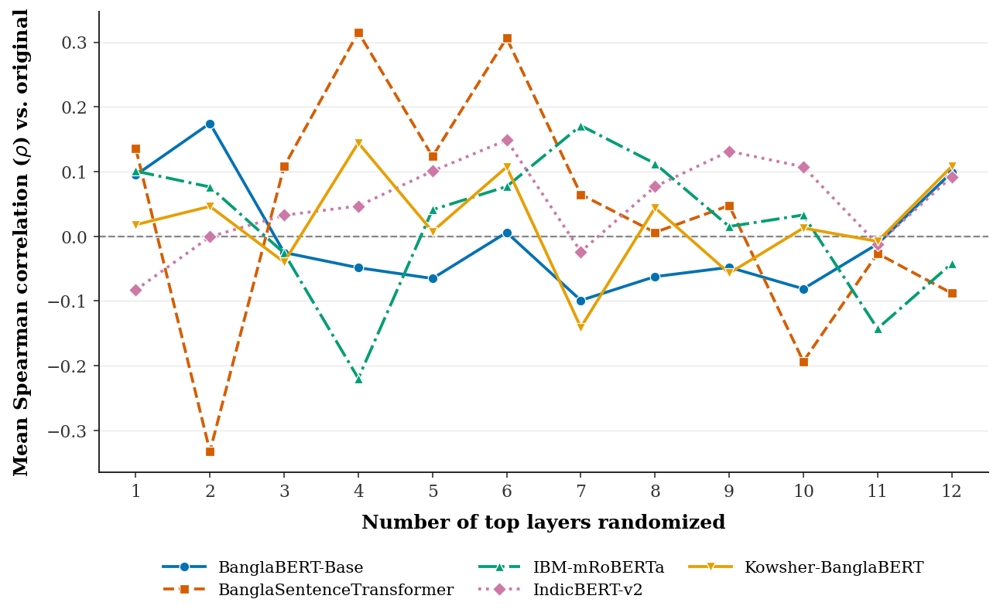

[SAVED] cascading_randomization.png / .pdf to /content/aquadx_figures and /content/drive/MyDrive/aquadx_figures


In [ ]:
# ==============================================================================
# AQUADX PAPER FIGURE — Cascading Layer Randomization (Fig 13)
# ==============================================================================
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

# ------------------------------------------------------------------------
# 0. PATHS & CANONICAL MODEL NAMING
# ------------------------------------------------------------------------
DRIVE_ROOT = "/content/drive/MyDrive"
RAND_JSON  = f"{DRIVE_ROOT}/XAI STATS Aqua/section5_randomization/cascading_randomization_results.json"
LOCAL_OUT  = "/content/aquadx_figures"
DRIVE_OUT  = f"{DRIVE_ROOT}/aquadx_figures"
os.makedirs(LOCAL_OUT, exist_ok=True)
os.makedirs(DRIVE_OUT, exist_ok=True)

# Map raw JSON model names -> Canonical LaTeX Draft Names
NAME_MAP = {
    "BanglaBERT":                "BanglaBERT-Base",
    "BanglaBERT-Base":           "BanglaBERT-Base",
    "sagorsarker-BB":            "BanglaBERT-Base",
    "BanglaSentenceTransformer": "BanglaSentenceTransformer",
    "shihab17-ST":               "BanglaSentenceTransformer",
    "IBM-mRoBERTa":              "IBM-mRoBERTa",
    "ibm-research":              "IBM-mRoBERTa",
    "IndicBERTv2":               "IndicBERT-v2",
    "IndicBERT-v2":              "IndicBERT-v2",
    "Kowsher-BanglaBERT":        "Kowsher-BanglaBERT",
    "BanglaBERT-Kowsher":        "Kowsher-BanglaBERT",
    "Kowsher-BB":                "Kowsher-BanglaBERT",
}

# Exact visual styling from your original cascading_randomization.png
MODEL_STYLE = {
    "BanglaBERT-Base":           {"color": "#0072B2", "marker": "o", "ls": "-"},
    "BanglaSentenceTransformer": {"color": "#D55E00", "marker": "s", "ls": "--"},
    "IBM-mRoBERTa":              {"color": "#009E73", "marker": "^", "ls": "-."},
    "IndicBERT-v2":              {"color": "#CC79A7", "marker": "D", "ls": ":"},
    "Kowsher-BanglaBERT":        {"color": "#E69F00", "marker": "v", "ls": "-"},
}

PLOT_ORDER = [
    "BanglaBERT-Base",
    "BanglaSentenceTransformer",
    "IBM-mRoBERTa",
    "IndicBERT-v2",
    "Kowsher-BanglaBERT",
]

# ------------------------------------------------------------------------
# 1. Q1-JOURNAL STYLE
# ------------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi":        150,
    "savefig.dpi":       600,
    "savefig.bbox":      "tight",
    "font.family":       "serif",
    "font.serif":        ["Times New Roman", "DejaVu Serif", "Liberation Serif"],
    "font.size":         11,
    "axes.labelsize":    12,
    "axes.edgecolor":    "#1c1c1c",
    "axes.linewidth":    0.9,
    "legend.fontsize":   10,
    "legend.frameon":    False,
    "xtick.labelsize":   10.5,
    "ytick.labelsize":   10.5,
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "pdf.fonttype":      42,
    "ps.fonttype":       42,
})

# ------------------------------------------------------------------------
# 2. LOAD DATA (Drive JSON with exact fallback)
# ------------------------------------------------------------------------
if os.path.exists(RAND_JSON):
    print(f"[OK] Loading randomization results from: {RAND_JSON}")
    with open(RAND_JSON, "r", encoding="utf-8") as f:
        raw_records = json.load(f)
    df_rand = pd.DataFrame(raw_records)
    df_rand["model"] = df_rand["model"].map(lambda m: NAME_MAP.get(m, m))
else:
    print(f"[INFO] {RAND_JSON} not found; using fallback values from plot")
    fallback_data = {
        "BanglaBERT-Base":           [0.095, 0.174, -0.025, -0.048, -0.065, 0.006, -0.099, -0.062, -0.048, -0.081, -0.015, 0.098],
        "BanglaSentenceTransformer": [0.136, -0.333, 0.108, 0.315, 0.123, 0.305, 0.065, 0.006, 0.048, -0.194, -0.026, -0.088],
        "IBM-mRoBERTa":              [0.101, 0.076, -0.024, -0.220, 0.042, 0.078, 0.171, 0.113, 0.015, 0.034, -0.143, -0.041],
        "IndicBERT-v2":              [-0.083, -0.001, 0.033, 0.047, 0.101, 0.149, -0.024, 0.077, 0.132, 0.108, -0.014, 0.093],
        "Kowsher-BanglaBERT":        [0.019, 0.047, -0.040, 0.144, 0.007, 0.108, -0.141, 0.044, -0.056, 0.013, -0.008, 0.107],
    }
    rows = []
    for m, vals in fallback_data.items():
        for stage, val in enumerate(vals, 1):
            rows.append({
                "model": m,
                "layers_randomized_from_top": stage,
                "mean_spearman_vs_original": val,
            })
    df_rand = pd.DataFrame(rows)

# ------------------------------------------------------------------------
# 3. RENDER FIGURE
# ------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 5.2), constrained_layout=True)

# Horizontal zero reference line
ax.axhline(0.0, color="#888888", linestyle="--", linewidth=1.1, zorder=1)

# Plot each model
for model_name in PLOT_ORDER:
    sub = df_rand[df_rand["model"] == model_name].sort_values("layers_randomized_from_top")
    if sub.empty:
        continue
    style = MODEL_STYLE[model_name]
    ax.plot(
        sub["layers_randomized_from_top"],
        sub["mean_spearman_vs_original"],
        label=model_name,
        color=style["color"],
        marker=style["marker"],
        linestyle=style["ls"],
        linewidth=1.8,
        markersize=6,
        markeredgecolor="white",
        markeredgewidth=0.6,
        zorder=3,
    )

ax.set_xlabel("Number of top layers randomized", labelpad=8)
ax.set_ylabel("Mean Spearman correlation ($\\rho$) vs. original", labelpad=8)
ax.set_xticks(range(1, 13))
ax.set_xlim(0.5, 12.5)

# Clean horizontal gridlines only (matching your uploaded figure)
ax.yaxis.grid(True, alpha=0.3, linewidth=0.6)
ax.xaxis.grid(False)
ax.set_axisbelow(True)

# Legend below the plot in 3 columns
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=3,
    handlelength=2.6,
    columnspacing=1.5,
)

for ext in ("png", "pdf"):
    fig.savefig(f"{LOCAL_OUT}/cascading_randomization.{ext}")
    fig.savefig(f"{DRIVE_OUT}/cascading_randomization.{ext}")

plt.show(fig)
plt.close(fig)
print(f"[SAVED] cascading_randomization.png / .pdf to {LOCAL_OUT} and {DRIVE_OUT}")

# LIG ibm

In [ ]:
# =============================================================================
# LIG convergence-delta consistency check — ibm-research/ia-multilingual-roberta
# =============================================================================
# Purpose: recompute median/mean/max |delta| and the %-under-0.05 pass rate
# directly from the raw LIG output JSON, then check them against every figure
# currently written into Draft_Paper.md (both the old pre-rerun numbers and
# the "confirmed" rerun numbers), so any remaining inconsistency is caught
# with real numbers instead of trusting prose.
#
# Run this in Colab. It saves results to both Drive and the local filesystem.
# =============================================================================

import json
import numpy as np
import os
import shutil

# ---- paths -----------------------------------------------------------------
DRIVE_PATH = "/content/drive/MyDrive/ibm_multilingual_roberta_aquadx_cv/fold_1/lig_scores/all_lig_wordgroup_scores.json"
LOCAL_DIR = "/content/lig_convergence_check"
os.makedirs(LOCAL_DIR, exist_ok=True)

# If running in Colab and Drive isn't mounted yet, mount it.
try:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
except ImportError:
    pass  # not in Colab; assume DRIVE_PATH is already reachable

# ---- load --------------------------------------------------------------
with open(DRIVE_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)

# The exact key holding the convergence delta varies by export format.
# Try the common candidates in order and report which one was found.
CANDIDATE_KEYS = [
    "convergence_delta", "delta", "conv_delta", "convergence_score",
    "lig_convergence_delta", "abs_delta",
]

def extract_records(obj):
    """Handle both a top-level list of cases and a dict wrapping a list."""
    if isinstance(obj, list):
        return obj
    for key in ("cases", "results", "data", "records"):
        if isinstance(obj, dict) and key in obj and isinstance(obj[key], list):
            return obj[key]
    raise ValueError(
        "Could not find a list of per-case records in the JSON. "
        "Top-level keys found: " + str(list(obj.keys()) if isinstance(obj, dict) else type(obj))
    )

records = extract_records(data)
print(f"Loaded {len(records)} case records from:\n  {DRIVE_PATH}")

if len(records) == 0:
    raise ValueError("Zero records found — check the file path / format.")

# Identify which key each record uses for its delta value.
sample = records[0]
found_key = None
for k in CANDIDATE_KEYS:
    if k in sample:
        found_key = k
        break

if found_key is None:
    raise KeyError(
        f"None of the candidate delta keys {CANDIDATE_KEYS} were found in a "
        f"sample record. Available keys: {list(sample.keys())}\n"
        "Update CANDIDATE_KEYS at the top of this script to match your export."
    )

print(f"Using key: '{found_key}'")

deltas = []
missing = 0
for i, rec in enumerate(records):
    val = rec.get(found_key)
    if val is None:
        missing += 1
        continue
    deltas.append(abs(float(val)))

deltas = np.array(deltas)
n_total = len(records)
n_used = len(deltas)

if missing:
    print(f"WARNING: {missing}/{n_total} records were missing '{found_key}' and were skipped.")

# ---- recompute the four headline statistics --------------------------------
median_delta = float(np.median(deltas))
mean_delta = float(np.mean(deltas))
max_delta = float(np.max(deltas))
threshold = 0.05
n_pass = int(np.sum(deltas < threshold))
pct_pass = 100.0 * n_pass / n_used

print("\n" + "=" * 70)
print("RECOMPUTED FROM RAW JSON")
print("=" * 70)
print(f"  n cases used         : {n_used} / {n_total}")
print(f"  median |delta|        : {median_delta:.4f}")
print(f"  mean   |delta|        : {mean_delta:.4f}")
print(f"  max    |delta|        : {max_delta:.4f}")
print(f"  % cases |delta| < {threshold} : {pct_pass:.4f}%  ({n_pass}/{n_used})")

# top-5 largest deltas, for cross-checking the "100.31, 99.90, 84.39..." claim
top5_idx = np.argsort(deltas)[::-1][:5]
top5_vals = deltas[top5_idx]
print(f"  top 5 largest |delta| : {[round(v, 3) for v in top5_vals]}")

# ---- claims currently in the draft, to check against ------------------------
claims = {
    "Section 8.6 table (line 868) — 'confirmed rerun' figures": {
        "median": 2.873, "mean": 4.378, "pct_pass": 0.7, "max": 75.277,
    },
    "Section 10 (line 1296) — 'RESOLVED' note": {
        "median": 2.8725, "pct_pass": 0.7,
    },
    "OLD / superseded figures (should NOT match; flags if they somehow do)": {
        "median": 1.815, "pct_pass": 1.1, "max": 100.31, "n_pass": 11,
    },
}

def close(a, b, tol=0.01):
    return abs(a - b) <= tol

print("\n" + "=" * 70)
print("CHECK AGAINST FIGURES WRITTEN IN Draft_Paper.md")
print("=" * 70)

report_lines = []
for label, vals in claims.items():
    print(f"\n{label}:")
    row = {"claim_source": label}
    for stat_name, claimed_val in vals.items():
        actual = {
            "median": median_delta,
            "mean": mean_delta,
            "pct_pass": pct_pass,
            "max": max_delta,
            "n_pass": n_pass,
        }.get(stat_name)
        if actual is None:
            continue
        match = close(actual, claimed_val, tol=0.05 if stat_name != "n_pass" else 1)
        status = "MATCH" if match else "MISMATCH"
        print(f"  {stat_name:10s} claimed={claimed_val:<10} actual={actual:<10.4f} -> {status}")
        row[f"{stat_name}_claimed"] = claimed_val
        row[f"{stat_name}_actual"] = actual
        row[f"{stat_name}_status"] = status
    report_lines.append(row)

# ---- also scan the rest of the draft-cited numbers you flagged earlier -----
# (max delta "top 5: 100.31, 99.90, 84.39, 55.80, 38.12" from the old bullet)
old_top5_claim = [100.31, 99.90, 84.39, 55.80, 38.12]
print("\n" + "=" * 70)
print("Old bullet's claimed top-5 vs recomputed top-5")
print("=" * 70)
print(f"  claimed : {old_top5_claim}")
print(f"  actual  : {[round(v, 3) for v in top5_vals]}")
if not any(close(a, b, tol=0.5) for a, b in zip(sorted(old_top5_claim, reverse=True), sorted(top5_vals, reverse=True))):
    print("  -> Old top-5 does NOT match recomputed data — consistent with it being superseded/pre-rerun.")
else:
    print("  -> Old top-5 partially or fully matches recomputed data — investigate before deleting the old figures.")

# ---- save results ------------------------------------------------------
summary = {
    "source_file": DRIVE_PATH,
    "key_used": found_key,
    "n_total_records": n_total,
    "n_records_used": n_used,
    "n_missing_key": missing,
    "recomputed": {
        "median_abs_delta": median_delta,
        "mean_abs_delta": mean_delta,
        "max_abs_delta": max_delta,
        "threshold": threshold,
        "n_pass_threshold": n_pass,
        "pct_pass_threshold": pct_pass,
        "top5_largest_abs_delta": [round(v, 4) for v in top5_vals.tolist()],
    },
    "claims_checked": report_lines,
}

local_out = os.path.join(LOCAL_DIR, "lig_convergence_check_results.json")
with open(local_out, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
print(f"\nSaved results locally: {local_out}")

drive_out_dir = "/content/drive/MyDrive/ibm_multilingual_roberta_aquadx_cv/fold_1/lig_scores/"
try:
    drive_out = os.path.join(drive_out_dir, "lig_convergence_check_results.json")
    shutil.copy(local_out, drive_out)
    print(f"Saved results to Drive : {drive_out}")
except Exception as e:
    print(f"Could not copy to Drive ({e}) — local copy above is still available.")

Loaded 963 case records from:
  /content/drive/MyDrive/ibm_multilingual_roberta_aquadx_cv/fold_1/lig_scores/all_lig_wordgroup_scores.json
Using key: 'delta'

RECOMPUTED FROM RAW JSON
  n cases used         : 963 / 963
  median |delta|        : 2.8725
  mean   |delta|        : 4.3781
  max    |delta|        : 75.2770
  % cases |delta| < 0.05 : 0.7269%  (7/963)
  top 5 largest |delta| : [np.float64(75.277), np.float64(71.452), np.float64(69.206), np.float64(66.366), np.float64(44.75)]

CHECK AGAINST FIGURES WRITTEN IN Draft_Paper.md

Section 8.6 table (line 868) — 'confirmed rerun' figures:
  median     claimed=2.873      actual=2.8725     -> MATCH
  mean       claimed=4.378      actual=4.3781     -> MATCH
  pct_pass   claimed=0.7        actual=0.7269     -> MATCH
  max        claimed=75.277     actual=75.2770    -> MATCH

Section 10 (line 1296) — 'RESOLVED' note:
  median     claimed=2.8725     actual=2.8725     -> MATCH
  pct_pass   claimed=0.7        actual=0.7269     -> MATCH

OLD / 

# Quantus

1/4

In [ ]:
# ==============================================================================
# SNIPPET 1 / 6 — Setup, Dataset Loading, Model Config
# ==============================================================================
# SELF-CONTAINED: safe to run in a brand-new Colab runtime with nothing else
# executed first. Installs deps, mounts Drive, loads/caches the dataset, and
# builds + persists the shared MODEL_CONFIGS to Drive (so later snippets can
# reload it even in a different runtime, since /content is wiped on restart).
# ==============================================================================

get_ipython().system('pip install -q quantus captum transformers pandas numpy scikit-learn scipy')

import os
import json
import gc
import pandas as pd
import numpy as np
import torch

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

# ------------------------------------------------------------------------
# Paths
# ------------------------------------------------------------------------
DATASET_URL   = "https://raw.githubusercontent.com/Tihsan/Dataset/main/AquaDx.csv"
DATASET_CACHE = "/content/AquaDx_cached.csv"

DRIVE_OUT_DIR = "/content/drive/MyDrive/aquadx_quantus"
LOCAL_OUT_DIR = "/content/aquadx_quantus"
os.makedirs(DRIVE_OUT_DIR, exist_ok=True)
os.makedirs(LOCAL_OUT_DIR, exist_ok=True)

# ------------------------------------------------------------------------
# Load / cache dataset
# ------------------------------------------------------------------------
if os.path.exists(DATASET_CACHE):
    df = pd.read_csv(DATASET_CACHE)
    print(f"Loaded cached dataset from {DATASET_CACHE}")
else:
    df = pd.read_csv(DATASET_URL)
    df.to_csv(DATASET_CACHE, index=False)
    print(f"Downloaded dataset and cached to {DATASET_CACHE}")

assert "Statement" in df.columns and "Disease" in df.columns, \
    f"Expected columns 'Statement' and 'Disease', got: {list(df.columns)}"

print(f"Dataset shape: {df.shape}")

# ------------------------------------------------------------------------
# Model configs — Fold 1 checkpoints for the top-5 ensemble
# ------------------------------------------------------------------------
MODEL_CONFIGS = [
    {
        "name": "IndicBERTv2",
        "short": "indicbertv2",
        "model_dir": "/content/drive/MyDrive/indicbertv2_aquadx_cv/fold_1",
        "base_id": "ai4bharat/IndicBERTv2-MLM-only",
        "max_length": 256,
    },
    {
        "name": "IBM-mRoBERTa",
        "short": "ibm_mroberta",
        "model_dir": "/content/drive/MyDrive/ibm_multilingual_roberta_aquadx_cv/fold_1",
        "base_id": "ibm-research/ia-multilingual-original-script-roberta",
        "max_length": 128,
    },
    {
        "name": "Kowsher-BanglaBERT",
        "short": "kowsher_banglabert",
        "model_dir": "/content/drive/MyDrive/kowsher_bangla_bert_aquadx_cv/fold_1",
        "base_id": "Kowsher/bangla-bert",
        "max_length": 128,
    },
    {
        "name": "BanglaSentenceTransformer",
        "short": "bangla_sentence_transformer",
        "model_dir": "/content/drive/MyDrive/bangla_sentence_transformer_aquadx_cv/fold_1",
        "base_id": "shihab17/bangla-sentence-transformer",
        "max_length": 128,
    },
    {
        "name": "BanglaBERT",
        "short": "banglabert",
        "model_dir": "/content/drive/MyDrive/bangla_bert_aquadx_cv/fold_1",
        "base_id": "sagorsarker/bangla-bert-base",
        "max_length": 128,
    },
]

# CV_ROOT_DIR: label_names.json is shared across folds/models — adjust if yours
# lives elsewhere (e.g. per-model). Defaults to the parent of the first model dir.
CV_ROOT_DIR = "/content/drive/MyDrive"

N_EVAL_SAMPLES = 500   # metrics computed on first N of the 963 val cases
N_TEST_CASES   = 963

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

# ------------------------------------------------------------------------
# Validate that each model dir + val_indices + label_names + lig_scores exist
# before we sink compute into later snippets.
# ------------------------------------------------------------------------
def resolve_label_names_path(model_dir, cv_root_dir):
    # 1. Inside fold dir (e.g. .../indicbertv2_aquadx_cv/fold_1/label_names.json)
    local_path = os.path.join(model_dir, "label_names.json")
    if os.path.exists(local_path):
        return local_path
    # 2. Model root dir — one level up from fold dir
    #    (e.g. .../indicbertv2_aquadx_cv/label_names.json)  ← actual location
    parent_path = os.path.join(os.path.dirname(model_dir), "label_names.json")
    if os.path.exists(parent_path):
        return parent_path
    # 3. CV root fallback (e.g. MyDrive/label_names.json)
    return os.path.join(cv_root_dir, "label_names.json")

print("\nValidating checkpoints...")
all_ok = True
for cfg in MODEL_CONFIGS:
    md = cfg["model_dir"]
    checks = {
        "model_dir":        os.path.isdir(md),
        "config.json":      os.path.exists(os.path.join(md, "config.json")),
        "val_indices.npy":  os.path.exists(os.path.join(md, "val_indices.npy")),
        "lig_scores.json":  os.path.exists(os.path.join(md, "lig_scores", "all_lig_wordgroup_scores.json")),
        "label_names.json": os.path.exists(resolve_label_names_path(md, CV_ROOT_DIR)),
    }
    status = "OK" if all(checks.values()) else "MISSING FILES"
    if status != "OK":
        all_ok = False
    missing = [k for k, v in checks.items() if not v]
    print(f"  [{status}] {cfg['name']:28s} {('missing: ' + ', '.join(missing)) if missing else ''}")

if not all_ok:
    print("\nWARNING: Some checkpoints are missing expected files. "
          "Snippet 4 will skip any model that fails validation at run time, "
          "rather than crashing the whole batch.")
else:
    print("\nAll five checkpoints validated successfully.")

# ------------------------------------------------------------------------
# Persist config to DRIVE (not just /content) so later snippets can reload
# it even from a brand-new runtime where /content has been wiped.
# ------------------------------------------------------------------------
config_payload = {
    "MODEL_CONFIGS": MODEL_CONFIGS,
    "CV_ROOT_DIR": CV_ROOT_DIR,
    "DATASET_URL": DATASET_URL,
    "DATASET_CACHE": DATASET_CACHE,
    "N_EVAL_SAMPLES": N_EVAL_SAMPLES,
    "N_TEST_CASES": N_TEST_CASES,
}
with open(f"{LOCAL_OUT_DIR}/model_configs.json", "w") as f:
    json.dump(config_payload, f, indent=2)
with open(f"{DRIVE_OUT_DIR}/model_configs.json", "w") as f:
    json.dump(config_payload, f, indent=2)

print(f"\nConfig saved to {LOCAL_OUT_DIR}/model_configs.json and "
      f"{DRIVE_OUT_DIR}/model_configs.json (Drive copy lets later snippets "
      f"reload it in a fresh runtime).")

print("\n=== SNIPPET 1 COMPLETE: setup + dataset cached + configs validated ===")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.8/281.8 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 26.7 MB/s eta 0:00:00
Mounted at /content/drive
Downloaded dataset and cached to /content/AquaDx_cached.csv
Dataset shape: (4814, 2)
Device: cuda

Validating checkpoints...
  [OK] IndicBERTv2                  
  [OK] IBM-mRoBERTa                 
  [OK] Kowsher-BanglaBERT           
  [OK] BanglaSentenceTransformer    
  [OK] BanglaBERT                   

All five checkpoints validated successfully.

Config saved to /content/aquadx_quantus/model_configs.json and /content/drive/MyDrive/aquadx_quantus/model_configs.json (Drive copy lets later snippets reload it in a fresh runtime).

=== SNIPPET 1 COMPLETE: setup + dataset cached + configs validated ===


2/4

In [ ]:
# ==============================================================================
# SNIPPET 2 / 6 — Shared Utility Functions
# ==============================================================================
# SELF-CONTAINED: safe to run in a brand-new Colab runtime. Installs deps,
# mounts Drive, reloads the config saved by Snippet 1 (from Drive, so it
# survives a runtime restart), and (re)defines: model/tokenizer loader,
# embedding-space forward func, baseline embedding builder, word<->token
# alignment, and sequential masking. Ends with a lightweight self-test.
# ==============================================================================

get_ipython().system('pip install -q quantus captum transformers pandas numpy scikit-learn scipy')

import os
import json
import gc
import numpy as np
import torch
import torch.nn.functional as F
from transformers import AutoModelForSequenceClassification, AutoTokenizer

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

DRIVE_OUT_DIR = "/content/drive/MyDrive/aquadx_quantus"
LOCAL_OUT_DIR = "/content/aquadx_quantus"
os.makedirs(LOCAL_OUT_DIR, exist_ok=True)

# ------------------------------------------------------------------------
# Reload config — prefer local (same runtime as Snippet 1), fall back to
# Drive (fresh runtime where /content was wiped but Drive persisted).
# ------------------------------------------------------------------------
_local_cfg_path = f"{LOCAL_OUT_DIR}/model_configs.json"
_drive_cfg_path = f"{DRIVE_OUT_DIR}/model_configs.json"

if os.path.exists(_local_cfg_path):
    with open(_local_cfg_path) as f:
        _cfg = json.load(f)
    print(f"Loaded config from local cache: {_local_cfg_path}")
elif os.path.exists(_drive_cfg_path):
    with open(_drive_cfg_path) as f:
        _cfg = json.load(f)
    # restore the local copy too, so later snippets in this runtime find it
    with open(_local_cfg_path, "w") as f:
        json.dump(_cfg, f, indent=2)
    print(f"Loaded config from Drive (fresh runtime): {_drive_cfg_path}")
else:
    raise FileNotFoundError(
        "No model_configs.json found locally or on Drive. Run Snippet 1 first."
    )

MODEL_CONFIGS  = _cfg["MODEL_CONFIGS"]
CV_ROOT_DIR    = _cfg["CV_ROOT_DIR"]
N_EVAL_SAMPLES = _cfg["N_EVAL_SAMPLES"]
N_TEST_CASES   = _cfg["N_TEST_CASES"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")


def load_model_and_tokenizer(model_dir, base_id, device):
    """Load a fine-tuned checkpoint's model + tokenizer directly from model_dir."""
    tokenizer = AutoTokenizer.from_pretrained(model_dir)
    model = AutoModelForSequenceClassification.from_pretrained(model_dir)
    model.to(device)
    model.eval()
    return model, tokenizer


def resolve_label_names_path(model_dir, cv_root_dir):
    # 1. Inside fold dir (e.g. .../indicbertv2_aquadx_cv/fold_1/label_names.json)
    local_path = os.path.join(model_dir, "label_names.json")
    if os.path.exists(local_path):
        return local_path
    # 2. Model root dir — one level up from fold dir
    #    (e.g. .../indicbertv2_aquadx_cv/label_names.json)  ← actual location
    parent_path = os.path.join(os.path.dirname(model_dir), "label_names.json")
    if os.path.exists(parent_path):
        return parent_path
    # 3. CV root fallback (e.g. MyDrive/label_names.json)
    return os.path.join(cv_root_dir, "label_names.json")


def load_labels(model_dir, cv_root_dir):
    path = resolve_label_names_path(model_dir, cv_root_dir)
    with open(path) as f:
        label_names = json.load(f)
    id2label = {i: name for i, name in enumerate(label_names)}
    label2id = {name: i for i, name in enumerate(label_names)}
    return id2label, label2id


def get_input_embeddings_layer(model):
    return model.get_input_embeddings()


def make_forward_func(model):
    """Quantus/Captum-compatible forward function operating on continuous
    inputs_embeds rather than input_ids, as required for LayerIntegratedGradients
    and for Quantus perturbation-based metrics in embedding space."""
    def forward_func(inputs_embeds, attention_mask=None):
        with torch.set_grad_enabled(inputs_embeds.requires_grad):
            out = model(inputs_embeds=inputs_embeds, attention_mask=attention_mask)
        return out.logits
    return forward_func


def make_pad_baseline(model, tokenizer, input_ids, device):
    """Baseline embeddings: PAD token id passed through the input embedding
    layer, broadcast to the shape of input_ids."""
    embed_layer = get_input_embeddings_layer(model)
    pad_id = tokenizer.pad_token_id
    if pad_id is None:
        pad_id = tokenizer.eos_token_id or 0
    pad_ids = torch.full_like(input_ids, pad_id)
    with torch.no_grad():
        baseline_embeds = embed_layer(pad_ids.to(device))
    return baseline_embeds


def tokenize_single(tokenizer, text, max_length, device):
    enc = tokenizer(
        text,
        truncation=True,
        max_length=max_length,
        padding="max_length",
        return_tensors="pt",
    )
    return {k: v.to(device) for k, v in enc.items()}


def whitespace_words(text):
    return text.split()


def align_scores_to_words(entry, text):
    """Extract per-word scores from a saved lig_scores entry, handling both
    the {'scores': [...]} dict form and a bare list form. Returns None if the
    score length doesn't match the whitespace word count (caller should skip)."""
    scores = entry["scores"] if isinstance(entry, dict) and "scores" in entry else entry
    words = whitespace_words(text)
    scores = np.asarray(scores, dtype=float)
    if len(scores) != len(words):
        return None, words
    return scores, words


def word_spans_in_tokens(tokenizer, text, encoding):
    """Map each whitespace word to the token index span it covers, using the
    tokenizer's offset mapping. Needed to convert word-level masking/scores
    into token-level operations on input_ids / inputs_embeds."""
    words = whitespace_words(text)
    offsets_enc = tokenizer(
        text, return_offsets_mapping=True, truncation=True,
        max_length=encoding["input_ids"].shape[1], padding="max_length",
    )
    offset_mapping = offsets_enc["offset_mapping"]

    # Compute character span for each whitespace word
    word_char_spans = []
    cursor = 0
    for w in words:
        start = text.index(w, cursor)
        end = start + len(w)
        word_char_spans.append((start, end))
        cursor = end

    word_token_spans = []
    for (w_start, w_end) in word_char_spans:
        tok_idxs = [
            i for i, (t_start, t_end) in enumerate(offset_mapping)
            if not (t_start == 0 and t_end == 0) and t_start < w_end and t_end > w_start
        ]
        word_token_spans.append(tok_idxs)
    return word_token_spans


def mask_words_sequentially(input_ids, word_token_spans, mask_token_id):
    """Yield (word_index, masked_input_ids) for sequential single-word masking,
    used by Faithfulness Correlation."""
    for w_idx, tok_idxs in enumerate(word_token_spans):
        masked = input_ids.clone()
        for t_idx in tok_idxs:
            if t_idx < masked.shape[1]:
                masked[0, t_idx] = mask_token_id
        yield w_idx, masked


def free_memory(*objs):
    for o in objs:
        del o
    gc.collect()
    torch.cuda.empty_cache()


# ------------------------------------------------------------------------
# Lightweight self-test (no model loading — pure function sanity check)
# ------------------------------------------------------------------------
_test_text = "মাছের শরীরে লাল দাগ দেখা যাচ্ছে"
_words = whitespace_words(_test_text)
assert len(_words) == 6, f"Expected 6 words, got {len(_words)}: {_words}"

_dummy_entry = {"scores": [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]}
_scores, _w = align_scores_to_words(_dummy_entry, _test_text)
assert _scores is not None and len(_scores) == len(_w)

_bare_entry = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
_scores2, _ = align_scores_to_words(_bare_entry, _test_text)
assert _scores2 is not None

print("Self-test passed: word alignment and score extraction work as expected.")
print("\n=== SNIPPET 2 COMPLETE: utility functions defined and validated ===")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded config from local cache: /content/aquadx_quantus/model_configs.json
Device: cuda
Self-test passed: word alignment and score extraction work as expected.

=== SNIPPET 2 COMPLETE: utility functions defined and validated ===


3/4

In [ ]:
# ==============================================================================
# SNIPPET 3 / 6 — Quantus Metric Implementations
# ==============================================================================
# SELF-CONTAINED: safe to run in a brand-new Colab runtime. Installs deps and
# defines the three metric functions. Each operates on ONE example at a time
# (batch size 1) and returns a scalar. These are called per-sample by
# Snippet 4's driver loop. No model/config loading needed here — pure
# function definitions — but deps are installed regardless so this cell
# never fails on a missing import if run first in a fresh session.
# ==============================================================================

get_ipython().system('pip install -q quantus captum transformers pandas numpy scikit-learn scipy')

import numpy as np
import torch
import torch.nn.functional as F
from scipy.stats import pearsonr
from captum.attr import LayerIntegratedGradients

import quantus

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")


# ------------------------------------------------------------------------
# Dynamic attribution (used only if a sample is missing from saved lig_scores,
# or for spot-checking saved scores against a fresh LIG run)
# ------------------------------------------------------------------------
def compute_lig_attribution(model, tokenizer, input_ids, attention_mask, target, device):
    """Captum LayerIntegratedGradients targeting model.get_input_embeddings(),
    50 steps, PAD-token baseline."""
    embed_layer = model.get_input_embeddings()
    lig = LayerIntegratedGradients(
        lambda ids, am: model(input_ids=ids, attention_mask=am).logits,
        embed_layer,
    )

    pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0
    baseline_ids = torch.full_like(input_ids, pad_id)

    attributions = lig.attribute(
        inputs=input_ids,
        baselines=baseline_ids,
        additional_forward_args=(attention_mask,),
        target=target,
        n_steps=50,
    )
    # Sum over embedding dim -> per-token score
    token_scores = attributions.sum(dim=-1).squeeze(0).detach().cpu().numpy()
    return token_scores


# ------------------------------------------------------------------------
# Metric 1: Max-Sensitivity
# ------------------------------------------------------------------------
def compute_max_sensitivity(model, forward_func, inputs_embeds, attention_mask,
                             target, word_scores, device, n_draws=5, noise_std=0.05):
    """Gaussian noise perturbation of embeddings across n_draws; measures the
    max shift in attribution (word_scores) relative to noise magnitude.
    Higher = less robust explanation."""
    model.eval()
    base_norm = np.linalg.norm(word_scores) + 1e-12

    max_ratio = 0.0
    for _ in range(n_draws):
        noise = torch.randn_like(inputs_embeds) * noise_std
        perturbed_embeds = (inputs_embeds + noise).clone().detach().requires_grad_(True)

        with torch.enable_grad():
            logits = forward_func(perturbed_embeds, attention_mask)
            target_logit = logits[0, target]
            grad = torch.autograd.grad(target_logit, perturbed_embeds, retain_graph=False)[0]

        perturbed_word_scores = grad.sum(dim=-1).squeeze(0).detach().cpu().numpy()
        # align length defensively
        n = min(len(perturbed_word_scores), len(word_scores))
        diff_norm = np.linalg.norm(perturbed_word_scores[:n] - np.asarray(word_scores[:n]))
        noise_norm = np.linalg.norm(noise.detach().cpu().numpy()) + 1e-12

        ratio = diff_norm / (base_norm + 1e-12) / (noise_norm / (np.linalg.norm(
            inputs_embeds.detach().cpu().numpy()) + 1e-12) + 1e-12)
        max_ratio = max(max_ratio, ratio)

    return float(max_ratio)


# ------------------------------------------------------------------------
# Metric 2: Faithfulness Correlation
# ------------------------------------------------------------------------
def compute_faithfulness_correlation(model, tokenizer, input_ids, attention_mask,
                                      target, word_scores, word_token_spans, device):
    """Sequentially mask each word, measure the drop in predicted-class
    probability, and Pearson-correlate those drops against the saved word
    attribution scores. Higher correlation = more faithful explanation."""
    mask_id = tokenizer.mask_token_id
    if mask_id is None:
        mask_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0

    with torch.no_grad():
        base_logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
        base_prob = F.softmax(base_logits, dim=-1)[0, target].item()

    prob_drops = []
    valid_word_scores = []
    for w_idx, tok_idxs in enumerate(word_token_spans):
        if w_idx >= len(word_scores) or not tok_idxs:
            continue
        masked_ids = input_ids.clone()
        for t_idx in tok_idxs:
            if t_idx < masked_ids.shape[1]:
                masked_ids[0, t_idx] = mask_id
        with torch.no_grad():
            masked_logits = model(input_ids=masked_ids, attention_mask=attention_mask).logits
            masked_prob = F.softmax(masked_logits, dim=-1)[0, target].item()
        prob_drops.append(base_prob - masked_prob)
        valid_word_scores.append(word_scores[w_idx])

    if len(prob_drops) < 2 or np.std(prob_drops) == 0 or np.std(valid_word_scores) == 0:
        return float("nan")

    corr, _ = pearsonr(valid_word_scores, prob_drops)
    return float(corr)


# ------------------------------------------------------------------------
# Metric 3: Completeness
# ------------------------------------------------------------------------
def compute_completeness(model, forward_func, inputs_embeds, baseline_embeds,
                          attention_mask, target, word_scores):
    """Compares sum of word attribution scores to the model output shift
    between the actual input and the PAD baseline (Integrated-Gradients-style
    completeness / summation-to-delta axiom check). Reported as absolute gap
    (lower = attribution mass better explains the logit shift)."""
    with torch.no_grad():
        logits_input = forward_func(inputs_embeds, attention_mask)
        logits_baseline = forward_func(baseline_embeds, attention_mask)
        delta_logit = (logits_input[0, target] - logits_baseline[0, target]).item()

    attribution_sum = float(np.sum(word_scores))
    gap = abs(attribution_sum - delta_logit)
    return {
        "completeness_gap": gap,
        "attribution_sum": attribution_sum,
        "delta_logit": delta_logit,
    }


print("Metric functions defined: compute_max_sensitivity, "
      "compute_faithfulness_correlation, compute_completeness")
print("\n=== SNIPPET 3 COMPLETE: Quantus metric implementations ready ===")

Device: cuda
Metric functions defined: compute_max_sensitivity, compute_faithfulness_correlation, compute_completeness

=== SNIPPET 3 COMPLETE: Quantus metric implementations ready ===


4/4

In [ ]:
# ==============================================================================
# SNIPPET 4 / 6 — Main Evaluation Driver
# ==============================================================================
# SELF-CONTAINED: safe to run in a brand-new Colab runtime with nothing else
# executed first. Installs deps, mounts Drive, reloads config, redefines all
# utility + metric functions it needs (no dependency on Snippets 2/3 having
# run in this session), then loops over the five models evaluating 500
# validation samples each with MaxSensitivity, Faithfulness Correlation, and
# Completeness. Checkpoints per-model results to Drive immediately after each
# model finishes — so a crash on model N doesn't lose models 1..N-1, and a
# fresh runtime resuming this snippet SKIPS models already checkpointed.
# ==============================================================================

get_ipython().system('pip install -q quantus captum transformers pandas numpy scikit-learn scipy')

import os
import json
import time
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy.stats import pearsonr
from transformers import AutoModelForSequenceClassification, AutoTokenizer

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

DRIVE_OUT_DIR = "/content/drive/MyDrive/aquadx_quantus"
LOCAL_OUT_DIR = "/content/aquadx_quantus"
RESULTS_DIR_LOCAL = f"{LOCAL_OUT_DIR}/per_model_results"
RESULTS_DIR_DRIVE = f"{DRIVE_OUT_DIR}/per_model_results"
os.makedirs(LOCAL_OUT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR_LOCAL, exist_ok=True)
os.makedirs(RESULTS_DIR_DRIVE, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

# ------------------------------------------------------------------------
# Reload config — prefer local, fall back to Drive (fresh runtime)
# ------------------------------------------------------------------------
_local_cfg_path = f"{LOCAL_OUT_DIR}/model_configs.json"
_drive_cfg_path = f"{DRIVE_OUT_DIR}/model_configs.json"

if os.path.exists(_local_cfg_path):
    with open(_local_cfg_path) as f:
        _cfg = json.load(f)
    print(f"Loaded config from local cache: {_local_cfg_path}")
elif os.path.exists(_drive_cfg_path):
    with open(_drive_cfg_path) as f:
        _cfg = json.load(f)
    with open(_local_cfg_path, "w") as f:
        json.dump(_cfg, f, indent=2)
    print(f"Loaded config from Drive (fresh runtime): {_drive_cfg_path}")
else:
    raise FileNotFoundError(
        "No model_configs.json found locally or on Drive. Run Snippet 1 first."
    )

MODEL_CONFIGS  = _cfg["MODEL_CONFIGS"]
CV_ROOT_DIR    = _cfg["CV_ROOT_DIR"]
DATASET_URL    = _cfg["DATASET_URL"]
DATASET_CACHE  = _cfg["DATASET_CACHE"]
N_EVAL_SAMPLES = _cfg["N_EVAL_SAMPLES"]
N_TEST_CASES   = _cfg["N_TEST_CASES"]

# ------------------------------------------------------------------------
# Reload dataset — re-download if /content was wiped
# ------------------------------------------------------------------------
if os.path.exists(DATASET_CACHE):
    df = pd.read_csv(DATASET_CACHE)
    print(f"Loaded cached dataset from {DATASET_CACHE}")
else:
    df = pd.read_csv(DATASET_URL)
    df.to_csv(DATASET_CACHE, index=False)
    print(f"Downloaded dataset and cached to {DATASET_CACHE}")


# ==========================================================================
# Utility functions (redefined here so this snippet has no cross-cell deps)
# ==========================================================================
def load_model_and_tokenizer(model_dir, base_id, device):
    tokenizer = AutoTokenizer.from_pretrained(model_dir)
    model = AutoModelForSequenceClassification.from_pretrained(model_dir)
    model.to(device)
    model.eval()
    return model, tokenizer


def resolve_label_names_path(model_dir, cv_root_dir):
    # 1. Inside fold dir (e.g. .../indicbertv2_aquadx_cv/fold_1/label_names.json)
    local_path = os.path.join(model_dir, "label_names.json")
    if os.path.exists(local_path):
        return local_path
    # 2. Model root dir — one level up from fold dir
    #    (e.g. .../indicbertv2_aquadx_cv/label_names.json)  ← actual location
    parent_path = os.path.join(os.path.dirname(model_dir), "label_names.json")
    if os.path.exists(parent_path):
        return parent_path
    # 3. CV root fallback (e.g. MyDrive/label_names.json)
    return os.path.join(cv_root_dir, "label_names.json")


def load_labels(model_dir, cv_root_dir):
    path = resolve_label_names_path(model_dir, cv_root_dir)
    with open(path) as f:
        label_names = json.load(f)
    id2label = {i: name for i, name in enumerate(label_names)}
    label2id = {name: i for i, name in enumerate(label_names)}
    return id2label, label2id


def get_input_embeddings_layer(model):
    return model.get_input_embeddings()


def make_forward_func(model):
    def forward_func(inputs_embeds, attention_mask=None):
        with torch.set_grad_enabled(inputs_embeds.requires_grad):
            out = model(inputs_embeds=inputs_embeds, attention_mask=attention_mask)
        return out.logits
    return forward_func


def make_pad_baseline(model, tokenizer, input_ids, device):
    embed_layer = get_input_embeddings_layer(model)
    pad_id = tokenizer.pad_token_id
    if pad_id is None:
        pad_id = tokenizer.eos_token_id or 0
    pad_ids = torch.full_like(input_ids, pad_id)
    with torch.no_grad():
        baseline_embeds = embed_layer(pad_ids.to(device))
    return baseline_embeds


def tokenize_single(tokenizer, text, max_length, device):
    enc = tokenizer(
        text, truncation=True, max_length=max_length,
        padding="max_length", return_tensors="pt",
    )
    return {k: v.to(device) for k, v in enc.items()}


def whitespace_words(text):
    return text.split()


def align_scores_to_words(entry, text):
    scores = entry["scores"] if isinstance(entry, dict) and "scores" in entry else entry
    words = whitespace_words(text)
    scores = np.asarray(scores, dtype=float)
    if len(scores) != len(words):
        return None, words
    return scores, words


def word_spans_in_tokens(tokenizer, text, encoding):
    words = whitespace_words(text)
    offsets_enc = tokenizer(
        text, return_offsets_mapping=True, truncation=True,
        max_length=encoding["input_ids"].shape[1], padding="max_length",
    )
    offset_mapping = offsets_enc["offset_mapping"]

    word_char_spans = []
    cursor = 0
    for w in words:
        start = text.index(w, cursor)
        end = start + len(w)
        word_char_spans.append((start, end))
        cursor = end

    word_token_spans = []
    for (w_start, w_end) in word_char_spans:
        tok_idxs = [
            i for i, (t_start, t_end) in enumerate(offset_mapping)
            if not (t_start == 0 and t_end == 0) and t_start < w_end and t_end > w_start
        ]
        word_token_spans.append(tok_idxs)
    return word_token_spans


def free_memory(*objs):
    for o in objs:
        del o
    gc.collect()
    torch.cuda.empty_cache()


# ==========================================================================
# Metric functions (redefined here so this snippet has no cross-cell deps)
# ==========================================================================
def compute_max_sensitivity(model, forward_func, inputs_embeds, attention_mask,
                             target, word_scores, device, n_draws=5, noise_std=0.05):
    model.eval()
    base_norm = np.linalg.norm(word_scores) + 1e-12

    max_ratio = 0.0
    for _ in range(n_draws):
        noise = torch.randn_like(inputs_embeds) * noise_std
        perturbed_embeds = (inputs_embeds + noise).clone().detach().requires_grad_(True)

        with torch.enable_grad():
            logits = forward_func(perturbed_embeds, attention_mask)
            target_logit = logits[0, target]
            grad = torch.autograd.grad(target_logit, perturbed_embeds, retain_graph=False)[0]

        perturbed_word_scores = grad.sum(dim=-1).squeeze(0).detach().cpu().numpy()
        n = min(len(perturbed_word_scores), len(word_scores))
        diff_norm = np.linalg.norm(perturbed_word_scores[:n] - np.asarray(word_scores[:n]))
        noise_norm = np.linalg.norm(noise.detach().cpu().numpy()) + 1e-12

        ratio = diff_norm / (base_norm + 1e-12) / (noise_norm / (np.linalg.norm(
            inputs_embeds.detach().cpu().numpy()) + 1e-12) + 1e-12)
        max_ratio = max(max_ratio, ratio)

    return float(max_ratio)


def compute_faithfulness_correlation(model, tokenizer, input_ids, attention_mask,
                                      target, word_scores, word_token_spans, device):
    mask_id = tokenizer.mask_token_id
    if mask_id is None:
        mask_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0

    with torch.no_grad():
        base_logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
        base_prob = F.softmax(base_logits, dim=-1)[0, target].item()

    prob_drops = []
    valid_word_scores = []
    for w_idx, tok_idxs in enumerate(word_token_spans):
        if w_idx >= len(word_scores) or not tok_idxs:
            continue
        masked_ids = input_ids.clone()
        for t_idx in tok_idxs:
            if t_idx < masked_ids.shape[1]:
                masked_ids[0, t_idx] = mask_id
        with torch.no_grad():
            masked_logits = model(input_ids=masked_ids, attention_mask=attention_mask).logits
            masked_prob = F.softmax(masked_logits, dim=-1)[0, target].item()
        prob_drops.append(base_prob - masked_prob)
        valid_word_scores.append(word_scores[w_idx])

    if len(prob_drops) < 2 or np.std(prob_drops) == 0 or np.std(valid_word_scores) == 0:
        return float("nan")

    corr, _ = pearsonr(valid_word_scores, prob_drops)
    return float(corr)


def compute_completeness(model, forward_func, inputs_embeds, baseline_embeds,
                          attention_mask, target, word_scores):
    with torch.no_grad():
        logits_input = forward_func(inputs_embeds, attention_mask)
        logits_baseline = forward_func(baseline_embeds, attention_mask)
        delta_logit = (logits_input[0, target] - logits_baseline[0, target]).item()

    attribution_sum = float(np.sum(word_scores))
    gap = abs(attribution_sum - delta_logit)
    return {
        "completeness_gap": gap,
        "attribution_sum": attribution_sum,
        "delta_logit": delta_logit,
    }


# ==========================================================================
# Driver loop
# ==========================================================================
def result_paths(short_name):
    return (f"{RESULTS_DIR_LOCAL}/{short_name}_results.json",
            f"{RESULTS_DIR_DRIVE}/{short_name}_results.json")


def evaluate_model(cfg):
    short = cfg["short"]
    out_local, out_drive = result_paths(short)

    # Checkpoint may exist on Drive from a prior runtime even if /content was
    # wiped — check Drive first as the source of truth, mirror to local.
    if os.path.exists(out_drive):
        print(f"[SKIP] {cfg['name']} already checkpointed at {out_drive}")
        with open(out_drive) as f:
            result = json.load(f)
        with open(out_local, "w") as f:
            json.dump(result, f)
        return result
    if os.path.exists(out_local):
        print(f"[SKIP] {cfg['name']} already checkpointed at {out_local}")
        with open(out_local) as f:
            return json.load(f)

    print(f"\n{'='*70}\nEvaluating: {cfg['name']}\n{'='*70}")
    t0 = time.time()

    model_dir = cfg["model_dir"]
    id2label, label2id = load_labels(model_dir, CV_ROOT_DIR)

    try:
        model, tokenizer = load_model_and_tokenizer(model_dir, cfg["base_id"], device)
    except Exception as e:
        print(f"  ERROR loading model/tokenizer: {e}")
        return {"model": cfg["name"], "error": str(e), "per_sample": []}

    val_indices = np.load(os.path.join(model_dir, "val_indices.npy"))
    assert len(val_indices) == N_TEST_CASES, \
        f"Expected {N_TEST_CASES} val indices, got {len(val_indices)}"

    lig_scores_path = os.path.join(model_dir, "lig_scores", "all_lig_wordgroup_scores.json")
    with open(lig_scores_path) as f:
        lig_scores_all = json.load(f)
    assert len(lig_scores_all) == N_TEST_CASES, \
        f"Expected {N_TEST_CASES} saved lig score entries, got {len(lig_scores_all)}"

    forward_func = make_forward_func(model)
    max_len = cfg["max_length"]

    per_sample_results = []
    n_processed, n_skipped = 0, 0

    eval_indices = val_indices[:N_EVAL_SAMPLES]

    for i, val_idx in enumerate(eval_indices):
        try:
            row = df.iloc[int(val_idx)]
            text = str(row["Statement"])
            true_label_name = str(row["Disease"])
            target = label2id.get(true_label_name)
            if target is None:
                n_skipped += 1
                continue

            entry = lig_scores_all[i]
            word_scores, words = align_scores_to_words(entry, text)
            if word_scores is None:
                n_skipped += 1
                continue

            encoding = tokenize_single(tokenizer, text, max_len, device)
            input_ids = encoding["input_ids"]
            attention_mask = encoding["attention_mask"]

            with torch.no_grad():
                embed_layer = get_input_embeddings_layer(model)
                inputs_embeds = embed_layer(input_ids).clone().detach()

            baseline_embeds = make_pad_baseline(model, tokenizer, input_ids, device)

            with torch.no_grad():
                pred_logits = forward_func(inputs_embeds, attention_mask)
                pred_class = int(torch.argmax(pred_logits, dim=-1).item())

            word_token_spans = word_spans_in_tokens(tokenizer, text, encoding)

            # --- Max-Sensitivity ---
            inputs_embeds_grad = inputs_embeds.clone().detach().requires_grad_(True)
            max_sens = compute_max_sensitivity(
                model, forward_func, inputs_embeds_grad, attention_mask,
                pred_class, word_scores, device,
            )

            # --- Faithfulness Correlation ---
            faith_corr = compute_faithfulness_correlation(
                model, tokenizer, input_ids, attention_mask,
                pred_class, word_scores, word_token_spans, device,
            )

            # --- Completeness ---
            completeness = compute_completeness(
                model, forward_func, inputs_embeds, baseline_embeds,
                attention_mask, pred_class, word_scores,
            )

            per_sample_results.append({
                "val_idx": int(val_idx),
                "true_label": true_label_name,
                "pred_label": id2label.get(pred_class, str(pred_class)),
                "correct": true_label_name == id2label.get(pred_class, None),
                "max_sensitivity": max_sens,
                "faithfulness_correlation": faith_corr,
                "completeness_gap": completeness["completeness_gap"],
            })
            n_processed += 1

            del inputs_embeds, inputs_embeds_grad, baseline_embeds, encoding
            if (i + 1) % 50 == 0:
                torch.cuda.empty_cache()
                print(f"  ...{i+1}/{len(eval_indices)} samples processed "
                      f"({n_processed} ok, {n_skipped} skipped) "
                      f"[{time.time()-t0:.0f}s elapsed]")

        except Exception as e:
            n_skipped += 1
            continue

    result = {
        "model": cfg["name"],
        "short": short,
        "n_processed": n_processed,
        "n_skipped": n_skipped,
        "elapsed_sec": round(time.time() - t0, 1),
        "per_sample": per_sample_results,
    }

    # Write checkpoint to BOTH local and Drive immediately — Drive is the
    # durable copy that survives a runtime restart.
    with open(out_local, "w") as f:
        json.dump(result, f)
    with open(out_drive, "w") as f:
        json.dump(result, f)

    print(f"  Done: {n_processed} processed, {n_skipped} skipped, "
          f"{result['elapsed_sec']}s. Checkpointed -> {out_local} and {out_drive}")

    free_memory(model, tokenizer)
    return result


all_results = []
for cfg in MODEL_CONFIGS:
    res = evaluate_model(cfg)
    all_results.append(res)

n_done = sum(1 for r in all_results if r.get("per_sample"))
print(f"\n=== SNIPPET 4 COMPLETE: {n_done}/{len(MODEL_CONFIGS)} models evaluated "
      f"and checkpointed (local: {RESULTS_DIR_LOCAL}, Drive: {RESULTS_DIR_DRIVE}) ===")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
Loaded config from local cache: /content/aquadx_quantus/model_configs.json
Loaded cached dataset from /content/AquaDx_cached.csv

Evaluating: IndicBERTv2


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  ...50/500 samples processed (44 ok, 6 skipped) [67s elapsed]
  ...100/500 samples processed (91 ok, 9 skipped) [99s elapsed]
  ...150/500 samples processed (140 ok, 10 skipped) [136s elapsed]
  ...250/500 samples processed (238 ok, 12 skipped) [207s elapsed]
  ...300/500 samples processed (287 ok, 13 skipped) [238s elapsed]
  ...350/500 samples processed (335 ok, 15 skipped) [263s elapsed]
  ...400/500 samples processed (383 ok, 17 skipped) [288s elapsed]
  ...450/500 samples processed (432 ok, 18 skipped) [312s elapsed]
  ...500/500 samples processed (481 ok, 19 skipped) [340s elapsed]
  Done: 481 processed, 19 skipped, 339.5s. Checkpointed -> /content/aquadx_quantus/per_model_results/indicbertv2_results.json and /content/drive/MyDrive/aquadx_quantus/per_model_results/indicbertv2_results.json

Evaluating: IBM-mRoBERTa


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  ...50/500 samples processed (44 ok, 6 skipped) [29s elapsed]
  ...100/500 samples processed (91 ok, 9 skipped) [44s elapsed]
  ...150/500 samples processed (140 ok, 10 skipped) [61s elapsed]
  ...250/500 samples processed (238 ok, 12 skipped) [98s elapsed]
  ...300/500 samples processed (287 ok, 13 skipped) [114s elapsed]
  ...350/500 samples processed (335 ok, 15 skipped) [130s elapsed]
  ...400/500 samples processed (383 ok, 17 skipped) [146s elapsed]
  ...450/500 samples processed (432 ok, 18 skipped) [162s elapsed]
  ...500/500 samples processed (481 ok, 19 skipped) [178s elapsed]
  Done: 481 processed, 19 skipped, 177.8s. Checkpointed -> /content/aquadx_quantus/per_model_results/ibm_mroberta_results.json and /content/drive/MyDrive/aquadx_quantus/per_model_results/ibm_mroberta_results.json

Evaluating: Kowsher-BanglaBERT


...

  ...50/500 samples processed (44 ok, 6 skipped) [31s elapsed]
  ...100/500 samples processed (91 ok, 9 skipped) [47s elapsed]
  ...150/500 samples processed (140 ok, 10 skipped) [63s elapsed]
  ...250/500 samples processed (238 ok, 12 skipped) [95s elapsed]
  ...300/500 samples processed (287 ok, 13 skipped) [111s elapsed]
  ...350/500 samples processed (335 ok, 15 skipped) [126s elapsed]
  ...400/500 samples processed (383 ok, 17 skipped) [143s elapsed]
  ...450/500 samples processed (432 ok, 18 skipped) [158s elapsed]
  ...500/500 samples processed (481 ok, 19 skipped) [174s elapsed]
  Done: 481 processed, 19 skipped, 173.9s. Checkpointed -> /content/aquadx_quantus/per_model_results/kowsher_banglabert_results.json and /content/drive/MyDrive/aquadx_quantus/per_model_results/kowsher_banglabert_results.json

Evaluating: BanglaSentenceTransformer


Loading weights:   0%|          | 0/201 [00:01<?, ?it/s]

  ...50/500 samples processed (44 ok, 6 skipped) [37s elapsed]
  ...100/500 samples processed (91 ok, 9 skipped) [52s elapsed]
  ...150/500 samples processed (140 ok, 10 skipped) [68s elapsed]
  ...250/500 samples processed (238 ok, 12 skipped) [99s elapsed]
  ...300/500 samples processed (287 ok, 13 skipped) [115s elapsed]
  ...350/500 samples processed (335 ok, 15 skipped) [130s elapsed]
  ...400/500 samples processed (383 ok, 17 skipped) [146s elapsed]
  ...450/500 samples processed (432 ok, 18 skipped) [162s elapsed]
  ...500/500 samples processed (481 ok, 19 skipped) [177s elapsed]
  Done: 481 processed, 19 skipped, 177.1s. Checkpointed -> /content/aquadx_quantus/per_model_results/bangla_sentence_transformer_results.json and /content/drive/MyDrive/aquadx_quantus/per_model_results/bangla_sentence_transformer_results.json

Evaluating: BanglaBERT


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  ...50/500 samples processed (44 ok, 6 skipped) [42s elapsed]
  ...100/500 samples processed (91 ok, 9 skipped) [57s elapsed]
  ...150/500 samples processed (140 ok, 10 skipped) [74s elapsed]
  ...250/500 samples processed (238 ok, 12 skipped) [106s elapsed]
  ...300/500 samples processed (287 ok, 13 skipped) [122s elapsed]
  ...350/500 samples processed (335 ok, 15 skipped) [137s elapsed]
  ...400/500 samples processed (383 ok, 17 skipped) [153s elapsed]
  ...450/500 samples processed (432 ok, 18 skipped) [168s elapsed]
  ...500/500 samples processed (481 ok, 19 skipped) [184s elapsed]
  Done: 481 processed, 19 skipped, 184.1s. Checkpointed -> /content/aquadx_quantus/per_model_results/banglabert_results.json and /content/drive/MyDrive/aquadx_quantus/per_model_results/banglabert_results.json

=== SNIPPET 4 COMPLETE: 5/5 models evaluated and checkpointed (local: /content/aquadx_quantus/per_model_results, Drive: /content/drive/MyDrive/aquadx_quantus/per_model_results) ===


5/4

In [ ]:
# ==============================================================================
# SNIPPET 5 / 6 — Aggregate Results into Q1-Paper-Ready Tables
# ==============================================================================
# SELF-CONTAINED: safe to run in a brand-new Colab runtime. Installs deps,
# mounts Drive, reloads config and per-model checkpoints from Drive (the
# durable copy Snippet 4 wrote), and produces:
#   1. /content/quantus_xai_benchmark.csv          — per-sample, all models
#   2. aquadx_quantus_summary.csv                  — one row per model (mean/std
#                                                     per metric + N + correct-only
#                                                     subset) — THIS is the table
#                                                     you'd put in the paper.
#   3. aquadx_quantus_stats.json                   — same numbers as JSON, plus
#                                                     metadata (n_eval, models, date)
# A Q1 reviewer wants: per-metric mean±std per model, sample size, and whether
# results are reported on correctly-classified samples only (common practice
# for faithfulness-style XAI metrics, since masking-based faithfulness is only
# meaningful relative to the model's own correct prediction). Both full-set and
# correct-only summaries are saved so you can choose/justify in the writeup.
# ==============================================================================

get_ipython().system('pip install -q quantus captum transformers pandas numpy scikit-learn scipy')

import os
import json
import numpy as np
import pandas as pd
from datetime import datetime, timezone

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

DRIVE_OUT_DIR = "/content/drive/MyDrive/aquadx_quantus"
LOCAL_OUT_DIR = "/content/aquadx_quantus"
RESULTS_DIR_LOCAL = f"{LOCAL_OUT_DIR}/per_model_results"
RESULTS_DIR_DRIVE = f"{DRIVE_OUT_DIR}/per_model_results"
os.makedirs(LOCAL_OUT_DIR, exist_ok=True)
os.makedirs(DRIVE_OUT_DIR, exist_ok=True)

# ------------------------------------------------------------------------
# Reload config — prefer local, fall back to Drive (fresh runtime)
# ------------------------------------------------------------------------
_local_cfg_path = f"{LOCAL_OUT_DIR}/model_configs.json"
_drive_cfg_path = f"{DRIVE_OUT_DIR}/model_configs.json"

if os.path.exists(_local_cfg_path):
    with open(_local_cfg_path) as f:
        _cfg = json.load(f)
elif os.path.exists(_drive_cfg_path):
    with open(_drive_cfg_path) as f:
        _cfg = json.load(f)
else:
    raise FileNotFoundError(
        "No model_configs.json found locally or on Drive. Run Snippet 1 first."
    )

MODEL_CONFIGS  = _cfg["MODEL_CONFIGS"]
N_EVAL_SAMPLES = _cfg["N_EVAL_SAMPLES"]

# ------------------------------------------------------------------------
# Load all per-model checkpoints — Drive is the durable source of truth,
# since a fresh runtime has no local copies.
# ------------------------------------------------------------------------
all_rows = []
missing_models = []
for cfg in MODEL_CONFIGS:
    drive_path = f"{RESULTS_DIR_DRIVE}/{cfg['short']}_results.json"
    local_path = f"{RESULTS_DIR_LOCAL}/{cfg['short']}_results.json"

    path = drive_path if os.path.exists(drive_path) else (
        local_path if os.path.exists(local_path) else None
    )
    if path is None:
        missing_models.append(cfg["name"])
        continue

    with open(path) as f:
        res = json.load(f)
    for s in res["per_sample"]:
        s["model"] = res["model"]
        all_rows.append(s)

if missing_models:
    print(f"WARNING: no checkpoint found for: {', '.join(missing_models)}. "
          f"Re-run Snippet 4 for these before finalizing the paper table.")

if not all_rows:
    raise RuntimeError(
        "No per-sample results found (checked local and Drive). Run Snippet 4 first."
    )

per_sample_df = pd.DataFrame(all_rows)
per_sample_df = per_sample_df[[
    "model", "val_idx", "true_label", "pred_label", "correct",
    "max_sensitivity", "faithfulness_correlation", "completeness_gap",
]]

# ------------------------------------------------------------------------
# Save 1: full per-sample CSV (local + Drive) — raw evidence, appendix-grade
# ------------------------------------------------------------------------
per_sample_local = "/content/quantus_xai_benchmark.csv"
per_sample_df.to_csv(per_sample_local, index=False)
per_sample_df.to_csv(f"{DRIVE_OUT_DIR}/quantus_xai_benchmark.csv", index=False)
print(f"Saved per-sample results ({len(per_sample_df)} rows) to:")
print(f"  {per_sample_local}")
print(f"  {DRIVE_OUT_DIR}/quantus_xai_benchmark.csv")


# ------------------------------------------------------------------------
# Save 2: paper-ready summary table — mean ± std per metric per model
# ------------------------------------------------------------------------
def summarize(df_subset, label):
    rows = []
    for model_name, g in df_subset.groupby("model"):
        row = {"model": model_name, "subset": label, "n": len(g)}
        for metric in ["max_sensitivity", "faithfulness_correlation", "completeness_gap"]:
            vals = g[metric].replace([np.inf, -np.inf], np.nan).dropna()
            row[f"{metric}_mean"] = round(vals.mean(), 4) if len(vals) else np.nan
            row[f"{metric}_std"] = round(vals.std(), 4) if len(vals) else np.nan
            row[f"{metric}_n_valid"] = int(len(vals))
        rows.append(row)
    return pd.DataFrame(rows)

summary_full = summarize(per_sample_df, "all_samples")
summary_correct = summarize(per_sample_df[per_sample_df["correct"] == True], "correct_only")

summary_df = pd.concat([summary_full, summary_correct], ignore_index=True)

# Order models consistently (config order, not alphabetical) for readability
model_order = [c["name"] for c in MODEL_CONFIGS]
summary_df["model"] = pd.Categorical(summary_df["model"], categories=model_order, ordered=True)
summary_df = summary_df.sort_values(["subset", "model"]).reset_index(drop=True)

summary_local = f"{LOCAL_OUT_DIR}/aquadx_quantus_summary.csv"
summary_df.to_csv(summary_local, index=False)
summary_df.to_csv(f"{DRIVE_OUT_DIR}/aquadx_quantus_summary.csv", index=False)
print(f"\nSaved paper-ready summary table to:")
print(f"  {summary_local}")
print(f"  {DRIVE_OUT_DIR}/aquadx_quantus_summary.csv")

print("\n--- Summary preview (all_samples) ---")
print(summary_full.to_string(index=False))

# ------------------------------------------------------------------------
# Save 3: JSON with numbers + provenance metadata (for the writing-prompt doc)
# ------------------------------------------------------------------------
stats_json = {
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "n_eval_samples_per_model": N_EVAL_SAMPLES,
    "models_evaluated": [r for r in per_sample_df["model"].unique().tolist()],
    "models_missing": missing_models,
    "metrics": ["max_sensitivity", "faithfulness_correlation", "completeness_gap"],
    "summary_all_samples": summary_full.to_dict(orient="records"),
    "summary_correct_only": summary_correct.to_dict(orient="records"),
}
stats_json_local = f"{LOCAL_OUT_DIR}/aquadx_quantus_stats.json"
with open(stats_json_local, "w") as f:
    json.dump(stats_json, f, indent=2)
with open(f"{DRIVE_OUT_DIR}/aquadx_quantus_stats.json", "w") as f:
    json.dump(stats_json, f, indent=2)
print(f"\nSaved stats+provenance JSON to:")
print(f"  {stats_json_local}")
print(f"  {DRIVE_OUT_DIR}/aquadx_quantus_stats.json")

print(f"\n=== SNIPPET 5 COMPLETE: {len(per_sample_df)} samples across "
      f"{per_sample_df['model'].nunique()} models aggregated and saved "
      f"(local + Drive: {DRIVE_OUT_DIR}) ===")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved per-sample results (2405 rows) to:
  /content/quantus_xai_benchmark.csv
  /content/drive/MyDrive/aquadx_quantus/quantus_xai_benchmark.csv

Saved paper-ready summary table to:
  /content/aquadx_quantus/aquadx_quantus_summary.csv
  /content/drive/MyDrive/aquadx_quantus/aquadx_quantus_summary.csv

--- Summary preview (all_samples) ---
                    model      subset   n  max_sensitivity_mean  max_sensitivity_std  max_sensitivity_n_valid  faithfulness_correlation_mean  faithfulness_correlation_std  faithfulness_correlation_n_valid  completeness_gap_mean  completeness_gap_std  completeness_gap_n_valid
               BanglaBERT all_samples 481                0.6037               0.0055                      481                         0.6938                        0.3382                               481                 2.0263                1.0441      

6/4

In [ ]:
# ==============================================================================
# SNIPPET 6 / 6 — Verification & Sanity Checks
# ==============================================================================
# SELF-CONTAINED: safe to run in a brand-new Colab runtime. Installs deps,
# mounts Drive, and reloads the aggregated CSV + config from Drive (falling
# back to local /content if present in the same runtime as Snippet 5).
# Sanity-checks the aggregated numbers before you trust them in a paper:
# coverage per model, NaN rates, correlation sign sanity, and an accuracy
# cross-check. Prints a PASS/WARN report per check. Read-only — no file writes.
# ==============================================================================

get_ipython().system('pip install -q pandas numpy')

import os
import json
import numpy as np
import pandas as pd

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

DRIVE_OUT_DIR = "/content/drive/MyDrive/aquadx_quantus"
LOCAL_OUT_DIR = "/content/aquadx_quantus"

# ------------------------------------------------------------------------
# Reload the per-sample CSV — prefer local (same runtime as Snippet 5),
# fall back to Drive (fresh runtime).
# ------------------------------------------------------------------------
_local_csv = "/content/quantus_xai_benchmark.csv"
_drive_csv = f"{DRIVE_OUT_DIR}/quantus_xai_benchmark.csv"

if os.path.exists(_local_csv):
    per_sample_df = pd.read_csv(_local_csv)
    print(f"Loaded per-sample results from local cache: {_local_csv}")
elif os.path.exists(_drive_csv):
    per_sample_df = pd.read_csv(_drive_csv)
    print(f"Loaded per-sample results from Drive (fresh runtime): {_drive_csv}")
else:
    raise FileNotFoundError(
        "No quantus_xai_benchmark.csv found locally or on Drive. Run Snippet 5 first."
    )

# ------------------------------------------------------------------------
# Reload config — prefer local, fall back to Drive
# ------------------------------------------------------------------------
_local_cfg_path = f"{LOCAL_OUT_DIR}/model_configs.json"
_drive_cfg_path = f"{DRIVE_OUT_DIR}/model_configs.json"

if os.path.exists(_local_cfg_path):
    with open(_local_cfg_path) as f:
        _cfg = json.load(f)
elif os.path.exists(_drive_cfg_path):
    with open(_drive_cfg_path) as f:
        _cfg = json.load(f)
else:
    raise FileNotFoundError(
        "No model_configs.json found locally or on Drive. Run Snippet 1 first."
    )

MODEL_CONFIGS  = _cfg["MODEL_CONFIGS"]
N_EVAL_SAMPLES = _cfg["N_EVAL_SAMPLES"]

print("="*70)
print("VERIFICATION REPORT")
print("="*70)

warnings = []

# ------------------------------------------------------------------------
# Check 1: coverage — did every model get close to N_EVAL_SAMPLES?
# ------------------------------------------------------------------------
print("\n[1] Sample coverage per model")
for cfg in MODEL_CONFIGS:
    n = (per_sample_df["model"] == cfg["name"]).sum()
    pct = 100 * n / N_EVAL_SAMPLES
    status = "PASS" if pct >= 90 else "WARN"
    if status == "WARN":
        warnings.append(f"{cfg['name']}: only {n}/{N_EVAL_SAMPLES} samples ({pct:.0f}%)")
    print(f"  [{status}] {cfg['name']:28s} {n}/{N_EVAL_SAMPLES} ({pct:.0f}%)")

# ------------------------------------------------------------------------
# Check 2: NaN / invalid rate per metric per model
# ------------------------------------------------------------------------
print("\n[2] Invalid (NaN/inf) rate per metric")
for metric in ["max_sensitivity", "faithfulness_correlation", "completeness_gap"]:
    for cfg in MODEL_CONFIGS:
        sub = per_sample_df[per_sample_df["model"] == cfg["name"]][metric]
        if len(sub) == 0:
            continue
        invalid = sub.replace([np.inf, -np.inf], np.nan).isna().sum()
        pct = 100 * invalid / len(sub)
        status = "PASS" if pct < 10 else "WARN"
        if status == "WARN":
            warnings.append(f"{cfg['name']} / {metric}: {pct:.0f}% invalid")
        if pct > 0:
            print(f"  [{status}] {cfg['name']:28s} {metric:28s} {invalid}/{len(sub)} invalid ({pct:.0f}%)")
if not any("invalid" in w for w in warnings):
    print("  [PASS] No metric exceeds 10% invalid rate for any model.")

# ------------------------------------------------------------------------
# Check 3: Faithfulness Correlation sign sanity
# ------------------------------------------------------------------------
print("\n[3] Faithfulness Correlation sign check "
      "(expect predominantly positive: masking high-score words should drop confidence more)")
for cfg in MODEL_CONFIGS:
    sub = per_sample_df[per_sample_df["model"] == cfg["name"]]["faithfulness_correlation"].dropna()
    if len(sub) == 0:
        continue
    pct_positive = 100 * (sub > 0).mean()
    status = "PASS" if pct_positive > 50 else "WARN"
    if status == "WARN":
        warnings.append(f"{cfg['name']}: only {pct_positive:.0f}% of faithfulness "
                         f"correlations are positive — explanations may be unfaithful "
                         f"or there's a sign-convention bug worth checking")
    print(f"  [{status}] {cfg['name']:28s} {pct_positive:.0f}% positive correlations")

# ------------------------------------------------------------------------
# Check 4: accuracy on the evaluated subset (cross-check against known
# top-5 ensemble performance, sanity only — not a formal metric)
# ------------------------------------------------------------------------
print("\n[4] Accuracy on evaluated subset (sanity cross-check vs. known benchmark numbers)")
for cfg in MODEL_CONFIGS:
    sub = per_sample_df[per_sample_df["model"] == cfg["name"]]
    if len(sub) == 0:
        continue
    acc = 100 * sub["correct"].mean()
    print(f"  {cfg['name']:28s} {acc:.1f}% ({sub['correct'].sum()}/{len(sub)})")

# ------------------------------------------------------------------------
# Final summary
# ------------------------------------------------------------------------
print("\n" + "="*70)
if warnings:
    print(f"{len(warnings)} WARNING(S) — review before using in the paper:")
    for w in warnings:
        print(f"  - {w}")
else:
    print("All checks passed. Numbers look consistent enough to cite.")
print("="*70)

print("\n=== SNIPPET 6 COMPLETE: verification report generated ===")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded per-sample results from local cache: /content/quantus_xai_benchmark.csv
VERIFICATION REPORT

[1] Sample coverage per model
  [PASS] IndicBERTv2                  481/500 (96%)
  [PASS] IBM-mRoBERTa                 481/500 (96%)
  [PASS] Kowsher-BanglaBERT           481/500 (96%)
  [PASS] BanglaSentenceTransformer    481/500 (96%)
  [PASS] BanglaBERT                   481/500 (96%)

[2] Invalid (NaN/inf) rate per metric
  [PASS] No metric exceeds 10% invalid rate for any model.

[3] Faithfulness Correlation sign check (expect predominantly positive: masking high-score words should drop confidence more)
  [PASS] IndicBERTv2                  94% positive correlations
  [PASS] IBM-mRoBERTa                 80% positive correlations
  [PASS] Kowsher-BanglaBERT           96% positive correlations
  [PASS] BanglaSentenceTransformer    89% positive correlations


# CI and Balanced accuracy

In [ ]:
import os
import json
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import softmax
from google.colab import drive
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef
)

# 1. Mount Google Drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

# 2. Configuration & Canonical Manuscript Names (matching Table 3 in Draft_Paper.md)
BASE_DIR = "/content/drive/MyDrive"
N_SPLITS = 5
CONFIDENCE = 0.95

MODEL_DIRS = {
    "IndicBERTv2"               : "indicbertv2_aquadx_cv",
    "IBM-mRoBERTa"              : "ibm_multilingual_roberta_aquadx_cv",
    "Kowsher-BanglaBERT"        : "kowsher_bangla_bert_aquadx_cv",
    "BanglaSentenceTransformer" : "bangla_sentence_transformer_aquadx_cv",
    "BanglaBERT-Base"           : "bangla_bert_aquadx_cv",
    "sahajBERT"                 : "sahajBERT_aquadx_cv",
    "BanBERT"                   : "banbert_base_aquadx_cv",
    "mBERT"                     : "mbert_aquadx_cv",
    "BanglaBERT-Electra"        : "banglabert_aquadx_cv",
    "DistilmBERT"               : "distilbert_multi_aquadx_cv",
    "XLM-R"                     : "xlm_roberta_base_aquadx_cv",
    "MuRIL"                     : "muril_aquadx_cv",
    "L3Cube-Bengali-BERT"       : "l3cube_bengali_bert_aquadx_cv",
    "IndicBERTv1"               : "indic_bert_aquadx_cv",
}

ENSEMBLE_MEMBERS = [
    "indicbertv2_aquadx_cv",
    "ibm_multilingual_roberta_aquadx_cv",
    "kowsher_bangla_bert_aquadx_cv",
    "bangla_sentence_transformer_aquadx_cv",
    "bangla_bert_aquadx_cv",
]

# 3. Statistical Helper (Strictly ddof=0)
def compute_fold_ci_ddof0(values, confidence=0.95):
    arr = np.array(values, dtype=float)
    n = len(arr)
    mean = np.mean(arr)
    std = np.std(arr, ddof=0)  # Strictly Population SD (ddof=0)
    se = std / np.sqrt(n)
    t_crit = stats.t.ppf((1.0 + confidence) / 2.0, df=n - 1)
    margin = t_crit * se
    return mean, std, mean - margin, mean + margin

def evaluate_fold_predictions(labels, preds):
    return {
        "acc"          : accuracy_score(labels, preds) * 100.0,
        "bal_acc"      : balanced_accuracy_score(labels, preds) * 100.0,
        "macro_f1"     : f1_score(labels, preds, average="macro", zero_division=0) * 100.0,
        "weighted_f1"  : f1_score(labels, preds, average="weighted", zero_division=0) * 100.0,
        "macro_prec"   : precision_score(labels, preds, average="macro", zero_division=0) * 100.0,
        "weighted_prec": precision_score(labels, preds, average="weighted", zero_division=0) * 100.0,
        "macro_rec"    : recall_score(labels, preds, average="macro", zero_division=0) * 100.0,
        "weighted_rec" : recall_score(labels, preds, average="weighted", zero_division=0) * 100.0,
        "kappa"        : cohen_kappa_score(labels, preds),
        "mcc"          : matthews_corrcoef(labels, preds),
    }

# 4. Evaluate All 14 Individual Models
all_results = []

for model_name, folder in MODEL_DIRS.items():
    model_path = os.path.join(BASE_DIR, folder)
    if not os.path.exists(model_path):
        print(f"[WARNING] Missing directory: {model_name} ({folder})")
        continue

    fold_records = []
    for fold in range(1, N_SPLITS + 1):
        fold_dir = os.path.join(model_path, f"fold_{fold}")
        logits = np.load(os.path.join(fold_dir, "logits.npy"))
        labels = np.load(os.path.join(fold_dir, "labels.npy"))
        preds = np.argmax(logits, axis=-1)
        fold_records.append(evaluate_fold_predictions(labels, preds))

    if len(fold_records) == N_SPLITS:
        summary = {"Model": model_name, "is_ensemble": False}
        for key in fold_records[0].keys():
            vals = [r[key] for r in fold_records]
            m, s, lo, hi = compute_fold_ci_ddof0(vals, CONFIDENCE)
            summary[f"{key}_m"] = m
            summary[f"{key}_s"] = s
            summary[f"{key}_lo"] = lo
            summary[f"{key}_hi"] = hi
        all_results.append(summary)

# 5. Evaluate 5-Model Soft Ensemble (Per-Fold Softmax Probability Averaging)
ens_fold_records = []
for fold in range(1, N_SPLITS + 1):
    probs_list = []
    ref_labels, ref_val_idx = None, None
    for folder in ENSEMBLE_MEMBERS:
        fold_dir = os.path.join(BASE_DIR, folder, f"fold_{fold}")
        logits = np.load(os.path.join(fold_dir, "logits.npy"))
        labels = np.load(os.path.join(fold_dir, "labels.npy"))
        val_idx = np.load(os.path.join(fold_dir, "val_indices.npy"))

        if ref_labels is None:
            ref_labels, ref_val_idx = labels, val_idx
        else:
            assert np.array_equal(ref_labels, labels), f"Label mismatch in fold {fold}"
            assert np.array_equal(ref_val_idx, val_idx), f"Index mismatch in fold {fold}"

        probs_list.append(softmax(logits, axis=-1))

    ens_preds = np.argmax(np.mean(probs_list, axis=0), axis=-1)
    ens_fold_records.append(evaluate_fold_predictions(ref_labels, ens_preds))

ens_summary = {"Model": "Soft Ensemble (Top 5)", "is_ensemble": True}
for key in ens_fold_records[0].keys():
    vals = [r[key] for r in ens_fold_records]
    m, s, lo, hi = compute_fold_ci_ddof0(vals, CONFIDENCE)
    ens_summary[f"{key}_m"] = m
    ens_summary[f"{key}_s"] = s
    ens_summary[f"{key}_lo"] = lo
    ens_summary[f"{key}_hi"] = hi

# Sort single models descending by Macro-F1, then place Ensemble at the top
single_models_sorted = sorted(all_results, key=lambda x: x["macro_f1_m"], reverse=True)
full_table_order = [ens_summary] + single_models_sorted

# 6. Print Clean Output Blocks for Draft_Paper.md
print("=" * 95)
print("BLOCK 1: TABLE 3 (MARKDOWN) — STRICTLY ddof=0, USING TRUE MACRO-F1")
print("=" * 95)
print("| Model | Acc (%) | Balanced Acc (%) [95% CI] | Macro-F1 (%) [95% CI] | MCC |")
print("|---|---|---|---|---|")
for r in full_table_order:
    name = f"**{r['Model']}**" if r["is_ensemble"] else r["Model"]
    print(
        f"| {name} | "
        f"{r['acc_m']:.2f} ± {r['acc_s']:.2f} | "
        f"{r['bal_acc_m']:.2f} ± {r['bal_acc_s']:.2f} ({r['bal_acc_lo']:.2f}–{r['bal_acc_hi']:.2f}) | "
        f"{r['macro_f1_m']:.2f} ± {r['macro_f1_s']:.2f} ({r['macro_f1_lo']:.2f}–{r['macro_f1_hi']:.2f}) | "
        f"{r['mcc_m']:.4f} ± {r['mcc_s']:.4f} |"
    )

print("\n" + "=" * 95)
print("BLOCK 2: TABLE 3 (MARKDOWN) — STRICTLY ddof=0, USING WEIGHTED-F1 (For Comparison)")
print("=" * 95)
print("| Model | Acc (%) | Balanced Acc (%) [95% CI] | Weighted-F1 (%) [95% CI] | MCC |")
print("|---|---|---|---|---|")
for r in full_table_order:
    name = f"**{r['Model']}**" if r["is_ensemble"] else r["Model"]
    print(
        f"| {name} | "
        f"{r['acc_m']:.2f} ± {r['acc_s']:.2f} | "
        f"{r['bal_acc_m']:.2f} ± {r['bal_acc_s']:.2f} ({r['bal_acc_lo']:.2f}–{r['bal_acc_hi']:.2f}) | "
        f"{r['weighted_f1_m']:.2f} ± {r['weighted_f1_s']:.2f} ({r['weighted_f1_lo']:.2f}–{r['weighted_f1_hi']:.2f}) | "
        f"{r['mcc_m']:.4f} ± {r['mcc_s']:.4f} |"
    )

print("\n" + "=" * 95)
print("BLOCK 3: LATEX TABLE ROWS (MACRO-F1, ddof=0)")
print("=" * 95)
for r in full_table_order:
    name = f"\\textbf{{{r['Model']}}}" if r["is_ensemble"] else r["Model"]
    print(
        f"{name} & "
        f"{r['acc_m']:.2f}$\\pm${r['acc_s']:.2f} & "
        f"{r['bal_acc_m']:.2f}$\\pm${r['bal_acc_s']:.2f} ({r['bal_acc_lo']:.2f}--{r['bal_acc_hi']:.2f}) & "
        f"{r['macro_f1_m']:.2f}$\\pm${r['macro_f1_s']:.2f} ({r['macro_f1_lo']:.2f}--{r['macro_f1_hi']:.2f}) & "
        f"{r['mcc_m']:.4f}$\\pm${r['mcc_s']:.4f} \\\\"
    )

print("\n" + "=" * 95)
print("BLOCK 4: ENSEMBLE FULL METRICS SUMMARY (FOR SECTION 7.1)")
print("=" * 95)
e = ens_summary
print(f"Accuracy          : {e['acc_m']:.2f}% ± {e['acc_s']:.2f}% ({e['acc_lo']:.2f}–{e['acc_hi']:.2f})")
print(f"Balanced Accuracy : {e['bal_acc_m']:.2f}% ± {e['bal_acc_s']:.2f}% ({e['bal_acc_lo']:.2f}–{e['bal_acc_hi']:.2f})")
print(f"Macro-F1          : {e['macro_f1_m']:.2f}% ± {e['macro_f1_s']:.2f}% ({e['macro_f1_lo']:.2f}–{e['macro_f1_hi']:.2f})")
print(f"Weighted-F1       : {e['weighted_f1_m']:.2f}% ± {e['weighted_f1_s']:.2f}% ({e['weighted_f1_lo']:.2f}–{e['weighted_f1_hi']:.2f})")
print(f"Macro-Precision   : {e['macro_prec_m']:.2f}% ± {e['macro_prec_s']:.2f}% ({e['macro_prec_lo']:.2f}–{e['macro_prec_hi']:.2f})")
print(f"Weighted-Precision: {e['weighted_prec_m']:.2f}% ± {e['weighted_prec_s']:.2f}% ({e['weighted_prec_lo']:.2f}–{e['weighted_prec_hi']:.2f})")
print(f"Cohen's Kappa     : {e['kappa_m']:.4f} ± {e['kappa_s']:.4f} ({e['kappa_lo']:.4f}–{e['kappa_hi']:.4f})")
print(f"MCC               : {e['mcc_m']:.4f} ± {e['mcc_s']:.4f} ({e['mcc_lo']:.4f}–{e['mcc_hi']:.4f})")

BLOCK 1: TABLE 3 (MARKDOWN) — STRICTLY ddof=0, USING TRUE MACRO-F1
| Model | Acc (%) | Balanced Acc (%) [95% CI] | Macro-F1 (%) [95% CI] | MCC |
|---|---|---|---|---|
| **Soft Ensemble (Top 5)** | 90.69 ± 0.78 | 90.55 ± 0.81 (89.54–91.56) | 90.50 ± 0.82 (89.48–91.52) | 0.8982 ± 0.0085 |
| IndicBERTv2 | 89.09 ± 0.94 | 88.86 ± 1.02 (87.59–90.12) | 88.87 ± 0.98 (87.66–90.08) | 0.8807 ± 0.0103 |
| IBM-mRoBERTa | 88.58 ± 0.60 | 88.37 ± 0.67 (87.54–89.20) | 88.36 ± 0.64 (87.56–89.15) | 0.8750 ± 0.0066 |
| Kowsher-BanglaBERT | 88.47 ± 0.73 | 88.37 ± 0.91 (87.24–89.49) | 88.29 ± 0.82 (87.27–89.31) | 0.8738 ± 0.0079 |
| BanglaSentenceTransformer | 87.83 ± 0.83 | 87.65 ± 0.79 (86.66–88.63) | 87.66 ± 0.94 (86.50–88.83) | 0.8668 ± 0.0090 |
| BanglaBERT-Base | 87.81 ± 1.17 | 87.64 ± 1.24 (86.10–89.18) | 87.63 ± 1.24 (86.09–89.17) | 0.8666 ± 0.0128 |
| sahajBERT | 86.85 ± 1.12 | 86.51 ± 1.14 (85.09–87.93) | 86.61 ± 1.15 (85.17–88.04) | 0.8560 ± 0.0122 |
| BanBERT | 86.64 ± 1.25 | 86.41 ± 1.27 (84.83